# Predicting Customer Churn in Wireless Telecommunications Using Machine Learning

## IT5022 - Fundamentals of Machine Learning - Assignment - MS26935140 | MS26923260

### Problem Statement
Customer churn is an important challenge for wireless telecommunications service providers because customers who discontinue their service can reduce recurring revenue and increase customer acquisition requirements. Identifying customers who are at elevated risk of leaving before churn occurs can support more targeted customer-retention strategies. This project investigates whether historical customer account characteristics, service-usage behaviour, billing information, equipment information, service interactions, and demographic characteristics can be used to predict whether a customer is likely to churn in a future period using supervised machine-learning techniques.


*   **Machine Learning Approach :** Supervised Learning – Binary Classification
*   **Dataset :** Cell2Cell telecom churn (Kaggle; Teradata Center for CRM, Duke University)
*   **Algorithms :** Logistic Regression and Random Forest (scikit-learn)
*   **Target :** `Churn` (`Yes` = churn, `No` = non-churn)
*   **Environment :** Python 3.13, Jupyter Notebook; package versions pinned in `docs/requirements.txt`

## 0. Imports, Environment and reproducibility

This section imports the core libraries used throughout the notebook and sets the display options for tables. A single random seed (`RANDOM_STATE = 42`) is defined here and reused for every data split, cross-validation fold and model, so that the results are identical each time the notebook is run. The exact package versions are pinned in `docs/requirements.txt`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Setting random seed for Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings - columns -> no limit | rows -> upto 200
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

print("Environment is Ready")

Environment is Ready


## 1. Load the labelled training data and unlabeled holdout data

The labelled file (`cell2celltrain.csv`) and the unlabelled holdout file (`cell2cellholdout.csv`) are read from the repository's `data` folder. The cell first checks that both files exist and stops with a clear error message if either one is missing, rather than failing later with a less helpful message. `DATA_DIR` only needs to be changed if the files are stored in a different location.

In [2]:
# Assume dataset files are in the data folder

# Change the DATA_DIR only if files are in a different folder
DATA_DIR = Path("../data")

train_path = DATA_DIR / "cell2celltrain.csv"
holdout_path = DATA_DIR / "cell2cellholdout.csv"

# Check that both required files exist
missing_files = [
    path for path in [train_path, holdout_path]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required dataset file(s) were not found \n"
        + "\n". join(str(path) for path in missing_files)
    )

# Load datasets
train_raw = pd.read_csv(train_path)
holdout_raw = pd.read_csv(holdout_path)

## 2. Dataset integrity audit

The purpose of Data Integrity Audit is to **inspect and diagnose the raw data only**. No imputation, encoding, scaling, outlier removal, feature engineering, feature selection, class-imbalance treatment, or model fitting is performed here.

The audit focuses on understanding the dataset structure and identifying data-quality or representation issues that may need to be addressed in later stages.

### 2.1 Dataset Source and Context

This project uses the publicly available **Cell2Cell** customer churn dataset. It describes customers of a US wireless carrier through usage and billing summaries, equipment details, customer-care and retention contacts, credit rating and household characteristics. The data was originally released by the Teradata Center for Customer Relationship Management at Duke University for a churn-modelling tournament (Neslin et al., 2006). According to its documentation, a customer is labelled as churned if they left **31–60 days after the observation date**, and most usage variables are averages over the **four months before that date**.

The documentation describes **71,047 customers**, exactly the 51,047 labelled plus 20,000 unlabelled customers in the Kaggle files, so the two files together contain the full original database. The documented churn rate over all 71,047 customers is **29.0%**. The original tournament divided the customers differently, into a 40,000-customer calibration sample with churners over-sampled to 50% and a separate validation sample; the Kaggle release keeps the natural churn rate instead.

The Kaggle release provides two files:

- `cell2celltrain.csv`: customers with a known churn outcome. This is the **labelled dataset** used for training and evaluation.
- `cell2cellholdout.csv`: further customers whose `Churn` value is blank. Because the outcome is unknown, this file cannot be used to measure performance; it is used only to demonstrate predictions for new customers (Section 15).

**Source and citation**

- **Dataset:** *telecom churn (cell2cell)*, published on Kaggle by user `jpacse`, version 2 (14 December 2018). Available at: https://www.kaggle.com/datasets/jpacse/datasets-for-churn-telecom
- **Original data provider:** Teradata Center for Customer Relationship Management, Fuqua School of Business, Duke University (as credited on the Kaggle dataset page).
- **Variable documentation:** *Cell2Cell: The Churn Game – Database Documentation*, Teradata Center for Customer Relationship Management, Duke University. The Kaggle page does not include it; a copy is available at: https://github.com/leylatulu/Telecom-Churn-Analysis/blob/main/Cell2Cell-Data-Documentation.pdf
- **Background reference:** Neslin, S. A., Gupta, S., Kamakura, W., Lu, J. and Mason, C. H. (2006). Defection detection: Measuring and understanding the predictive accuracy of customer churn models. *Journal of Marketing Research*, 43(2), 204–211.

### 2.2 Dataset Shape and Structure

In [3]:
# Dataset dimensions
print("Labelled dataset shape:", train_raw.shape)
print("Holdout dataset shape:", holdout_raw.shape)

# Verify schema
print("\nNumber of columns in labelled data:", train_raw.shape[1])
print("Number of columns in holdout data:", holdout_raw.shape[1])
print(
    "Same column names and order:",
    train_raw.columns.tolist() == holdout_raw.columns.tolist()
)

Labelled dataset shape: (51047, 58)
Holdout dataset shape: (20000, 58)

Number of columns in labelled data: 58
Number of columns in holdout data: 58
Same column names and order: True


The labelled file contains **51,047 customers and 58 columns**, and the holdout file contains **20,000 customers with exactly the same 58 columns in the same order**. Because the two schemas match, a pipeline trained on the labelled data can later be applied directly to the holdout file without any column mapping.

### 2.3 Feature and Target Overview

The first rows of both files give an initial view of the data. The columns include numerical usage and billing measures, Yes/No flags, text categories and the `Churn` target. The holdout preview confirms that `Churn` is empty in that file.

In [4]:
# Preview both datasets
display(train_raw.head())
display(holdout_raw.head())

# Basic feature/target overview
print("\nNumber of variables:", train_raw.shape[1])
print("Target variable: Churn")
print("Target values:", train_raw["Churn"].dropna().unique())
print("\nUnique CustomerID values:", train_raw["CustomerID"].nunique())

# Display all column names
train_raw.columns.tolist()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,6.3,0.0,0.0,97.2,0.0,0.0,58.0,24.0,1.3,0.0,0.3,61,2,1,SEAPOR503,2.0,2.0,361.0,62.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,1,0,No,No,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,2.7,0.0,0.0,0.0,0.0,0.0,5.0,1.0,0.3,0.0,0.0,58,1,1,PITHOM412,2.0,1.0,1504.0,40.0,42.0,Yes,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,Yes,No,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.3,0.0,1.3,3.7,0.0,0.0,0.0,60,1,1,MILMIL414,1.0,1.0,1812.0,26.0,26.0,Yes,No,No,No,No,Unknown,No,No,No,No,No,Yes,0,0,Yes,No,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,76.0,4.3,1.3,200.3,370.3,147.0,555.7,303.7,59.7,0.0,22.7,59,2,2,PITHOM412,9.0,4.0,458.0,30.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,Yes,No,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,2,2,OKCTUL918,4.0,3.0,852.0,46.0,54.0,No,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,Yes,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000006,NaN,57.49,483.0,37.0,0.25,23.0,0.0,532.0,51.0,8.3,1.0,61.3,1.7,0.3,55.3,46.3,6.3,83.7,157.0,9.3,0.0,5.7,56,1,1,MILMIL414,7,6,240,30.0,0.0,No,No,Yes,Yes,Yes,Unknown,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,5,No,1,150,No,5-Low,Other,Other,No
1,3000018,NaN,55.23,570.0,72.0,0.00,0.0,0.0,38.0,0.0,9.7,0.7,77.0,8.7,0.0,106.3,14.7,0.7,97.3,90.3,10.3,0.0,0.0,57,1,1,NNYSYR315,6,4,434,56.0,0.0,No,No,Yes,No,No,Known,No,No,No,No,Yes,Yes,0,0,Yes,No,0,6,No,2,80,No,1-Highest,Other,Professional,No
2,3000034,NaN,97.34,1039.0,50.0,4.95,420.0,0.0,198.0,23.3,12.7,3.0,176.0,11.3,0.3,213.9,103.3,0.3,238.3,192.3,15.7,0.0,4.0,55,1,1,MILMIL414,3,3,700,38.0,24.0,No,No,No,No,No,Unknown,No,No,No,No,No,No,0,0,Yes,No,0,4,No,3,10,No,3-Good,Suburban,Crafts,Yes
3,3000070,NaN,35.59,153.0,30.0,0.00,16.0,0.0,30.0,7.3,2.0,0.7,17.3,0.0,0.0,33.1,8.0,4.7,48.3,7.0,2.7,0.0,0.3,59,3,2,SLCSLC801,6,5,48,46.0,0.0,Yes,No,Yes,Yes,Yes,Known,Yes,Yes,Yes,No,No,Yes,0,0,No,Yes,0,4,No,1,200,No,1-Highest,Other,Other,No
4,3000074,NaN,55.27,1213.0,50.0,0.74,0.0,1.3,169.0,1.0,2.7,6.0,43.7,4.3,0.0,490.1,50.7,8.3,189.3,105.0,8.7,0.0,4.3,52,1,1,OKCTUL918,4,4,408,58.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,3,No,0,10,No,1-Highest,Suburban,Other,No



Number of variables: 58
Target variable: Churn
Target values: ['Yes' 'No']

Unique CustomerID values: 51047


['CustomerID',
 'Churn',
 'MonthlyRevenue',
 'MonthlyMinutes',
 'TotalRecurringCharge',
 'DirectorAssistedCalls',
 'OverageMinutes',
 'RoamingCalls',
 'PercChangeMinutes',
 'PercChangeRevenues',
 'DroppedCalls',
 'BlockedCalls',
 'UnansweredCalls',
 'CustomerCareCalls',
 'ThreewayCalls',
 'ReceivedCalls',
 'OutboundCalls',
 'InboundCalls',
 'PeakCallsInOut',
 'OffPeakCallsInOut',
 'DroppedBlockedCalls',
 'CallForwardingCalls',
 'CallWaitingCalls',
 'MonthsInService',
 'UniqueSubs',
 'ActiveSubs',
 'ServiceArea',
 'Handsets',
 'HandsetModels',
 'CurrentEquipmentDays',
 'AgeHH1',
 'AgeHH2',
 'ChildrenInHH',
 'HandsetRefurbished',
 'HandsetWebCapable',
 'TruckOwner',
 'RVOwner',
 'Homeownership',
 'BuysViaMailOrder',
 'RespondsToMailOffers',
 'OptOutMailings',
 'NonUSTravel',
 'OwnsComputer',
 'HasCreditCard',
 'RetentionCalls',
 'RetentionOffersAccepted',
 'NewCellphoneUser',
 'NotNewCellphoneUser',
 'ReferralsMadeBySubscriber',
 'IncomeGroup',
 'OwnsMotorcycle',
 'AdjustmentsToCreditRat

### 2.4 Data-Type and Semantic-Type Audit

The pandas data type of a column does not always match what the column represents: a numeric quantity may be stored as text, and a category may be stored as a number. The stored type and the number of distinct values are therefore listed for every column, so that each feature can later be handled according to its meaning rather than its storage type.

In [5]:
# General dataframe information
train_raw.info()

# Data-type/cardinality summary
dtype_summary = pd.DataFrame({
    "Pandas_Type": train_raw.dtypes.astype(str),
    "Unique_Values": train_raw.nunique(dropna=True)
})

display(dtype_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  flo

,Pandas_Type,Unique_Values
CustomerID,int64,51047
Churn,object,2
MonthlyRevenue,float64,12665
MonthlyMinutes,float64,2719
TotalRecurringCharge,float64,214
DirectorAssistedCalls,float64,146
OverageMinutes,float64,746
RoamingCalls,float64,530
PercChangeMinutes,float64,2262
PercChangeRevenues,float64,2899


**Feature dictionary.** The table below describes each of the 58 columns, grouped by domain (billing, usage, call quality, equipment, household and so on), together with its semantic type. The meanings are taken from the Cell2Cell database documentation (Section 2.1), where variables described as "Mean …" are averages over the four months before the observation date. The Kaggle column names do not always match the documented meaning: `ReceivedCalls`, for example, is documented as the *minutes* of received calls rather than a number of calls. Two details that the documentation does not give are noted in the table: the time window of the two percentage-change fields and the meaning of a zero household age.

In [6]:
# Meaning of each column, taken from the Cell2Cell database documentation (Section 2.1).
feature_descriptions = [
    ("CustomerID", "Identifier", "Unique customer identifier", "Identifier"),
    ("Churn", "Target", "Churn 31-60 days after the observation date (Yes/No)", "Binary target"),
    ("MonthlyRevenue", "Billing", "Mean monthly revenue", "Numerical measure"),
    ("MonthlyMinutes", "Usage", "Mean monthly minutes of use", "Numerical measure"),
    ("TotalRecurringCharge", "Billing", "Mean total recurring charge (base rate of the calling plan)", "Numerical measure"),
    ("DirectorAssistedCalls", "Usage", "Mean number of director-assisted calls", "Numerical measure"),
    ("OverageMinutes", "Usage", "Mean overage minutes of use (beyond the plan allowance)", "Numerical measure"),
    ("RoamingCalls", "Usage", "Mean number of roaming calls", "Numerical measure"),
    ("PercChangeMinutes", "Usage", "% change in minutes of use; time window not documented", "Numerical measure"),
    ("PercChangeRevenues", "Billing", "% change in revenues; time window not documented", "Numerical measure"),
    ("DroppedCalls", "Call quality", "Mean number of dropped voice calls", "Numerical measure"),
    ("BlockedCalls", "Call quality", "Mean number of blocked voice calls", "Numerical measure"),
    ("UnansweredCalls", "Usage", "Mean number of unanswered voice calls", "Numerical measure"),
    ("CustomerCareCalls", "Service", "Mean number of customer-care calls (complaints, questions)", "Numerical measure"),
    ("ThreewayCalls", "Usage", "Mean number of three-way calls", "Numerical measure"),
    ("ReceivedCalls", "Usage", "Mean minutes of use of received voice calls", "Numerical measure"),
    ("OutboundCalls", "Usage", "Mean number of outbound voice calls", "Numerical measure"),
    ("InboundCalls", "Usage", "Mean number of inbound voice calls", "Numerical measure"),
    ("PeakCallsInOut", "Usage", "Mean number of inbound and outbound peak voice calls", "Numerical measure"),
    ("OffPeakCallsInOut", "Usage", "Mean number of inbound and outbound off-peak voice calls", "Numerical measure"),
    ("DroppedBlockedCalls", "Call quality", "Mean number of dropped or blocked calls", "Numerical measure"),
    ("CallForwardingCalls", "Usage", "Mean number of call-forwarding calls", "Numerical measure"),
    ("CallWaitingCalls", "Usage", "Mean number of call-waiting calls", "Numerical measure"),
    ("MonthsInService", "Tenure", "Number of months the customer has had service", "Numerical count"),
    ("UniqueSubs", "Subscriptions", "Number of individuals listed on the account", "Numerical count"),
    ("ActiveSubs", "Subscriptions", "Number of listed individuals who actively use the service", "Numerical count"),
    ("ServiceArea", "Geography", "Communications service area (customer location in the US)", "Nominal categorical"),
    ("Handsets", "Equipment", "Number of handsets issued", "Numerical count"),
    ("HandsetModels", "Equipment", "Number of handset models issued", "Numerical count"),
    ("CurrentEquipmentDays", "Equipment", "Number of days of the current equipment (handset age)", "Numerical measure"),
    ("AgeHH1", "Household", "Age of first household member; meaning of 0 not documented", "Numerical measure"),
    ("AgeHH2", "Household", "Age of second household member; meaning of 0 not documented", "Numerical measure"),
    ("ChildrenInHH", "Household", "Presence of children in the household", "Binary categorical"),
    ("HandsetRefurbished", "Equipment", "Handset is refurbished", "Binary categorical"),
    ("HandsetWebCapable", "Equipment", "Handset is web capable", "Binary categorical"),
    ("TruckOwner", "Household", "Subscriber owns a truck", "Binary categorical"),
    ("RVOwner", "Household", "Subscriber owns a recreational vehicle", "Binary categorical"),
    ("Homeownership", "Household", "Whether home-ownership data is Known or Unknown; not an owns-home flag", "Nominal categorical"),
    ("BuysViaMailOrder", "Marketing", "Buys via mail order", "Binary categorical"),
    ("RespondsToMailOffers", "Marketing", "Responds to mail offers", "Binary categorical"),
    ("OptOutMailings", "Marketing", "Has chosen not to be solicited by mail", "Binary categorical"),
    ("NonUSTravel", "Household", "Has travelled to a non-US country", "Binary categorical"),
    ("OwnsComputer", "Household", "Owns a personal computer", "Binary categorical"),
    ("HasCreditCard", "Household", "Possesses a credit card", "Binary categorical"),
    ("RetentionCalls", "Retention", "Number of calls previously made to the retention team", "Numerical count"),
    ("RetentionOffersAccepted", "Retention", "Number of previous retention offers accepted", "Numerical count"),
    ("NewCellphoneUser", "Customer profile", "Known to be a new cell-phone user", "Binary categorical"),
    ("NotNewCellphoneUser", "Customer profile", "Known not to be a new cell-phone user", "Binary categorical"),
    ("ReferralsMadeBySubscriber", "Customer profile", "Number of referrals made by the subscriber", "Numerical count"),
    ("IncomeGroup", "Household", "Income band code 0-9 (0 = income missing)", "Coded categorical"),
    ("OwnsMotorcycle", "Household", "Owns a motorcycle", "Binary categorical"),
    ("AdjustmentsToCreditRating", "Credit", "Number of adjustments made to the credit rating (up or down)", "Numerical count"),
    ("HandsetPrice", "Equipment", "Handset price; 'Unknown' = missing (originally coded 0)", "Numerical-like, stored as text"),
    ("MadeCallToRetentionTeam", "Retention", "Customer has made a call to the retention team", "Binary categorical"),
    ("CreditRating", "Credit", "Credit rating from 1-Highest to 7-Lowest", "Ordinal categorical"),
    ("PrizmCode", "Demographics", "Prizm classification of the location (rural, suburban, town, other)", "Nominal categorical"),
    ("Occupation", "Demographics", "Occupation category", "Nominal categorical"),
    ("MaritalStatus", "Household", "Marital status (Yes = married, No = not married, Unknown)", "Nominal categorical"),
]

feature_dictionary = pd.DataFrame(
    feature_descriptions,
    columns=["Feature", "Domain", "Meaning", "Semantic_Type"]
)
feature_dictionary["Pandas_Type"] = feature_dictionary["Feature"].map(
    train_raw.dtypes.astype(str).to_dict()
)

# Verify that all original columns are documented exactly once.
assert len(feature_dictionary) == train_raw.shape[1]
assert set(feature_dictionary["Feature"]) == set(train_raw.columns)

display(feature_dictionary)

,Feature,Domain,Meaning,Semantic_Type,Pandas_Type
0,CustomerID,Identifier,Unique customer identifier,Identifier,int64
1,Churn,Target,Churn 31-60 days after the observation date (Y...,Binary target,object
2,MonthlyRevenue,Billing,Mean monthly revenue,Numerical measure,float64
3,MonthlyMinutes,Usage,Mean monthly minutes of use,Numerical measure,float64
4,TotalRecurringCharge,Billing,Mean total recurring charge (base rate of the ...,Numerical measure,float64
5,DirectorAssistedCalls,Usage,Mean number of director-assisted calls,Numerical measure,float64
6,OverageMinutes,Usage,Mean overage minutes of use (beyond the plan a...,Numerical measure,float64
7,RoamingCalls,Usage,Mean number of roaming calls,Numerical measure,float64
8,PercChangeMinutes,Usage,% change in minutes of use; time window not do...,Numerical measure,float64
9,PercChangeRevenues,Billing,% change in revenues; time window not documented,Numerical measure,float64


### 2.5 Missing-Value and Missing-Representation

Missing information appears in two forms in this dataset: true nulls (`NaN`) and explicit text values such as `Unknown`. The two forms are counted separately because they can mean different things. A blank is usually a recording gap, whereas `Unknown` is a value that the data provider chose to record, and it may describe a real group of customers.

In [7]:
# Complete audit table
audit_table = pd.DataFrame({
    "Data_Type": train_raw.dtypes.astype(str),
    "Missing_Count": train_raw.isna().sum(),
    "Missing_Percentage": (train_raw.isna().mean() * 100).round(2),
    "Unique_Values": train_raw.nunique(dropna=True)
})

audit_table = audit_table.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(audit_table)

# Show only columns containing actual null values
missing_summary = audit_table[
    audit_table["Missing_Count"] > 0
][["Missing_Count", "Missing_Percentage"]]

display(missing_summary)

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
AgeHH2,float64,909,1.78,43
AgeHH1,float64,909,1.78,43
PercChangeMinutes,float64,367,0.72,2262
PercChangeRevenues,float64,367,0.72,2899
MonthlyRevenue,float64,156,0.31,12665
MonthlyMinutes,float64,156,0.31,2719
TotalRecurringCharge,float64,156,0.31,214
DirectorAssistedCalls,float64,156,0.31,146
OverageMinutes,float64,156,0.31,746
RoamingCalls,float64,156,0.31,530


,Missing_Count,Missing_Percentage
AgeHH2,909,1.78
AgeHH1,909,1.78
PercChangeMinutes,367,0.72
PercChangeRevenues,367,0.72
MonthlyRevenue,156,0.31
MonthlyMinutes,156,0.31
TotalRecurringCharge,156,0.31
DirectorAssistedCalls,156,0.31
OverageMinutes,156,0.31
RoamingCalls,156,0.31


In [8]:
# Audit explicit 'Unknown' representations in text columns
unknown_summary = []

for col in train_raw.select_dtypes(include="object").columns:
    unknown_count = (
        train_raw[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    if unknown_count > 0:
        unknown_summary.append({
            "Feature": col,
            "Unknown_Count": int(unknown_count),
            "Unknown_Percentage": round(
                unknown_count / len(train_raw) * 100, 2
            )
        })

unknown_summary = pd.DataFrame(unknown_summary)
display(unknown_summary)

,Feature,Unknown_Count,Unknown_Percentage
0,Homeownership,17060,33.42
1,HandsetPrice,28982,56.78
2,MaritalStatus,19700,38.59


Fourteen columns contain true nulls, all at low rates: at most **1.78%** (the two household-age fields). The billing and usage fields are missing together for the same 156 customers, and the two percentage-change fields for the same 367. Explicit `Unknown` values are much more common: **56.78%** of `HandsetPrice`, **38.59%** of `MaritalStatus` and **33.42%** of `Homeownership`. Because `Unknown` in `HandsetPrice` stands in for a missing number, whereas in `MaritalStatus` and `Homeownership` it is a recorded category, the two kinds of `Unknown` are treated differently in preprocessing (Section 5).


### 2.6 Duplicate and Identifier Integrity

In [9]:
# Duplicate analysis
duplicate_rows = train_raw.duplicated().sum()
duplicate_customer_ids = train_raw["CustomerID"].duplicated().sum()

print("Complete duplicate rows:", duplicate_rows)
print("Duplicate CustomerID values:", duplicate_customer_ids)
print("Number of rows:", len(train_raw))
print("Unique CustomerID values:", train_raw["CustomerID"].nunique())

Complete duplicate rows: 0
Duplicate CustomerID values: 0
Number of rows: 51047
Unique CustomerID values: 51047


Overlap between the two files is also checked. A customer who appears in both the labelled and the holdout file would mean that the holdout is not genuinely new data.

In [10]:
# Check for overlapping customer identifiers across the two raw files.
overlapping_ids = set(train_raw["CustomerID"]) & set(holdout_raw["CustomerID"])
print("Overlapping CustomerIDs between labelled and holdout:", len(overlapping_ids))

Overlapping CustomerIDs between labelled and holdout: 0


No complete duplicate records are present in the labelled dataset, and every `CustomerID` is unique. Therefore, the raw data shows no evidence of exact duplicated customer observations. `CustomerID` is confirmed to behave as a record identifier.

The labelled and holdout files also contain **no overlapping customer identifiers**, indicating that the supplied source files contain distinct customer IDs.

### 2.7 Categorical Cardinality and Consistency

Categorical variables are inspected for:

- the number of distinct categories;
- high-cardinality variables;
- explicit missing/unknown categories;
- obvious differences caused only by capitalisation or surrounding spaces.

This is a diagnostic check only; no categories are encoded, grouped or replaced here.

In [11]:
# Identify object/categorical columns
categorical_cols = train_raw.select_dtypes(
    include="object"
).columns.tolist()

categorical_summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique_Values_Including_Missing": [
        train_raw[col].nunique(dropna=False)
        for col in categorical_cols
    ]
}).sort_values(
    "Unique_Values_Including_Missing",
    ascending=False
)

display(categorical_summary)

,Feature,Unique_Values_Including_Missing
1,ServiceArea,748
17,HandsetPrice,16
21,Occupation,8
19,CreditRating,7
20,PrizmCode,4
22,MaritalStatus,3
12,OwnsComputer,2
18,MadeCallToRetentionTeam,2
16,OwnsMotorcycle,2
15,NotNewCellphoneUser,2


In [12]:
# Inspect actual category frequencies
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(train_raw[col].value_counts(dropna=False))


--- Churn ---
Churn
No     36336
Yes    14711
Name: count, dtype: int64

--- ServiceArea ---
ServiceArea
NYCBRO917    1684
HOUHOU281    1510
DALDAL214    1498
NYCMAN917    1182
APCFCH703     783
             ... 
OHIRAV330       1
KCYHES316       1
AIRGEO843       1
AIRNEW803       1
NCRDNN910       1
Name: count, Length: 748, dtype: int64

--- ChildrenInHH ---
ChildrenInHH
No     38679
Yes    12368
Name: count, dtype: int64

--- HandsetRefurbished ---
HandsetRefurbished
No     43956
Yes     7091
Name: count, dtype: int64

--- HandsetWebCapable ---
HandsetWebCapable
Yes    46046
No      5001
Name: count, dtype: int64

--- TruckOwner ---
TruckOwner
No     41524
Yes     9523
Name: count, dtype: int64

--- RVOwner ---
RVOwner
No     46894
Yes     4153
Name: count, dtype: int64

--- Homeownership ---
Homeownership
Known      33987
Unknown    17060
Name: count, dtype: int64

--- BuysViaMailOrder ---
BuysViaMailOrder
No     32596
Yes    18451
Name: count, dtype: int64

--- RespondsToMailOff

In [13]:
# Check for obvious case/whitespace inconsistencies
categorical_consistency = []

for col in categorical_cols:
    original_unique = train_raw[col].dropna().nunique()

    normalized_unique = (
        train_raw[col]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .nunique()
    )

    categorical_consistency.append({
        "Feature": col,
        "Original_Unique": original_unique,
        "Normalized_Unique": normalized_unique,
        "Potential_Case_Whitespace_Inconsistency":
            original_unique != normalized_unique
    })

categorical_consistency = pd.DataFrame(categorical_consistency)
display(categorical_consistency)

,Feature,Original_Unique,Normalized_Unique,Potential_Case_Whitespace_Inconsistency
0,Churn,2,2,False
1,ServiceArea,747,747,False
2,ChildrenInHH,2,2,False
3,HandsetRefurbished,2,2,False
4,HandsetWebCapable,2,2,False
5,TruckOwner,2,2,False
6,RVOwner,2,2,False
7,Homeownership,2,2,False
8,BuysViaMailOrder,2,2,False
9,RespondsToMailOffers,2,2,False


Most categorical columns are binary Yes/No flags, a few have a handful of levels (`CreditRating` 7, `Occupation` 8, `PrizmCode` 4), and `ServiceArea` stands out with **747 distinct codes**, many of them used by only a handful of customers (quantified in Section 4.10). No column has inconsistent spelling or spacing. `ServiceArea` will need special encoding so that hundreds of rare codes do not swamp the model.

### 2.8 Numerical Range and Distribution Audit

Numerical variables are inspected using descriptive statistics, percentiles and skewness. This helps identify unusual ranges, highly asymmetric distributions and variables requiring closer investigation.

This section describes the **raw univariate distributions** only. Relationships between predictors and churn are reserved for later exploratory analysis.

In [14]:
# Identify numerical columns
numeric_cols = train_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Detailed numerical summary
numerical_summary = train_raw[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(numerical_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
CustomerID,51047.0,3.201957e+06,116905.561666,3000002.00,3003983.520,3019871.200,3100632.00,3201534.00,3305376.000,3381396.80,3395898.320,3399994.00
MonthlyRevenue,50891.0,5.883449e+01,44.507336,-6.17,10.000,15.475,33.61,48.46,71.065,135.18,225.963,1223.38
MonthlyMinutes,50891.0,5.256534e+02,529.871063,0.00,0.000,20.000,158.00,366.00,723.000,1576.50,2458.300,7359.00
TotalRecurringCharge,50891.0,4.683009e+01,23.848871,-11.00,9.000,10.000,30.00,45.00,60.000,85.00,120.000,400.00
DirectorAssistedCalls,50891.0,8.952290e-01,2.228546,0.00,0.000,0.000,0.00,0.25,0.990,4.21,9.650,159.39
OverageMinutes,50891.0,4.002778e+01,96.588076,0.00,0.000,0.000,0.00,3.00,41.000,190.00,429.100,4321.00
RoamingCalls,50891.0,1.236244e+00,9.818294,0.00,0.000,0.000,0.00,0.00,0.300,5.10,21.500,1112.40
PercChangeMinutes,50680.0,-1.154791e+01,257.514772,-3875.00,-848.000,-380.000,-83.00,-5.00,66.000,345.00,739.210,5192.00
PercChangeRevenues,50680.0,-1.191985e+00,39.574915,-1107.70,-104.521,-47.600,-7.10,-0.30,1.600,46.50,115.063,2483.50
DroppedCalls,51047.0,6.011489e+00,9.043955,0.00,0.000,0.000,0.70,3.00,7.700,22.00,42.300,221.70


In [15]:
# Compact range and distribution summary
distribution_summary = pd.DataFrame({
    "Minimum": train_raw[numeric_cols].min(),
    "Median": train_raw[numeric_cols].median(),
    "Mean": train_raw[numeric_cols].mean(),
    "Maximum": train_raw[numeric_cols].max(),
    "Skewness": train_raw[numeric_cols].skew()
})

display(distribution_summary.sort_values(
    "Skewness",
    ascending=False
))

,Minimum,Median,Mean,Maximum,Skewness
CallForwardingCalls,0.00,0.00,1.227692e-02,81.30,91.634791
UniqueSubs,1.00,1.00,1.532157e+00,196.00,79.635758
RoamingCalls,0.00,0.00,1.236244e+00,1112.40,57.881773
ReferralsMadeBySubscriber,0.00,0.00,5.206966e-02,35.00,36.739725
AdjustmentsToCreditRating,0.00,0.00,5.391110e-02,25.00,18.623149
ThreewayCalls,0.00,0.00,2.988383e-01,66.00,17.553060
CustomerCareCalls,0.00,0.00,1.868999e+00,327.30,14.235913
DirectorAssistedCalls,0.00,0.25,8.952290e-01,159.39,13.567882
CallWaitingCalls,0.00,0.30,1.840504e+00,212.70,11.121429
ActiveSubs,0.00,1.00,1.354340e+00,53.00,10.647697


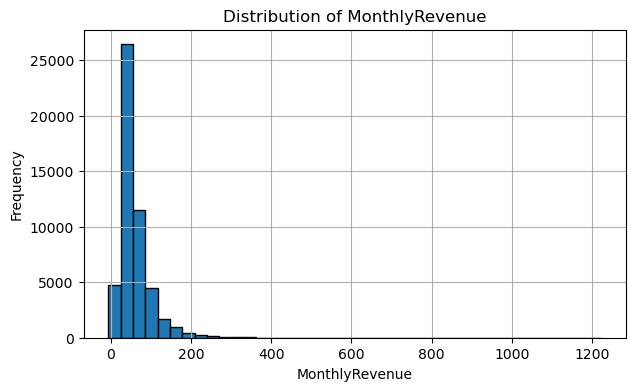

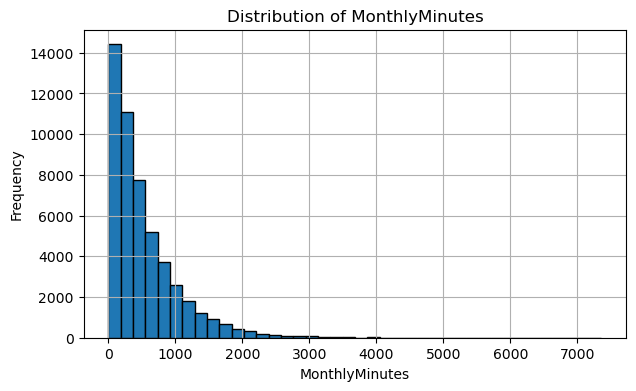

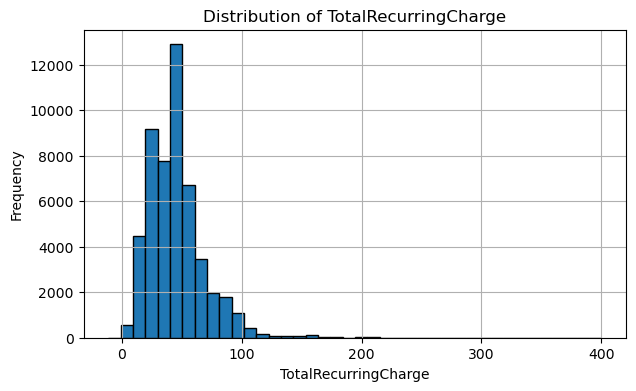

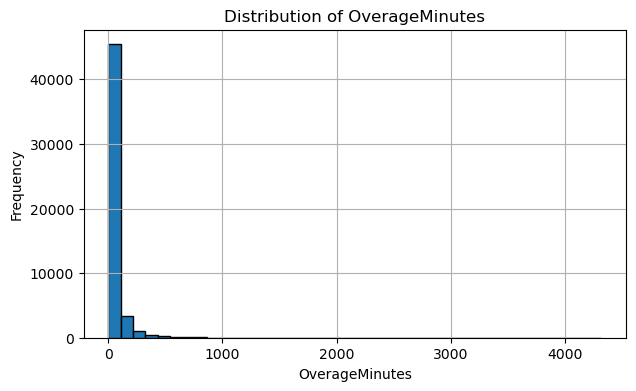

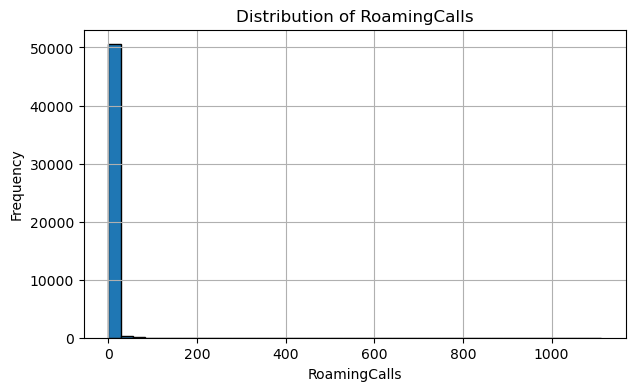

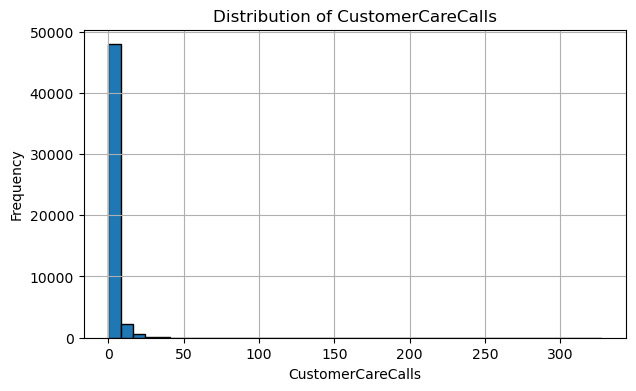

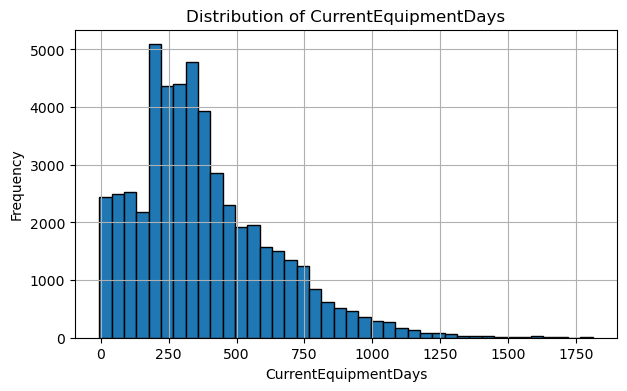

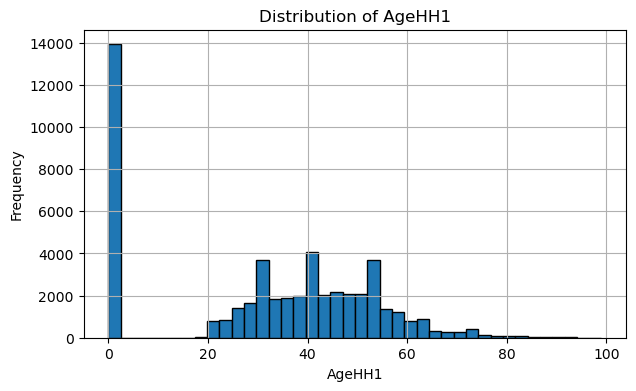

In [16]:
# Representative raw numerical distributions
distribution_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "TotalRecurringCharge",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays",
    "AgeHH1"
]

for col in distribution_features:
    plt.figure(figsize=(7, 4))
    train_raw[col].dropna().hist(
        bins=40,
        edgecolor="black"
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

The numerical columns sit on very different scales, from small counts such as `CallForwardingCalls` to `MonthlyMinutes` in the thousands. Many usage variables are strongly right-skewed: for example, `RoamingCalls` has a median of 0 but a maximum of 1,112, and `OverageMinutes` a median of 3 but a maximum of 4,321. Most customers use these services lightly and a few use them heavily.

### 2.9 Invalid, Impossible and Suspicious Values

This section checks for values that may be invalid, internally inconsistent or worthy of further investigation. A flagged value is **not automatically treated as an error** because its validity depends on the semantic meaning of the feature.

Negative values and selected logical relationships are inspected without modifying the data.

In [17]:
# Identify numerical variables containing negative values
negative_value_summary = []

for col in numeric_cols:
    negative_count = (train_raw[col] < 0).sum()

    if negative_count > 0:
        negative_value_summary.append({
            "Feature": col,
            "Negative_Count": int(negative_count),
            "Minimum_Value": train_raw[col].min()
        })

negative_value_summary = pd.DataFrame(negative_value_summary)
display(negative_value_summary)

,Feature,Negative_Count,Minimum_Value
0,MonthlyRevenue,3,-6.17
1,TotalRecurringCharge,8,-11.00
2,PercChangeMinutes,26816,-3875.00
3,PercChangeRevenues,28408,-1107.70
4,CurrentEquipmentDays,76,-5.00


In [18]:
# Selected logical consistency checks
logical_checks = pd.Series({
    "ActiveSubs > UniqueSubs":
        (train_raw["ActiveSubs"] > train_raw["UniqueSubs"]).sum(),

    "RetentionOffersAccepted > RetentionCalls":
        (
            train_raw["RetentionOffersAccepted"]
            > train_raw["RetentionCalls"]
        ).sum(),

    "HandsetModels > Handsets":
        (train_raw["HandsetModels"] > train_raw["Handsets"]).sum()
}, name="Violation_Count")

display(logical_checks.to_frame())

# Inspect zero values in household-age fields
print("AgeHH1 zero values:", (train_raw["AgeHH1"] == 0).sum())
print("AgeHH2 zero values:", (train_raw["AgeHH2"] == 0).sum())

,Violation_Count
ActiveSubs > UniqueSubs,0
RetentionOffersAccepted > RetentionCalls,0
HandsetModels > Handsets,0


AgeHH1 zero values: 13917
AgeHH2 zero values: 26087


Negative values appear in five columns. For `PercChangeMinutes` and `PercChangeRevenues` they are expected, because usage and revenue can fall from one period to the next. The small number of negative `MonthlyRevenue` (3) and `TotalRecurringCharge` (8) values could represent credits or billing adjustments, so they are kept. `CurrentEquipmentDays` has 76 negative values, which cannot be correct for an elapsed number of days.

The logical checks find no customer with more active than unique subscriptions, more accepted retention offers than retention calls, or more handset models than handsets. `AgeHH1` and `AgeHH2` contain many zeros (13,917 and 26,087), which most likely mean "not recorded" or "no second household member" rather than a real age of zero. Since the documentation gives no definition for a zero age, these values are kept as recorded.

### 2.10 Outlier Investigation

Potential outliers are identified using the Interquartile Range (IQR) rule.

For each numerical variable:

- \(IQR = Q3 - Q1\)
- Lower fence = \(Q1 - 1.5 \times IQR\)
- Upper fence = \(Q3 + 1.5 \times IQR\)

Observations outside these fences are **flagged for investigation**, not automatically removed.

In [19]:
# IQR-based outlier audit
outlier_summary = []

for col in numeric_cols:

    # CustomerID is an identifier, so an outlier concept is not meaningful here
    if col == "CustomerID":
        continue

    values = train_raw[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = (
        (values < lower_fence) |
        (values > upper_fence)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Flagged_Count": int(flagged),
        "Flagged_Percentage":
            round(flagged / len(values) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary).sort_values(
    "Flagged_Percentage",
    ascending=False
)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Flagged_Count,Flagged_Percentage
7,PercChangeRevenues,-7.10,1.600,8.700,-20.1500,14.6500,13221,26.09
5,RoamingCalls,0.00,0.300,0.300,-0.4500,0.7500,8835,17.36
20,CallWaitingCalls,0.00,1.300,1.300,-1.9500,3.2500,7448,14.59
6,PercChangeMinutes,-83.00,66.000,149.000,-306.5000,289.5000,6807,13.43
11,CustomerCareCalls,0.00,1.700,1.700,-2.5500,4.2500,6721,13.17
4,OverageMinutes,0.00,41.000,41.000,-61.5000,102.5000,5842,11.48
3,DirectorAssistedCalls,0.00,0.990,0.990,-1.4850,2.4750,5530,10.87
9,BlockedCalls,0.00,3.700,3.700,-5.5500,9.2500,5517,10.81
15,InboundCalls,0.00,9.300,9.300,-13.9500,23.2500,4973,9.74
12,ThreewayCalls,0.00,0.300,0.300,-0.4500,0.7500,4622,9.05


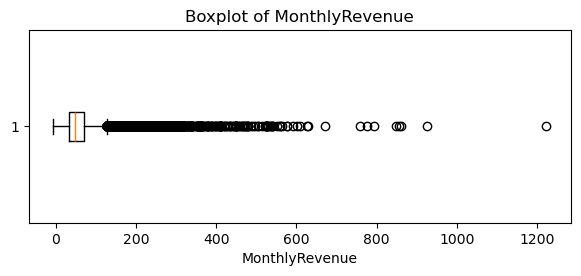

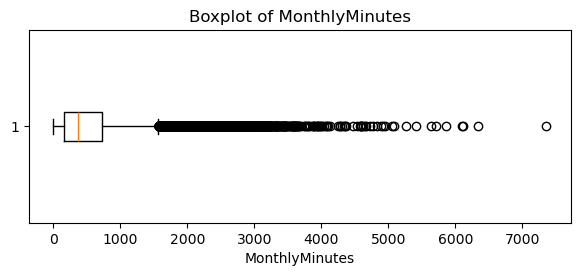

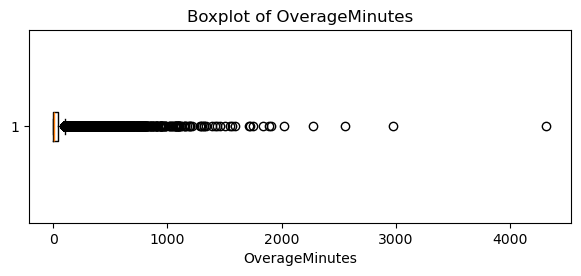

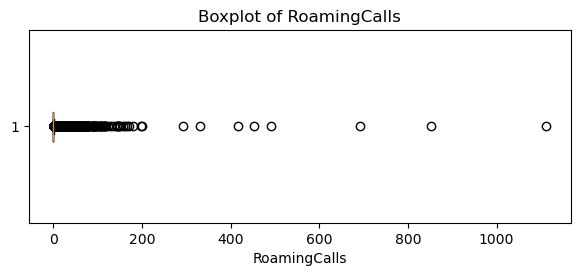

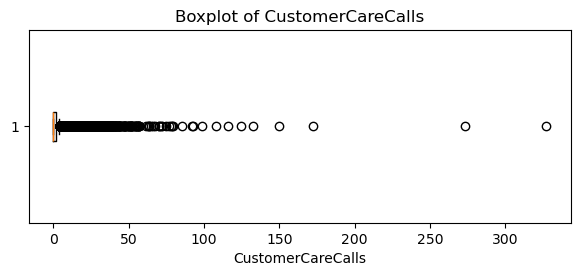

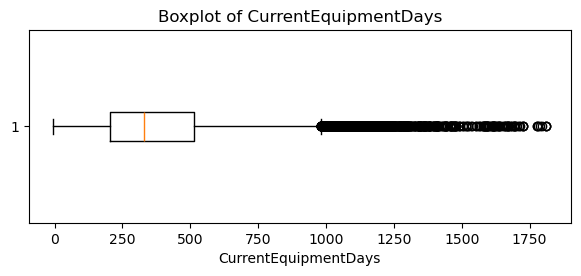

In [20]:
# Selected boxplots for variables with potentially important extreme values
outlier_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays"
]

for col in outlier_features:
    plt.figure(figsize=(7, 2.5))
    plt.boxplot(
        train_raw[col].dropna(),
        vert=False
    )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

The IQR rule flags many customers in the usage columns, for example **26.1%** of `PercChangeRevenues` values and **17.4%** of `RoamingCalls` values. With such skewed distributions, these mostly reflect genuine heavy users or large changes in usage rather than recording errors, and they may carry useful information about churn. They are therefore kept.

### 2.11 Target Distribution and Class Imbalance

The target distribution is inspected to determine whether the two churn classes are represented equally.

,Count,Percentage
Churn,,
No,36336,71.18
Yes,14711,28.82


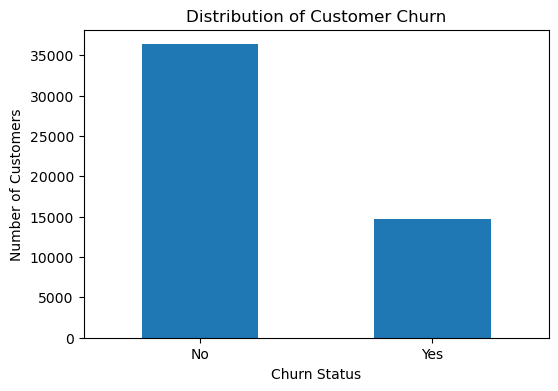

In [21]:
# Target distribution
target_counts = train_raw["Churn"].value_counts()
target_percentages = (
    train_raw["Churn"].value_counts(normalize=True) * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

# Visualise target distribution
plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

The labelled dataset contains **36,336 non-churn customers (approximately 71.18%)** and **14,711 churn customers (approximately 28.82%)**. The target therefore exhibits moderate class imbalance.

### 2.12 Holdout Target Integrity

The target column in the separate holdout file is checked to confirm whether true churn outcomes are available.

In [22]:
print(
    "Missing Churn labels in holdout:",
    holdout_raw["Churn"].isna().sum()
)

print(
    "Total holdout observations:",
    len(holdout_raw)
)

Missing Churn labels in holdout: 20000
Total holdout observations: 20000


All 20,000 `Churn` values in the provided holdout dataset are missing. Therefore, the holdout dataset cannot be used to calculate evaluation measures such as Accuracy, Precision, Recall, F1-score or ROC-AUC. It is retained as an unlabelled dataset for possible final inference after the modelling and evaluation workflow is completed.

### 2.13 Data Audit Summary

| Audit Area | Main Finding |
|---|---|
| Dataset size | 51,047 labelled observations and 58 variables |
| Holdout data | 20,000 observations with no observed `Churn` labels |
| Feature types | Mixture of numerical, binary categorical, nominal and ordered categorical information |
| Target | Binary `Churn` (`Yes` / `No`) |
| Exact duplicates | No complete duplicate rows identified |
| Identifier integrity | `CustomerID` is unique for every labelled observation |
| Actual missing values | Multiple variables contain null values |
| Explicit unknown values | Present in `Homeownership`, `HandsetPrice` and `MaritalStatus` |
| Categorical cardinality | `ServiceArea` contains hundreds of distinct categories |
| Representation issue | `HandsetPrice` contains price-like values together with `Unknown`, producing an object data type |
| Numerical distributions | Several usage-related variables are skewed and contain long tails |
| Suspicious values | Negative/context-dependent values occur in selected numerical fields and require interpretation |
| Internal consistency | Selected logical relationship checks show no violations |
| Potential outliers | IQR analysis flags numerous observations, especially among usage-related variables |
| Target balance | Approximately 71.18% non-churn and 28.82% churn |


## 3. Experimental Design and Data Partitioning

Before any model is trained, the design of the experiment is fixed: what exactly is predicted, which data is used for development and which is kept back for the final test, and how models are validated and compared. Fixing these choices at the start keeps the final test independent of every modelling decision made later. Apart from encoding the target and splitting the rows, the data is not changed in this section.

### 3.1 Experimental Design and Prediction Objective

The task is to predict the recorded `Churn` outcome from the other customer attributes. **Churn (`Yes`) is the positive class**, because the business interest lies in finding the customers who are about to leave.

In practice, a churn model would score current customers a month or two before they might leave. The Cell2Cell documentation defines churn as leaving 31–60 days after the observation date, but the files do not contain the dates themselves.

**Assumption:** the predictors describe each customer up to the observation date, as the documentation implies. Under this assumption, the experiment reproduces the historical churn labels; it cannot show how far in advance churn could be predicted in a live system.

**How the data is used**

| Data | Role |
|---|---|
| `cell2celltrain.csv` (51,047 customers) | Split into a development partition and a test partition |
| Development partition (80%) | Exploratory analysis, training, cross-validation, tuning and every modelling decision |
| Test partition (20%) | Used **once**, at the end, to evaluate the two final models |
| `cell2cellholdout.csv` (20,000 customers) | Demonstration predictions only; no labels |

Three retention fields (`RetentionCalls`, `RetentionOffersAccepted`, `MadeCallToRetentionTeam`) need particular care. A customer may contact the retention team precisely *because* they intend to leave, in which case these fields would reveal the outcome rather than predict it.

### 3.2 Data Preparation Plan

The audit identified several issues that will affect modelling. The table below records the planned treatment for each one. The treatments themselves are applied inside a pipeline that is refitted on each training fold, so that nothing is learned from validation or test data.

| Audit finding | Planned approach | Reason |
|---|---|---|
| Missing numerical and categorical values | Median imputation, plus indicators showing which values were missing | Models need complete inputs, and missingness itself may be informative |
| `HandsetPrice` stored as text with `Unknown` | Convert to numbers; treat `Unknown` as missing | Prices are numeric values, not categories |
| `Unknown` in `Homeownership` and `MaritalStatus` | Keep as its own category | It is a recorded response, not a blank |
| Binary, nominal and ordered categories | One-hot encoding | Avoids inventing numeric distances between labels |
| 747 `ServiceArea` codes | Group rare codes into an "infrequent" category | Keeps the feature space manageable |
| Negative equipment days; zero ages | Negative days → missing; zeros kept | Only clearly impossible values are corrected |
| Skew and IQR outliers | Keep the values | They are plausible heavy users |
| Very different numerical scales | Standardise for Logistic Regression only | Regularised linear models need comparable scales; trees do not |
| `CustomerID` | Exclude from predictors | An identifier carries no behavioural information |
| 28.82% churn | Stratified splits and imbalance-aware metrics | Keeps class balance stable and avoids misleading accuracy |
| Retention fields of uncertain timing | Decide a feature policy before modelling | Prevents use of information that may follow the churn decision |

### 3.3 Predictors, Target and Identifier

The 56 candidate predictors (`X`) are separated from the target (`Churn`) and the identifier (`CustomerID`). The identifier is stored separately so that it can be used to check the split, but it is never given to a model. The original data frame is left unchanged.

In [23]:
# Define the roles of the original columns without modifying train_raw.
TARGET_COL = "Churn"
ID_COL = "CustomerID"

assert TARGET_COL in train_raw.columns
assert ID_COL in train_raw.columns
assert train_raw.columns.is_unique, "Source contains duplicate column names."

candidate_feature_cols = [
    col for col in train_raw.columns
    if col not in {TARGET_COL, ID_COL}
]

# X: all columns except Churn and CustomerID
X = train_raw.loc[:, candidate_feature_cols].copy()

# Original churn label, stored as yes or no
y_raw = train_raw[TARGET_COL].copy()

# Record identifier
customer_ids = train_raw[ID_COL].copy()

feature_role_summary = pd.DataFrame([
    {"Role": "Candidate predictors (X)", "Number_of_columns": X.shape[1],
     "Description": "All original columns except Churn and CustomerID"},
    {"Role": "Target (y_raw)", "Number_of_columns": 1,
     "Description": "Original observed Churn label (Yes / No)"},
    {"Role": "Identifier (customer_ids)", "Number_of_columns": 1,
     "Description": "CustomerID; retained for verification, not prediction"},
])

display(feature_role_summary)
print("Candidate predictor matrix:", X.shape)
print("Raw target vector:", y_raw.shape)
print("Identifier vector:", customer_ids.shape)

assert X.shape[1] == train_raw.shape[1] - 2
assert TARGET_COL not in X.columns and ID_COL not in X.columns
assert X.index.equals(y_raw.index) and X.index.equals(customer_ids.index)

,Role,Number_of_columns,Description
0,Candidate predictors (X),56,All original columns except Churn and CustomerID
1,Target (y_raw),1,Original observed Churn label (Yes / No)
2,Identifier (customer_ids),1,"CustomerID; retained for verification, not pre..."


Candidate predictor matrix: (51047, 56)
Raw target vector: (51047,)
Identifier vector: (51047,)


At this stage the three retention fields remain in `X`. They are flagged for review.

In [24]:
# Record potentially time-sensitive variables for review before modelling.
retention_features_to_review = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]

assert set(retention_features_to_review).issubset(X.columns)

feature_availability_review = pd.DataFrame({
    "Feature": retention_features_to_review,
    "Current_status": ["Timing not verified"] * len(retention_features_to_review),
    "Required_check": [
        "Was the call count known before the intended churn prediction?",
        "Were accepted offers recorded before the intended prediction?",
        "Was contact with the retention team known before prediction?",
    ],
    "Action_now": ["Flag for pre-modelling review; do not remove yet"] * 3,
})

display(feature_availability_review)

,Feature,Current_status,Required_check,Action_now
0,RetentionCalls,Timing not verified,Was the call count known before the intended c...,Flag for pre-modelling review; do not remove yet
1,RetentionOffersAccepted,Timing not verified,Were accepted offers recorded before the inten...,Flag for pre-modelling review; do not remove yet
2,MadeCallToRetentionTeam,Timing not verified,Was contact with the retention team known befo...,Flag for pre-modelling review; do not remove yet


### 3.4 Target Encoding

The target is encoded as `No = 0` and `Yes = 1`, so that the positive class always means churn. Before the mapping is applied, the code checks that there are no missing or unexpected labels. Because this is a fixed mapping and nothing is learned from the data, it can safely be applied before the split.

In [25]:
# Validate the observed labels before encoding.
LABEL_MAP = {"No": 0, "Yes": 1}
POSITIVE_CLASS = 1

assert y_raw.notna().all(), "Labelled data contains missing Churn values."

unexpected_labels = set(y_raw.unique()) - set(LABEL_MAP)
assert not unexpected_labels, f"Unexpected Churn values: {unexpected_labels}"
assert set(y_raw.unique()) == set(LABEL_MAP), "Expected both churn classes."

# Deterministic target encoding; no fitted transformation or data leakage.
y = y_raw.map(LABEL_MAP).astype("int8")

assert y.notna().all()
assert set(y.unique()) == {0, 1}
assert y.index.equals(X.index)

label_summary = pd.DataFrame({
    "Original_label": ["No", "Yes"],
    "Encoded_label": [0, 1],
    "Count": [int((y == 0).sum()), int((y == 1).sum())],
    "Percentage": [round((y == 0).mean() * 100, 2),
                   round((y == 1).mean() * 100, 2)],
})

display(label_summary)
print("Target validation: PASSED")
print("Original raw target unchanged:", train_raw[TARGET_COL].equals(y_raw))

,Original_label,Encoded_label,Count,Percentage
0,No,0,36336,71.18
1,Yes,1,14711,28.82


Target validation: PASSED
Original raw target unchanged: True


### 3.5 Partitioning Strategy

The labelled customers are split into **80% development** and **20% test** with a stratified random split (`random_state=42`). Every step that involves a decision (exploration, preprocessing design, model training, tuning and threshold choice) uses the development partition only.

The split is **stratified** because only 28.82% of customers churned. Stratification keeps that proportion the same in both partitions, so the test results are not distorted by an unusually easy or difficult sample. A **random** split is used because the data contains no dates that would allow a time-based split, and every row is a distinct customer.

**Limitation:** a random split measures how well the models generalise to new customers from the same period. It does not measure how well they would perform on future customers, whose behaviour may differ.

### 3.6 Development and Final-Test Split

In [26]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20

assert train_raw.index.is_unique, "Row index must uniquely identify each observation."
assert customer_ids.notna().all(), "CustomerID contains missing values."
assert customer_ids.is_unique, "CustomerID must be unique for this split strategy."

# Split row indices so features, target and customer IDs remain aligned.
dev_idx, test_idx = train_test_split(
    train_raw.index.to_numpy(),
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Separate copies of the raw candidate predictors and their labels.
X_dev = X.loc[dev_idx].copy()
X_test = X.loc[test_idx].copy()
y_dev = y.loc[dev_idx].copy()
y_test = y.loc[test_idx].copy()

# IDs are kept for integrity verification, not for model fitting.
customer_ids_dev = customer_ids.loc[dev_idx].copy()
customer_ids_test = customer_ids.loc[test_idx].copy()

partition_summary = pd.DataFrame([
    {"Partition": "Development", "Observations": len(X_dev),
     "Predictor_columns": X_dev.shape[1],
     "Percentage_of_labelled_data": round(100 * len(X_dev) / len(X), 2)},
    {"Partition": "Protected final test", "Observations": len(X_test),
     "Predictor_columns": X_test.shape[1],
     "Percentage_of_labelled_data": round(100 * len(X_test) / len(X), 2)},
])

display(partition_summary)
print("X_dev:", X_dev.shape, "| y_dev:", y_dev.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Unlabelled holdout kept separate:", holdout_raw.shape)

,Partition,Observations,Predictor_columns,Percentage_of_labelled_data
0,Development,40837,56,80.0
1,Protected final test,10210,56,20.0


X_dev: (40837, 56) | y_dev: (40837,)
X_test: (10210, 56) | y_test: (10210,)
Unlabelled holdout kept separate: (20000, 58)


The split gives **40,837 development customers** and **10,210 test customers**, each with the same 56 candidate predictors.

### 3.7 Split Check

The partitions are checked to confirm that every customer belongs to exactly one partition, that the labels stay aligned with their rows, and that the churn rate is preserved. The test partition is only checked for its structure and class balance; its contents are not explored.

In [27]:
# Verify the partition structure without fitting or tuning any model.
checks = {
    "Every labelled customer is in exactly one partition": len(X_dev) + len(X_test)
    == len(train_raw)
    and set(customer_ids_dev).isdisjoint(set(customer_ids_test)),
    "Development features, labels and IDs aligned": X_dev.index.equals(y_dev.index)
    and X_dev.index.equals(customer_ids_dev.index),
    "Test features, labels and IDs aligned": X_test.index.equals(y_test.index)
    and X_test.index.equals(customer_ids_test.index),
    "Same predictor columns in both partitions": X_dev.columns.equals(X_test.columns),
    "Target and identifier excluded from predictors": not {TARGET_COL, ID_COL} & set(X_dev.columns),
    "Both classes present in both partitions": set(y_dev.unique())
    == set(y_test.unique())
    == {0, 1},
}
display(
    pd.DataFrame(
        {
            "Integrity_check": list(checks),
            "Status": ["PASS" if ok else "FAIL" for ok in checks.values()],
        }
    )
)
assert all(checks.values()), "At least one partition-integrity check failed."

,Integrity_check,Status
0,Every labelled customer is in exactly one part...,PASS
1,"Development features, labels and IDs aligned",PASS
2,"Test features, labels and IDs aligned",PASS
3,Same predictor columns in both partitions,PASS
4,Target and identifier excluded from predictors,PASS
5,Both classes present in both partitions,PASS


In [28]:
# Compare target distributions for structural verification only.
distribution_records = []

for partition_name, labels in [
    ("All labelled data", y),
    ("Development", y_dev),
    ("Protected final test", y_test),
]:
    distribution_records.append({
        "Partition": partition_name,
        "Total": len(labels),
        "No_churn_0": int((labels == 0).sum()),
        "Churn_1": int((labels == 1).sum()),
        "Churn_percentage": round(100 * (labels == 1).mean(), 2),
    })

split_class_distribution = pd.DataFrame(distribution_records)
display(split_class_distribution)

# Stratification should maintain very similar positive-class rates.
assert abs(y_dev.mean() - y.mean()) < 0.01
assert abs(y_test.mean() - y.mean()) < 0.01
print("Class-proportion verification: PASSED")

,Partition,Total,No_churn_0,Churn_1,Churn_percentage
0,All labelled data,51047,36336,14711,28.82
1,Development,40837,29068,11769,28.82
2,Protected final test,10210,7268,2942,28.81


Class-proportion verification: PASSED


All checks pass. The churn rate is **28.82%** in the development partition and **28.81%** in the test partition, so stratification worked as intended.

### 3.8 Cross-Validation and Evaluation Metrics

**Validation.** Model choices are made with **five-fold stratified cross-validation** on the development partition (`StratifiedKFold`, shuffled, `random_state=42`). Each fold uses four-fifths of the development customers for training and the remaining fifth for validation, so every development customer is used for validation exactly once. The same five folds are reused for every model, which makes the comparisons fair, and the test customers never enter any fold.

**Metrics.** Because churners are the minority class, models are ranked mainly by **Average Precision (AP)**, the area under the precision–recall curve. AP measures how well a model places churners at the top of its risk ranking, and a model with no skill scores the churn rate (about 0.288). ROC-AUC gives a second threshold-free view (no-skill value 0.5). Precision, recall, F1, MCC, balanced accuracy and accuracy describe the yes/no decisions at a particular threshold.

In [29]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef

N_CV_SPLITS = 5
cv = StratifiedKFold(
    n_splits=N_CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Average Precision summarises the precision-recall curve and is the main comparison metric.
PRIMARY_SCORING = "average_precision"
CV_SCORING = {
    "average_precision": "average_precision",  # primary model-selection metric
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "mcc": make_scorer(matthews_corrcoef),
}

# Check the folds: each development customer must be in exactly one validation fold.
fold_rows = []
validation_appearances = np.zeros(len(X_dev), dtype=int)

for fold_number, (train_positions, valid_positions) in enumerate(cv.split(X_dev, y_dev), start=1):
    assert set(train_positions).isdisjoint(set(valid_positions))
    validation_appearances[valid_positions] += 1

    fold_rows.append(
        {
            "Fold": fold_number,
            "Training_rows": len(train_positions),
            "Validation_rows": len(valid_positions),
            "Training_churn_pct": round(100 * y_dev.iloc[train_positions].mean(), 2),
            "Validation_churn_pct": round(100 * y_dev.iloc[valid_positions].mean(), 2),
        }
    )

cv_fold_summary = pd.DataFrame(fold_rows)
assert len(cv_fold_summary) == N_CV_SPLITS
assert (
    validation_appearances == 1
).all(), "Every development observation should appear in exactly one validation fold."

display(cv_fold_summary)
print("Cross-validation configuration: 5-fold stratified, shuffled, seed =", RANDOM_STATE)
print("Main model-selection metric:", PRIMARY_SCORING)
print("Additional metrics:", ", ".join(k for k in CV_SCORING if k != PRIMARY_SCORING))
print("Every development customer appears in exactly one validation fold.")

,Fold,Training_rows,Validation_rows,Training_churn_pct,Validation_churn_pct
0,1,32669,8168,28.82,28.82
1,2,32669,8168,28.82,28.82
2,3,32670,8167,28.82,28.81
3,4,32670,8167,28.82,28.82
4,5,32670,8167,28.82,28.82


Cross-validation configuration: 5-fold stratified, shuffled, seed = 42
Main model-selection metric: average_precision
Additional metrics: roc_auc, f1, recall, precision, accuracy, balanced_accuracy, mcc
Every development customer appears in exactly one validation fold.


Each validation fold holds about **8,167–8,168 customers** with the same 28.8% churn rate.

**Preventing leakage.** The evaluation follows four rules:

1. Imputation values, scaling parameters, category lists and any feature selection are learned **inside each training fold** through scikit-learn `Pipeline` and `ColumnTransformer` objects, and only then applied to the validation fold.
2. Every modelling decision (features, hyperparameters, class weights and decision thresholds) is based on development data.
3. Both algorithms use the same folds and metrics.
4. After all decisions are fixed, the final pipelines are refitted on the full development partition and evaluated **once** on the test partition.

### 3.9 Experimental Design Summary

| Design element | Finalised decision |
|---|---|
| Learning task | Supervised binary classification of the observed Cell2Cell `Churn` outcome |
| Positive class | `Yes` encoded as `1` (`No` encoded as `0`) |
| Labelled data | 51,047 customers |
| Candidate inputs | 56 raw candidate predictors; `CustomerID` excluded and retained separately |
| Partitioning | 80% development (40,837) / 20% protected final test (10,210) |
| Split method | Stratified random split, `random_state=42` |
| Development validation | Five-fold shuffled `StratifiedKFold`, `random_state=42` |
| Primary model-selection metric | Average Precision (`average_precision`) |
| Supporting evaluation | ROC-AUC, precision, recall, F1, MCC, balanced accuracy, accuracy and confusion matrix |
| Supplied holdout | 20,000 customers without observed churn labels; optional inference only |

## 4. Exploratory Data Analysis (Development Data Only)

This section explores how customer characteristics relate to churn, in order to guide the preprocessing and modelling choices that follow. All analysis uses the **40,837 development customers** only. Including the test customers here could influence later decisions and make the final test less independent. No values are imputed, encoded or removed in this section.

### 4.1 Reference Churn Rate

The development predictors and labels are combined into a separate `eda_dev` table, so that the modelling inputs stay unchanged. Every churn-rate chart in this section shows the overall development churn rate as a dashed reference line, and subgroup differences are expressed in percentage points (pp) relative to it. A subgroup above the line has a higher churn rate than average in this sample; this alone does not make the difference statistically significant or causal.

In [30]:
# EDA uses development customers only; eda_dev is a separate copy so X_dev stays unchanged.
assert X_dev.index.equals(y_dev.index), "Development features and labels are misaligned."
assert "Churn" not in X_dev.columns and "CustomerID" not in X_dev.columns

eda_dev = X_dev.copy()
eda_dev["Churn"] = y_dev  # Pandas aligns the labels by original row index.

DEV_CHURN_RATE = float(y_dev.mean())
DEV_CHURN_PCT = 100 * DEV_CHURN_RATE


def add_churn_baseline(ax, orientation="horizontal"):
    """Draw the development churn rate as a dashed reference line on a churn-rate chart."""
    label = f"Development baseline: {DEV_CHURN_PCT:.2f}%"
    if orientation == "horizontal":  # horizontal line for vertical bars
        ax.axhline(DEV_CHURN_PCT, color="black", linestyle="--", linewidth=1.4, label=label)
    elif orientation == "vertical":  # vertical line for horizontal bars
        ax.axvline(DEV_CHURN_PCT, color="black", linestyle="--", linewidth=1.4, label=label)
    else:
        raise ValueError("orientation must be 'horizontal' or 'vertical'")


assert eda_dev.shape == (len(X_dev), X_dev.shape[1] + 1)
assert eda_dev["Churn"].equals(y_dev)
print(f"Development EDA: {len(eda_dev):,} customers, {X_dev.shape[1]} predictors")
print(f"Development churn rate (reference line): {DEV_CHURN_PCT:.2f}%")

Development EDA: 40,837 customers, 56 predictors
Development churn rate (reference line): 28.82%


The development churn rate is **28.82%**, which is the reference for all of the comparisons below.

### 4.2 Feature Types in the Development Data

The storage types of the 56 candidate predictors are counted, together with the number of columns that contain missing values.

In [31]:
# Storage types of the 56 candidate predictors in the development data.
eda_numeric_columns = X_dev.select_dtypes(include=np.number).columns.tolist()
eda_object_columns = X_dev.select_dtypes(exclude=np.number).columns.tolist()

eda_overview = pd.DataFrame(
    [
        {"Property": "Development observations", "Value": len(X_dev)},
        {"Property": "Candidate predictor columns", "Value": X_dev.shape[1]},
        {"Property": "Numerically stored predictors", "Value": len(eda_numeric_columns)},
        {"Property": "Non-numerically stored predictors", "Value": len(eda_object_columns)},
        {"Property": "Predictors with actual nulls", "Value": int(X_dev.isna().any().sum())},
        {"Property": "Target positive class", "Value": "Churn = 1 (Yes)"},
        {"Property": "Development churn prevalence", "Value": f"{DEV_CHURN_PCT:.2f}%"},
    ]
)
display(eda_overview)
print("Examples of numerical predictors:", ", ".join(eda_numeric_columns[:9]))
print("Examples of stored text predictors:", ", ".join(eda_object_columns[:9]))

,Property,Value
0,Development observations,40837
1,Candidate predictor columns,56
2,Numerically stored predictors,34
3,Non-numerically stored predictors,22
4,Predictors with actual nulls,14
5,Target positive class,Churn = 1 (Yes)
6,Development churn prevalence,28.82%


Examples of numerical predictors: MonthlyRevenue, MonthlyMinutes, TotalRecurringCharge, DirectorAssistedCalls, OverageMinutes, RoamingCalls, PercChangeMinutes, PercChangeRevenues, DroppedCalls
Examples of stored text predictors: ServiceArea, ChildrenInHH, HandsetRefurbished, HandsetWebCapable, TruckOwner, RVOwner, Homeownership, BuysViaMailOrder, RespondsToMailOffers


Of the 56 candidate predictors, **34 are stored as numbers** and **22 as text**, and 14 contain true nulls. Storage type does not always match meaning: `IncomeGroup` is a numeric code for an income band, and `HandsetPrice` holds prices stored as text because of its `Unknown` entries.

### 4.3 Class Distribution

The two classes are counted, and the accuracy of a trivial rule that always predicts "No churn" is calculated. This rule is a reference point, not a fitted model.

,Outcome,Customers,Percentage
0,No churn (0),29068,71.18
1,Churn (1),11769,28.82


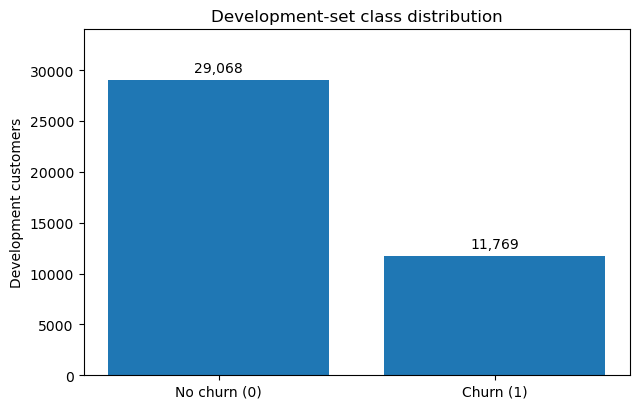

Reference churn rate: 28.82%
Accuracy of always predicting 'No churn': 71.18%


In [32]:
# Class counts, and the accuracy of a rule that always predicts 'No churn'.
eda_target_counts = y_dev.value_counts().reindex([0, 1], fill_value=0)
eda_target_summary = pd.DataFrame(
    {
        "Outcome": ["No churn (0)", "Churn (1)"],
        "Customers": eda_target_counts.to_numpy(),
        "Percentage": (100 * eda_target_counts / len(y_dev)).round(2).to_numpy(),
    }
)
display(eda_target_summary)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(eda_target_summary["Outcome"], eda_target_summary["Customers"])
for bar, count in zip(bars, eda_target_summary["Customers"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 450,
        f"{count:,}",
        ha="center",
        va="bottom",
    )
ax.set_ylim(0, eda_target_summary["Customers"].max() * 1.17)
ax.set_ylabel("Development customers")
ax.set_title("Development-set class distribution")
plt.tight_layout()
plt.show()

majority_accuracy = 100 * eda_target_counts.max() / len(y_dev)
print(f"Reference churn rate: {DEV_CHURN_PCT:.2f}%")
print(f"Accuracy of always predicting 'No churn': {majority_accuracy:.2f}%")

The development set has **29,068 non-churners (71.18%)** and **11,769 churners (28.82%)**. Always predicting "No churn" would score **71.18% accuracy** while missing every churner. For this reason, models are compared mainly on Average Precision and churn-focused measures rather than on accuracy.

### 4.4 Distributions of Key Numerical Features

Eight important numerical features are summarised by their missingness, share of zeros, central values, upper tail and skewness. The summary table uses all values, while the histograms show the 1st–99th percentile range so that the bulk of each distribution is readable. This is a display choice only; no values are removed.

In [33]:
# Shape of eight key numerical features: missingness, zeros, centre, tail and skewness.
eda_distribution_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "MonthsInService",
    "CustomerCareCalls",
    "DroppedCalls",
    "OverageMinutes",
    "CurrentEquipmentDays",
    "RoamingCalls",
]
assert set(eda_distribution_features).issubset(X_dev.columns)

numeric_distribution_rows = []
for feature in eda_distribution_features:
    s = pd.to_numeric(X_dev[feature], errors="coerce")
    nonmissing = s.dropna()
    numeric_distribution_rows.append(
        {
            "Feature": feature,
            "Missing_%": round(100 * s.isna().mean(), 2),
            "Zero_%_of_all_rows": round(100 * s.eq(0).mean(), 2),
            "Mean": round(nonmissing.mean(), 2),
            "Median": round(nonmissing.median(), 2),
            "P95": round(nonmissing.quantile(0.95), 2),
            "P99": round(nonmissing.quantile(0.99), 2),
            "Maximum": round(nonmissing.max(), 2),
            "Skewness": round(nonmissing.skew(), 2),
        }
    )
numeric_distribution_summary = pd.DataFrame(numeric_distribution_rows)
display(numeric_distribution_summary)

,Feature,Missing_%,Zero_%_of_all_rows,Mean,Median,P95,P99,Maximum,Skewness
0,MonthlyRevenue,0.29,0.01,58.99,48.47,136.31,228.33,1223.38,4.31
1,MonthlyMinutes,0.29,1.40,525.24,367.00,1569.20,2450.00,7359.00,2.19
2,MonthsInService,0.00,0.00,18.78,16.00,37.00,49.00,61.00,1.06
3,CustomerCareCalls,0.00,54.89,1.87,0.00,9.30,21.30,327.30,12.88
4,DroppedCalls,0.00,15.05,6.01,3.00,22.00,42.30,221.70,4.39
5,OverageMinutes,0.29,45.59,40.31,3.00,191.00,434.00,4321.00,8.36
6,CurrentEquipmentDays,0.00,0.04,380.44,329.00,866.00,1141.65,1812.00,1.08
7,RoamingCalls,0.29,68.66,1.24,0.00,5.00,21.58,1112.40,58.99


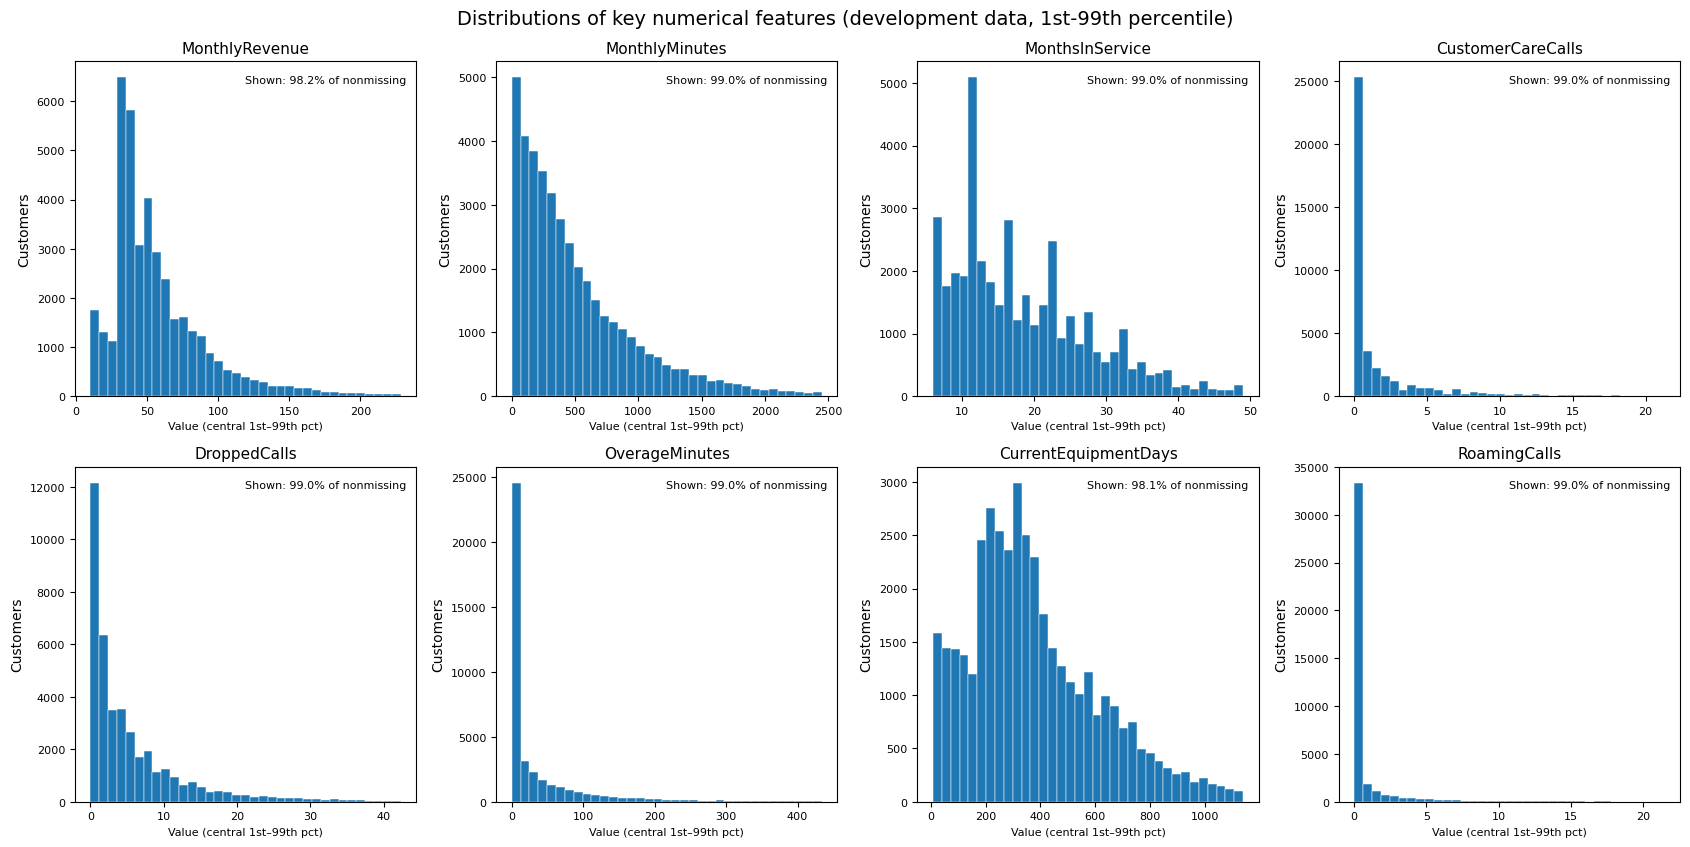

In [34]:
# Histograms show the 1st-99th percentile range for readability; no data is removed.
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, feature in zip(axes.flat, eda_distribution_features):
    values = pd.to_numeric(X_dev[feature], errors="coerce").dropna()
    lower, upper = values.quantile([0.01, 0.99])
    if lower >= upper:
        lower, upper = values.min(), values.max()
    visible = values.between(lower, upper)
    ax.hist(values[visible], bins=35, edgecolor="white", linewidth=0.35)
    ax.set_title(feature, fontsize=11)
    ax.set_ylabel("Customers")
    ax.set_xlabel("Value (central 1st–99th pct)", fontsize=8)
    ax.tick_params(axis="both", labelsize=8)
    ax.text(
        0.97,
        0.96,
        f"Shown: {visible.mean()*100:.1f}% of nonmissing",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
fig.suptitle(
    "Distributions of key numerical features (development data, 1st-99th percentile)", fontsize=14
)
plt.tight_layout()
plt.show()

Most usage features are heavily right-skewed and zero-inflated. `RoamingCalls` is zero for **68.66%** of customers (skewness 58.99), `CustomerCareCalls` for **54.89%** (skewness 12.88) and `OverageMinutes` for **45.59%** (skewness 8.36), while each has a long tail of heavy users. `MonthlyRevenue` (median 48.47, maximum 1,223) and `MonthlyMinutes` (median 367, maximum 7,359) behave similarly. Tenure (`MonthsInService`) and equipment age (`CurrentEquipmentDays`) are much less skewed. The large differences in scale call for standardisation in Logistic Regression, and the long tails suggest that a log transform could also help a linear model (explored in Section 14.9).

### 4.5 Numerical Features by Churn Outcome

Medians and means of key numerical features are compared between churners and non-churners, with boxplots for four of them. Outlier markers are hidden in the boxplots to keep them readable.

In [35]:
# Medians and means of key numerical features for churners and non-churners.
class_compare_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "MonthsInService",
    "CustomerCareCalls",
    "DroppedCalls",
    "OverageMinutes",
    "CurrentEquipmentDays",
]
class_comparison_rows = []
for feature in class_compare_features:
    s = pd.to_numeric(X_dev[feature], errors="coerce")
    no_values = s[y_dev == 0].dropna()
    yes_values = s[y_dev == 1].dropna()
    class_comparison_rows.append(
        {
            "Feature": feature,
            "No_churn_N": len(no_values),
            "Churn_N": len(yes_values),
            "No_churn_median": round(no_values.median(), 2),
            "Churn_median": round(yes_values.median(), 2),
            "Median_difference_Churn_minus_No": round(yes_values.median() - no_values.median(), 2),
            "No_churn_mean": round(no_values.mean(), 2),
            "Churn_mean": round(yes_values.mean(), 2),
        }
    )
numerical_churn_comparison = pd.DataFrame(class_comparison_rows)
display(numerical_churn_comparison)

,Feature,No_churn_N,Churn_N,No_churn_median,Churn_median,Median_difference_Churn_minus_No,No_churn_mean,Churn_mean
0,MonthlyRevenue,29003,11714,48.81,47.51,-1.3,59.29,58.26
1,MonthlyMinutes,29003,11714,381.00,331.00,-50.0,541.64,484.65
2,MonthsInService,29068,11769,16.00,17.00,1.0,18.64,19.14
3,CustomerCareCalls,29068,11769,0.00,0.00,0.0,1.98,1.58
4,DroppedCalls,29068,11769,3.00,3.00,0.0,6.07,5.85
5,OverageMinutes,29003,11714,2.00,3.00,1.0,39.11,43.29
6,CurrentEquipmentDays,29067,11769,310.00,367.00,57.0,363.35,422.66


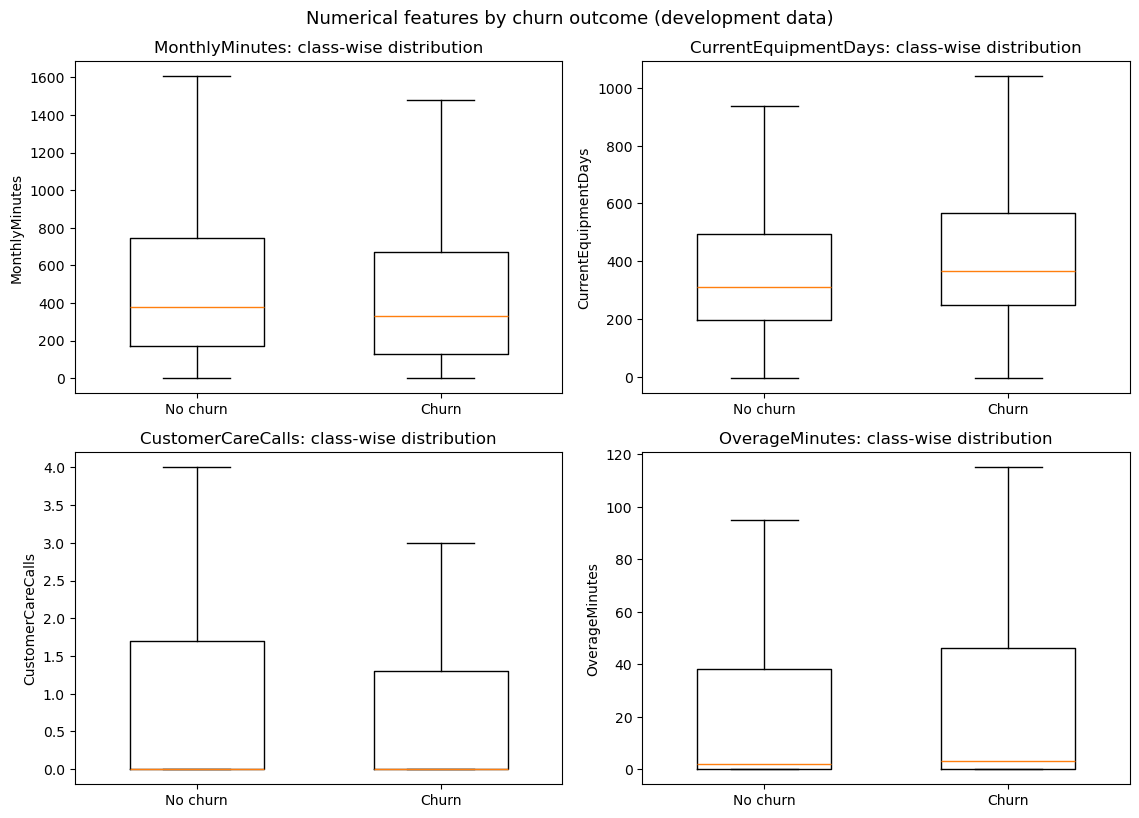

In [36]:
# Boxplots by churn outcome (outlier markers hidden to keep the boxes readable).
boxplot_features = ["MonthlyMinutes", "CurrentEquipmentDays", "CustomerCareCalls", "OverageMinutes"]
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.3))
for ax, feature in zip(axes.flat, boxplot_features):
    no_values = X_dev.loc[y_dev == 0, feature].dropna()
    yes_values = X_dev.loc[y_dev == 1, feature].dropna()
    ax.boxplot([no_values, yes_values], showfliers=False, widths=0.55)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No churn", "Churn"])
    ax.set_ylabel(feature)
    ax.set_title(f"{feature}: class-wise distribution")
fig.suptitle("Numerical features by churn outcome (development data)", fontsize=13)
plt.tight_layout()
plt.show()

Two features separate the groups most clearly. Churners used fewer minutes (median **331** vs **381** per month) and had older handsets (median `CurrentEquipmentDays` **367** vs **310**). Revenue, tenure and dropped calls differ very little at the median. Customer-care calls have a median of zero in both groups, so their distributions need to be compared through rates rather than medians.

### 4.6 Churn Rates Across Value Ranges

Averages can hide relationships that change direction across a feature's range. Churn rates are therefore computed within bands: fixed ranges for tenure and customer-care calls, and development-data quintiles for monthly minutes and equipment age. Each band's customer count is shown, so that small groups are not over-interpreted.

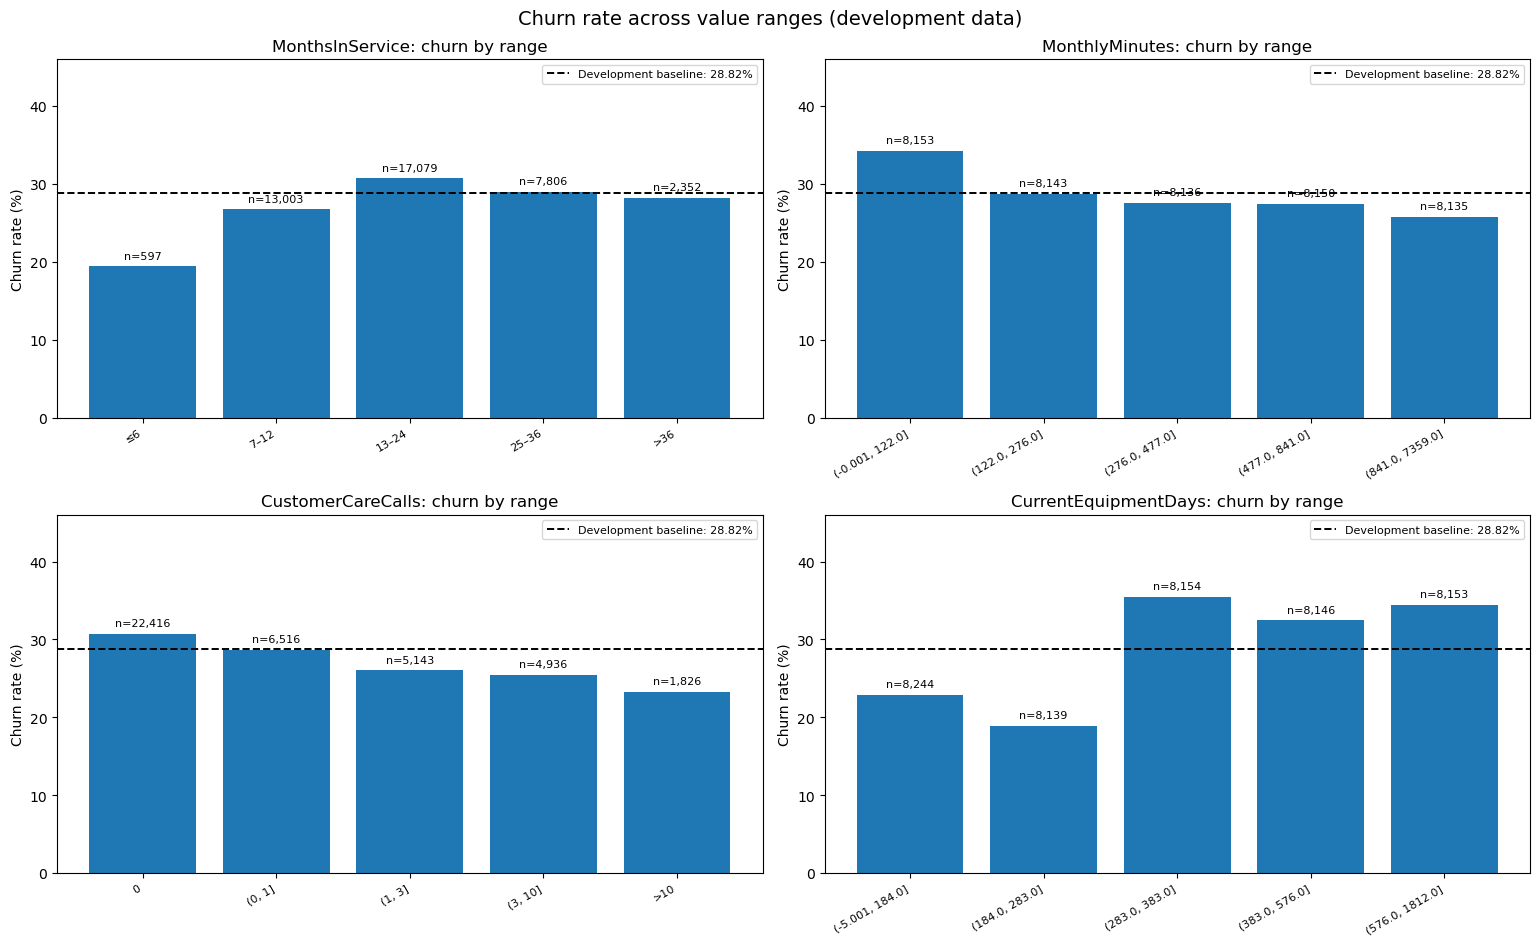

,Feature,Band,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,MonthsInService,≤6,597,116,19.43,-9.39
1,MonthsInService,7–12,13003,3475,26.72,-2.09
2,MonthsInService,13–24,17079,5251,30.75,1.93
3,MonthsInService,25–36,7806,2264,29.00,0.18
4,MonthsInService,>36,2352,663,28.19,-0.63
5,MonthlyMinutes,"(-0.001, 122.0]",8153,2795,34.28,5.46
6,MonthlyMinutes,"(122.0, 276.0]",8143,2337,28.70,-0.12
7,MonthlyMinutes,"(276.0, 477.0]",8136,2246,27.61,-1.21
8,MonthlyMinutes,"(477.0, 841.0]",8150,2238,27.46,-1.36
9,MonthlyMinutes,"(841.0, 7359.0]",8135,2098,25.79,-3.03


In [37]:
# Churn rate within value bands: fixed bands for tenure and care calls, quintiles for the rest.
num_band_definitions = {
    "MonthsInService": pd.cut(
        X_dev["MonthsInService"],
        bins=[-np.inf, 6, 12, 24, 36, np.inf],
        labels=["≤6", "7–12", "13–24", "25–36", ">36"],
    ),
    "MonthlyMinutes": pd.qcut(X_dev["MonthlyMinutes"], q=5, duplicates="drop"),
    "CustomerCareCalls": pd.cut(
        X_dev["CustomerCareCalls"],
        bins=[-np.inf, 0, 1, 3, 10, np.inf],
        labels=["0", "(0, 1]", "(1, 3]", "(3, 10]", ">10"],
    ),
    "CurrentEquipmentDays": pd.qcut(X_dev["CurrentEquipmentDays"], q=5, duplicates="drop"),
}

numerical_band_summaries = {}
for feature, bands in num_band_definitions.items():
    grouped = (
        pd.DataFrame({"Band": bands, "Churn": y_dev})
        .dropna(subset=["Band"])
        .groupby("Band", observed=True)["Churn"]
        .agg(N="size", Churn_N="sum", Churn_rate="mean")
        .reset_index()
    )
    grouped["Churn_rate_pct"] = 100 * grouped["Churn_rate"]
    grouped["Delta_vs_baseline_pp"] = grouped["Churn_rate_pct"] - DEV_CHURN_PCT
    numerical_band_summaries[feature] = grouped

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.6))
for ax, (feature, summary) in zip(axes.flat, numerical_band_summaries.items()):
    xpos = np.arange(len(summary))
    bars = ax.bar(xpos, summary["Churn_rate_pct"])
    add_churn_baseline(ax, "horizontal")
    ax.set_xticks(xpos)
    ax.set_xticklabels(summary["Band"].astype(str), rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"{feature}: churn by range")
    ax.set_ylim(0, max(46, float(summary["Churn_rate_pct"].max()) + 9))
    for bar, n in zip(bars, summary["N"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.7,
            f"n={n:,}",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Churn rate across value ranges (development data)", fontsize=14)
plt.tight_layout()
plt.show()

numerical_band_table = pd.concat(
    [
        summary.assign(Feature=feature, Band=summary["Band"].astype(str))
        for feature, summary in numerical_band_summaries.items()
    ],
    ignore_index=True,
)
display(
    numerical_band_table[
        ["Feature", "Band", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]
    ].round(2)
)

Several relationships are clearly non-linear:

- **Monthly minutes:** churn falls steadily from **34.28%** in the lowest-usage quintile to **25.79%** in the highest. Light users are the most likely to leave.
- **Equipment age:** churn is lowest for handsets about 6–9 months old (**18.91%**) and jumps to **35.49%** once the handset passes about 9–12 months (283–383 days), staying high after that. This fits customers reaching the end of a handset or contract cycle and becoming free to switch, although the data does not record contract terms.
- **Tenure:** new customers (≤ 6 months) churn least (**19.43%**, but only 597 customers), and churn peaks at **30.75%** for 13–24 months.
- **Customer-care calls:** churn *decreases* as calls increase, from **30.71%** with no calls to **23.27%** with more than ten. Customers who contact customer care may be more engaged, rather than more dissatisfied.

A linear model cannot represent a jump such as the one in equipment age with a single coefficient, which is one reason to include a tree-based algorithm in the comparison.

### 4.7 Categorical Features and Churn

Churn rates are compared across the categories of six customer-profile and account features. The size of each group is shown, so that small groups are not over-interpreted.

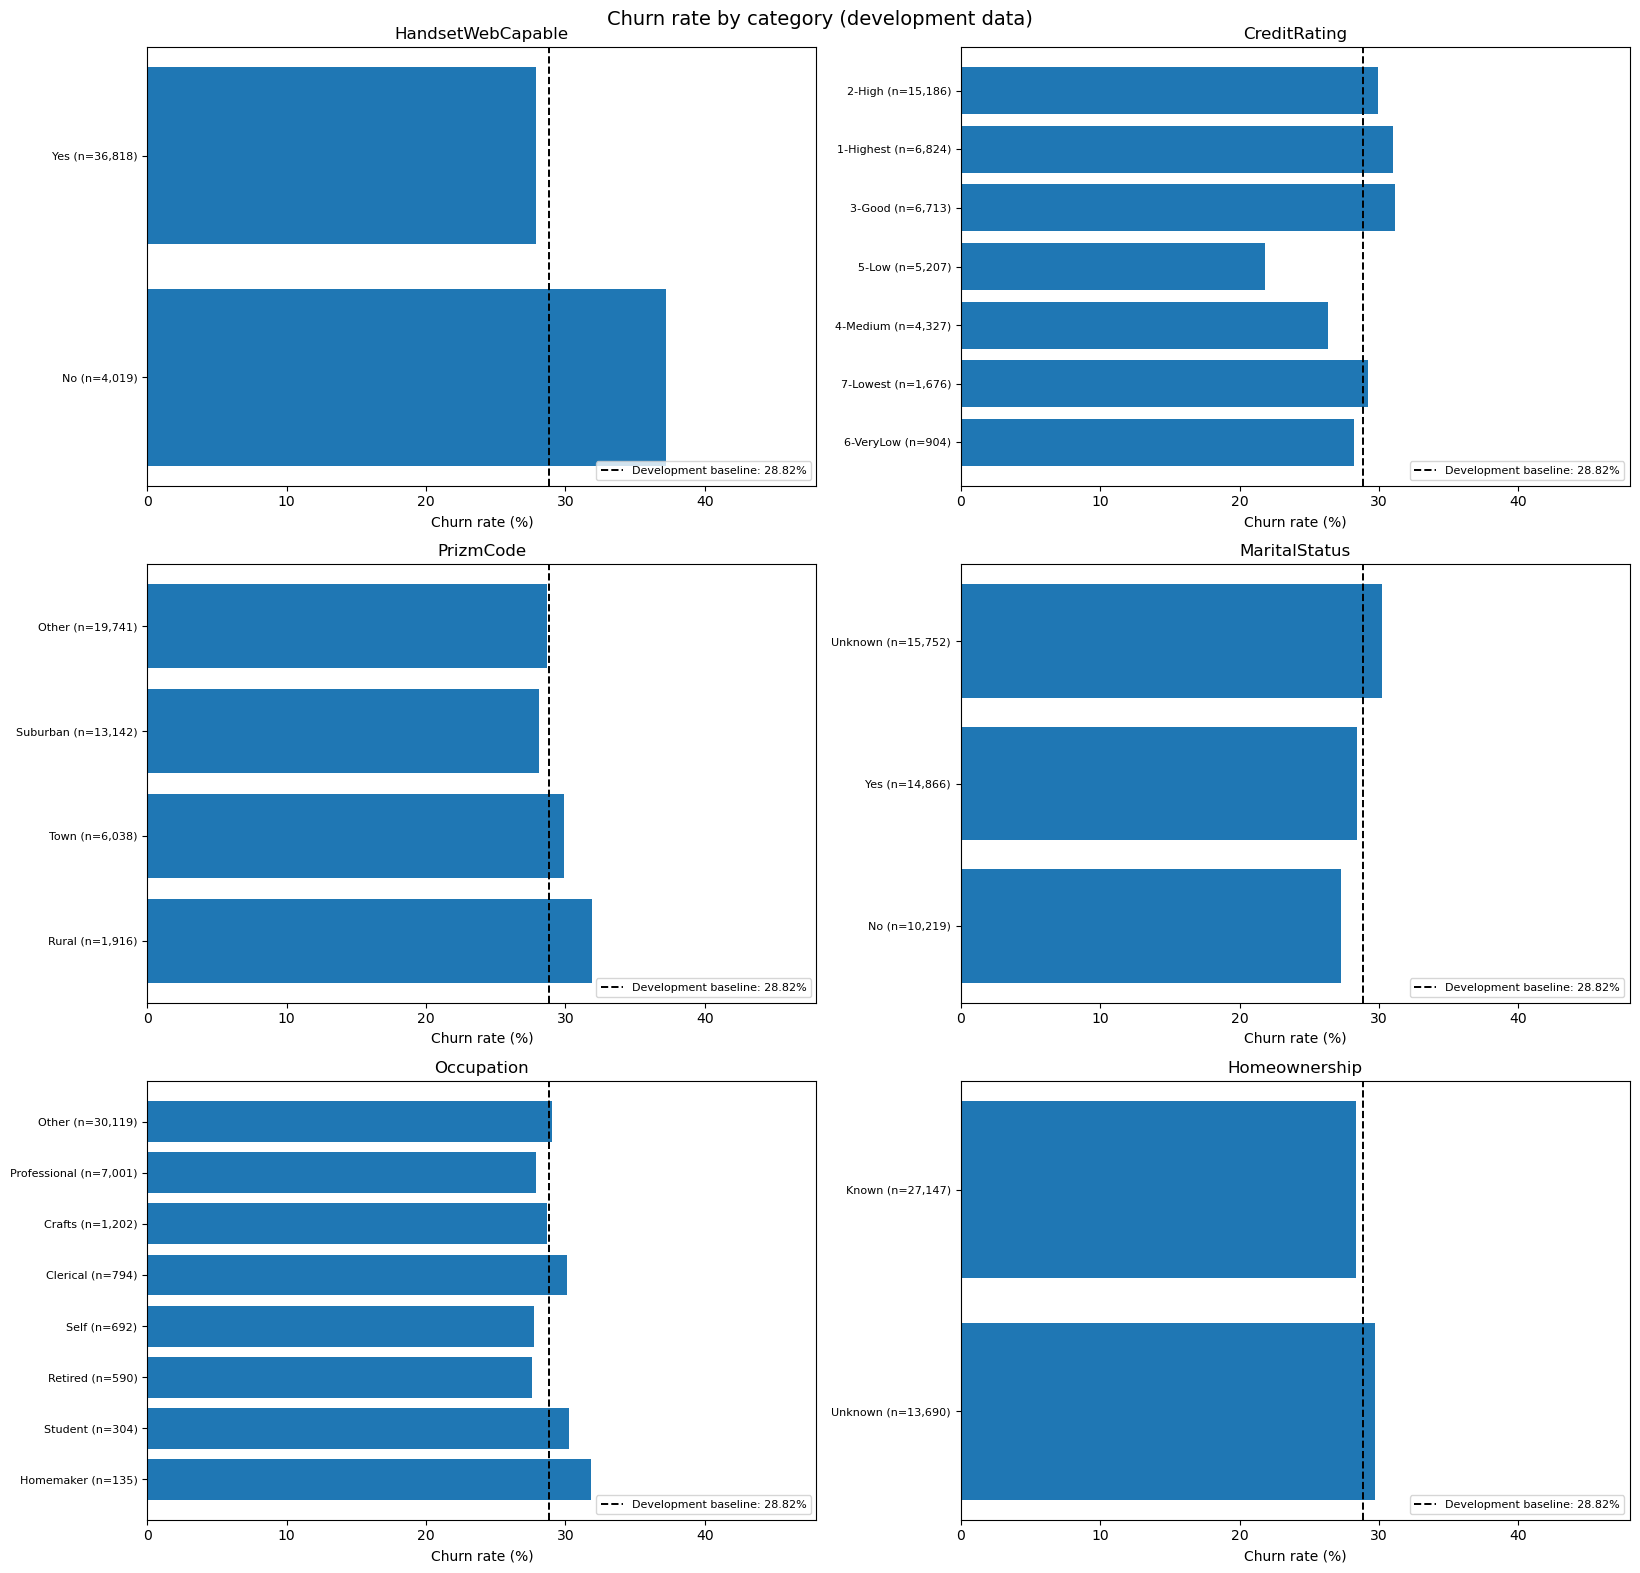

,Feature,Category,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,HandsetWebCapable,Yes,36818,10274,27.90,-0.91
1,HandsetWebCapable,No,4019,1495,37.20,8.38
2,CreditRating,2-High,15186,4543,29.92,1.10
3,CreditRating,1-Highest,6824,2117,31.02,2.20
4,CreditRating,3-Good,6713,2090,31.13,2.31
5,CreditRating,5-Low,5207,1135,21.80,-7.02
6,CreditRating,4-Medium,4327,1140,26.35,-2.47
7,CreditRating,7-Lowest,1676,489,29.18,0.36
8,CreditRating,6-VeryLow,904,255,28.21,-0.61
9,PrizmCode,Other,19741,5657,28.66,-0.16


In [38]:
# Churn rate for each category of six profile and account features.
eda_categorical_features = [
    "HandsetWebCapable",
    "CreditRating",
    "PrizmCode",
    "MaritalStatus",
    "Occupation",
    "Homeownership",
]
category_summaries = {}
for feature in eda_categorical_features:
    category = X_dev[feature].astype("string").fillna("<Missing>")
    grouped = (
        pd.DataFrame({"Category": category, "Churn": y_dev})
        .groupby("Category", dropna=False)["Churn"]
        .agg(N="size", Churn_N="sum", Churn_rate="mean")
        .sort_values("N", ascending=False)
        .reset_index()
    )
    grouped["Churn_rate_pct"] = 100 * grouped["Churn_rate"]
    grouped["Delta_vs_baseline_pp"] = grouped["Churn_rate_pct"] - DEV_CHURN_PCT
    category_summaries[feature] = grouped

fig, axes = plt.subplots(3, 2, figsize=(16.5, 16))
for ax, (feature, summary) in zip(axes.flat, category_summaries.items()):
    ypos = np.arange(len(summary))
    ax.barh(ypos, summary["Churn_rate_pct"])
    add_churn_baseline(ax, "vertical")
    ax.set_yticks(ypos)
    ax.set_yticklabels(
        [f"{cat} (n={n:,})" for cat, n in zip(summary["Category"], summary["N"])], fontsize=8
    )
    ax.invert_yaxis()
    ax.set_xlim(0, max(48, float(summary["Churn_rate_pct"].max()) + 6))
    ax.set_xlabel("Churn rate (%)")
    ax.set_title(feature)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Churn rate by category (development data)", fontsize=14)
plt.tight_layout()
plt.show()

categorical_churn_table = pd.concat(
    [summary.assign(Feature=feature) for feature, summary in category_summaries.items()],
    ignore_index=True,
)
display(
    categorical_churn_table[
        ["Feature", "Category", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]
    ].round(2)
)

The clearest categorical difference is handset capability: customers **without a web-capable handset churn at 37.20%** (4,019 customers) against 27.90% for those with one. Credit rating shows a mixed pattern: the `5-Low` group churns least (**21.80%**) while the highest ratings sit around 31%, so the categories should not be treated as an evenly spaced scale. `MaritalStatus = Unknown` (30.21%) and rural `PrizmCode` (31.89%) are slightly above average. Occupation differences are small, and its smaller groups (for example 135 homemakers) are too small to read much into.

### 4.8 Missingness and Churn

The audit showed where values are missing. This step examines whether customers with missing or `Unknown` values churn at a different rate from other customers. True nulls and recorded `Unknown` values are again kept separate.

,Flag,Flagged_N,Flagged_%,Flagged_churn_%,Unflagged_churn_%,Delta_vs_baseline_pp
0,PercChangeMinutes: null,290,0.71,56.90,28.62,28.08
1,MonthlyRevenue: null,120,0.29,45.83,28.77,17.01
2,AgeHH1: null,716,1.75,27.79,28.84,-1.03
3,ServiceArea: null,21,0.05,47.62,28.81,18.80
4,HandsetPrice: Unknown,23214,56.85,30.01,27.25,1.19
5,MaritalStatus: Unknown,15752,38.57,30.21,27.94,1.39
6,Homeownership: Unknown,13690,33.52,29.70,28.38,0.88


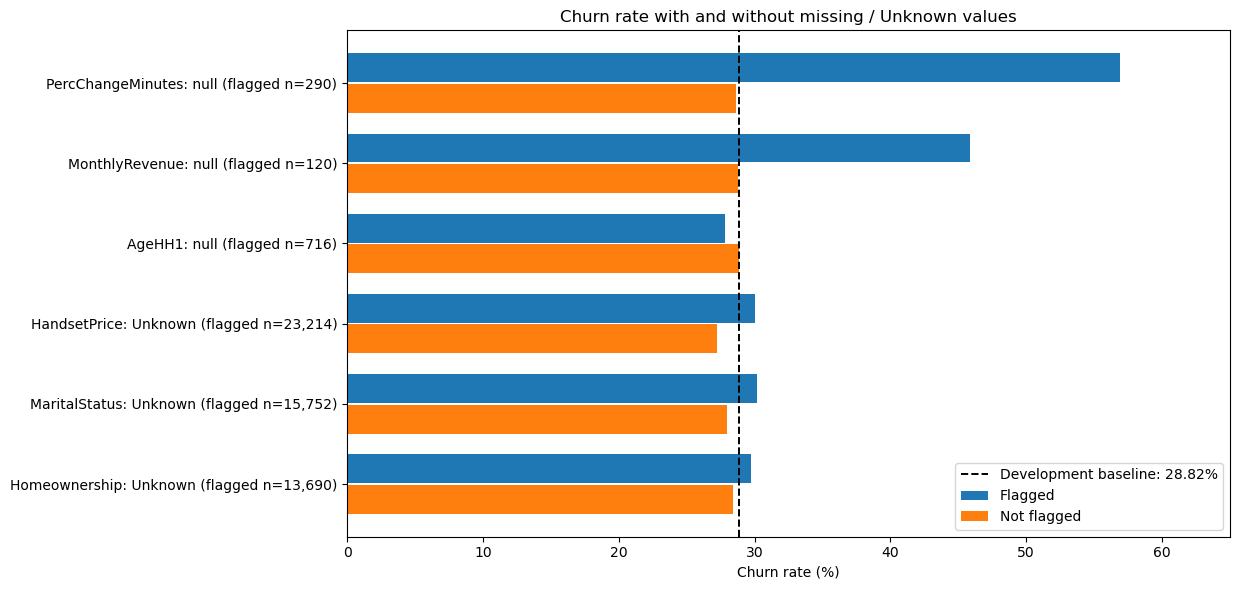

In [39]:
# Churn rate for customers with a missing or 'Unknown' value, against everyone else.
missingness_flags = {
    "PercChangeMinutes: null": X_dev["PercChangeMinutes"].isna(),
    "MonthlyRevenue: null": X_dev["MonthlyRevenue"].isna(),
    "AgeHH1: null": X_dev["AgeHH1"].isna(),
    "ServiceArea: null": X_dev["ServiceArea"].isna(),
    "HandsetPrice: Unknown": X_dev["HandsetPrice"]
    .astype("string")
    .str.strip()
    .eq("Unknown")
    .fillna(False),
    "MaritalStatus: Unknown": X_dev["MaritalStatus"]
    .astype("string")
    .str.strip()
    .eq("Unknown")
    .fillna(False),
    "Homeownership: Unknown": X_dev["Homeownership"]
    .astype("string")
    .str.strip()
    .eq("Unknown")
    .fillna(False),
}
missingness_rows = []
for label, flag in missingness_flags.items():
    flag = flag.astype(bool)
    n_flagged = int(flag.sum())
    n_unflagged = int((~flag).sum())
    missingness_rows.append(
        {
            "Flag": label,
            "Flagged_N": n_flagged,
            "Flagged_%": 100 * n_flagged / len(flag),
            "Flagged_churn_%": 100 * y_dev[flag].mean() if n_flagged else np.nan,
            "Unflagged_churn_%": 100 * y_dev[~flag].mean() if n_unflagged else np.nan,
            "Delta_vs_baseline_pp": (
                (100 * y_dev[flag].mean() - DEV_CHURN_PCT) if n_flagged else np.nan
            ),
        }
    )
missingness_churn_summary = pd.DataFrame(missingness_rows)
display(missingness_churn_summary.round(2))

# Exclude the very small flagged groups from the comparison plot, but keep them in the table.
plot_missing = missingness_churn_summary.query("Flagged_N >= 100").copy()
ypos = np.arange(len(plot_missing))
fig, ax = plt.subplots(figsize=(12.5, 6))
ax.barh(ypos - 0.19, plot_missing["Flagged_churn_%"], height=0.36, label="Flagged")
ax.barh(ypos + 0.19, plot_missing["Unflagged_churn_%"], height=0.36, label="Not flagged")
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels(
    [
        f"{label} (flagged n={n:,})"
        for label, n in zip(plot_missing["Flag"], plot_missing["Flagged_N"])
    ]
)
ax.invert_yaxis()
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, max(65, float(plot_missing["Flagged_churn_%"].max()) + 5))
ax.set_title("Churn rate with and without missing / Unknown values")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Missing values are strongly linked to churn for some fields. Customers with a missing `PercChangeMinutes` churn at **56.90%** (290 customers), almost double the rate of customers with a recorded value (28.62%), and customers with missing `MonthlyRevenue` at **45.83%** (120). The `Unknown` codes make much less difference (30.01% for `HandsetPrice`, 30.21% for `MaritalStatus`, 29.70% for `Homeownership`). Missing `ServiceArea` affects only 21 customers, too few for a reliable rate.

### 4.9 Correlation Between Numerical Features

Pearson correlations are computed between all numerical predictors to find features that carry overlapping information. The heatmap shows a selection of billing, usage and account features; the table lists the strongest pairs among all of them.

,Feature_1,Feature_2,Pearson_r,Absolute_r
516,Handsets,HandsetModels,0.888,0.888
44,MonthlyMinutes,ReceivedCalls,0.827,0.827
269,BlockedCalls,DroppedBlockedCalls,0.816,0.816
495,UniqueSubs,ActiveSubs,0.805,0.805
3,MonthlyRevenue,OverageMinutes,0.783,0.783
47,MonthlyMinutes,PeakCallsInOut,0.773,0.773
48,MonthlyMinutes,OffPeakCallsInOut,0.765,0.765
353,ReceivedCalls,PeakCallsInOut,0.746,0.746
373,OutboundCalls,OffPeakCallsInOut,0.740,0.740
354,ReceivedCalls,OffPeakCallsInOut,0.736,0.736


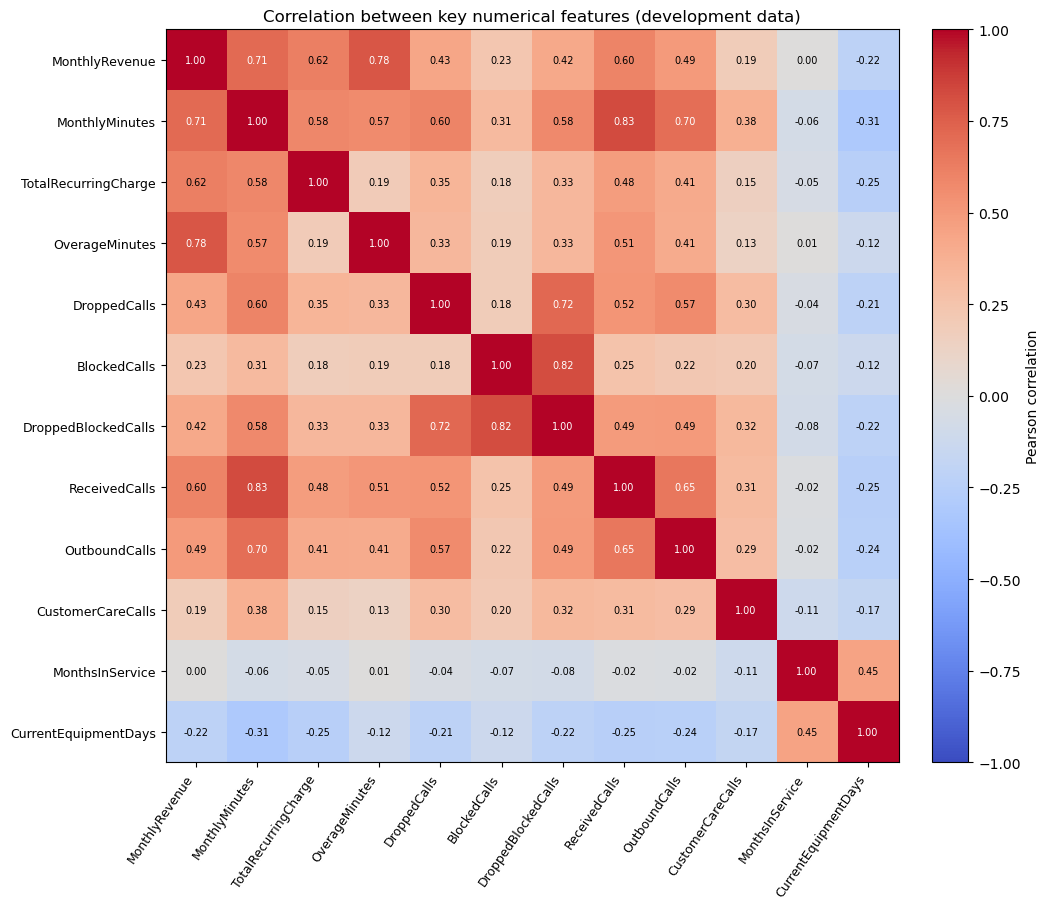

In [40]:
# Pearson correlations between all numerical predictors; strongest pairs first.
eda_numeric_corr = X_dev[eda_numeric_columns].corr(method="pearson")
upper_triangle = np.triu(np.ones(eda_numeric_corr.shape, dtype=bool), k=1)
correlation_pairs = eda_numeric_corr.where(upper_triangle).stack().rename("Pearson_r").reset_index()
correlation_pairs.columns = ["Feature_1", "Feature_2", "Pearson_r"]
correlation_pairs["Absolute_r"] = correlation_pairs["Pearson_r"].abs()
correlation_pairs = correlation_pairs.sort_values("Absolute_r", ascending=False)
display(correlation_pairs.head(12).round(3))

heatmap_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "TotalRecurringCharge",
    "OverageMinutes",
    "DroppedCalls",
    "BlockedCalls",
    "DroppedBlockedCalls",
    "ReceivedCalls",
    "OutboundCalls",
    "CustomerCareCalls",
    "MonthsInService",
    "CurrentEquipmentDays",
]
heat = eda_numeric_corr.loc[heatmap_features, heatmap_features]
fig, ax = plt.subplots(figsize=(10.5, 9.2))
im = ax.imshow(heat.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(heatmap_features)))
ax.set_xticklabels(heatmap_features, rotation=55, ha="right", fontsize=9)
ax.set_yticks(range(len(heatmap_features)))
ax.set_yticklabels(heatmap_features, fontsize=9)
for row in range(len(heatmap_features)):
    for col in range(len(heatmap_features)):
        val = heat.iat[row, col]
        if np.isfinite(val):
            ax.text(
                col,
                row,
                f"{val:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if abs(val) > 0.65 else "black",
            )
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Correlation between key numerical features (development data)")
plt.tight_layout()
plt.show()

Several features are strongly correlated: `Handsets` with `HandsetModels` (**r = 0.89**), `MonthlyMinutes` with `ReceivedCalls` (**0.83**, since the documentation defines `ReceivedCalls` as minutes of received calls, which are part of total minutes), `BlockedCalls` with `DroppedBlockedCalls` (**0.82**, which includes blocked calls by definition) and `UniqueSubs` with `ActiveSubs` (**0.81**). Correlated inputs are not a problem for Random Forest's predictions, but they make individual Logistic Regression coefficients harder to interpret, because the L2 penalty shares the effect between them.

### 4.10 The High-Cardinality `ServiceArea` Feature

The number of customers per service-area code is examined, together with the churn rates of the ten largest areas. The areas are chosen by size rather than by churn rate, to avoid highlighting extreme rates from very small groups.

,Measure,Value
0,Distinct nonmissing ServiceArea codes,729
1,Customers with missing ServiceArea,21
2,Codes with fewer than 20 development customers,434
3,Customers in codes with fewer than 20 records,2441
4,Codes with fewer than 50 development customers,546


,ServiceArea,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,NYCBRO917,1330,360,27.07,-1.75
1,HOUHOU281,1232,310,25.16,-3.66
2,DALDAL214,1195,340,28.45,-0.37
3,NYCMAN917,956,268,28.03,-0.79
4,DALFTW817,636,174,27.36,-1.46
5,APCFCH703,625,176,28.16,-0.66
6,SANSAN210,575,161,28.00,-0.82
7,APCSIL301,526,133,25.29,-3.53
8,SFROAK510,510,152,29.80,0.98
9,SANAUS512,497,135,27.16,-1.66


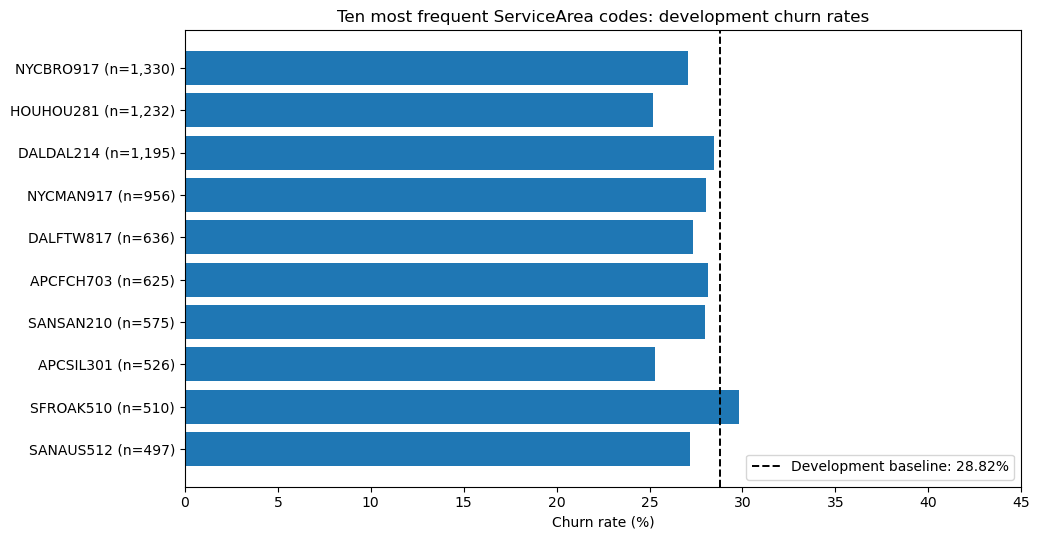

In [41]:
# How many customers each ServiceArea code has, and churn in the ten largest areas.
service_area = X_dev["ServiceArea"].astype("string").fillna("<Missing>")
service_counts = service_area.value_counts()
service_summary = pd.DataFrame(
    [
        {
            "Measure": "Distinct nonmissing ServiceArea codes",
            "Value": X_dev["ServiceArea"].nunique(dropna=True),
        },
        {
            "Measure": "Customers with missing ServiceArea",
            "Value": int(X_dev["ServiceArea"].isna().sum()),
        },
        {
            "Measure": "Codes with fewer than 20 development customers",
            "Value": int((service_counts < 20).sum()),
        },
        {
            "Measure": "Customers in codes with fewer than 20 records",
            "Value": int(service_counts[service_counts < 20].sum()),
        },
        {
            "Measure": "Codes with fewer than 50 development customers",
            "Value": int((service_counts < 50).sum()),
        },
    ]
)
display(service_summary)

service_churn = (
    pd.DataFrame({"ServiceArea": service_area, "Churn": y_dev})
    .groupby("ServiceArea")["Churn"]
    .agg(N="size", Churn_N="sum", Churn_rate="mean")
)
top_areas = service_counts.head(10).index
service_top10 = service_churn.loc[top_areas].reset_index()
service_top10["Churn_rate_pct"] = 100 * service_top10["Churn_rate"]
service_top10["Delta_vs_baseline_pp"] = service_top10["Churn_rate_pct"] - DEV_CHURN_PCT
display(
    service_top10[["ServiceArea", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]].round(
        2
    )
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ypos = np.arange(len(service_top10))
ax.barh(ypos, service_top10["Churn_rate_pct"])
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels(
    [f"{name} (n={n:,})" for name, n in zip(service_top10["ServiceArea"], service_top10["N"])]
)
ax.invert_yaxis()
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, max(45, float(service_top10["Churn_rate_pct"].max()) + 6))
ax.set_title("Ten most frequent ServiceArea codes: development churn rates")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The development data contains **729 service-area codes** plus 21 missing values. **434 codes have fewer than 20 customers** (2,441 customers in total), so a separate column for each code would rest on very little data. The ten largest areas have churn rates between **25.16%** and **29.80%**, all close to the average.

### 4.11 Retention Features and the Risk of Leakage

A feature can be strongly related to churn yet unusable for prediction if it is recorded *after* the point at which a customer would be scored. A retention call is the obvious example: a customer may call the retention team because they have already decided to leave, so the call would reveal the answer rather than help to predict it.

The documentation describes `RetentionCalls` as the "number of calls previously made to retention team" and `RetentionOffersAccepted` as the "number of previous retention offers accepted", but it gives no dates. It is therefore not possible to tell whether these contacts happened well before the observation date or close to the churn event.

**Decision:** as a precaution, **the three retention fields are excluded from the main models** and should be tested separately. The measurement window of the percentage-change fields is also undocumented, which is a limitation.

In [42]:
# What would have to be known about each time-sensitive feature before using it.
RETENTION_FEATURES_UNVERIFIED = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]
assert set(RETENTION_FEATURES_UNVERIFIED).issubset(X_dev.columns)

feature_timing_review = pd.DataFrame(
    [
        {
            "Feature": "RetentionCalls",
            "What_it_records": "Number of retention-related calls",
            "What_must_be_verified": "Call dates relative to scoring and churn outcome",
            "Evidence_in_files": "No event dates / cutoff definition",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
        },
        {
            "Feature": "RetentionOffersAccepted",
            "What_it_records": "Accepted retention offers",
            "What_must_be_verified": "Offer and acceptance dates; whether offer follows churn intent",
            "Evidence_in_files": "No event dates / cutoff definition",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
        },
        {
            "Feature": "MadeCallToRetentionTeam",
            "What_it_records": "Whether the customer contacted the retention team",
            "What_must_be_verified": "Contact timing and triggering event",
            "Evidence_in_files": "No event dates / cutoff definition",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
        },
        {
            "Feature": "PercChangeMinutes / PercChangeRevenues",
            "What_it_records": "Change in usage / revenue over an unspecified interval",
            "What_must_be_verified": "Observation window and whether it precedes churn",
            "Evidence_in_files": "No dated observation window",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Keep; test removal in Section 12",
        },
    ]
)
display(feature_timing_review)

,Feature,What_it_records,What_must_be_verified,Evidence_in_files,Status,Provisional_primary_policy
0,RetentionCalls,Number of retention-related calls,Call dates relative to scoring and churn outcome,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
1,RetentionOffersAccepted,Accepted retention offers,Offer and acceptance dates; whether offer foll...,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
2,MadeCallToRetentionTeam,Whether the customer contacted the retention team,Contact timing and triggering event,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
3,PercChangeMinutes / PercChangeRevenues,Change in usage / revenue over an unspecified ...,Observation window and whether it precedes churn,No dated observation window,Timing unverified,Keep; test removal in Section 12


,Observed_indicator,Flagged_N,Flagged_%,Flagged_churn_%,Not_flagged_churn_%,Delta_vs_baseline_pp
0,RetentionCalls > 0,1402,3.43,44.86,28.25,16.05
1,RetentionOffersAccepted > 0,711,1.74,42.33,28.58,13.52
2,MadeCallToRetentionTeam = Yes,1402,3.43,44.86,28.25,16.05


RetentionCalls > 0 exactly matches MadeCallToRetentionTeam = Yes in development: True


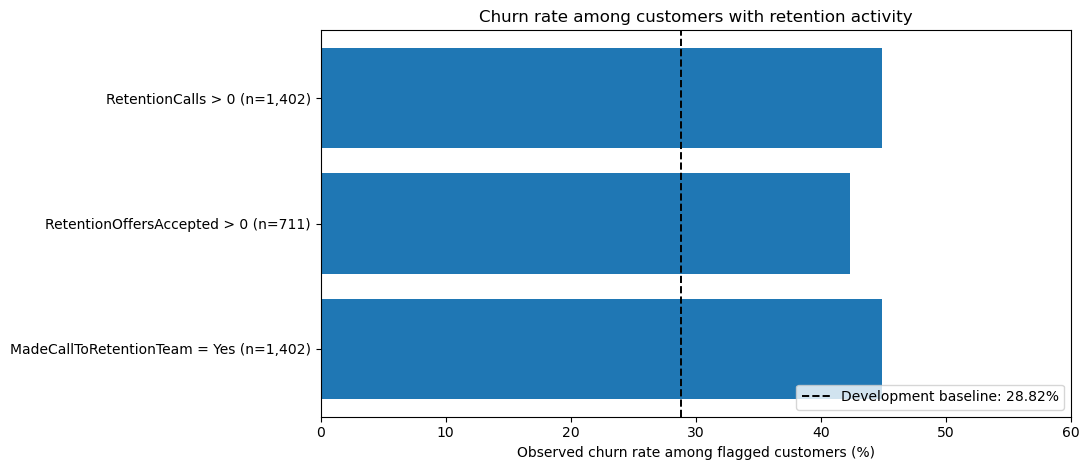

In [43]:
# Churn rate among customers with any retention-team activity.
retention_flags = {
    "RetentionCalls > 0": X_dev["RetentionCalls"].gt(0),
    "RetentionOffersAccepted > 0": X_dev["RetentionOffersAccepted"].gt(0),
    "MadeCallToRetentionTeam = Yes": X_dev["MadeCallToRetentionTeam"].eq("Yes"),
}
retention_rows = []
for label, flag in retention_flags.items():
    n_flagged = int(flag.sum())
    retention_rows.append(
        {
            "Observed_indicator": label,
            "Flagged_N": n_flagged,
            "Flagged_%": 100 * flag.mean(),
            "Flagged_churn_%": 100 * y_dev[flag].mean(),
            "Not_flagged_churn_%": 100 * y_dev[~flag].mean(),
            "Delta_vs_baseline_pp": 100 * y_dev[flag].mean() - DEV_CHURN_PCT,
        }
    )
retention_churn_summary = pd.DataFrame(retention_rows)
display(retention_churn_summary.round(2))

retention_call_indicator_matches = bool(
    X_dev["RetentionCalls"].gt(0).equals(X_dev["MadeCallToRetentionTeam"].eq("Yes"))
)
print(
    "RetentionCalls > 0 exactly matches MadeCallToRetentionTeam = Yes in development:",
    retention_call_indicator_matches,
)

fig, ax = plt.subplots(figsize=(11, 4.8))
ypos = np.arange(len(retention_churn_summary))
ax.barh(ypos, retention_churn_summary["Flagged_churn_%"])
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels(
    [
        f"{label} (n={n:,})"
        for label, n in zip(
            retention_churn_summary["Observed_indicator"], retention_churn_summary["Flagged_N"]
        )
    ]
)
ax.invert_yaxis()
ax.set_xlim(0, max(60, float(retention_churn_summary["Flagged_churn_%"].max()) + 6))
ax.set_xlabel("Observed churn rate among flagged customers (%)")
ax.set_title("Churn rate among customers with retention activity")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Customers who called the retention team churn at **44.86%** (1,402 customers) against 28.25% for everyone else, and those who accepted a retention offer at **42.33%** (711). `MadeCallToRetentionTeam = Yes` identifies exactly the same 1,402 customers as `RetentionCalls > 0`, so the two fields duplicate each other. The strong link with churn is what makes the timing question important: if these contacts happen once a customer has decided to leave, they would inflate the measured accuracy without being available when a real prediction is made.

### 4.12 EDA Summary and Implications for Modelling

In [44]:
# Summary of the main EDA findings and what they imply for modelling.
eda_findings = pd.DataFrame(
    [
        {
            "Observation": "Development churn prevalence",
            "Evidence": f"{DEV_CHURN_PCT:.2f}% churn ({int(y_dev.sum()):,}/{len(y_dev):,})",
            "Implication": "Use this baseline on subgroup plots; evaluate beyond accuracy",
        },
        {
            "Observation": "Numerical skew and excess zeros",
            "Evidence": (
                f"RoamingCalls zero for {100*X_dev['RoamingCalls'].eq(0).mean():.1f}%; "
                f"CustomerCareCalls zero for {100*X_dev['CustomerCareCalls'].eq(0).mean():.1f}%"
            ),
            "Implication": "Review scaling and robust representations within training folds",
        },
        {
            "Observation": "Usage differs by churn outcome",
            "Evidence": (
                f"Median MonthlyMinutes: No={X_dev.loc[y_dev==0,'MonthlyMinutes'].median():.0f}; "
                f"Yes={X_dev.loc[y_dev==1,'MonthlyMinutes'].median():.0f}"
            ),
            "Implication": "Investigate usage patterns with leakage-safe model comparisons",
        },
        {
            "Observation": "Equipment age differs by churn outcome",
            "Evidence": (
                f"Median CurrentEquipmentDays: No={X_dev.loc[y_dev==0,'CurrentEquipmentDays'].median():.0f}; "
                f"Yes={X_dev.loc[y_dev==1,'CurrentEquipmentDays'].median():.0f}"
            ),
            "Implication": "Consider nonlinear relationships; do not infer causation",
        },
        {
            "Observation": "Some missingness is associated with churn",
            "Evidence": (
                f"PercChangeMinutes null: "
                f"{100*y_dev[X_dev['PercChangeMinutes'].isna()].mean():.2f}% churn "
                f"(n={int(X_dev['PercChangeMinutes'].isna().sum())})"
            ),
            "Implication": "Evaluate imputation and optional missingness indicators within CV",
        },
        {
            "Observation": "High-cardinality service codes",
            "Evidence": (
                f"{X_dev['ServiceArea'].nunique()} nonmissing ServiceArea codes; "
                f"{int((service_counts < 20).sum())} categories have <20 rows"
            ),
            "Implication": "Plan rare/unseen-category handling for the categorical encoder",
        },
        {
            "Observation": "Retention timing cannot be verified",
            "Evidence": "Retention indicators associated with churn; no event timestamps",
            "Implication": "Conservative primary exclusion pending verification; development-only sensitivity study",
        },
    ]
)
display(eda_findings)

,Observation,Evidence,Implication
0,Development churn prevalence,"28.82% churn (11,769/40,837)",Use this baseline on subgroup plots; evaluate ...
1,Numerical skew and excess zeros,RoamingCalls zero for 68.7%; CustomerCareCalls...,Review scaling and robust representations with...
2,Usage differs by churn outcome,Median MonthlyMinutes: No=381; Yes=331,Investigate usage patterns with leakage-safe m...
3,Equipment age differs by churn outcome,Median CurrentEquipmentDays: No=310; Yes=367,Consider nonlinear relationships; do not infer...
4,Some missingness is associated with churn,PercChangeMinutes null: 56.90% churn (n=290),Evaluate imputation and optional missingness i...
5,High-cardinality service codes,729 nonmissing ServiceArea codes; 434 categori...,Plan rare/unseen-category handling for the cat...
6,Retention timing cannot be verified,Retention indicators associated with churn; no...,Conservative primary exclusion pending verific...


The exploration shapes the rest of the modelling. The skewed, zero-heavy usage features and the strong scale differences call for standardisation in Logistic Regression and suggest trying a log transform. The non-linear patterns in equipment age, tenure and usage favour including a tree-based model. The link between missingness and churn justifies missingness indicators. Finally, the timing uncertainty around the retention fields leads to their exclusion from the main models. All of these are associations in historical data, so they guide the modelling choices rather than explain why customers leave.

## 5. Data Preparation and Leakage-Safe Preprocessing

This section turns the audit and EDA findings into a reproducible preprocessing pipeline. The main design rule is that anything *learned* from the data, such as an imputation median, a scaling parameter or the list of known categories, is learned from training data only and then applied unchanged to validation or test data.

### 5.1 Preprocessing Principles

Preprocessing is divided into two kinds of step:

- **Structural corrections** apply a fixed rule to each value on its own, for example converting a handset price from text to a number, or marking a negative number of equipment days as missing. They learn nothing from other customers, so they cannot leak information.
- **Learned transformations** compute something from the data, for example the median used to fill missing values, the mean and standard deviation used for scaling, or which categories exist. These are fitted inside each cross-validation training fold and only then applied to the corresponding validation fold.

Both kinds of step live inside a scikit-learn `Pipeline`, so the whole sequence is refitted automatically every time a model is trained. The table summarises the plan.

In [45]:
from IPython.display import display
from sklearn import __version__ as sklearn_version

# Overview of the preprocessing decisions and how each one avoids leakage.
preprocessing_plan = pd.DataFrame(
    [
        (
            "Feature eligibility",
            "Exclude 3 retention-event fields from primary inputs",
            "Policy defined before fitting",
        ),
        (
            "Structural cleaning",
            "Parse HandsetPrice; mask negative equipment days",
            "Deterministic, inside pipeline",
        ),
        (
            "Numeric missingness",
            "Training-fold median + explicit missingness flags",
            "Learned inside each CV training fold",
        ),
        (
            "Categorical missingness",
            "Preserve explicit Unknown; impute actual null as Missing",
            "Learned inside each CV training fold",
        ),
        (
            "Numerical scaling",
            "StandardScaler for Logistic Regression; none for Random Forest",
            "Learned inside each CV training fold",
        ),
        (
            "Categorical encoding",
            "One-hot; infrequent bin for ServiceArea",
            "Learned inside each CV training fold",
        ),
        (
            "Extreme values",
            "Retain valid extremes; no blanket IQR filtering",
            "No target-guided trimming",
        ),
    ],
    columns=["Decision area", "Planned treatment", "How leakage is avoided"],
)
display(preprocessing_plan)
print("scikit-learn version:", sklearn_version)

,Decision area,Planned treatment,How leakage is avoided
0,Feature eligibility,Exclude 3 retention-event fields from primary ...,Policy defined before fitting
1,Structural cleaning,Parse HandsetPrice; mask negative equipment days,"Deterministic, inside pipeline"
2,Numeric missingness,Training-fold median + explicit missingness flags,Learned inside each CV training fold
3,Categorical missingness,Preserve explicit Unknown; impute actual null ...,Learned inside each CV training fold
4,Numerical scaling,StandardScaler for Logistic Regression; none f...,Learned inside each CV training fold
5,Categorical encoding,One-hot; infrequent bin for ServiceArea,Learned inside each CV training fold
6,Extreme values,Retain valid extremes; no blanket IQR filtering,No target-guided trimming


scikit-learn version: 1.7.2


Each data-quality issue from the audit has a matching treatment, and every learned step is confined to training data.

### 5.2 Feature Eligibility: the Main Feature Set

A churn model should only use information that would be available at the time a customer is scored. Because the time at which the retention contacts were recorded cannot be confirmed, `RetentionCalls`, `RetentionOffersAccepted` and `MadeCallToRetentionTeam` are excluded from the main feature set. `CustomerID` and `Churn` were already removed. The two percentage-change fields stay in, with their undocumented measurement window noted as a limitation.

In [46]:
# Main feature set: all candidate predictors except the three retention fields (Section 4.11).
RETENTION_EXCLUSIONS = ("RetentionCalls", "RetentionOffersAccepted", "MadeCallToRetentionTeam")
assert set(RETENTION_EXCLUSIONS).issubset(X_dev.columns)
PRIMARY_FEATURE_COLS = [col for col in X_dev.columns if col not in RETENTION_EXCLUSIONS]
X_dev_primary = X_dev.loc[:, PRIMARY_FEATURE_COLS].copy()

feature_eligibility = pd.DataFrame(
    [
        ("CustomerID", "Identifier", "Excluded previously", "Not a behavioural predictor"),
        ("Churn", "Target", "Excluded previously", "Outcome, never an input"),
        (
            "RetentionCalls",
            "Retention activity",
            "Excluded from main model",
            "Prediction-time availability unverified",
        ),
        (
            "RetentionOffersAccepted",
            "Retention activity",
            "Excluded from main model",
            "Prediction-time availability unverified",
        ),
        (
            "MadeCallToRetentionTeam",
            "Retention activity",
            "Excluded from main model",
            "Prediction-time availability unverified",
        ),
        (
            "PercChangeMinutes",
            "Usage change",
            "Included with limitation",
            "Observation window not documented",
        ),
        (
            "PercChangeRevenues",
            "Revenue change",
            "Included with limitation",
            "Observation window not documented",
        ),
        (
            "Other candidate predictors",
            "Customer/usage/service fields",
            "Included provisionally",
            "Used as recorded",
        ),
    ],
    columns=["Feature(s)", "Role", "Policy", "Reason / limitation"],
)
display(feature_eligibility)
print("Original candidate predictors:", X_dev.shape[1])
print("Primary predictors:", X_dev_primary.shape[1])
print("Excluded retention predictors:", len(RETENTION_EXCLUSIONS))
assert X_dev_primary.shape == (len(X_dev), 53)
assert X_dev_primary.index.equals(y_dev.index)
assert set(PRIMARY_FEATURE_COLS).isdisjoint(RETENTION_EXCLUSIONS)
assert {"Churn", "CustomerID"}.isdisjoint(PRIMARY_FEATURE_COLS)
assert X_dev_primary.columns.is_unique

,Feature(s),Role,Policy,Reason / limitation
0,CustomerID,Identifier,Excluded previously,Not a behavioural predictor
1,Churn,Target,Excluded previously,"Outcome, never an input"
2,RetentionCalls,Retention activity,Excluded from main model,Prediction-time availability unverified
3,RetentionOffersAccepted,Retention activity,Excluded from main model,Prediction-time availability unverified
4,MadeCallToRetentionTeam,Retention activity,Excluded from main model,Prediction-time availability unverified
5,PercChangeMinutes,Usage change,Included with limitation,Observation window not documented
6,PercChangeRevenues,Revenue change,Included with limitation,Observation window not documented
7,Other candidate predictors,Customer/usage/service fields,Included provisionally,Used as recorded


Original candidate predictors: 56
Primary predictors: 53
Excluded retention predictors: 3


The main modelling data therefore has **40,837 customers and 53 predictors**. The three retention fields are excluded as a precaution, not because they lack predictive value: Section 12 shows that adding them raises Average Precision slightly.

### 5.3 Structural Corrections

Three columns are stored in a form that does not match their meaning. A small custom transformer, `Cell2CellStructuralCleaner`, fixes them value by value:

- **`HandsetPrice`:** known prices are converted to numbers and `Unknown` becomes missing. The documentation confirms that unknown handset prices were originally coded as missing ("Handset price (0=>missing)").
- **`CurrentEquipmentDays`:** negative values are set to missing, because a number of days since purchase cannot be negative. The customer is kept.
- **`IncomeGroup`:** the integer codes 0–9 are treated as categories rather than as a continuous number. According to the documentation, code 0 means income is missing, so keeping it as its own category lets the model learn whether missing income matters.

The cleaner runs as the first step of every pipeline.

In [47]:
from sklearn.base import BaseEstimator, TransformerMixin


class Cell2CellStructuralCleaner(TransformerMixin, BaseEstimator):
    """Fix three columns stored in the wrong form.

    Row-by-row rules only, so nothing is learned from other customers:
    - HandsetPrice: text prices become numbers and "Unknown" becomes missing.
    - CurrentEquipmentDays: negative day counts become missing.
    - IncomeGroup: integer codes become categories (code 0 means income missing).
    """

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellStructuralCleaner expects a pandas DataFrame.")
        required = {"HandsetPrice", "CurrentEquipmentDays", "IncomeGroup"}
        missing = required - set(X.columns)
        if missing:
            raise ValueError(f"Missing required feature columns: {sorted(missing)}")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellStructuralCleaner expects a pandas DataFrame.")
        required = {"HandsetPrice", "CurrentEquipmentDays", "IncomeGroup"}
        if not required.issubset(X.columns):
            raise ValueError(f"Missing structural columns: {sorted(required - set(X.columns))}")
        cleaned = X.copy()

        # HandsetPrice: numbers are parsed; anything other than a number or 'Unknown' raises an error.
        price_text = cleaned["HandsetPrice"].astype("string").str.strip()
        parsed_price = pd.to_numeric(price_text, errors="coerce")
        allowed_unknown = price_text.str.casefold().eq("unknown").fillna(False)
        unexpected = (
            price_text.notna() & price_text.ne("") & ~allowed_unknown & parsed_price.isna()
        ).fillna(False)
        if unexpected.any():
            bad = price_text.loc[unexpected].unique().tolist()
            raise ValueError(f"Unexpected HandsetPrice token(s): {bad[:5]}")
        cleaned["HandsetPrice"] = parsed_price.astype("float64")

        # A number of days since purchase cannot be negative, so negative values become missing.
        equipment_days = pd.to_numeric(cleaned["CurrentEquipmentDays"], errors="raise")
        cleaned["CurrentEquipmentDays"] = equipment_days.mask(equipment_days < 0, np.nan)

        # IncomeGroup is a code, not a quantity; 0 (income missing) stays as its own category.
        group_as_text = cleaned["IncomeGroup"].astype("string")
        cleaned["IncomeGroup"] = group_as_text.astype(object).where(group_as_text.notna(), np.nan)
        return cleaned

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        return self.feature_names_in_


# Preview the corrections on the development data. The models apply the cleaner inside their pipelines.
clean_preview = Cell2CellStructuralCleaner().transform(X_dev_primary)
structural_corrections = pd.DataFrame(
    [
        (
            "HandsetPrice",
            str(X_dev_primary["HandsetPrice"].dtype),
            str(clean_preview["HandsetPrice"].dtype),
            int(X_dev_primary["HandsetPrice"].eq("Unknown").sum()),
            int(clean_preview["HandsetPrice"].isna().sum()),
            "Numeric strings -> price; Unknown -> missing",
        ),
        (
            "CurrentEquipmentDays",
            str(X_dev_primary["CurrentEquipmentDays"].dtype),
            str(clean_preview["CurrentEquipmentDays"].dtype),
            int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()),
            int(clean_preview["CurrentEquipmentDays"].isna().sum()),
            "Negative duration -> missing; positive/zero unchanged",
        ),
        (
            "IncomeGroup",
            str(X_dev_primary["IncomeGroup"].dtype),
            str(clean_preview["IncomeGroup"].dtype),
            int(X_dev_primary["IncomeGroup"].eq(0).sum()),
            int(clean_preview["IncomeGroup"].isna().sum()),
            "Integer category codes -> text labels; zero retained",
        ),
    ],
    columns=[
        "Feature",
        "Before dtype",
        "After dtype",
        "Flagged before",
        "Missing after",
        "Correction / interpretation",
    ],
)
display(structural_corrections)
assert pd.api.types.is_numeric_dtype(clean_preview["HandsetPrice"])
assert (
    clean_preview["HandsetPrice"].notna().sum() == X_dev_primary["HandsetPrice"].ne("Unknown").sum()
)
assert not clean_preview["CurrentEquipmentDays"].lt(0).any()
assert X_dev_primary["HandsetPrice"].dtype == object  # Original input unchanged
assert int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()) > 0

,Feature,Before dtype,After dtype,Flagged before,Missing after,Correction / interpretation
0,HandsetPrice,object,float64,23214,23214,Numeric strings -> price; Unknown -> missing
1,CurrentEquipmentDays,float64,float64,55,56,Negative duration -> missing; positive/zero un...
2,IncomeGroup,int64,object,10280,0,Integer category codes -> text labels; zero re...


After cleaning, `HandsetPrice` is numeric with **23,214** missing values (the former `Unknown` entries), `CurrentEquipmentDays` has **56** missing values (55 corrected negatives plus one original blank), and `IncomeGroup` is categorical. No customer rows are removed, and the original development data remains unchanged.

### 5.4 Missing Values

Dropping customers with any missing value would discard most of the data, because `HandsetPrice` alone is missing for 57% of customers. Instead, missing **numerical** values are filled with the **median** of the training fold. The median is less affected than the mean by the skewed distributions.

Because the EDA showed that missingness itself is linked to churn, **binary missingness indicators** (`MissingIndicator`) are also added, so that the model knows which values were filled in. For **categorical** features, true nulls become a separate `Missing` category, while recorded answers such as `Unknown` keep their own category.

**Assumption:** median imputation assumes that a missing value is best replaced by a typical value. The indicators allow the model to treat filled-in customers differently if missingness turns out to be informative. The table shows how much is missing after the structural corrections.

In [48]:
# Missing values after the structural corrections, and how each will be handled.
missing_summary = pd.DataFrame(
    {
        "Feature": clean_preview.columns,
        "Missing_N": clean_preview.isna().sum().to_numpy(),
        "Missing_%": (100 * clean_preview.isna().mean()).to_numpy(),
    }
)
missing_summary = (
    missing_summary.query("Missing_N > 0")
    .sort_values(["Missing_N", "Feature"], ascending=[False, True])
    .reset_index(drop=True)
)
missing_summary["Planned_treatment"] = missing_summary["Feature"].apply(
    lambda col: (
        "Categorical Missing token + one-hot"
        if col == "ServiceArea"
        else "Median imputation + missingness indicator"
    )
)
display(missing_summary.round(2))
print("Features requiring treatment:", len(missing_summary))
print(
    "Total missing predictor cells after structural corrections:",
    int(clean_preview.isna().sum().sum()),
)
print(
    "MaritalStatus = Unknown kept as a category:",
    int(clean_preview["MaritalStatus"].eq("Unknown").sum()),
)
print(
    "Homeownership = Unknown kept as a category:",
    int(clean_preview["Homeownership"].eq("Unknown").sum()),
)

,Feature,Missing_N,Missing_%,Planned_treatment
0,HandsetPrice,23214,56.85,Median imputation + missingness indicator
1,AgeHH1,716,1.75,Median imputation + missingness indicator
2,AgeHH2,716,1.75,Median imputation + missingness indicator
3,PercChangeMinutes,290,0.71,Median imputation + missingness indicator
4,PercChangeRevenues,290,0.71,Median imputation + missingness indicator
5,DirectorAssistedCalls,120,0.29,Median imputation + missingness indicator
6,MonthlyMinutes,120,0.29,Median imputation + missingness indicator
7,MonthlyRevenue,120,0.29,Median imputation + missingness indicator
8,OverageMinutes,120,0.29,Median imputation + missingness indicator
9,RoamingCalls,120,0.29,Median imputation + missingness indicator


Features requiring treatment: 15
Total missing predictor cells after structural corrections: 26025
MaritalStatus = Unknown kept as a category: 15752
Homeownership = Unknown kept as a category: 13690


Fifteen columns need imputation. `HandsetPrice` dominates (56.85% missing); all others are below 2%. Several columns are missing for exactly the same customers (for example the six billing and usage fields), a point that is examined again.

### 5.5 Invalid Values and Outliers

Only values that are impossible are corrected. Large usage figures, negative percentage changes, small negative revenue amounts (possible credits) and zero household ages are kept, because the documentation gives no reason to treat them as errors and removing them could discard real behaviour. The tables record the decision for each flagged case.

In [49]:
# Decision for each kind of suspicious value; only negative equipment days are corrected.
invalid_value_review = pd.DataFrame(
    [
        (
            "CurrentEquipmentDays",
            int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()),
            "Negative elapsed duration",
            "Convert to missing; fold median + flag",
        ),
        (
            "MonthlyRevenue",
            int(X_dev_primary["MonthlyRevenue"].lt(0).sum()),
            "Could be credits/adjustments",
            "Keep (possible credit or adjustment)",
        ),
        (
            "TotalRecurringCharge",
            int(X_dev_primary["TotalRecurringCharge"].lt(0).sum()),
            "Could be credits/adjustments",
            "Keep (possible credit or adjustment)",
        ),
        (
            "PercChangeMinutes",
            int(X_dev_primary["PercChangeMinutes"].lt(0).sum()),
            "Negative change may be meaningful",
            "Keep (decreases are valid)",
        ),
        (
            "PercChangeRevenues",
            int(X_dev_primary["PercChangeRevenues"].lt(0).sum()),
            "Negative change may be meaningful",
            "Keep (decreases are valid)",
        ),
        (
            "AgeHH1",
            int(X_dev_primary["AgeHH1"].eq(0).sum()),
            "Zero may be a coded value",
            "Keep as recorded",
        ),
        (
            "AgeHH2",
            int(X_dev_primary["AgeHH2"].eq(0).sum()),
            "Zero may be a coded value",
            "Keep as recorded",
        ),
    ],
    columns=["Feature", "Flagged development rows", "Evidence / uncertainty", "Primary treatment"],
)
display(invalid_value_review)

outlier_rows = []
for col in ["MonthlyMinutes", "RoamingCalls", "CustomerCareCalls", "OverageMinutes"]:
    observed = X_dev_primary[col].dropna()
    q1, q3 = observed.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = int(((observed < q1 - 1.5 * iqr) | (observed > q3 + 1.5 * iqr)).sum())
    outlier_rows.append(
        {"Feature": col, "IQR_flagged_N": flagged, "Treatment": "Keep (plausible heavy users)"}
    )
display(pd.DataFrame(outlier_rows))
assert X_dev_primary.shape[0] == clean_preview.shape[0]  # No row deletion

,Feature,Flagged development rows,Evidence / uncertainty,Primary treatment
0,CurrentEquipmentDays,55,Negative elapsed duration,Convert to missing; fold median + flag
1,MonthlyRevenue,3,Could be credits/adjustments,Keep (possible credit or adjustment)
2,TotalRecurringCharge,8,Could be credits/adjustments,Keep (possible credit or adjustment)
3,PercChangeMinutes,21502,Negative change may be meaningful,Keep (decreases are valid)
4,PercChangeRevenues,22690,Negative change may be meaningful,Keep (decreases are valid)
5,AgeHH1,11180,Zero may be a coded value,Keep as recorded
6,AgeHH2,20926,Zero may be a coded value,Keep as recorded


,Feature,IQR_flagged_N,Treatment
0,MonthlyMinutes,2023,Keep (plausible heavy users)
1,RoamingCalls,7938,Keep (plausible heavy users)
2,CustomerCareCalls,5361,Keep (plausible heavy users)
3,OverageMinutes,4707,Keep (plausible heavy users)


Thousands of usage values fall outside the IQR fences (for example 7,938 `RoamingCalls` values), but they describe genuinely heavy users. No rows are removed and no values are capped. Negative equipment days are the only correction.

### 5.6 Feature Groups and Scaling

Both algorithms receive the same 53 predictors, but numerical preprocessing differs to suit each one. **Logistic Regression** gets median imputation followed by `StandardScaler`, because its single L2 penalty treats all coefficients alike and therefore needs features on comparable scales. **Random Forest** gets median imputation only, because tree splits depend on the order of values, not their scale. Missingness indicators are kept in a separate branch so that these 0/1 flags are not standardised.

In [50]:
# Assign each predictor to a preprocessing branch by meaning, not by stored type:
# IncomeGroup is a category code, and HandsetPrice becomes numeric after cleaning.
NUMERIC_FEATURES = [
    c for c in X_dev_primary.select_dtypes(include=np.number).columns if c != "IncomeGroup"
] + ["HandsetPrice"]
SERVICE_AREA_FEATURES = ["ServiceArea"]
CATEGORICAL_FEATURES = [
    c for c in PRIMARY_FEATURE_COLS if c not in set(NUMERIC_FEATURES + SERVICE_AREA_FEATURES)
]

role_sets = [set(NUMERIC_FEATURES), set(CATEGORICAL_FEATURES), set(SERVICE_AREA_FEATURES)]
assert len(set.union(*role_sets)) == len(PRIMARY_FEATURE_COLS)
assert sum(map(len, role_sets)) == len(PRIMARY_FEATURE_COLS)
assert set.union(*role_sets) == set(PRIMARY_FEATURE_COLS)
assert "HandsetPrice" in NUMERIC_FEATURES
assert "IncomeGroup" in CATEGORICAL_FEATURES
assert "CreditRating" in CATEGORICAL_FEATURES

feature_type_summary = pd.DataFrame(
    [
        (
            "Numerical",
            len(NUMERIC_FEATURES),
            "Median + missingness flags; LR standardises, RF does not",
        ),
        (
            "Nominal/coded categorical",
            len(CATEGORICAL_FEATURES),
            "Constant-missing imputation + one-hot",
        ),
        (
            "High-cardinality ServiceArea",
            len(SERVICE_AREA_FEATURES),
            "Missing category + infrequent-aware one-hot",
        ),
    ],
    columns=["Semantic feature group", "Original feature count", "Pipeline treatment"],
)
display(feature_type_summary)
print("Numerical feature examples:", NUMERIC_FEATURES[:8])
print("Categorical feature examples:", CATEGORICAL_FEATURES[:8])

,Semantic feature group,Original feature count,Pipeline treatment
0,Numerical,32,"Median + missingness flags; LR standardises, R..."
1,Nominal/coded categorical,20,Constant-missing imputation + one-hot
2,High-cardinality ServiceArea,1,Missing category + infrequent-aware one-hot


Numerical feature examples: ['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues']
Categorical feature examples: ['ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers']


The 53 predictors fall into **32 numerical features**, **20 categorical features** and the high-cardinality `ServiceArea`. Each group has its own transformation path.

### 5.7 Categorical Encoding

All categorical features, including binary Yes/No flags, `CreditRating` and `IncomeGroup`, are **one-hot encoded**. One-hot encoding avoids imposing an artificial numerical distance between categories. This matters for `CreditRating`: EDA showed that churn does not change steadily across its levels, so coding it as 1–7 would force Logistic Regression to assume a straight-line effect. Recorded `Unknown` answers keep their own column. Categories that appear only in validation or test data are ignored (`handle_unknown='ignore'`), so new values cannot break the pipeline.

In [51]:
# How each group of categorical features is encoded, and why.
encoding_policy = pd.DataFrame(
    [
        (
            "HandsetWebCapable, ChildrenInHH, etc.",
            "Binary categories",
            "One-hot",
            "No artificial numerical distance",
        ),
        (
            "MaritalStatus",
            "Yes / No / Unknown",
            "One-hot; keep Unknown",
            "Unknown is an explicit response",
        ),
        (
            "Homeownership",
            "Known / Unknown",
            "One-hot; keep Unknown",
            "Known is not equivalent to owns-home",
        ),
        (
            "CreditRating",
            "Ordered-looking labels 1–7",
            "One-hot initially",
            "Avoid unverified linear/equal-distance assumption",
        ),
        (
            "IncomeGroup",
            "Integer-coded categories 0–9",
            "Convert code to text; one-hot",
            "Code 0 (income missing) kept as its own category",
        ),
        ("PrizmCode, Occupation", "Nominal categories", "One-hot", "No natural numerical ordering"),
        (
            "ServiceArea",
            "Hundreds of location codes",
            "Rare-category one-hot (next subsection)",
            "Control dimensionality and unseen codes",
        ),
    ],
    columns=["Feature(s)", "Observed semantic type", "Primary encoding", "Reason"],
)
display(encoding_policy)

,Feature(s),Observed semantic type,Primary encoding,Reason
0,"HandsetWebCapable, ChildrenInHH, etc.",Binary categories,One-hot,No artificial numerical distance
1,MaritalStatus,Yes / No / Unknown,One-hot; keep Unknown,Unknown is an explicit response
2,Homeownership,Known / Unknown,One-hot; keep Unknown,Known is not equivalent to owns-home
3,CreditRating,Ordered-looking labels 1–7,One-hot initially,Avoid unverified linear/equal-distance assumption
4,IncomeGroup,Integer-coded categories 0–9,Convert code to text; one-hot,Code 0 (income missing) kept as its own category
5,"PrizmCode, Occupation",Nominal categories,One-hot,No natural numerical ordering
6,ServiceArea,Hundreds of location codes,Rare-category one-hot (next subsection),Control dimensionality and unseen codes


Both models receive the same categorical encoding, so any difference between them comes from the algorithm and the numerical scaling, not from how categories are represented.

### 5.8 Rare and Unseen Service Areas

With 729 codes, many used by only a handful of customers, one column per `ServiceArea` would add hundreds of nearly empty features. `ServiceArea` is therefore encoded with `OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist')`: codes with fewer than 20 customers in the **training fold** are merged into a single "infrequent" column, and codes never seen in training are mapped to that same column. The threshold of 20 is a practical choice that keeps each remaining area column backed by a reasonable number of customers; it is not chosen using churn rates.

In [52]:
# Frequency of service-area codes, showing why rare codes are grouped.
service_counts_dev = X_dev_primary["ServiceArea"].value_counts(dropna=True)
service_cardinality_summary = pd.DataFrame(
    [
        ("Distinct nonmissing service areas", int(service_counts_dev.size)),
        (
            "Areas with fewer than 20 development rows (diagnostic only)",
            int((service_counts_dev < 20).sum()),
        ),
        (
            "Customers in those low-frequency development areas",
            int(service_counts_dev[service_counts_dev < 20].sum()),
        ),
        ("Actual missing ServiceArea rows", int(X_dev_primary["ServiceArea"].isna().sum())),
        ("Minimum per-fold frequency for a separate encoded category", 20),
    ],
    columns=["Measure", "Value"],
)
display(service_cardinality_summary)
print("Which areas count as infrequent is decided separately within each training fold.")

,Measure,Value
0,Distinct nonmissing service areas,729
1,Areas with fewer than 20 development rows (dia...,434
2,Customers in those low-frequency development a...,2441
3,Actual missing ServiceArea rows,21
4,Minimum per-fold frequency for a separate enco...,20


Which areas count as infrequent is decided separately within each training fold.


In the development data, 434 of the 729 codes fall below the threshold. Which codes are merged is decided separately in every training fold, so the encoder never uses validation or test frequencies.

### 5.9 The Model Pipelines

All decisions are combined in a `ColumnTransformer` inside a `Pipeline`: structural cleaning, then the numerical, missingness, categorical and `ServiceArea` branches, then the classifier. Sparse output is kept sparse, so the hundreds of one-hot columns do not create a large dense matrix. The two pipelines differ only in numerical scaling and in the classifier. They are defined here but not yet trained.

In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from scipy import sparse


# The scikit-learn version is printed in Section 5.1 and pinned in docs/requirements.txt.
def make_preprocessor(model_type):
    """Build the ColumnTransformer for one algorithm.

    Numerical features: median imputation (plus standard scaling for Logistic Regression).
    Missingness flags: one 0/1 column per numerical feature that had missing values in training.
    Categorical features: missing -> 'Missing', then one-hot encoding (unseen values ignored).
    ServiceArea: one-hot encoding with codes seen fewer than 20 times grouped as 'infrequent'.
    """
    if model_type not in {"logistic", "random_forest"}:
        raise ValueError("model_type must be 'logistic' or 'random_forest'")

    numerical_steps = [("imputer", SimpleImputer(strategy="median"))]
    if model_type == "logistic":
        numerical_steps.append(("scaler", StandardScaler()))
    numerical_pipeline = Pipeline(numerical_steps)

    general_categorical_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
        ]
    )
    service_area_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=20,
                    sparse_output=True,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numerical_pipeline, NUMERIC_FEATURES),
            (
                "missing_flags",
                MissingIndicator(features="missing-only", error_on_new=False),
                NUMERIC_FEATURES,
            ),
            ("categorical", general_categorical_pipeline, CATEGORICAL_FEATURES),
            ("service_area", service_area_pipeline, SERVICE_AREA_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=True,
    )


def make_preprocessing_only(model_type):
    """Cleaning and preprocessing without a classifier (used to inspect the transformed data)."""
    return Pipeline(
        [
            ("structural_cleaning", Cell2CellStructuralCleaner()),
            ("preprocessor", make_preprocessor(model_type)),
        ]
    )


logistic_preprocessing = make_preprocessing_only("logistic")
rf_preprocessing = make_preprocessing_only("random_forest")

# Full pipelines (cleaning -> preprocessing -> classifier); they are fitted later, fold by fold.
logistic_pipeline = Pipeline(
    [
        ("structural_cleaning", Cell2CellStructuralCleaner()),
        ("preprocessor", make_preprocessor("logistic")),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
random_forest_pipeline = Pipeline(
    [
        ("structural_cleaning", Cell2CellStructuralCleaner()),
        ("preprocessor", make_preprocessor("random_forest")),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

pipeline_summary = pd.DataFrame(
    [
        (
            "Logistic Regression",
            "Median -> StandardScaler",
            "MissingIndicator",
            "One-hot + rare ServiceArea bin",
            "Not fitted",
        ),
        (
            "Random Forest",
            "Median only (no scaling)",
            "MissingIndicator",
            "One-hot + rare ServiceArea bin",
            "Not fitted",
        ),
    ],
    columns=[
        "Model",
        "Numerical treatment",
        "Missingness",
        "Categorical treatment",
        "Estimator status",
    ],
)
display(pipeline_summary)
print("Logistic pipeline steps:", list(logistic_pipeline.named_steps))
print("Random Forest pipeline steps:", list(random_forest_pipeline.named_steps))
assert not hasattr(logistic_pipeline.named_steps["classifier"], "classes_")
assert not hasattr(random_forest_pipeline.named_steps["classifier"], "classes_")

,Model,Numerical treatment,Missingness,Categorical treatment,Estimator status
0,Logistic Regression,Median -> StandardScaler,MissingIndicator,One-hot + rare ServiceArea bin,Not fitted
1,Random Forest,Median only (no scaling),MissingIndicator,One-hot + rare ServiceArea bin,Not fitted


Logistic pipeline steps: ['structural_cleaning', 'preprocessor', 'classifier']
Random Forest pipeline steps: ['structural_cleaning', 'preprocessor', 'classifier']


Both pipelines follow the same sequence, **structural cleaning → preprocessing → classifier**. Because the whole sequence is one object, cloning and refitting it in each fold automatically refits every learned step.

### 5.10 Demonstrating Fold-Safe Preprocessing

To show that the pipeline behaves as intended, only the preprocessing steps are fitted on one training fold and then applied to its validation fold. Two checks follow. First, the imputation median must come from the training fold alone. Second, category values that were never seen in training must be handled without error. For the second check, `ServiceArea` and `Occupation` in a *copy* of one validation row are replaced with made-up values.

In [54]:
# Fit the preprocessing steps (no classifier) on training fold 1 and apply them to its validation fold.
fold_train_positions, fold_valid_positions = next(cv.split(X_dev_primary, y_dev))
X_fold_train = X_dev_primary.iloc[fold_train_positions].copy()
X_fold_valid = X_dev_primary.iloc[fold_valid_positions].copy()
y_fold_train = y_dev.iloc[fold_train_positions].copy()
y_fold_valid = y_dev.iloc[fold_valid_positions].copy()
assert X_fold_train.index.is_unique and X_fold_valid.index.is_unique
assert set(X_fold_train.index).isdisjoint(set(X_fold_valid.index))
assert X_fold_train.index.equals(y_fold_train.index)
assert X_fold_valid.index.equals(y_fold_valid.index)

lr_fold_preprocessing = clone(logistic_preprocessing).fit(X_fold_train)
rf_fold_preprocessing = clone(rf_preprocessing).fit(X_fold_train)

X_fold_train_lr = lr_fold_preprocessing.transform(X_fold_train)
X_fold_valid_lr = lr_fold_preprocessing.transform(X_fold_valid)
X_fold_train_rf = rf_fold_preprocessing.transform(X_fold_train)
X_fold_valid_rf = rf_fold_preprocessing.transform(X_fold_valid)

lr_feature_names = lr_fold_preprocessing.named_steps["preprocessor"].get_feature_names_out()
rf_feature_names = rf_fold_preprocessing.named_steps["preprocessor"].get_feature_names_out()

# The imputer's median must equal the median of the training fold alone.
fold_train_median = float(X_fold_train["MonthlyRevenue"].median())
learned_median = float(
    lr_fold_preprocessing.named_steps["preprocessor"]
    .named_transformers_["numeric"]
    .named_steps["imputer"]
    .statistics_[NUMERIC_FEATURES.index("MonthlyRevenue")]
)
assert np.isclose(learned_median, fold_train_median)

fold_preprocessing_summary = pd.DataFrame(
    [
        (
            "CV training",
            "Logistic Regression",
            X_fold_train_lr.shape[0],
            X_fold_train_lr.shape[1],
            sparse.issparse(X_fold_train_lr),
        ),
        (
            "CV validation",
            "Logistic Regression",
            X_fold_valid_lr.shape[0],
            X_fold_valid_lr.shape[1],
            sparse.issparse(X_fold_valid_lr),
        ),
        (
            "CV training",
            "Random Forest",
            X_fold_train_rf.shape[0],
            X_fold_train_rf.shape[1],
            sparse.issparse(X_fold_train_rf),
        ),
        (
            "CV validation",
            "Random Forest",
            X_fold_valid_rf.shape[0],
            X_fold_valid_rf.shape[1],
            sparse.issparse(X_fold_valid_rf),
        ),
    ],
    columns=["Fold portion", "Pipeline", "Rows", "Encoded columns", "Sparse output"],
)
display(fold_preprocessing_summary)
print(
    f"MonthlyRevenue median: training fold={fold_train_median:.3f}, "
    f"learned imputer={learned_median:.3f}"
)
print("Training-fold churn rate:", f"{100*y_fold_train.mean():.2f}%")
print("Validation-fold churn rate:", f"{100*y_fold_valid.mean():.2f}%")

,Fold portion,Pipeline,Rows,Encoded columns,Sparse output
0,CV training,Logistic Regression,32669,371,True
1,CV validation,Logistic Regression,8168,371,True
2,CV training,Random Forest,32669,371,True
3,CV validation,Random Forest,8168,371,True


MonthlyRevenue median: training fold=48.525, learned imputer=48.525
Training-fold churn rate: 28.82%
Validation-fold churn rate: 28.82%


In [55]:
# Give a copy of one validation customer made-up category values never seen in training.
synthetic_unseen = X_fold_valid.iloc[[0]].copy()
synthetic_unseen.loc[:, "ServiceArea"] = "UNSEEN_SERVICE_AREA_FOR_CHECK"
synthetic_unseen.loc[:, "Occupation"] = "UNSEEN_OCCUPATION_FOR_CHECK"
assert "UNSEEN_SERVICE_AREA_FOR_CHECK" not in set(X_fold_train["ServiceArea"].dropna())
assert "UNSEEN_OCCUPATION_FOR_CHECK" not in set(X_fold_train["Occupation"].dropna())

unseen_lr = lr_fold_preprocessing.transform(synthetic_unseen)
unseen_rf = rf_fold_preprocessing.transform(synthetic_unseen)

# An unseen service area should be mapped to the 'infrequent' column.
service_infrequent = [
    (i, name)
    for i, name in enumerate(lr_feature_names)
    if name.startswith("service_area__") and "infrequent_sklearn" in name
]
assert len(service_infrequent) == 1, "Expected a fold-learned infrequent ServiceArea bin."
rare_idx, rare_name = service_infrequent[0]
rare_bin_value = float(unseen_lr[0, rare_idx])
assert rare_bin_value == 1.0

# An unseen occupation should give all zeros in the occupation columns (handle_unknown='ignore').
occupation_indices = [
    i for i, name in enumerate(lr_feature_names) if name.startswith("categorical__Occupation_")
]
assert len(occupation_indices) > 0
unknown_occupation_sum = float(unseen_lr[0, occupation_indices].sum())
assert unknown_occupation_sum == 0.0

unseen_category_checks = pd.DataFrame(
    [
        ("Unseen ServiceArea", "Mapped to fold-learned infrequent bin", rare_bin_value == 1),
        (
            "Unseen Occupation",
            "General one-hot block contains all zeros",
            unknown_occupation_sum == 0,
        ),
        (
            "Logistic transform",
            f"1 x {unseen_lr.shape[1]} encoded columns",
            unseen_lr.shape[1] == X_fold_valid_lr.shape[1],
        ),
        (
            "Random Forest transform",
            f"1 x {unseen_rf.shape[1]} encoded columns",
            unseen_rf.shape[1] == X_fold_valid_rf.shape[1],
        ),
    ],
    columns=["Check", "Observed behaviour", "Pass"],
)
display(unseen_category_checks)
assert unseen_category_checks["Pass"].all()
print("Unseen ServiceArea output feature:", rare_name)

,Check,Observed behaviour,Pass
0,Unseen ServiceArea,Mapped to fold-learned infrequent bin,True
1,Unseen Occupation,General one-hot block contains all zeros,True
2,Logistic transform,1 x 371 encoded columns,True
3,Random Forest transform,1 x 371 encoded columns,True


Unseen ServiceArea output feature: service_area__ServiceArea_infrequent_sklearn


The learned `MonthlyRevenue` median (48.525) equals the median of the training fold alone. The made-up service area is mapped to the infrequent column, and the made-up occupation produces an all-zero occupation block without adding columns. The pipeline therefore handles new data the same way it will handle the test and holdout customers.

### 5.11 Preprocessing Check Across All Folds

For each of the five folds and both pipelines, the code checks that every customer row is kept, that the training and validation matrices have the same columns, that all values are finite, and that neither `Churn` nor `CustomerID` has become a predictor. It also confirms that Logistic Regression's inputs are standardised and Random Forest's are not.

In [56]:
def matrix_all_finite(matrix):
    """True if a dense or sparse matrix contains no NaN or infinite values."""
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)
    return bool(np.isfinite(values).all())


# Fit both preprocessing pipelines on every training fold and check the transformed matrices.
fold_rows = []
for fold_number, (train_positions, valid_positions) in enumerate(
    cv.split(X_dev_primary, y_dev), start=1
):
    fold_train = X_dev_primary.iloc[train_positions]
    fold_valid = X_dev_primary.iloc[valid_positions]
    fold_names = {}
    for label, prototype in [
        ("Logistic Regression", logistic_preprocessing),
        ("Random Forest", rf_preprocessing),
    ]:
        fitted = clone(prototype).fit(fold_train)
        train_matrix = fitted.transform(fold_train)
        valid_matrix = fitted.transform(fold_valid)
        names = fitted.named_steps["preprocessor"].get_feature_names_out()
        fold_names[label] = list(names)
        fold_rows.append(
            {
                "CV fold": fold_number,
                "Pipeline": label,
                "Rows preserved": train_matrix.shape[0] == len(fold_train)
                and valid_matrix.shape[0] == len(fold_valid),
                "Same train/validation columns": train_matrix.shape[1]
                == valid_matrix.shape[1]
                == len(names),
                "All values finite": matrix_all_finite(train_matrix)
                and matrix_all_finite(valid_matrix),
                "No target/ID predictor": not any(
                    n.endswith(("__Churn", "__CustomerID")) for n in names
                ),
                "Encoded columns": len(names),
            }
        )
    assert fold_names["Logistic Regression"] == fold_names["Random Forest"]
preprocessing_check = pd.DataFrame(fold_rows)
display(preprocessing_check)

# Logistic Regression inputs should be standardised (mean 0); Random Forest inputs should be unscaled.
monthly_lr_idx = list(lr_feature_names).index("numeric__MonthlyRevenue")
monthly_rf_idx = list(rf_feature_names).index("numeric__MonthlyRevenue")
known_position = int(np.flatnonzero(X_fold_train["MonthlyRevenue"].notna().to_numpy())[0])
lr_centred = abs(float(X_fold_train_lr[:, monthly_lr_idx].mean())) < 1e-10
rf_unscaled = bool(
    np.isclose(
        X_fold_train.iloc[known_position]["MonthlyRevenue"],
        X_fold_train_rf[known_position, monthly_rf_idx],
    )
)
missing_flag_names = [n for n in lr_feature_names if n.startswith("missing_flags__")]

check_columns = [
    "Rows preserved",
    "Same train/validation columns",
    "All values finite",
    "No target/ID predictor",
]
assert preprocessing_check[check_columns].all().all(), "Preprocessing check failed."
assert lr_centred and rf_unscaled, "Model-specific scaling check failed."
print("All five CV folds passed for both preprocessing pipelines.")
print("LR MonthlyRevenue centred:", lr_centred, "| RF MonthlyRevenue unscaled:", rf_unscaled)
print("Missingness indicators learned on the demonstration fold:", len(missing_flag_names))

,CV fold,Pipeline,Rows preserved,Same train/validation columns,All values finite,No target/ID predictor,Encoded columns
0,1,Logistic Regression,True,True,True,True,371
1,1,Random Forest,True,True,True,True,371
2,2,Logistic Regression,True,True,True,True,377
3,2,Random Forest,True,True,True,True,377
4,3,Logistic Regression,True,True,True,True,372
5,3,Random Forest,True,True,True,True,372
6,4,Logistic Regression,True,True,True,True,374
7,4,Random Forest,True,True,True,True,374
8,5,Logistic Regression,True,True,True,True,372
9,5,Random Forest,True,True,True,True,372


All five CV folds passed for both preprocessing pipelines.
LR MonthlyRevenue centred: True | RF MonthlyRevenue unscaled: True
Missingness indicators learned on the demonstration fold: 12


All checks pass. After encoding, the 53 predictors become about **371–377 model columns**, mainly because of one-hot encoding and the missingness indicators. The exact number varies slightly between folds because rare categories and missingness differ from fold to fold, but within a fold the training and validation matrices always match.

### 5.12 Preprocessing Summary

The preprocessing keeps all **40,837 development customers** and turns the **53 eligible predictors** into a complete, numerical model input. It converts handset prices to numbers, corrects impossible equipment ages, fills missing values with training-fold medians plus missingness indicators, one-hot encodes categories with rare service areas grouped, and standardises numerical features for Logistic Regression only. Because everything is learned inside training folds, the same rule (learn on training data, then apply) carries through to the class-weighting, tuning and threshold choices in later sections.

## 6. Feature Engineering and Feature Analysis

With a working preprocessing pipeline in place, this section addresses three questions: whether simple derived features describe customer behaviour better, whether some predictors are redundant, and whether a smaller, statistically screened feature set performs better. Any analysis that uses the churn labels is carried out on a single training fold (fold 1), and any feature selection used by a model is refitted inside every training fold. The screening results in this section are therefore descriptive, not performance estimates.

### 6.1 Feature-Analysis Plan

Two kinds of operation are distinguished. **Row-wise feature engineering** builds a new value from each customer's own data and therefore cannot leak information. **Supervised feature selection** uses the churn labels and must therefore be learned within training folds.

In [57]:
# Overview of the feature-analysis steps in this section.
feature_analysis_plan = pd.DataFrame(
    [
        (
            "Domain-derived activity indicators",
            "Row-wise transformation",
            "Retain source measures; test added representation",
        ),
        (
            "Feature redundancy",
            "Training-fold correlation review",
            "Flag overlapping information; no automatic removal",
        ),
        (
            "Numerical feature screening",
            "Training-fold ANOVA and Mutual Information",
            "Exploratory rankings, not performance estimates",
        ),
        (
            "Categorical feature screening",
            "Training-fold Chi-square association test",
            "Check expected cell counts; report exploratory p-values",
        ),
        (
            "Reduced-feature alternative",
            "SelectPercentile within model pipeline",
            "Supervised selection fitted within each training fold",
        ),
        (
            "Feature configurations",
            "Original / engineered / reduced",
            "Prepare fair, same-algorithm comparisons",
        ),
    ],
    columns=["Component", "Method", "Purpose"],
)
display(feature_analysis_plan)
assert len(PRIMARY_FEATURE_COLS) == 53
assert set(PRIMARY_FEATURE_COLS).isdisjoint(RETENTION_EXCLUSIONS)

,Component,Method,Purpose
0,Domain-derived activity indicators,Row-wise transformation,Retain source measures; test added representation
1,Feature redundancy,Training-fold correlation review,Flag overlapping information; no automatic rem...
2,Numerical feature screening,Training-fold ANOVA and Mutual Information,"Exploratory rankings, not performance estimates"
3,Categorical feature screening,Training-fold Chi-square association test,Check expected cell counts; report exploratory...
4,Reduced-feature alternative,SelectPercentile within model pipeline,Supervised selection fitted within each traini...
5,Feature configurations,Original / engineered / reduced,"Prepare fair, same-algorithm comparisons"


The plan leads to three feature configurations that are compared with identical models and folds.

### 6.2 Constraints on New Features

Several usage measures already overlap (for example `MonthlyMinutes` and `ReceivedCalls`), and `DroppedBlockedCalls` is itself a combination of two other columns. New features therefore need to add a genuinely different view of the data rather than repeat existing measures.

In [58]:
# Considerations for features that new variables would build on.
feature_context = pd.DataFrame(
    [
        (
            "MonthlyMinutes",
            "Numerical",
            "Monthly usage; potential overlap with received/outbound activity",
        ),
        ("CustomerCareCalls", "Numerical", "Zero-heavy service-contact count"),
        ("OverageMinutes", "Numerical", "Zero-heavy overage usage; contains missing values"),
        ("RoamingCalls", "Numerical", "Zero-heavy roaming activity; contains missing values"),
        (
            "DroppedBlockedCalls",
            "Numerical",
            "Recorded combined count; avoid recreating the same measure",
        ),
        ("ServiceArea", "Categorical", "High cardinality handled by the existing encoder"),
        (
            "CreditRating / IncomeGroup",
            "Categorical",
            "Kept categorical to avoid unsupported linear interpretation",
        ),
    ],
    columns=["Attribute", "Feature type", "Relevant consideration"],
)
display(feature_context)
print(
    f"Primary predictors: {len(PRIMARY_FEATURE_COLS)}; ",
    f"numeric={len(NUMERIC_FEATURES)}, general categorical={len(CATEGORICAL_FEATURES)}, ",
    f"service-area={len(SERVICE_AREA_FEATURES)}",
)

,Attribute,Feature type,Relevant consideration
0,MonthlyMinutes,Numerical,Monthly usage; potential overlap with received...
1,CustomerCareCalls,Numerical,Zero-heavy service-contact count
2,OverageMinutes,Numerical,Zero-heavy overage usage; contains missing values
3,RoamingCalls,Numerical,Zero-heavy roaming activity; contains missing ...
4,DroppedBlockedCalls,Numerical,Recorded combined count; avoid recreating the ...
5,ServiceArea,Categorical,High cardinality handled by the existing encoder
6,CreditRating / IncomeGroup,Categorical,Kept categorical to avoid unsupported linear i...


Primary predictors: 53;  numeric=32, general categorical=20,  service-area=1


Because the raw columns already cover usage in some detail, derived features can only re-express this information, for example by highlighting a threshold that a linear model cannot represent on its own.

### 6.3 Candidate Features: Activity Indicators

The EDA showed that many customers have no customer-care, overage or roaming activity at all (55%, 46% and 69% respectively). For a linear model, the step from "no activity" to "some activity" may matter more than each additional call, so three binary indicators are created:

| New feature | Source | Definition |
|---|---|---|
| `HasCustomerCareActivity` | `CustomerCareCalls` | 1 if calls > 0, otherwise 0 |
| `HasOverageUsage` | `OverageMinutes` | 1 if minutes > 0, otherwise 0 |
| `HasRoamingActivity` | `RoamingCalls` | 1 if calls > 0, otherwise 0 |

**Rule:** if the source value is missing, the indicator stays missing, so that "unknown" is not mistaken for "no activity". Ratios of usage or billing fields are deliberately avoided, because their time windows are undocumented. Random Forest can already find a zero-versus-positive split on its own, so these features are expected to help Logistic Regression more, if they help at all.

In [59]:
# Three zero-versus-positive activity indicators and the column each is built from.
ENGINEERED_FEATURES = [
    "HasCustomerCareActivity",
    "HasOverageUsage",
    "HasRoamingActivity",
]
ENGINEERING_SOURCE_MAP = {
    "HasCustomerCareActivity": "CustomerCareCalls",
    "HasOverageUsage": "OverageMinutes",
    "HasRoamingActivity": "RoamingCalls",
}
assert set(ENGINEERED_FEATURES).isdisjoint(PRIMARY_FEATURE_COLS)
assert set(ENGINEERING_SOURCE_MAP.values()).issubset(PRIMARY_FEATURE_COLS)

candidate_feature_table = pd.DataFrame(
    [
        {
            "Derived_feature": name,
            "Source_feature": source,
            "Rule": "1 if source > 0; 0 if source = 0; missing stays missing",
            "Expected_role": "Binary indicator (candidate only)",
        }
        for name, source in ENGINEERING_SOURCE_MAP.items()
    ]
)
display(candidate_feature_table)

,Derived_feature,Source_feature,Rule,Expected_role
0,HasCustomerCareActivity,CustomerCareCalls,1 if source > 0; 0 if source = 0; missing stay...,Binary indicator (candidate only)
1,HasOverageUsage,OverageMinutes,1 if source > 0; 0 if source = 0; missing stay...,Binary indicator (candidate only)
2,HasRoamingActivity,RoamingCalls,1 if source > 0; 0 if source = 0; missing stay...,Binary indicator (candidate only)


### 6.4 Implementation

The indicators are produced by a small transformer, `Cell2CellActivityFeatures`, that runs after structural cleaning inside the pipeline. It looks only at each customer's own values and leaves missing values for the existing imputation step.

In [60]:
from sklearn.base import BaseEstimator, TransformerMixin


class Cell2CellActivityFeatures(TransformerMixin, BaseEstimator):
    """Add HasCustomerCareActivity, HasOverageUsage and HasRoamingActivity.

    Each indicator is 1 if the source value is above zero and 0 if it is zero; a missing
    source stays missing so that it is handled by the normal imputation step.
    """

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellActivityFeatures expects a pandas DataFrame.")
        required = set(ENGINEERING_SOURCE_MAP.values())
        if not required.issubset(X.columns):
            raise ValueError(f"Missing activity sources: {sorted(required - set(X.columns))}")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellActivityFeatures expects a pandas DataFrame.")
        if any(name in X.columns for name in ENGINEERED_FEATURES):
            raise ValueError("Engineered activity feature already present in input.")
        transformed = X.copy()
        for name, source in ENGINEERING_SOURCE_MAP.items():
            values = pd.to_numeric(transformed[source], errors="raise")
            if values.lt(0).any():
                raise ValueError(f"Unexpected negative activity count in {source}")
            transformed[name] = np.where(values.isna(), np.nan, values.gt(0).astype(float))
        return transformed

    def get_feature_names_out(self, input_features=None):
        inputs = (
            self.feature_names_in_
            if input_features is None
            else np.asarray(input_features, dtype=object)
        )
        return np.concatenate([inputs, np.asarray(ENGINEERED_FEATURES, dtype=object)])


# Preview the new indicators on the development data (the model inputs are not changed).
activity_preview = Cell2CellActivityFeatures().fit_transform(X_dev_primary)
activity_counts = pd.DataFrame(
    [
        {
            "Engineered_feature": name,
            "No_activity_N": int(activity_preview[name].eq(0).sum()),
            "Some_activity_N": int(activity_preview[name].eq(1).sum()),
            "Missing_N": int(activity_preview[name].isna().sum()),
        }
        for name in ENGINEERED_FEATURES
    ]
)
display(activity_counts)
print("Input shape:", X_dev_primary.shape, "| Engineered preview:", activity_preview.shape)

,Engineered_feature,No_activity_N,Some_activity_N,Missing_N
0,HasCustomerCareActivity,22416,18421,0
1,HasOverageUsage,18619,22098,120
2,HasRoamingActivity,28040,12677,120


Input shape: (40837, 53) | Engineered preview: (40837, 56)


The three new columns are added without changing the original 53 predictors. For example, 18,421 development customers have some customer-care activity and 22,416 have none.

### 6.5 Checking the New Features

Each indicator is checked to contain only 0, 1 or missing, to keep exactly the same missing rows as its source, and to equal 1 precisely when the source value is positive.

In [61]:
# Each indicator must be 0, 1 or missing, keep its source's missingness and agree with the source value.
for derived, source in ENGINEERING_SOURCE_MAP.items():
    flag, values = activity_preview[derived], X_dev_primary[source]
    assert flag.dropna().isin([0.0, 1.0]).all()
    assert flag.isna().equals(values.isna())
    assert flag[values.notna()].eq(values[values.notna()].gt(0).astype(float)).all()
assert activity_preview[PRIMARY_FEATURE_COLS].equals(X_dev_primary)
assert set(activity_preview.columns).isdisjoint(set(RETENTION_EXCLUSIONS) | {"CustomerID", "Churn"})
print("Engineered indicators are valid; the original 53 predictors are unchanged.")

Engineered indicators are valid; the original 53 predictors are unchanged.


All conditions hold, so the indicators faithfully represent their sources.

### 6.6 Redundancy Among Features

Using the first training fold, feature pairs are ranked by Pearson correlation, and the correlation of each new indicator with its source is checked.

In [62]:
# Feature screening uses training fold 1 only, so no validation or test labels are involved.
section6_train_pos, section6_valid_pos = next(cv.split(X_dev_primary, y_dev))
X6_train = X_dev_primary.iloc[section6_train_pos].copy()
y6_train = y_dev.iloc[section6_train_pos].copy()
X6_valid = X_dev_primary.iloc[section6_valid_pos].copy()
assert X6_train.index.equals(y6_train.index)
assert set(X6_train.index).isdisjoint(X6_valid.index)

clean6_train = Cell2CellStructuralCleaner().fit_transform(X6_train)
activity6_train = Cell2CellActivityFeatures().fit_transform(clean6_train)
num6_cols = NUMERIC_FEATURES + ENGINEERED_FEATURES
corr6 = activity6_train[num6_cols].corr(method="pearson")
upper6 = corr6.where(np.triu(np.ones(corr6.shape, dtype=bool), k=1))
ranked6 = upper6.stack().rename("Pearson_r").reset_index()
ranked6.columns = ["Feature_A", "Feature_B", "Pearson_r"]
ranked6["Absolute_r"] = ranked6["Pearson_r"].abs()
ranked6 = ranked6.sort_values("Absolute_r", ascending=False)
display(ranked6.head(12).round(3))

source_indicator_correlations = pd.DataFrame(
    [
        {"Source_feature": source, "Activity_indicator": flag, "Pearson_r": corr6.loc[source, flag]}
        for flag, source in ENGINEERING_SOURCE_MAP.items()
    ]
)
display(source_indicator_correlations.round(3))
print("Customers in training fold 1:", len(X6_train))

,Feature_A,Feature_B,Pearson_r,Absolute_r
540,Handsets,HandsetModels,0.887,0.887
45,MonthlyMinutes,ReceivedCalls,0.825,0.825
278,BlockedCalls,DroppedBlockedCalls,0.817,0.817
517,UniqueSubs,ActiveSubs,0.810,0.810
3,MonthlyRevenue,OverageMinutes,0.776,0.776
48,MonthlyMinutes,PeakCallsInOut,0.772,0.772
49,MonthlyMinutes,OffPeakCallsInOut,0.765,0.765
366,ReceivedCalls,PeakCallsInOut,0.742,0.742
387,OutboundCalls,OffPeakCallsInOut,0.738,0.738
367,ReceivedCalls,OffPeakCallsInOut,0.732,0.732


,Source_feature,Activity_indicator,Pearson_r
0,CustomerCareCalls,HasCustomerCareActivity,0.408
1,OverageMinutes,HasOverageUsage,0.381
2,RoamingCalls,HasRoamingActivity,0.168


Customers in training fold 1: 32669


The strongest correlations repeat those found in EDA (`Handsets`/`HandsetModels` 0.89, `MonthlyMinutes`/`ReceivedCalls` 0.83). The new indicators correlate only moderately with their sources (0.41 for customer care, 0.38 for overage and 0.17 for roaming), so they do express something the raw counts do not: whether any activity happened at all.

### 6.7 Statistical Screening of Features

Numerical features are screened with the **ANOVA F-test**, which tests whether a feature's mean differs between churners and non-churners, and with **mutual information**, which can also detect non-linear relationships. Both are computed on the first training fold only. With tens of thousands of customers, even very small differences become statistically significant, so the scores are used to rank features rather than to decide which features to keep.

In [63]:
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer

# ANOVA and mutual information need complete data, so fill gaps with training-fold medians.
num_screen_imputer = SimpleImputer(strategy="median")
X6_num_screen = num_screen_imputer.fit_transform(activity6_train[num6_cols])
assert np.isfinite(X6_num_screen).all()

anova_f, anova_p = f_classif(X6_num_screen, y6_train.to_numpy())
# Mark binary engineered indicators as discrete for MI estimation.
mi_discrete_mask = np.array([name in ENGINEERED_FEATURES for name in num6_cols])
mi_scores = mutual_info_classif(
    X6_num_screen,
    y6_train.to_numpy(),
    discrete_features=mi_discrete_mask,
    random_state=RANDOM_STATE,
)
numeric_screening = (
    pd.DataFrame(
        {
            "Feature": num6_cols,
            "ANOVA_F": anova_f,
            "ANOVA_p": anova_p,
            "Mutual_Information": mi_scores,
        }
    )
    .sort_values("ANOVA_F", ascending=False)
    .reset_index(drop=True)
)
display(numeric_screening.head(12).round(5))
print("Highest mutual information:")
display(numeric_screening.nlargest(5, "Mutual_Information")[["Feature", "Mutual_Information"]].round(5))
print("Numerical features screened:", len(numeric_screening))
print("ANOVA non-finite scores:", int((~np.isfinite(numeric_screening["ANOVA_F"])).sum()))

,Feature,ANOVA_F,ANOVA_p,Mutual_Information
0,CurrentEquipmentDays,332.10737,0.0,0.00980
1,TotalRecurringCharge,124.49874,0.0,0.00741
2,MonthlyMinutes,79.84056,0.0,0.00399
3,HasCustomerCareActivity,63.74812,0.0,0.00098
4,UniqueSubs,50.29128,0.0,0.00533
5,HandsetModels,45.03409,0.0,0.00000
6,PeakCallsInOut,43.82228,0.0,0.00470
7,OffPeakCallsInOut,43.09044,0.0,0.00225
8,PercChangeMinutes,43.02434,0.0,0.00571
9,CustomerCareCalls,38.51597,0.0,0.00085


Highest mutual information:


,Feature,Mutual_Information
17,MonthsInService,0.01475
0,CurrentEquipmentDays,0.00980
1,TotalRecurringCharge,0.00741
12,Handsets,0.00708
8,PercChangeMinutes,0.00571


Numerical features screened: 35
ANOVA non-finite scores: 0


`CurrentEquipmentDays` has the highest ANOVA score (F = 332), followed by `TotalRecurringCharge` and `MonthlyMinutes`, matching the EDA findings. Mutual information ranks `MonthsInService` first (0.0148) and `CurrentEquipmentDays` second (0.0098). Tenure is missing from the ANOVA top 12 because its churn rate rises and then falls across the tenure bands (Section 4.6): a comparison of means misses this pattern, whereas mutual information detects it. The new `HasCustomerCareActivity` ranks fourth by ANOVA, ahead of the raw call count. Mutual information values are small overall, an early sign that no single feature predicts churn strongly on its own.

#### Chi-square test for categorical features

For eight categorical features, the **chi-square test of independence** is applied to training-fold contingency tables. The minimum expected cell count is also checked, because the chi-square approximation becomes unreliable when expected counts fall below 5. `ServiceArea` is left out, since its many rare codes would produce sparse tables. The p-values are not adjusted for multiple testing and are used for screening only.

In [64]:
from scipy.stats import chi2_contingency

# Chi-square test of independence between each categorical feature and churn (training fold 1).
CAT_SCREEN_FIELDS = [
    "HandsetWebCapable",
    "MaritalStatus",
    "CreditRating",
    "PrizmCode",
    "Occupation",
    "Homeownership",
    "ChildrenInHH",
    "IncomeGroup",
]
assert set(CAT_SCREEN_FIELDS).issubset(activity6_train.columns)

chi6_rows = []
for feature in CAT_SCREEN_FIELDS:
    categories = activity6_train[feature].astype("string").fillna("<Missing>")
    contingency = pd.crosstab(categories, y6_train)
    chi2, p_value, degrees_freedom, expected = chi2_contingency(contingency, correction=False)
    chi6_rows.append(
        {
            "Feature": feature,
            "Categories": len(contingency),
            "Chi2": chi2,
            "df": degrees_freedom,
            "p_value": p_value,
            "Expected_below_5_%": 100 * float((expected < 5).mean()),
            "Minimum_expected": float(expected.min()),
        }
    )

categorical_screening = (
    pd.DataFrame(chi6_rows).sort_values("p_value", ascending=True).reset_index(drop=True)
)

# Format p-values for display only; the numeric values are kept for analysis.
categorical_display = categorical_screening.copy()
categorical_display["p_value"] = categorical_display["p_value"].map(lambda p: f"{p:.3g}")
display(categorical_display.round(3))

print("Categorical attributes screened:", len(categorical_screening))
print(
    "Attributes with any expected cell count below five:",
    int((categorical_screening["Expected_below_5_%"] > 0).sum()),
)
print("Example training-fold contingency table:")
display(
    pd.crosstab(activity6_train["HandsetWebCapable"], y6_train).rename(
        columns={0: "No churn", 1: "Churn"}
    )
)

,Feature,Categories,Chi2,df,p_value,Expected_below_5_%,Minimum_expected
0,HandsetWebCapable,2,124.862,1,5.45e-29,0.0,927.407
1,CreditRating,7,132.699,6,3.47e-26,0.0,209.805
2,MaritalStatus,3,28.051,2,8.11e-07,0.0,2361.459
3,IncomeGroup,10,30.402,9,0.000375,0.0,227.673
4,Homeownership,2,10.575,1,0.00115,0.0,3142.464
5,PrizmCode,4,14.604,3,0.00219,0.0,434.308
6,ChildrenInHH,2,1.874,1,0.171,0.0,2285.952
7,Occupation,8,5.326,7,0.62,0.0,29.972


Categorical attributes screened: 8
Attributes with any expected cell count below five: 0
Example training-fold contingency table:


Churn,No churn,Churn
HandsetWebCapable,,
No,2018,1200
Yes,21236,8215


Every expected count is well above 5, so the test is valid for all eight features. `HandsetWebCapable` (p ≈ 5 × 10⁻²⁹) and `CreditRating` (p ≈ 3 × 10⁻²⁶) show the strongest association with churn, followed by `MaritalStatus`, `IncomeGroup`, `Homeownership` and `PrizmCode` (all p < 0.01). `ChildrenInHH` (p = 0.17) and `Occupation` (p = 0.62) show no evidence of association. All features are kept at this stage, and the model comparison decides whether a reduced set is better.

### 6.8 A Reduced Feature Set

To test whether fewer features help, a `SelectPercentile(f_classif, percentile=65)` step is added after encoding, which keeps the 65% of model columns with the highest ANOVA F-scores. The 65% figure is a starting choice rather than a tuned value. Because the step sits inside the pipeline, the ranking is learned separately in each training fold. Univariate screening ignores interactions and redundancy, so a smaller set is not guaranteed to be better.

In [65]:
from sklearn.feature_selection import SelectPercentile
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Keep the 65% of model columns with the highest ANOVA F-scores (learned within each training fold).
SELECTION_PERCENTILE = 65
feature_selection_policy = pd.DataFrame(
    [
        ("Reference", "None", "All eligible encoded features", "No feature screening"),
        ("Engineered", "None", "Original plus 3 activity indicators", "No feature screening"),
        (
            "Reduced engineered",
            f"SelectPercentile(f_classif,{SELECTION_PERCENTILE}%)",
            "Encoded features ranked within each training fold",
            "Univariate ranking; ignores interactions",
        ),
    ],
    columns=["Configuration", "Selection rule", "Retained feature pool", "Limitation"],
)
display(feature_selection_policy)
print("The selection step is refitted inside each training fold when the models are trained.")

,Configuration,Selection rule,Retained feature pool,Limitation
0,Reference,None,All eligible encoded features,No feature screening
1,Engineered,None,Original plus 3 activity indicators,No feature screening
2,Reduced engineered,"SelectPercentile(f_classif,65%)",Encoded features ranked within each training fold,Univariate ranking; ignores interactions


The selection step is refitted inside each training fold when the models are trained.


### 6.9 Three Feature Configurations

Three configurations are compared with each algorithm on the same five folds:

- **A – original:** the 53 eligible predictors;
- **B – engineered:** the 53 predictors plus the three activity indicators;
- **C – reduced engineered:** configuration B followed by fold-wise ANOVA selection (65%).

Average Precision is the comparison metric.

In [66]:
# The three feature configurations compared for each algorithm.
FEATURE_SET_CONFIGURATIONS = ["original", "engineered", "reduced_engineered"]
ALGORITHM_CONFIGURATIONS = ["logistic", "random_forest"]
feature_comparison_design = pd.DataFrame(
    [
        {
            "Model": "Logistic Regression" if model == "logistic" else "Random Forest",
            "Feature_set": fs,
            "Base_predictors": len(PRIMARY_FEATURE_COLS),
            "Additional_indicators": 0 if fs == "original" else len(ENGINEERED_FEATURES),
            "Supervised_selection": fs == "reduced_engineered",
            "CV_primary_metric": PRIMARY_SCORING,
        }
        for model in ALGORITHM_CONFIGURATIONS
        for fs in FEATURE_SET_CONFIGURATIONS
    ]
)
display(feature_comparison_design)

,Model,Feature_set,Base_predictors,Additional_indicators,Supervised_selection,CV_primary_metric
0,Logistic Regression,original,53,0,False,average_precision
1,Logistic Regression,engineered,53,3,False,average_precision
2,Logistic Regression,reduced_engineered,53,3,True,average_precision
3,Random Forest,original,53,0,False,average_precision
4,Random Forest,engineered,53,3,False,average_precision
5,Random Forest,reduced_engineered,53,3,True,average_precision


### 6.10 Pipeline Integration

A factory function builds each algorithm/configuration pipeline without modifying the original pipeline objects. The activity-feature step is inserted after structural cleaning, its new columns join the numerical and missingness branches, and for configuration C the selection step sits between preprocessing and the classifier.

In [67]:
def make_section6_preprocessor(model_type):
    """Same preprocessing as Section 5, with the three activity indicators added to the numerical branches."""
    transformer = make_preprocessor(model_type)
    extra_numeric = NUMERIC_FEATURES + ENGINEERED_FEATURES
    updated = []
    for name, step, columns in transformer.transformers:
        if name in ("numeric", "missing_flags"):
            updated.append((name, step, extra_numeric))
        else:
            updated.append((name, step, columns))
    transformer.transformers = updated
    return transformer


def make_feature_set_pipeline(model_type, feature_set="original"):
    """Return an unfitted pipeline for one algorithm and one feature configuration.

    original: the Section 5 pipeline; engineered: adds the activity indicators;
    reduced_engineered: engineered plus ANOVA-based selection of 65% of the model columns.
    """
    if model_type not in ALGORITHM_CONFIGURATIONS:
        raise ValueError(f"Unknown classifier type: {model_type}")
    if feature_set not in FEATURE_SET_CONFIGURATIONS:
        raise ValueError(f"Unknown feature set: {feature_set}")
    original_estimator = logistic_pipeline if model_type == "logistic" else random_forest_pipeline
    if feature_set == "original":
        return clone(original_estimator)

    steps = [
        ("structural_cleaning", Cell2CellStructuralCleaner()),
        ("activity_features", Cell2CellActivityFeatures()),
        ("preprocessor", make_section6_preprocessor(model_type)),
    ]
    if feature_set == "reduced_engineered":
        steps.append(
            (
                "feature_selector",
                SelectPercentile(
                    score_func=f_classif,
                    percentile=SELECTION_PERCENTILE,
                ),
            )
        )
    steps.append(("classifier", clone(original_estimator.named_steps["classifier"])))
    return Pipeline(steps)


model_pipeline_candidates = {
    (algorithm, feature_set): make_feature_set_pipeline(algorithm, feature_set)
    for algorithm in ALGORITHM_CONFIGURATIONS
    for feature_set in FEATURE_SET_CONFIGURATIONS
}

pipeline_configuration_summary = pd.DataFrame(
    [
        {
            "Algorithm": alg,
            "Feature_set": feat,
            "Steps": " -> ".join(p.named_steps),
            "Classifier_fitted": hasattr(p.named_steps["classifier"], "classes_"),
        }
        for (alg, feat), p in model_pipeline_candidates.items()
    ]
)
display(pipeline_configuration_summary)
assert not pipeline_configuration_summary["Classifier_fitted"].any()
assert list(model_pipeline_candidates[("logistic", "original")].named_steps) == list(
    logistic_pipeline.named_steps
)

,Algorithm,Feature_set,Steps,Classifier_fitted
0,logistic,original,structural_cleaning -> preprocessor -> classifier,False
1,logistic,engineered,structural_cleaning -> activity_features -> pr...,False
2,logistic,reduced_engineered,structural_cleaning -> activity_features -> pr...,False
3,random_forest,original,structural_cleaning -> preprocessor -> classifier,False
4,random_forest,engineered,structural_cleaning -> activity_features -> pr...,False
5,random_forest,reduced_engineered,structural_cleaning -> activity_features -> pr...,False


### 6.11 Feature-Analysis Summary

Feature analysis produced three configurations that can be compared fairly: the original predictors, the predictors plus three activity indicators, and a fold-wise reduced version. Screening confirmed equipment age, tenure, recurring charge, usage, handset capability and credit rating as the most churn-related features, but no single feature is strongly predictive on its own. Whether the new or reduced configurations actually improve prediction is tested in Sections 8 and 9.

## 7. Baseline Model

Before the two algorithms are trained, a baseline is needed as a reference point: the performance that can be achieved *without* learning anything from the customer attributes. A useful model has to beat this baseline clearly.

A baseline is needed here because churn is the minority class (28.8% of customers). On imbalanced data, some metrics can look acceptable even for a model with no predictive skill, so the results of Logistic Regression and Random Forest only become meaningful when compared with a model that predicts without using any customer information. The baseline therefore defines the lowest acceptable level of performance for every metric used in this project.

The section also prepares the evaluation framework used by all later experiments. The metric function and the cross-validation helper are defined once here and reused in later sections.

### 7.1 Purpose of the Baseline

With 28.8% churn, a model that ignores the inputs can still look reasonable when judged by accuracy: predicting "No churn" for every customer is correct about 71% of the time. A baseline makes this visible. It shows what each metric looks like when a model has no customer-level skill at all, so that the gains of Logistic Regression and Random Forest can be measured against a fixed reference rather than judged in isolation.

The baseline also acts as a check on the evaluation code. Its results can be worked out in advance, so any difference between the expected and the computed values would point to an error in the metric or cross-validation code before it could affect the real models.

**Expected results.** For a model that gives every customer the same churn score, with churn rate $\pi$:

- **Average Precision equals $\pi$.** With all scores tied there is only one possible cut-off, at which every customer is flagged. Recall is then 1 and precision is the churn rate, so AP $= 1 \times \pi = \pi$.
- **ROC-AUC equals 0.5.** A churner and a non-churner always receive the same score, so the model cannot rank one above the other.
- **Accuracy equals $1-\pi$ (about 0.712), balanced accuracy equals 0.5, and recall, precision, F1 and MCC equal 0**, because every customer is predicted as "No churn".

A useful model must therefore reach an AP clearly above 0.288 and a ROC-AUC clearly above 0.5.

### 7.2 The Baseline Model

The baseline is `DummyClassifier(strategy='prior')`. It learns only the churn rate of the training fold, gives every customer that same churn probability, and therefore always predicts the majority class, "No churn". Because it ignores the predictors, it needs no preprocessing. When a model predicts no churners, precision and F1 are undefined; they are reported as 0.

In [68]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

# The baseline learns only the training-fold churn rate and ignores every predictor.
baseline_estimator = DummyClassifier(strategy="prior", random_state=RANDOM_STATE)
assert POSITIVE_CLASS == 1
assert PRIMARY_SCORING == "average_precision"
assert X_dev_primary.index.equals(y_dev.index)
assert set(y_dev.unique()) == {0, 1}
assert len(X_dev_primary) == 40837

baseline_setup = pd.DataFrame(
    [
        (
            "Estimator",
            'DummyClassifier(strategy="prior")',
            "Class frequencies from training labels only",
        ),
        ("Positive class", "Churn = 1", "Consistent with the target encoding"),
        ("Development customers", f"{len(y_dev):,}", "Development data only"),
        ("Validation", f"{cv.n_splits} stratified folds", "Reuse the predefined shuffled CV"),
        ("Primary metric", "Average Precision (AP)", "Calculated from churn probability scores"),
        ("Classification rule", "Majority class", "No threshold tuning for the baseline"),
    ],
    columns=["Component", "Setting", "Rationale"],
)
display(baseline_setup)
print(f"Development churn prevalence: {y_dev.mean():.4f} ({y_dev.mean():.2%})")

,Component,Setting,Rationale
0,Estimator,"DummyClassifier(strategy=""prior"")",Class frequencies from training labels only
1,Positive class,Churn = 1,Consistent with the target encoding
2,Development customers,"40,837",Development data only
3,Validation,5 stratified folds,Reuse the predefined shuffled CV
4,Primary metric,Average Precision (AP),Calculated from churn probability scores
5,Classification rule,Majority class,No threshold tuning for the baseline


Development churn prevalence: 0.2882 (28.82%)


### 7.3 Shared Evaluation Code

Two pieces of code are defined here and reused by every later experiment:

- `evaluate_churn_predictions` computes all eight metrics with churn (1) as the positive class. Average Precision and ROC-AUC use the predicted churn probabilities; the other six use the yes/no predictions.
- `cross_validate_pipeline` fits a fresh copy of a pipeline on each training fold, scores the matching validation fold, and records one out-of-fold prediction per development customer. Optional diagnostics, such as training-fold AP or tree size, are added through a small helper function.

Using the same code for every model guarantees that all models are evaluated identically.

In [69]:
import warnings
from time import perf_counter


def evaluate_churn_predictions(y_true, y_pred, churn_scores):
    """All evaluation metrics, with churn (1) as the positive class.

    AP and ROC-AUC use the churn probabilities; the other metrics use the yes/no predictions.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    churn_scores = np.asarray(churn_scores, dtype=float)
    assert y_true.shape == y_pred.shape == churn_scores.shape
    assert set(np.unique(y_true)) == {0, 1}, "Both classes required for ROC-AUC."
    assert np.isfinite(churn_scores).all()
    assert np.all((churn_scores >= 0) & (churn_scores <= 1))

    return {
        "average_precision": average_precision_score(y_true, churn_scores),
        "roc_auc": roc_auc_score(y_true, churn_scores),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }


BASELINE_METRIC_KEYS = [
    "average_precision",
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "mcc",
]
assert PRIMARY_SCORING in BASELINE_METRIC_KEYS


def encoded_feature_counts(model, X_train=None, y_train=None):
    """Number of encoded columns before and after optional feature selection."""
    encoded = len(model.named_steps["preprocessor"].get_feature_names_out())
    if "feature_selector" in model.named_steps:
        selected = int(model.named_steps["feature_selector"].get_support().sum())
    else:
        selected = encoded
    return {"Encoded_features": encoded, "Model_features": selected}


def training_average_precision(model, X_train, y_train):
    """Average Precision on the training fold: an overfitting diagnostic, not a performance estimate."""
    scores = model.predict_proba(X_train)[:, list(model.classes_).index(POSITIVE_CLASS)]
    return average_precision_score(y_train, scores)


def logistic_details(model, X_train, y_train):
    """Training-fold AP, encoded feature counts and solver iterations for Logistic Regression."""
    classifier = model.named_steps["classifier"]
    iterations = int(np.max(classifier.n_iter_))
    return {
        **encoded_feature_counts(model),
        "Training_average_precision": training_average_precision(model, X_train, y_train),
        "Iterations": iterations,
        "Reached_iteration_cap": iterations >= classifier.max_iter,
    }


def forest_details(model, X_train, y_train):
    """Training-fold AP and tree-size diagnostics for a fitted Random Forest pipeline."""
    forest = model.named_steps["classifier"]
    depths = np.array([tree.tree_.max_depth for tree in forest.estimators_])
    leaves = np.array([tree.tree_.n_leaves for tree in forest.estimators_])
    return {
        **encoded_feature_counts(model),
        "Training_average_precision": training_average_precision(model, X_train, y_train),
        "Trees_fitted": len(forest.estimators_),
        "Depth_mean": float(depths.mean()),
        "Depth_max": int(depths.max()),
        "Leaves_mean": float(leaves.mean()),
    }


def cross_validate_pipeline(make_model, X, y, folds, fold_details=None):
    """Fit a fresh model on each training fold and score the matching validation fold.

    make_model   : function returning a new, unfitted pipeline, so nothing is shared between folds.
    folds        : list of (training positions, validation positions).
    fold_details : optional function(fitted_model, X_train, y_train) -> dict of extra diagnostics.

    Returns one row of metrics per fold and one out-of-fold prediction per customer.
    """
    n = len(y)
    oof_scores = np.full(n, np.nan)
    oof_classes = np.full(n, -1, dtype=int)
    oof_folds = np.zeros(n, dtype=int)
    fold_rows = []
    for fold_number, (train_positions, valid_positions) in enumerate(folds, start=1):
        X_train, y_train = X.iloc[train_positions], y.iloc[train_positions]
        X_valid, y_valid = X.iloc[valid_positions], y.iloc[valid_positions]
        model = make_model()
        started = perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(X_train, y_train)
        fit_seconds = perf_counter() - started
        scores = model.predict_proba(X_valid)[:, list(model.classes_).index(POSITIVE_CLASS)]
        classes = model.predict(X_valid).astype(int)
        row = {
            "Fold": fold_number,
            "Training_n": len(train_positions),
            "Validation_n": len(valid_positions),
            "Train_churn_prevalence": float(y_train.mean()),
            "Validation_churn_prevalence": float(y_valid.mean()),
            "Predicted_churn_n": int(classes.sum()),
            "Fit_seconds": fit_seconds,
            "Warning_count": len(caught),
            "Warning_types": ", ".join(sorted({w.category.__name__ for w in caught})),
            **evaluate_churn_predictions(y_valid, classes, scores),
        }
        if fold_details is not None:
            row.update(fold_details(model, X_train, y_train))
        fold_rows.append(row)
        oof_scores[valid_positions] = scores
        oof_classes[valid_positions] = classes
        oof_folds[valid_positions] = fold_number
    assert (oof_folds > 0).all(), "Every development customer must be predicted exactly once."
    oof = pd.DataFrame(
        {
            "Actual_Churn": y.to_numpy(dtype=int),
            "Predicted_Churn": oof_classes,
            "Predicted_Churn_Probability": oof_scores,
            "CV_Fold": oof_folds,
        },
        index=y.index,
    )
    return pd.DataFrame(fold_rows), oof


# The same five stratified development folds are reused by Sections 7-12.
cv_splits = list(cv.split(X_dev_primary, y_dev))
print("Metrics:", ", ".join(BASELINE_METRIC_KEYS))
print("Shared development folds:", len(cv_splits))

Metrics: average_precision, roc_auc, accuracy, balanced_accuracy, precision, recall, f1, mcc
Shared development folds: 5


### 7.4 Baseline Cross-Validation Results

In [70]:
# Fit the baseline on each training fold and score the matching validation fold.
baseline_cv_results, baseline_oof_predictions = cross_validate_pipeline(
    lambda: clone(baseline_estimator), X_dev_primary, y_dev, cv_splits
)
baseline_cv_results = baseline_cv_results.set_index("Fold")

# A constant score cannot rank customers: AP equals the fold's churn prevalence and ROC-AUC is 0.5.
assert np.allclose(
    baseline_cv_results["average_precision"],
    baseline_cv_results["Validation_churn_prevalence"],
    atol=1e-12,
)
assert np.allclose(baseline_cv_results["roc_auc"], 0.5)
assert (baseline_oof_predictions["Predicted_Churn"] == 0).all()

show_columns = [
    "Training_n",
    "Validation_n",
    "Train_churn_prevalence",
    "Validation_churn_prevalence",
    "average_precision",
    "roc_auc",
    "accuracy",
    "recall",
    "f1",
]
display(baseline_cv_results[show_columns].round(5))
print("Out-of-fold predictions stored:", len(baseline_oof_predictions))

,Training_n,Validation_n,Train_churn_prevalence,Validation_churn_prevalence,average_precision,roc_auc,accuracy,recall,f1
Fold,,,,,,,,,
1,32669,8168,0.28819,0.28820,0.28820,0.5,0.71180,0.0,0.0
2,32669,8168,0.28819,0.28820,0.28820,0.5,0.71180,0.0,0.0
3,32670,8167,0.28822,0.28811,0.28811,0.5,0.71189,0.0,0.0
4,32670,8167,0.28818,0.28823,0.28823,0.5,0.71177,0.0,0.0
5,32670,8167,0.28818,0.28823,0.28823,0.5,0.71177,0.0,0.0


Out-of-fold predictions stored: 40837


### 7.5 Baseline Summary

Each metric is summarised by its mean and standard deviation across the five folds. The standard deviation shows how much a result varies from fold to fold; it is not a confidence interval.

In [71]:
# Mean, standard deviation and range of each metric across the five folds.
baseline_cv_summary = pd.DataFrame(
    {
        "CV_mean": baseline_cv_results[BASELINE_METRIC_KEYS].mean(),
        "CV_sd": baseline_cv_results[BASELINE_METRIC_KEYS].std(ddof=1),
        "CV_min": baseline_cv_results[BASELINE_METRIC_KEYS].min(),
        "CV_max": baseline_cv_results[BASELINE_METRIC_KEYS].max(),
    }
)
baseline_cv_summary.index.name = "Metric"
display(baseline_cv_summary.round(5))

baseline_reference = pd.DataFrame(
    [
        ("Churn prevalence in development data", float(y_dev.mean())),
        (
            "Mean validation-fold churn prevalence",
            float(baseline_cv_results["Validation_churn_prevalence"].mean()),
        ),
        (
            "Mean baseline Average Precision",
            float(baseline_cv_summary.loc["average_precision", "CV_mean"]),
        ),
        ("Mean baseline ROC-AUC", float(baseline_cv_summary.loc["roc_auc", "CV_mean"])),
    ],
    columns=["Reference", "Value"],
)
display(baseline_reference.round(5))

assert np.allclose(
    baseline_cv_results["average_precision"],
    baseline_cv_results["Validation_churn_prevalence"],
    atol=1e-12,
)
assert np.isclose(baseline_cv_summary.loc["roc_auc", "CV_mean"], 0.5)

,CV_mean,CV_sd,CV_min,CV_max
Metric,,,,
average_precision,0.28819,0.00005,0.28811,0.28823
roc_auc,0.50000,0.00000,0.50000,0.50000
accuracy,0.71181,0.00005,0.71177,0.71189
balanced_accuracy,0.50000,0.00000,0.50000,0.50000
precision,0.00000,0.00000,0.00000,0.00000
recall,0.00000,0.00000,0.00000,0.00000
f1,0.00000,0.00000,0.00000,0.00000
mcc,0.00000,0.00000,0.00000,0.00000


,Reference,Value
0,Churn prevalence in development data,0.28819
1,Mean validation-fold churn prevalence,0.28819
2,Mean baseline Average Precision,0.28819
3,Mean baseline ROC-AUC,0.50000


### 7.6 Baseline Confusion Matrix

Combining the five validation folds gives one prediction for every development customer from a model that never saw that customer during training.

,Confusion_matrix_component,Count
0,True negatives (No churn correctly identified),29068
1,False positives (No churn predicted as churn),0
2,False negatives (Churn missed),11769
3,True positives (Churn correctly identified),0


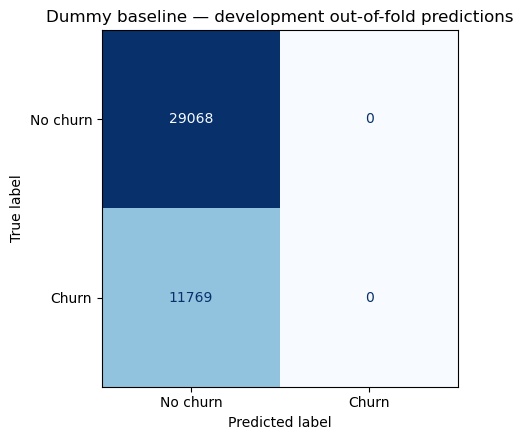

Non-churners correctly predicted: 29,068
Churn customers missed: 11,769


In [72]:
# Confusion matrix from the combined out-of-fold predictions.
baseline_oof_cm = confusion_matrix(
    baseline_oof_predictions["Actual_Churn"],
    baseline_oof_predictions["Predicted_Churn"],
    labels=[0, 1],
)
tn, fp, fn, tp = baseline_oof_cm.ravel()

baseline_error_summary = pd.DataFrame(
    [
        ("True negatives (No churn correctly identified)", int(tn)),
        ("False positives (No churn predicted as churn)", int(fp)),
        ("False negatives (Churn missed)", int(fn)),
        ("True positives (Churn correctly identified)", int(tp)),
    ],
    columns=["Confusion_matrix_component", "Count"],
)
display(baseline_error_summary)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=baseline_oof_cm,
    display_labels=["No churn", "Churn"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Dummy baseline — development out-of-fold predictions")
plt.tight_layout()
plt.show()

print(f"Non-churners correctly predicted: {tn:,}")
print(f"Churn customers missed: {fn:,}")
assert tp == fp == 0
assert tn + fn == len(y_dev)
assert fn == int(y_dev.sum())

The combined out-of-fold predictions classify all **29,068** non-churners correctly and miss all **11,769** churners, with no false positives and no true positives. In every fold, the baseline's Average Precision equals that fold's churn rate (0.2881–0.2882) and its ROC-AUC is exactly 0.50. This confirms that the evaluation code behaves as expected for a model with no skill.

### 7.7 Benchmark Row for Later Comparisons

The baseline's mean metrics are stored as the first row of the model-comparison table, which later sections extend.

In [73]:
# One-row reference that the later model-comparison tables append to.
baseline_comparison_row = pd.DataFrame(
    [
        {
            "Model": "Dummy (prior)",
            "Feature_set": "No feature dependence",
            "CV_folds": N_CV_SPLITS,
            **{
                f"{m}_cv_mean": float(baseline_cv_summary.loc[m, "CV_mean"])
                for m in BASELINE_METRIC_KEYS
            },
            **{
                f"{m}_cv_sd": float(baseline_cv_summary.loc[m, "CV_sd"])
                for m in BASELINE_METRIC_KEYS
            },
        }
    ]
)
comparison_display_cols = ["Model", "Feature_set", "CV_folds"] + [
    f"{m}_cv_mean" for m in BASELINE_METRIC_KEYS
]
display(baseline_comparison_row[comparison_display_cols].round(5))

,Model,Feature_set,CV_folds,average_precision_cv_mean,roc_auc_cv_mean,accuracy_cv_mean,balanced_accuracy_cv_mean,precision_cv_mean,recall_cv_mean,f1_cv_mean,mcc_cv_mean
0,Dummy (prior),No feature dependence,5,0.28819,0.5,0.71181,0.5,0.0,0.0,0.0,0.0


The baseline reaches **71.18% accuracy** but finds **none of the 11,769 churners**: its recall, precision, F1 and MCC are all 0. Its Average Precision is **0.288**, the churn rate itself, and its ROC-AUC is **0.50**. These are the values a model must clearly exceed to show real skill. The accuracy figure confirms that accuracy alone would be a misleading way to compare churn models.

## 8. Logistic Regression

Logistic Regression is the first of the two algorithms. This section describes how it works and then trains it with each of the three feature configurations on the same five folds as the baseline, using initial (untuned) settings.

### 8.1 Algorithm Background and Rationale

**How Logistic Regression works.** For a customer with encoded feature vector $\mathbf{x}$, Logistic Regression computes a linear score, the **log-odds** of churn,

$$z = \beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x} = \log\frac{P(\text{Churn}=1\mid\mathbf{x})}{1-P(\text{Churn}=1\mid\mathbf{x})},$$

and converts it into a churn probability with the **sigmoid** function

$$\hat{p} = \sigma(z) = \frac{1}{1+e^{-z}}.$$

The coefficients are learned by minimising the **log-loss** (binary cross-entropy) over the $n$ training customers, plus an **L2 penalty** that shrinks the coefficients:

$$J(\boldsymbol{\beta}) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log\hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{1}{2Cn}\lVert\boldsymbol{\beta}\rVert_2^{2}.$$

There is no closed-form solution, so scikit-learn's `lbfgs` solver minimises $J$ iteratively using its gradient, the same principle as gradient descent for linear regression (Lecture 3). `C` is the inverse regularisation strength ($C = 1/\lambda$): a smaller `C` shrinks the coefficients more, trading a little bias for lower variance (ridge-style regularisation). Because one penalty is applied to all coefficients, numerical features must be on comparable scales, which is why this pipeline standardises them. The decision boundary $z = 0$ (probability 0.5) is **linear** in the encoded features, so curved effects and interactions are only captured when they are encoded explicitly, for example through one-hot categories or the activity indicators.

**Why it suits this problem.**
- **Probabilistic output:** every customer receives a churn score that can be ranked or thresholded, which the AP-based evaluation and the targeting analysis require.
- **Interpretability:** each coefficient is the change in log-odds for a one-standard-deviation change in a numerical feature, or for a category, which helps explain churn risk.
- **Strong, fast baseline:** it fits about 40,000 customers × 370 encoded columns in seconds, and regularisation copes with the many sparse `ServiceArea` columns.
- **Limitation:** the linear log-odds assumption may under-use the skewed usage variables and the non-linear churn patterns found in the EDA, which motivates the non-linear second algorithm.

**Scope.** **Average Precision (AP)** is the primary metric because only about 29% of customers churn; ROC-AUC gives a second threshold-independent view, while precision, recall, F1, balanced accuracy, accuracy and MCC describe decisions at the default 0.5 threshold. This section compares feature representations with initial settings.

### 8.2 Initial Settings

The initial model is `LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000)`: scikit-learn's default L2 regularisation with no class weighting, and the default decision threshold of 0.5. Tuning of `C`, class weighting and the threshold is left to later sections, so that the effect of each change can be evaluated separately. The code confirms these settings before any model is fitted.

In [74]:
from sklearn.exceptions import ConvergenceWarning
import warnings

# Initial Logistic Regression settings, confirmed before any model is fitted.
LR8_FEATURE_SETS = tuple(FEATURE_SET_CONFIGURATIONS)
LR8_DEFAULT_THRESHOLD = 0.5
LR8_METRICS = tuple(BASELINE_METRIC_KEYS)
assert LR8_FEATURE_SETS == ("original", "engineered", "reduced_engineered")
assert PRIMARY_SCORING == "average_precision"
assert POSITIVE_CLASS == 1

lr8_model_setup = pd.DataFrame(
    [
        ("Estimator", "LogisticRegression", "L2-regularised binary classifier"),
        ("C", 1.0, "Initial regularisation strength; not tuned"),
        ("Solver", "lbfgs", "Initial scikit-learn solver"),
        ("max_iter", 2000, "Optimisation iteration cap"),
        ("Class weighting", "None", "Unweighted initial model"),
        ("Class threshold", 0.5, "Default classifier decisions"),
        ("Validation", "5-fold stratified", "Identical folds for all feature sets"),
        ("Primary measure", "Average Precision", "Calculated on each held-out fold"),
    ],
    columns=["Setting", "Value", "Reason"],
)
display(lr8_model_setup)

for feature_set in LR8_FEATURE_SETS:
    candidate = make_feature_set_pipeline("logistic", feature_set)
    clf = candidate.named_steps["classifier"]
    assert isinstance(clf, LogisticRegression)
    assert clf.C == 1.0 and clf.max_iter == 2000 and clf.class_weight is None
    assert clf.solver == "lbfgs" and clf.penalty in ("l2", "deprecated")
    # L2 penalty: scikit-learn < 1.8 reports l1_ratio=None; >= 1.8 reports l1_ratio=0.0.
    assert clf.l1_ratio in (None, 0.0)
    assert not hasattr(clf, "classes_")
print("Settings confirmed for the three Logistic Regression pipelines.")

,Setting,Value,Reason
0,Estimator,LogisticRegression,L2-regularised binary classifier
1,C,1.0,Initial regularisation strength; not tuned
2,Solver,lbfgs,Initial scikit-learn solver
3,max_iter,2000,Optimisation iteration cap
4,Class weighting,None,Unweighted initial model
5,Class threshold,0.5,Default classifier decisions
6,Validation,5-fold stratified,Identical folds for all feature sets
7,Primary measure,Average Precision,Calculated on each held-out fold


Settings confirmed for the three Logistic Regression pipelines.


### 8.3 Evaluation Design

All three configurations (original, engineered and reduced) are trained on the same 40,837 development customers, with the same five folds and settings. Any difference in results is therefore due to the feature representation alone. That gives 15 model fits.

In [75]:
# Fold sizes and churn rates for the Logistic Regression experiments.
lr8_splits = cv_splits  # the same five folds as the baseline
lr8_fold_design = pd.DataFrame(
    [
        {
            "Fold": i,
            "Training_n": len(t),
            "Validation_n": len(v),
            "Validation_churn_rate": float(y_dev.iloc[v].mean()),
        }
        for i, (t, v) in enumerate(lr8_splits, 1)
    ]
)
display(lr8_fold_design.round(5))
print("Model fits to run:", len(LR8_FEATURE_SETS) * len(lr8_splits))

,Fold,Training_n,Validation_n,Validation_churn_rate
0,1,32669,8168,0.28820
1,2,32669,8168,0.28820
2,3,32670,8167,0.28811
3,4,32670,8167,0.28823
4,5,32670,8167,0.28823


Model fits to run: 15


### 8.4 Cross-Validation Results

For each configuration and fold, a fresh pipeline (cleaning, imputation, scaling, encoding and, for configuration C, feature selection) is fitted on the training fold and used to score the validation fold. The number of solver iterations and the number of model columns are also recorded.

In [76]:
# Cross-validate Logistic Regression with each feature configuration.
lr8_fold_tables = []
lr8_oof_predictions = {}
for feature_set in LR8_FEATURE_SETS:
    folds, oof = cross_validate_pipeline(
        lambda fs=feature_set: make_feature_set_pipeline("logistic", fs),
        X_dev_primary,
        y_dev,
        lr8_splits,
        fold_details=logistic_details,
    )
    lr8_fold_tables.append(folds.assign(Model="Logistic Regression", Feature_set=feature_set))
    lr8_oof_predictions[feature_set] = oof
    print(f"{feature_set}: {len(folds)} folds fitted, {len(oof):,} out-of-fold predictions")

lr8_cv_results = pd.concat(lr8_fold_tables, ignore_index=True)
# Fold-1 predictions are kept for a like-for-like precision-recall plot in Section 8.6.
lr8_first_fold_curves = {
    fs: {
        "actual": oof.loc[oof.CV_Fold == 1, "Actual_Churn"].to_numpy(),
        "probability": oof.loc[oof.CV_Fold == 1, "Predicted_Churn_Probability"].to_numpy(),
    }
    for fs, oof in lr8_oof_predictions.items()
}
view_cols = [
    "Feature_set",
    "Fold",
    "Encoded_features",
    "Model_features",
    "Iterations",
    "average_precision",
    "roc_auc",
    "recall",
    "f1",
]
display(lr8_cv_results[view_cols].round(5))
print("Warnings during fitting:", int(lr8_cv_results["Warning_count"].sum()))

original: 5 folds fitted, 40,837 out-of-fold predictions
engineered: 5 folds fitted, 40,837 out-of-fold predictions
reduced_engineered: 5 folds fitted, 40,837 out-of-fold predictions


,Feature_set,Fold,Encoded_features,Model_features,Iterations,average_precision,roc_auc,recall,f1
0,original,1,371,371,164,0.39948,0.62905,0.04503,0.08343
1,original,2,377,377,177,0.37585,0.60688,0.04843,0.08851
2,original,3,372,372,166,0.36375,0.61018,0.03485,0.06391
3,original,4,374,374,148,0.36310,0.59821,0.05438,0.09764
4,original,5,372,372,152,0.37167,0.60549,0.04715,0.08529
5,engineered,1,376,376,161,0.39995,0.62857,0.04545,0.08412
6,engineered,2,382,382,159,0.37736,0.60802,0.04885,0.08925
7,engineered,3,377,377,179,0.36450,0.61109,0.03782,0.06913
8,engineered,4,379,379,163,0.36507,0.59934,0.05395,0.09691
9,engineered,5,377,377,149,0.37214,0.60518,0.04928,0.08909


Warnings during fitting: 0


### 8.5 Comparing the Feature Configurations

The table gives the mean and standard deviation of each metric across the five folds. The second table compares the configurations fold by fold, which removes the variation caused by some folds simply being easier than others.

In [77]:
# Mean and standard deviation of each metric per feature configuration.
lr8_cv_summary = lr8_cv_results.groupby("Feature_set")[list(LR8_METRICS)].agg(["mean", "std"])
lr8_cv_summary.columns = [f"{metric}_cv_{stat}" for metric, stat in lr8_cv_summary.columns]
lr8_cv_summary = lr8_cv_summary.reindex(LR8_FEATURE_SETS)

lr8_key_metrics = [
    "average_precision_cv_mean",
    "average_precision_cv_std",
    "roc_auc_cv_mean",
    "roc_auc_cv_std",
    "accuracy_cv_mean",
    "balanced_accuracy_cv_mean",
    "precision_cv_mean",
    "recall_cv_mean",
    "f1_cv_mean",
    "mcc_cv_mean",
]
display(lr8_cv_summary[lr8_key_metrics].round(5))

# Fold-by-fold AP differences between configurations (removes fold-to-fold variation).
lr8_paired_ap = lr8_cv_results.pivot(
    index="Fold", columns="Feature_set", values="average_precision"
).reindex(columns=LR8_FEATURE_SETS)
lr8_paired_ap["engineered_minus_original"] = lr8_paired_ap["engineered"] - lr8_paired_ap["original"]
lr8_paired_ap["reduced_minus_original"] = (
    lr8_paired_ap["reduced_engineered"] - lr8_paired_ap["original"]
)
display(lr8_paired_ap.round(5))
print(
    "Mean AP change, engineered vs original: "
    f"{lr8_paired_ap['engineered_minus_original'].mean():+.5f}"
)
print(
    "Mean AP change, reduced vs original: " f"{lr8_paired_ap['reduced_minus_original'].mean():+.5f}"
)

,average_precision_cv_mean,average_precision_cv_std,roc_auc_cv_mean,roc_auc_cv_std,accuracy_cv_mean,balanced_accuracy_cv_mean,precision_cv_mean,recall_cv_mean,f1_cv_mean,mcc_cv_mean
Feature_set,,,,,,,,,,
original,0.37477,0.01482,0.60996,0.01153,0.71041,0.51270,0.47775,0.04597,0.08376,0.07020
engineered,0.37580,0.01451,0.61044,0.01102,0.71073,0.51325,0.48388,0.04707,0.08570,0.07290
reduced_engineered,0.37587,0.01455,0.61091,0.01059,0.71068,0.51248,0.48273,0.04461,0.08160,0.07052


Feature_set,original,engineered,reduced_engineered,engineered_minus_original,reduced_minus_original
Fold,,,,,
1,0.39948,0.39995,0.39992,0.00047,0.00044
2,0.37585,0.37736,0.37820,0.00151,0.00235
3,0.36375,0.36450,0.36462,0.00075,0.00088
4,0.36310,0.36507,0.36504,0.00198,0.00195
5,0.37167,0.37214,0.37154,0.00047,-0.00013


Mean AP change, engineered vs original: +0.00104
Mean AP change, reduced vs original: +0.00110


Logistic Regression clearly beats the baseline: mean Average Precision rises from **0.288** to about **0.375**, and ROC-AUC from 0.50 to about **0.610**. The three feature configurations, however, perform almost identically. Adding the activity indicators raises AP by only **0.0010** and the reduced set by **0.0011**, while AP varies by about **0.015** between folds. The new features and the reduced set do not make a meaningful difference for Logistic Regression.

### 8.6 Errors at the Default Threshold

The confusion matrices combine the out-of-fold predictions at the default 0.5 threshold. The precision–recall curves use the shared fold 1, so all three configurations are plotted on the same customers.

,TN,FP,FN,TP,Predicted_churn_n,Churn_recall,False_positive_rate
Feature_set,,,,,,,
original,28470,598,11228,541,1139,0.04597,0.02057
engineered,28470,598,11215,554,1152,0.04707,0.02057
reduced_engineered,28497,571,11244,525,1096,0.04461,0.01964


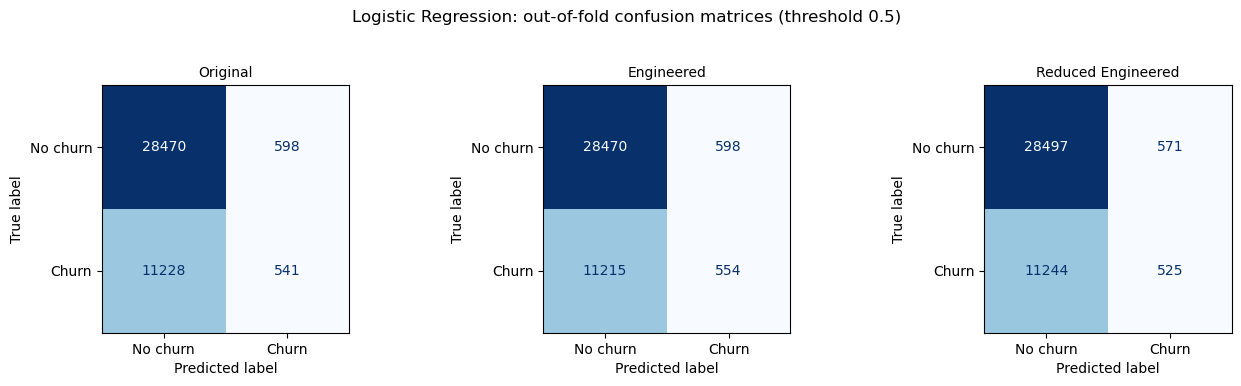

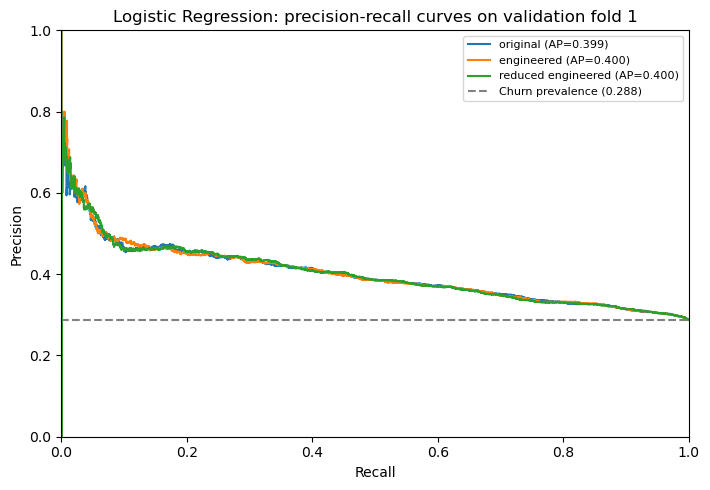

In [78]:
from sklearn.metrics import precision_recall_curve

# Confusion counts at the 0.5 threshold, and precision-recall curves on fold 1.
lr8_confusion_records = []
lr8_confusion_matrices = {}
for feature_set in LR8_FEATURE_SETS:
    oof = lr8_oof_predictions[feature_set]
    cm = confusion_matrix(oof["Actual_Churn"], oof["Predicted_Churn"], labels=[0, 1])
    lr8_confusion_matrices[feature_set] = cm
    tn, fp, fn, tp = cm.ravel()
    lr8_confusion_records.append(
        {
            "Feature_set": feature_set,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "Predicted_churn_n": int(tp + fp),
            "Churn_recall": float(tp / (tp + fn)),
            "False_positive_rate": float(fp / (fp + tn)),
        }
    )
lr8_error_summary = pd.DataFrame(lr8_confusion_records).set_index("Feature_set")
display(lr8_error_summary.round(5))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))
for ax, feature_set in zip(axes, LR8_FEATURE_SETS):
    ConfusionMatrixDisplay(
        confusion_matrix=lr8_confusion_matrices[feature_set], display_labels=["No churn", "Churn"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(feature_set.replace("_", " ").title(), fontsize=10)
fig.suptitle("Logistic Regression: out-of-fold confusion matrices (threshold 0.5)", y=1.03)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 5.0))
for feature_set in LR8_FEATURE_SETS:
    fold_data = lr8_first_fold_curves[feature_set]
    precision_values, recall_values, _ = precision_recall_curve(
        fold_data["actual"], fold_data["probability"]
    )
    fold_ap = average_precision_score(fold_data["actual"], fold_data["probability"])
    ax.plot(
        recall_values, precision_values, label=f'{feature_set.replace("_", " ")} (AP={fold_ap:.3f})'
    )
fold_1_prevalence = float(lr8_first_fold_curves["original"]["actual"].mean())
ax.axhline(
    fold_1_prevalence,
    linestyle="--",
    color="grey",
    label=f"Churn prevalence ({fold_1_prevalence:.3f})",
)
ax.set(
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1),
    title="Logistic Regression: precision-recall curves on validation fold 1",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

At the default threshold, Logistic Regression identifies very few churners: recall is only **4.5–4.7%**. With the original features it finds **541 of 11,769** churners and misses 11,228. The model *ranks* customers better than chance, but because its predicted probabilities rarely exceed 0.5, almost every customer is classified as "No churn".

### 8.7 Comparison With the Baseline

The three Logistic Regression results are added to the comparison table that started with the baseline.

In [79]:
# Add the Logistic Regression results to the comparison table that starts with the baseline.
lr8_comparison_rows = []
for feature_set in LR8_FEATURE_SETS:
    sub = lr8_cv_results.loc[lr8_cv_results["Feature_set"] == feature_set]
    row = {"Model": "Logistic Regression", "Feature_set": feature_set, "CV_folds": N_CV_SPLITS}
    row.update({f"{metric}_cv_mean": float(sub[metric].mean()) for metric in LR8_METRICS})
    row.update({f"{metric}_cv_sd": float(sub[metric].std(ddof=1)) for metric in LR8_METRICS})
    lr8_comparison_rows.append(row)
lr8_comparison_row = pd.DataFrame(lr8_comparison_rows)
lr8_model_comparison = pd.concat([baseline_comparison_row, lr8_comparison_row], ignore_index=True)

lr8_display_columns = [
    "Model",
    "Feature_set",
    "CV_folds",
    "average_precision_cv_mean",
    "average_precision_cv_sd",
    "roc_auc_cv_mean",
    "recall_cv_mean",
    "precision_cv_mean",
    "f1_cv_mean",
    "accuracy_cv_mean",
    "balanced_accuracy_cv_mean",
    "mcc_cv_mean",
]
display(lr8_model_comparison[lr8_display_columns].round(5))

lr8_best_feature_set = str(lr8_cv_summary["average_precision_cv_mean"].idxmax())
lr8_best_ap = float(lr8_cv_summary.loc[lr8_best_feature_set, "average_precision_cv_mean"])
lr8_baseline_ap = float(baseline_cv_summary.loc["average_precision", "CV_mean"])
print(f"Best mean CV AP: {lr8_best_feature_set} ({lr8_best_ap:.5f}).")
print(f"Improvement over the baseline AP: {lr8_best_ap - lr8_baseline_ap:+.5f}.")

,Model,Feature_set,CV_folds,average_precision_cv_mean,average_precision_cv_sd,roc_auc_cv_mean,recall_cv_mean,precision_cv_mean,f1_cv_mean,accuracy_cv_mean,balanced_accuracy_cv_mean,mcc_cv_mean
0,Dummy (prior),No feature dependence,5,0.28819,0.00005,0.50000,0.00000,0.00000,0.00000,0.71181,0.50000,0.00000
1,Logistic Regression,original,5,0.37477,0.01482,0.60996,0.04597,0.47775,0.08376,0.71041,0.51270,0.07020
2,Logistic Regression,engineered,5,0.37580,0.01451,0.61044,0.04707,0.48388,0.08570,0.71073,0.51325,0.07290
3,Logistic Regression,reduced_engineered,5,0.37587,0.01455,0.61091,0.04461,0.48273,0.08160,0.71068,0.51248,0.07052


Best mean CV AP: reduced_engineered (0.37587).
Improvement over the baseline AP: +0.08767.


Compared with the baseline, Logistic Regression gains about **0.087** in Average Precision and **0.11** in ROC-AUC, so its scores contain real information about churn risk. Its accuracy (about 71.0–71.1%) is no better than the baseline's 71.2%, another reminder that accuracy is the wrong yardstick for this problem. The reduced configuration has the highest mean AP (0.37587), but its lead over the original features is too small to matter, so later sections continue with the simpler **original** feature set.

### 8.8 Convergence and Score Distribution

Every fit is checked for convergence, and the predicted churn scores are compared between churners and non-churners.

,Fits,Iterations_min,Iterations_max,Encoded_min,Encoded_max,Selected_min,Selected_max,Cap_reached
Feature_set,,,,,,,,
original,5,148,177,371,377,371,377,0
engineered,5,149,179,376,382,376,382,0
reduced_engineered,5,133,177,376,382,244,248,0


No warnings during the 15 cross-validation fits.


,count,mean,median,min,max
Actual_Churn,,,,,
0,29068,0.27729,0.26866,0.01080,0.99400
1,11769,0.31501,0.30502,0.03396,0.99716


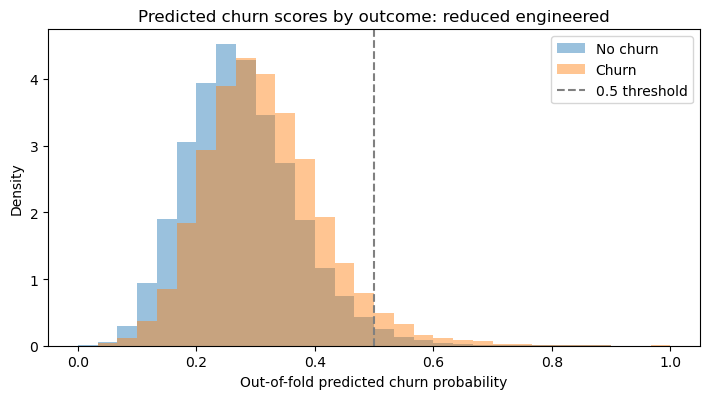

In [80]:
# Convergence (solver iterations) and the distribution of predicted scores.
lr8_diagnostics = (
    lr8_cv_results.groupby("Feature_set")
    .agg(
        Fits=("Fold", "size"),
        Iterations_min=("Iterations", "min"),
        Iterations_max=("Iterations", "max"),
        Encoded_min=("Encoded_features", "min"),
        Encoded_max=("Encoded_features", "max"),
        Selected_min=("Model_features", "min"),
        Selected_max=("Model_features", "max"),
        Cap_reached=("Reached_iteration_cap", "sum"),
    )
    .reindex(LR8_FEATURE_SETS)
)
display(lr8_diagnostics)

if lr8_cv_results["Warning_count"].sum():
    display(
        lr8_cv_results.loc[
            lr8_cv_results["Warning_count"] > 0, ["Feature_set", "Fold", "Warning_types"]
        ]
    )
else:
    print("No warnings during the 15 cross-validation fits.")

lr8_best_oof = lr8_oof_predictions[lr8_best_feature_set]
score_summary = lr8_best_oof.groupby("Actual_Churn")["Predicted_Churn_Probability"].agg(
    ["count", "mean", "median", "min", "max"]
)
display(score_summary.round(5))
fig, ax = plt.subplots(figsize=(7.2, 4.1))
for value, label in ((0, "No churn"), (1, "Churn")):
    vals = lr8_best_oof.loc[lr8_best_oof["Actual_Churn"] == value, "Predicted_Churn_Probability"]
    ax.hist(vals, bins=np.linspace(0, 1, 31), density=True, alpha=0.45, label=label)
ax.axvline(LR8_DEFAULT_THRESHOLD, linestyle="--", color="grey", label="0.5 threshold")
ax.set(
    xlabel="Out-of-fold predicted churn probability",
    ylabel="Density",
    title=f'Predicted churn scores by outcome: {lr8_best_feature_set.replace("_", " ")}',
)
ax.legend()
plt.tight_layout()
plt.show()

### 8.9 Findings

All 15 fits converged well within the iteration limit (at most 179 of 2,000 iterations) with no warnings. Predicted scores are only slightly higher for churners than for non-churners (median **0.305** vs **0.269**), and the two distributions overlap heavily. This explains both the modest ranking performance and the very low recall at 0.5. Logistic Regression with the original features (CV AP **0.3748**, ROC-AUC **0.6100**) is the reference for the tuning.

## 9. Random Forest

Random Forest is the second algorithm. It is trained on exactly the same customers, folds and feature configurations as Logistic Regression, which allows a direct comparison. The section also checks whether its fully grown trees overfit the training data.

### 9.1 Algorithm Background and Rationale

**Decision trees.** A classification tree repeatedly splits the customers into smaller groups with rules such as *CurrentEquipmentDays ≤ 300*. At each node it picks the split that most reduces **impurity**. scikit-learn's default impurity measure is the **Gini index**

$$G(D) = 1 - \sum_{k} p_k^{2},$$

where $p_k$ is the proportion of class $k$ (churn or no churn) in node $D$. The chosen split maximises the **Gini gain** $G(D) - \sum_{j}\frac{|D_j|}{|D|}\,G(D_j)$ over the child nodes $D_j$, the same idea as information gain with entropy. A leaf predicts the churn proportion of its training customers. Trees capture non-linear effects and interactions automatically and need no feature scaling, but a single deep tree has **high variance**: it can memorise the training data unless it is pruned or constrained.

**Random Forest.** A Random Forest (Breiman, 2001) builds many trees and combines them to reduce that variance:

1. **Bagging (bootstrap aggregation):** each tree is trained on a bootstrap sample of the training customers, drawn with replacement.
2. **Random feature subsets:** at each split only a random subset of the features is considered (`max_features`; the default for classification is $\sqrt{p}$ of the $p$ features). This makes the trees less correlated, so averaging helps more.
3. **Aggregation:** the forest's churn score is the average of the trees' predicted probabilities, $\hat{p}(\mathbf{x}) = \frac{1}{T}\sum_{t=1}^{T}\hat{p}_t(\mathbf{x})$.

Averaging many low-bias, high-variance trees lowers the variance while keeping the bias low (the bias–variance trade-off). The main hyperparameters are the number of trees (`n_estimators`), the tree size (`max_depth`, `min_samples_leaf`) and the number of features considered at each split (`max_features`).

**Why it suits this problem.**
- **Non-linear patterns and interactions:** the EDA showed churn rates that change unevenly across tenure and equipment-age bands, which trees can follow without manual feature engineering.
- **Robust to skew and outliers:** splits depend only on the order of values, so the long-tailed usage variables need no transformation or scaling.
- **Mixed data types:** binary, one-hot and numerical inputs are handled in the same model.
- **Limitations:** less interpretable than a coefficient table (permutation importance is used instead), deep trees overfit, scores are not necessarily calibrated, and training is slower.

**Comparison of the two algorithms.**

| Property | Logistic Regression | Random Forest |
|---|---|---|
| Model family | Linear model of the log-odds | Ensemble of decision trees (bagging) |
| Decision boundary | Linear in the encoded features | Non-linear; learns interactions |
| Feature scaling needed | Yes (shared L2 penalty) | No |
| Sensitivity to skew and outliers | Higher | Low (splits use value order only) |
| Interpretability | Signed coefficients (log-odds) | Permutation importance; trees hard to read |
| Main overfitting control | `C` (L2 penalty) | Tree depth, leaf size, number of trees, `max_features` |
| Training cost here | Seconds | Tens of seconds |

**Why not other algorithms covered in the module?**
- **k-Nearest Neighbours:** relies on distances, which become less informative with about 370 mostly sparse encoded columns (the curse of dimensionality), and every prediction must search 40,000 training customers.
- **Support Vector Machines:** kernel SVMs scale poorly to 40,000 training rows and do not produce probabilities without an extra calibration step.
- **Naive Bayes:** assumes the features are conditionally independent, which the strongly correlated usage features contradict.
- **Boosting (AdaBoost, gradient boosting):** a strong option for tabular data; Logistic Regression and Random Forest were chosen instead because together they give a clear linear-versus-non-linear comparison for the two required algorithms.
- **Deep learning:** not permitted by the assignment brief.

**References.** Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. · Hastie, T., Tibshirani, R. and Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. · scikit-learn documentation for `LogisticRegression` and `RandomForestClassifier`.

**Scope.** The initial experiment uses the same development folds and AP metric as Logistic Regression, and separately measures the training-versus-validation gap.

### 9.2 Initial Settings

The initial settings are scikit-learn's defaults: **100 trees**, `max_features='sqrt'`, bootstrap sampling, no depth limit (`max_depth=None`) and a minimum leaf size of 1, with no class weighting. The preprocessing is the same as for Logistic Regression, except that numerical features are not scaled.

In [81]:
from time import perf_counter
from sklearn.ensemble import RandomForestClassifier

# Initial Random Forest settings (scikit-learn defaults), confirmed before fitting.
RF9_FEATURE_SETS = tuple(FEATURE_SET_CONFIGURATIONS)
RF9_METRICS = tuple(BASELINE_METRIC_KEYS)
RF9_DEFAULT_THRESHOLD = 0.5
assert RF9_FEATURE_SETS == LR8_FEATURE_SETS
assert PRIMARY_SCORING == "average_precision" and POSITIVE_CLASS == 1

rf9_settings = []
for feature_set in RF9_FEATURE_SETS:
    unfitted = make_feature_set_pipeline("random_forest", feature_set)
    clf = unfitted.named_steps["classifier"]
    assert isinstance(clf, RandomForestClassifier)
    assert (
        clf.n_estimators == 100
        and clf.max_depth is None
        and clf.min_samples_leaf == 1
        and clf.min_samples_split == 2
        and clf.max_features == "sqrt"
        and clf.bootstrap
        and clf.class_weight is None
        and clf.random_state == RANDOM_STATE
        and clf.n_jobs == -1
    )
    assert not hasattr(clf, "estimators_")
    rf9_settings.append(
        {
            "Feature_set": feature_set,
            "Steps": " → ".join(unfitted.named_steps),
            "Trees": clf.n_estimators,
            "Max_depth": "None (not capped)",
            "Min_leaf": clf.min_samples_leaf,
            "Max_features": clf.max_features,
            "Bootstrap": clf.bootstrap,
            "Class_weight": str(clf.class_weight),
        }
    )
rf9_configuration_table = pd.DataFrame(rf9_settings)
display(rf9_configuration_table)
print("Settings confirmed for the three Random Forest pipelines.")

,Feature_set,Steps,Trees,Max_depth,Min_leaf,Max_features,Bootstrap,Class_weight
0,original,structural_cleaning → preprocessor → classifier,100,None (not capped),1,sqrt,True,None
1,engineered,structural_cleaning → activity_features → prep...,100,None (not capped),1,sqrt,True,None
2,reduced_engineered,structural_cleaning → activity_features → prep...,100,None (not capped),1,sqrt,True,None


Settings confirmed for the three Random Forest pipelines.


### 9.3 Evaluation Design

The three feature configurations and the five folds are exactly those used for Logistic Regression. For a tree model the reduced configuration is a useful test, because univariate selection may remove features that only matter in combination with others.

In [82]:
# Random Forest uses exactly the same five folds as Logistic Regression.
rf9_splits = lr8_splits
rf9_fold_design = pd.DataFrame(
    [
        {
            "Fold": fold_no,
            "Training_n": len(train_idx),
            "Validation_n": len(valid_idx),
            "Validation_churn_rate": float(y_dev.iloc[valid_idx].mean()),
        }
        for fold_no, (train_idx, valid_idx) in enumerate(rf9_splits, start=1)
    ]
)
assert len(rf9_splits) == N_CV_SPLITS == 5
assert np.array_equal(rf9_fold_design["Training_n"], lr8_fold_design["Training_n"])
assert np.array_equal(rf9_fold_design["Validation_n"], lr8_fold_design["Validation_n"])
assert X_dev_primary.index.equals(y_dev.index)
assert all(np.intersect1d(t, v).size == 0 for t, v in rf9_splits)
display(rf9_fold_design.round(5))
print("Model fits to run:", len(RF9_FEATURE_SETS) * len(rf9_splits))

,Fold,Training_n,Validation_n,Validation_churn_rate
0,1,32669,8168,0.28820
1,2,32669,8168,0.28820
2,3,32670,8167,0.28811
3,4,32670,8167,0.28823
4,5,32670,8167,0.28823


Model fits to run: 15


### 9.4 Cross-Validation Results

For each configuration and fold, a fresh pipeline is fitted and the validation metrics are recorded. The Average Precision on the *training* fold and the size of the trees are also recorded, because they help to diagnose overfitting.

In [83]:
# Cross-validate Random Forest with each feature configuration; also record training AP and tree size.
rf9_fold_tables = []
rf9_oof_predictions = {}
for feature_set in RF9_FEATURE_SETS:
    folds, oof = cross_validate_pipeline(
        lambda fs=feature_set: make_feature_set_pipeline("random_forest", fs),
        X_dev_primary,
        y_dev,
        rf9_splits,
        fold_details=forest_details,
    )
    rf9_fold_tables.append(folds.assign(Model="Random Forest", Feature_set=feature_set))
    rf9_oof_predictions[feature_set] = oof
    print(
        f"{feature_set}: mean validation AP={folds['average_precision'].mean():.5f} | "
        f"mean training AP={folds['Training_average_precision'].mean():.5f} | "
        f"fit {folds['Fit_seconds'].sum():.0f}s"
    )

rf9_cv_results = pd.concat(rf9_fold_tables, ignore_index=True)
rf9_cv_results["AP_train_minus_valid"] = (
    rf9_cv_results["Training_average_precision"] - rf9_cv_results["average_precision"]
)
# Fold-1 predictions are kept for a like-for-like precision-recall plot in Section 9.6.
rf9_first_fold_curves = {
    fs: {
        "actual": oof.loc[oof.CV_Fold == 1, "Actual_Churn"].to_numpy(),
        "probability": oof.loc[oof.CV_Fold == 1, "Predicted_Churn_Probability"].to_numpy(),
    }
    for fs, oof in rf9_oof_predictions.items()
}
display(
    rf9_cv_results[
        [
            "Feature_set",
            "Fold",
            "Encoded_features",
            "Model_features",
            "Training_average_precision",
            "average_precision",
            "roc_auc",
            "recall",
            "f1",
            "Depth_mean",
            "Depth_max",
        ]
    ].round(5)
)
print("Warnings during fitting:", int(rf9_cv_results["Warning_count"].sum()))

original: mean validation AP=0.42278 | mean training AP=1.00000 | fit 42s
engineered: mean validation AP=0.42178 | mean training AP=1.00000 | fit 47s
reduced_engineered: mean validation AP=0.42246 | mean training AP=1.00000 | fit 41s


,Feature_set,Fold,Encoded_features,Model_features,Training_average_precision,average_precision,roc_auc,recall,f1,Depth_mean,Depth_max
0,original,1,371,371,1.0,0.43343,0.66027,0.04885,0.09069,59.19,84
1,original,2,377,377,1.0,0.41390,0.64536,0.05140,0.09446,58.72,79
2,original,3,372,372,1.0,0.42316,0.65719,0.04845,0.08927,57.77,78
3,original,4,374,374,1.0,0.42717,0.65407,0.05438,0.10027,57.28,87
4,original,5,372,372,1.0,0.41621,0.65305,0.04333,0.08054,58.46,78
5,engineered,1,376,376,1.0,0.43721,0.66129,0.05395,0.09969,57.42,76
6,engineered,2,382,382,1.0,0.41282,0.64670,0.04715,0.08720,58.03,86
7,engineered,3,377,377,1.0,0.41670,0.65279,0.04760,0.08781,56.96,82
8,engineered,4,379,379,1.0,0.42013,0.64539,0.04843,0.08994,58.32,72
9,engineered,5,377,377,1.0,0.42202,0.65885,0.04291,0.07981,57.08,81


Warnings during fitting: 0


### 9.5 Comparing the Feature Configurations

In [84]:
# Mean and standard deviation per configuration, and fold-by-fold AP differences.
rf9_cv_summary = rf9_cv_results.groupby("Feature_set")[list(RF9_METRICS)].agg(["mean", "std"])
rf9_cv_summary.columns = [f"{metric}_cv_{stat}" for metric, stat in rf9_cv_summary.columns]
rf9_cv_summary = rf9_cv_summary.reindex(RF9_FEATURE_SETS)
rf9_key_metrics = [
    "average_precision_cv_mean",
    "average_precision_cv_std",
    "roc_auc_cv_mean",
    "roc_auc_cv_std",
    "accuracy_cv_mean",
    "balanced_accuracy_cv_mean",
    "precision_cv_mean",
    "recall_cv_mean",
    "f1_cv_mean",
    "mcc_cv_mean",
]
display(rf9_cv_summary[rf9_key_metrics].round(5))

rf9_paired_ap = rf9_cv_results.pivot(
    index="Fold", columns="Feature_set", values="average_precision"
).reindex(columns=RF9_FEATURE_SETS)
rf9_paired_ap["engineered_minus_original"] = rf9_paired_ap["engineered"] - rf9_paired_ap["original"]
rf9_paired_ap["reduced_minus_original"] = (
    rf9_paired_ap["reduced_engineered"] - rf9_paired_ap["original"]
)
display(rf9_paired_ap.round(5))
print(
    "Mean AP difference, engineered vs original:",
    f'{rf9_paired_ap["engineered_minus_original"].mean():+.5f}',
)
print(
    "Mean AP difference, reduced vs original:",
    f'{rf9_paired_ap["reduced_minus_original"].mean():+.5f}',
)

,average_precision_cv_mean,average_precision_cv_std,roc_auc_cv_mean,roc_auc_cv_std,accuracy_cv_mean,balanced_accuracy_cv_mean,precision_cv_mean,recall_cv_mean,f1_cv_mean,mcc_cv_mean
Feature_set,,,,,,,,,,
original,0.42278,0.00798,0.65399,0.00559,0.71648,0.51795,0.59876,0.04928,0.09105,0.10682
engineered,0.42178,0.00931,0.65300,0.00708,0.71641,0.51752,0.59978,0.04801,0.08889,0.10569
reduced_engineered,0.42246,0.00791,0.65244,0.00885,0.71619,0.51964,0.57730,0.05565,0.10149,0.10803


Feature_set,original,engineered,reduced_engineered,engineered_minus_original,reduced_minus_original
Fold,,,,,
1,0.43343,0.43721,0.43477,0.00378,0.00135
2,0.41390,0.41282,0.41831,-0.00108,0.00441
3,0.42316,0.41670,0.42589,-0.00647,0.00272
4,0.42717,0.42013,0.41771,-0.00704,-0.00946
5,0.41621,0.42202,0.41559,0.00581,-0.00062


Mean AP difference, engineered vs original: -0.00100
Mean AP difference, reduced vs original: -0.00032


Random Forest reaches a mean Average Precision of **0.4228** with the original features, against **0.4218** with the activity indicators and **0.4225** with the reduced set; ROC-AUC is about **0.653–0.654**. As with Logistic Regression, the differences between configurations (at most 0.001) are far smaller than the fold-to-fold variation (about 0.008), and the paired fold differences change sign. The engineered and reduced features add nothing for Random Forest, so the **original** features are kept.

### 9.6 Errors at the Default Threshold

,TN,FP,FN,TP,Predicted_churn_n,Churn_recall,False_positive_rate
Feature_set,,,,,,,
original,28679,389,11189,580,969,0.04928,0.01338
engineered,28691,377,11204,565,942,0.04801,0.01297
reduced_engineered,28592,476,11114,655,1131,0.05565,0.01638


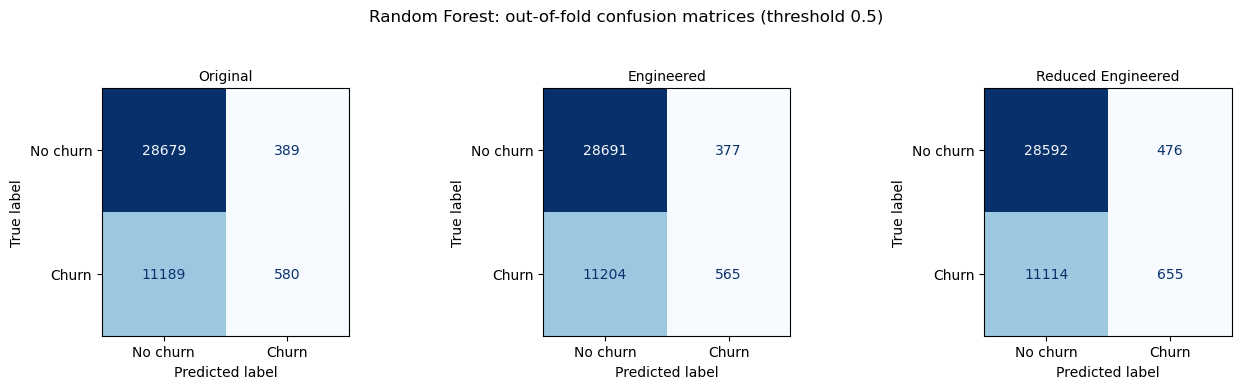

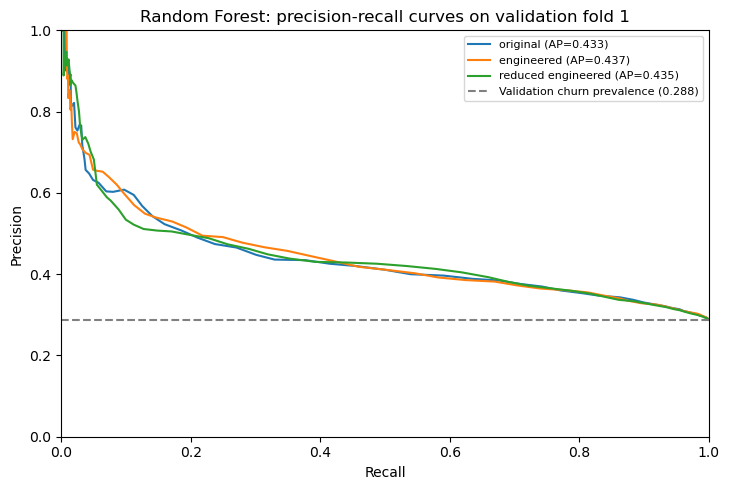

In [85]:
# Confusion counts at the 0.5 threshold, and precision-recall curves on fold 1.
rf9_confusion_records = []
rf9_confusion_matrices = {}
for feature_set in RF9_FEATURE_SETS:
    oof = rf9_oof_predictions[feature_set]
    matrix = confusion_matrix(oof["Actual_Churn"], oof["Predicted_Churn"], labels=[0, 1])
    rf9_confusion_matrices[feature_set] = matrix
    tn, fp, fn, tp = matrix.ravel()
    rf9_confusion_records.append(
        {
            "Feature_set": feature_set,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "Predicted_churn_n": int(tp + fp),
            "Churn_recall": float(tp / (tp + fn)),
            "False_positive_rate": float(fp / (fp + tn)),
        }
    )
rf9_error_summary = pd.DataFrame(rf9_confusion_records).set_index("Feature_set")
display(rf9_error_summary.round(5))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))
for ax, feature_set in zip(axes, RF9_FEATURE_SETS):
    ConfusionMatrixDisplay(
        confusion_matrix=rf9_confusion_matrices[feature_set], display_labels=["No churn", "Churn"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(feature_set.replace("_", " ").title(), fontsize=10)
fig.suptitle("Random Forest: out-of-fold confusion matrices (threshold 0.5)", y=1.04)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 5.0))
for feature_set in RF9_FEATURE_SETS:
    fold = rf9_first_fold_curves[feature_set]
    precision_vals, recall_vals, _ = precision_recall_curve(fold["actual"], fold["probability"])
    fold_ap = average_precision_score(fold["actual"], fold["probability"])
    ax.plot(
        recall_vals, precision_vals, label=f'{feature_set.replace("_", " ")} (AP={fold_ap:.3f})'
    )
prevalence = float(rf9_first_fold_curves["original"]["actual"].mean())
ax.axhline(
    prevalence,
    linestyle="--",
    color="grey",
    label=f"Validation churn prevalence ({prevalence:.3f})",
)
ax.set(
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1),
    title="Random Forest: precision-recall curves on validation fold 1",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

At the default 0.5 threshold Random Forest also finds very few churners: **580 of 11,769** with the original features (recall 4.9%), with 389 false positives. Its precision when it does predict churn (about 60%) is higher than Logistic Regression's, but at this threshold neither model is useful for finding churners. The precision–recall curves show that much more recall is available at lower thresholds.

### 9.7 Random Forest Versus Logistic Regression

Both algorithms are compared with the baseline. Because they share the same folds, the AP difference between them can also be computed fold by fold.

,Model,Feature_set,average_precision_cv_mean,average_precision_cv_sd,roc_auc_cv_mean,precision_cv_mean,recall_cv_mean,f1_cv_mean,accuracy_cv_mean,balanced_accuracy_cv_mean,mcc_cv_mean
0,Dummy (prior),No feature dependence,0.28819,0.00005,0.50000,0.00000,0.00000,0.00000,0.71181,0.50000,0.00000
1,Logistic Regression,original,0.37477,0.01482,0.60996,0.47775,0.04597,0.08376,0.71041,0.51270,0.07020
2,Logistic Regression,engineered,0.37580,0.01451,0.61044,0.48388,0.04707,0.08570,0.71073,0.51325,0.07290
3,Logistic Regression,reduced_engineered,0.37587,0.01455,0.61091,0.48273,0.04461,0.08160,0.71068,0.51248,0.07052
4,Random Forest,original,0.42278,0.00798,0.65399,0.59876,0.04928,0.09105,0.71648,0.51795,0.10682
5,Random Forest,engineered,0.42178,0.00931,0.65300,0.59978,0.04801,0.08889,0.71641,0.51752,0.10569
6,Random Forest,reduced_engineered,0.42246,0.00791,0.65244,0.57730,0.05565,0.10149,0.71619,0.51964,0.10803


,original,engineered,reduced_engineered
Fold (Random Forest AP − Logistic Regression AP),,,
1,0.03395,0.03725,0.03485
2,0.03805,0.03546,0.04011
3,0.05941,0.05220,0.06126
4,0.06408,0.05506,0.05267
5,0.04455,0.04989,0.04405


Mean RF − LR AP difference by feature set:
original              0.04801
engineered            0.04597
reduced_engineered    0.04659


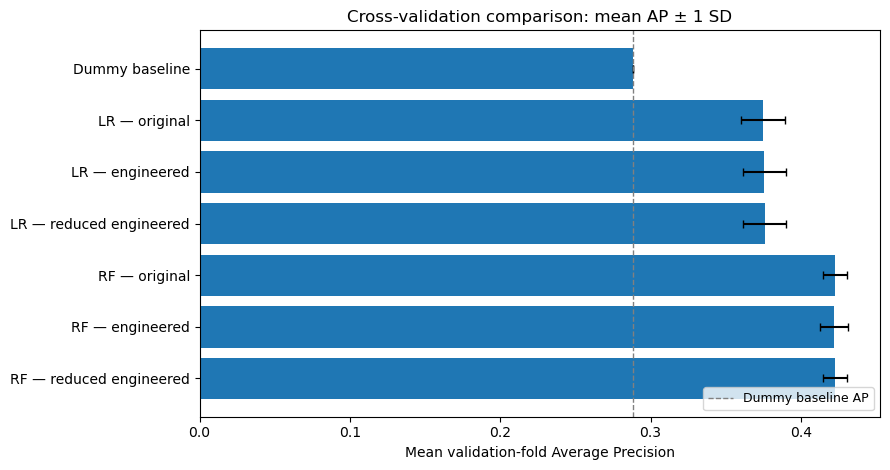

In [86]:
# Compare the baseline, Logistic Regression and Random Forest on the same folds.
rf9_comparison_rows = []
for feature_set in RF9_FEATURE_SETS:
    sub = rf9_cv_results.loc[rf9_cv_results["Feature_set"] == feature_set]
    record = {"Model": "Random Forest", "Feature_set": feature_set, "CV_folds": N_CV_SPLITS}
    record.update({f"{m}_cv_mean": float(sub[m].mean()) for m in RF9_METRICS})
    record.update({f"{m}_cv_sd": float(sub[m].std(ddof=1)) for m in RF9_METRICS})
    rf9_comparison_rows.append(record)
rf9_comparison_row = pd.DataFrame(rf9_comparison_rows)
rf9_model_comparison = pd.concat(
    [baseline_comparison_row, lr8_comparison_row, rf9_comparison_row],
    ignore_index=True,
)
rf9_display_columns = [
    "Model",
    "Feature_set",
    "average_precision_cv_mean",
    "average_precision_cv_sd",
    "roc_auc_cv_mean",
    "precision_cv_mean",
    "recall_cv_mean",
    "f1_cv_mean",
    "accuracy_cv_mean",
    "balanced_accuracy_cv_mean",
    "mcc_cv_mean",
]
display(rf9_model_comparison[rf9_display_columns].round(5))

rf9_lr_paired_ap = (
    rf9_cv_results.pivot(index="Fold", columns="Feature_set", values="average_precision")
    - lr8_cv_results.pivot(index="Fold", columns="Feature_set", values="average_precision")
).reindex(columns=RF9_FEATURE_SETS)
rf9_lr_paired_ap.columns.name = None
rf9_lr_paired_ap.index.name = "Fold (Random Forest AP − Logistic Regression AP)"
display(rf9_lr_paired_ap.round(5))
print("Mean RF − LR AP difference by feature set:")
print(rf9_lr_paired_ap.mean().round(5).to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_data = rf9_model_comparison.copy()
plot_labels = [
    (
        "Dummy baseline"
        if row["Model"] == "Dummy (prior)"
        else ("LR" if row["Model"] == "Logistic Regression" else "RF")
        + " — "
        + row["Feature_set"].replace("_", " ")
    )
    for _, row in plot_data.iterrows()
]
ax.barh(
    plot_labels,
    plot_data["average_precision_cv_mean"],
    xerr=plot_data["average_precision_cv_sd"],
    capsize=3,
)
ax.axvline(
    float(baseline_cv_summary.loc["average_precision", "CV_mean"]),
    linestyle="--",
    color="grey",
    linewidth=1.0,
    label="Dummy baseline AP",
)
ax.invert_yaxis()
ax.set(
    xlabel="Mean validation-fold Average Precision",
    title="Cross-validation comparison: mean AP ± 1 SD",
)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

Random Forest ranks churners clearly better than Logistic Regression. With the original features its mean AP is **0.4228** against **0.3748** (a difference of **+0.048**), and its ROC-AUC is **0.654** against **0.610**. It wins on **every one of the five folds** for every feature configuration, with fold differences between +0.034 and +0.064. This fits the EDA findings: several relationships with churn are non-linear (equipment age, tenure, usage), and a forest can represent them directly while a linear model cannot.

### 9.8 Overfitting Check

With no depth limit and a minimum leaf size of 1, each tree can keep splitting until it fits its training sample almost perfectly. Training-fold and validation-fold Average Precision are therefore compared, and the size of the trees is examined.

,Fits,Training_AP_mean,Validation_AP_mean,AP_gap_mean,AP_gap_min,AP_gap_max,Depth_mean,Depth_max,Leaves_mean,Encoded_min,Encoded_max,Model_features_min,Model_features_max,Trees_per_fit
Feature_set,,,,,,,,,,,,,,
original,5,1.0,0.4228,0.5772,0.5666,0.5861,58.284,87,7345.828,371,377,371,377,100
engineered,5,1.0,0.4218,0.5782,0.5628,0.5872,57.562,86,7355.598,376,382,376,382,100
reduced_engineered,5,1.0,0.4225,0.5775,0.5652,0.5844,51.534,83,7104.468,376,382,244,248,100


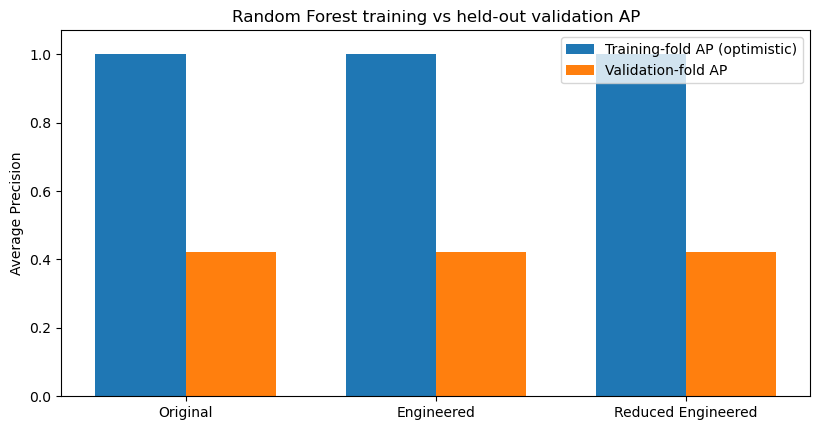

No warnings during the Random Forest fits.


In [87]:
# Overfitting check: training versus validation AP, and tree depth and size.
rf9_diagnostics = (
    rf9_cv_results.groupby("Feature_set")
    .agg(
        Fits=("Fold", "size"),
        Training_AP_mean=("Training_average_precision", "mean"),
        Validation_AP_mean=("average_precision", "mean"),
        AP_gap_mean=("AP_train_minus_valid", "mean"),
        AP_gap_min=("AP_train_minus_valid", "min"),
        AP_gap_max=("AP_train_minus_valid", "max"),
        Depth_mean=("Depth_mean", "mean"),
        Depth_max=("Depth_max", "max"),
        Leaves_mean=("Leaves_mean", "mean"),
        Encoded_min=("Encoded_features", "min"),
        Encoded_max=("Encoded_features", "max"),
        Model_features_min=("Model_features", "min"),
        Model_features_max=("Model_features", "max"),
        Trees_per_fit=("Trees_fitted", "min"),
    )
    .reindex(RF9_FEATURE_SETS)
)
display(rf9_diagnostics.round(4))

fig, ax = plt.subplots(figsize=(8.3, 4.4))
positions = np.arange(len(RF9_FEATURE_SETS))
width = 0.36
ax.bar(
    positions - width / 2,
    rf9_diagnostics["Training_AP_mean"],
    width,
    label="Training-fold AP (optimistic)",
)
ax.bar(
    positions + width / 2, rf9_diagnostics["Validation_AP_mean"], width, label="Validation-fold AP"
)
ax.set_xticks(positions, [s.replace("_", " ").title() for s in RF9_FEATURE_SETS])
ax.set(
    ylabel="Average Precision",
    ylim=(0, 1.07),
    title="Random Forest training vs held-out validation AP",
)
ax.legend()
plt.tight_layout()
plt.show()
if rf9_cv_results["Warning_count"].sum():
    display(
        rf9_cv_results.loc[
            rf9_cv_results["Warning_count"] > 0, ["Feature_set", "Fold", "Warning_types"]
        ]
    )
else:
    print("No warnings during the Random Forest fits.")

The forests fit their training data perfectly (training AP = **1.00**) but reach only about **0.42** on validation data, a gap of about **0.58**. The trees are very deep (about 58 levels on average, up to 87) with around 7,300 leaves each, so many leaves describe just one or two customers. The model has memorised much of its training data. Averaging 100 trees still produces useful validation performance, but the gap suggests that limiting tree growth may help, which Section 10 tests.

### 9.9 Findings

Random Forest is the stronger ranking model: it beats Logistic Regression by about 0.048 AP on every fold. Neither the activity indicators nor ANOVA-based selection improves it. Two weaknesses remain: the unrestricted trees overfit heavily, and at the default 0.5 threshold the model finds only about 5% of churners. Section 10 tunes tree complexity, and Section 11 addresses the threshold.

## 10. Hyperparameter Tuning

This section tunes the main hyperparameter of each algorithm: the regularisation strength `C` for Logistic Regression, and tree complexity for Random Forest. Both use the original 53 features, so that only the settings change. All tuning uses development data, and class weighting and thresholds are kept at their defaults for a later section.

### 10.1 Tuning Plan

For Logistic Regression, four values of `C` are compared on the five established folds. For Random Forest, a full grid search would be slow, so seven pre-chosen combinations of tree depth and leaf size are screened on three separate folds, and the best one is then re-evaluated on the established five folds. Average Precision is the selection criterion.

**Limitation:** because the settings are chosen on the same development data that later reports their performance, the tuned scores are slightly optimistic; only the test set gives an unbiased estimate.

In [88]:
from time import perf_counter
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.base import clone
from sklearn.metrics import average_precision_score
import warnings

# Tuning plan: both algorithms use the original 53 features and the same folds.
S10_FEATURE_SET = "original"
S10_METRICS = tuple(BASELINE_METRIC_KEYS)
S10_5FOLD = lr8_splits
S10_INITIAL_AP = {
    "Logistic Regression": float(lr8_cv_summary.loc["original", "average_precision_cv_mean"]),
    "Random Forest": float(rf9_cv_summary.loc["original", "average_precision_cv_mean"]),
}
s10_protocol = pd.DataFrame(
    [
        (
            "Modelling inputs",
            "53 original eligible predictors",
            "No change in feature representation",
        ),
        (
            "Training and selection",
            "Labelled development partition only",
            "Test set not used",
        ),
        (
            "Primary tuning score",
            "Average Precision (churn=1)",
            "Ranking rather than accuracy optimisation",
        ),
        (
            "Logistic Regression search",
            "Four C values, established five folds",
            "L2 regularisation; same solver",
        ),
        (
            "Random Forest search",
            "Seven explicit candidates, three folds",
            "Tree complexity with 100 trees",
        ),
        (
            "Selected-settings evaluation",
            "Same established five folds",
            "Slightly optimistic: same data used for selection",
        ),
        (
            "Other decisions",
            "Default class weights and thresholds",
            "Imbalance and decisions studied separately",
        ),
    ],
    columns=["Component", "Design", "Reason"],
)
display(s10_protocol)
assert S10_FEATURE_SET == "original" and len(PRIMARY_FEATURE_COLS) == 53
assert PRIMARY_SCORING == "average_precision" and POSITIVE_CLASS == 1
assert len(S10_5FOLD) == N_CV_SPLITS == 5
assert X_dev_primary.index.equals(y_dev.index)

,Component,Design,Reason
0,Modelling inputs,53 original eligible predictors,No change in feature representation
1,Training and selection,Labelled development partition only,Test set not used
2,Primary tuning score,Average Precision (churn=1),Ranking rather than accuracy optimisation
3,Logistic Regression search,"Four C values, established five folds",L2 regularisation; same solver
4,Random Forest search,"Seven explicit candidates, three folds",Tree complexity with 100 trees
5,Selected-settings evaluation,Same established five folds,Slightly optimistic: same data used for selection
6,Other decisions,Default class weights and thresholds,Imbalance and decisions studied separately


### 10.2 Candidate Settings

**Logistic Regression:** `C` ∈ {0.01, 0.1, 1, 10}. Smaller `C` means stronger L2 regularisation and smaller coefficients.

**Random Forest:** seven combinations of `max_depth`, `min_samples_leaf` and `min_samples_split`, all with 100 trees. They range from shallow trees (depth 12) to unlimited depth with larger leaves (10 or 20 customers), to test whether restricting growth reduces the overfitting seen in Section 9.8. The three screening folds use a different seed from the main folds, so the screening does not simply reuse the evaluation folds.

In [89]:
# Candidate settings: four C values for Logistic Regression and seven tree-size settings for Random Forest.
S10_LR_C_VALUES = (0.01, 0.1, 1.0, 10.0)
S10_RF_CANDIDATES = [
    {"Candidate": "depth12_leaf5", "max_depth": 12, "min_samples_leaf": 5, "min_samples_split": 2},
    {"Candidate": "depth20_leaf5", "max_depth": 20, "min_samples_leaf": 5, "min_samples_split": 2},
    {"Candidate": "depth30_leaf5", "max_depth": 30, "min_samples_leaf": 5, "min_samples_split": 2},
    {
        "Candidate": "depth20_leaf10",
        "max_depth": 20,
        "min_samples_leaf": 10,
        "min_samples_split": 2,
    },
    {
        "Candidate": "uncapped_leaf10",
        "max_depth": None,
        "min_samples_leaf": 10,
        "min_samples_split": 2,
    },
    {
        "Candidate": "uncapped_leaf20",
        "max_depth": None,
        "min_samples_leaf": 20,
        "min_samples_split": 2,
    },
    {
        "Candidate": "depth20_leaf5_split20",
        "max_depth": 20,
        "min_samples_leaf": 5,
        "min_samples_split": 20,
    },
]
# Random Forest candidates are screened on three separate folds to save time.
S10_RF_SCREEN_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + 101)
S10_RF_SCREEN_SPLITS = list(S10_RF_SCREEN_CV.split(X_dev_primary, y_dev))
assert len({c["Candidate"] for c in S10_RF_CANDIDATES}) == len(S10_RF_CANDIDATES) == 7
assert all(c["min_samples_leaf"] >= 1 and c["min_samples_split"] >= 2 for c in S10_RF_CANDIDATES)
assert all(set(tr).isdisjoint(va) for tr, va in S10_RF_SCREEN_SPLITS)
assert all(set(tr).isdisjoint(va) for tr, va in S10_5FOLD)
display(pd.DataFrame(S10_RF_CANDIDATES).fillna("No cap"))
print(
    f"Model fits to run: Logistic Regression {len(S10_LR_C_VALUES)*5}, "
    f"Random Forest screening {len(S10_RF_CANDIDATES)*3}, selected forest 5."
)

,Candidate,max_depth,min_samples_leaf,min_samples_split
0,depth12_leaf5,12.0,5,2
1,depth20_leaf5,20.0,5,2
2,depth30_leaf5,30.0,5,2
3,depth20_leaf10,20.0,10,2
4,uncapped_leaf10,No cap,10,2
5,uncapped_leaf20,No cap,20,2
6,depth20_leaf5_split20,20.0,5,20


Model fits to run: Logistic Regression 20, Random Forest screening 21, selected forest 5.


### 10.3 Logistic Regression: Choosing `C`

Each value of `C` is evaluated with the full pipeline on the five folds. If two values tie, the smaller `C` (stronger regularisation) is chosen.

In [90]:
# Evaluate each C value with the full pipeline on the five folds.
s10_lr_tables = []
for c_value in S10_LR_C_VALUES:
    folds, _ = cross_validate_pipeline(
        lambda c=c_value: make_feature_set_pipeline("logistic", S10_FEATURE_SET).set_params(
            classifier__C=c
        ),
        X_dev_primary,
        y_dev,
        S10_5FOLD,
        fold_details=logistic_details,
    )
    s10_lr_tables.append(folds.assign(C=c_value))
s10_lr_cv_results = pd.concat(s10_lr_tables, ignore_index=True)
s10_lr_search_summary = s10_lr_cv_results.groupby("C", sort=True).agg(
    Folds=("Fold", "count"),
    Training_AP_mean=("Training_average_precision", "mean"),
    Validation_AP_mean=("average_precision", "mean"),
    Validation_AP_sd=("average_precision", "std"),
    ROC_AUC_mean=("roc_auc", "mean"),
    Iterations_max=("Iterations", "max"),
    Fit_seconds_total=("Fit_seconds", "sum"),
    Caps_reached=("Reached_iteration_cap", "sum"),
)
# Deterministic tie rule: C is sorted ascending and idxmax returns the first maximum (stronger penalty).
s10_lr_best_C = float(s10_lr_search_summary["Validation_AP_mean"].idxmax())
display(s10_lr_search_summary.round(5))
print("Selected C:", s10_lr_best_C)
assert not s10_lr_cv_results[
    "Reached_iteration_cap"
].any(), "Logistic Regression reached the iteration cap."
assert (
    s10_lr_cv_results["Warning_count"].eq(0).all()
), "Review Logistic Regression fitting warnings."

,Folds,Training_AP_mean,Validation_AP_mean,Validation_AP_sd,ROC_AUC_mean,Iterations_max,Fit_seconds_total,Caps_reached
C,,,,,,,,
0.01,5,0.39064,0.37935,0.01480,0.61767,80,6.19864,0
0.10,5,0.40096,0.37860,0.01533,0.61456,110,4.95110,0
1.00,5,0.40389,0.37477,0.01482,0.60996,177,9.51239,0
10.00,5,0.40403,0.37362,0.01457,0.60879,181,10.96388,0


Selected C: 0.01


The strongest regularisation, **`C = 0.01`**, gives the best mean Average Precision (**0.3794**) and ROC-AUC (**0.6177**). Performance declines steadily as regularisation weakens, down to 0.3736 at `C = 10`. Stronger regularisation also narrows the gap between training and validation AP (0.391 vs 0.379, against 0.404 vs 0.374 at `C = 10`), which indicates slight overfitting with weak regularisation. All fits converged. Because 0.01 is the edge of the grid, an even smaller `C` might do slightly better, but the curve is flat and the gains are small.

### 10.4 Random Forest: Controlling Tree Complexity

Each of the seven candidates is fitted on the three screening folds. Training and validation AP, average tree depth and number of leaves are recorded for each one.

In [91]:
# Screen each tree-size candidate on the three screening folds.
s10_rf_tables = []
for candidate in S10_RF_CANDIDATES:
    params = {
        f"classifier__{p}": candidate[p]
        for p in ("max_depth", "min_samples_leaf", "min_samples_split")
    }
    folds, _ = cross_validate_pipeline(
        lambda p=params: make_feature_set_pipeline("random_forest", S10_FEATURE_SET).set_params(
            **p
        ),
        X_dev_primary,
        y_dev,
        S10_RF_SCREEN_SPLITS,
        fold_details=forest_details,
    )
    s10_rf_tables.append(folds.assign(Candidate=candidate["Candidate"]))
    print(f"{candidate['Candidate']}: completed 3 screening folds")
s10_rf_search_results = pd.concat(s10_rf_tables, ignore_index=True)
s10_rf_search_results["AP_train_minus_valid"] = (
    s10_rf_search_results["Training_average_precision"] - s10_rf_search_results["average_precision"]
)
s10_rf_search_summary = s10_rf_search_results.groupby("Candidate", sort=False).agg(
    Folds=("Fold", "count"),
    Training_AP_mean=("Training_average_precision", "mean"),
    Validation_AP_mean=("average_precision", "mean"),
    Validation_AP_sd=("average_precision", "std"),
    ROC_AUC_mean=("roc_auc", "mean"),
    AP_gap_mean=("AP_train_minus_valid", "mean"),
    Depth_mean=("Depth_mean", "mean"),
    Leaves_mean=("Leaves_mean", "mean"),
    Fit_seconds_total=("Fit_seconds", "sum"),
)
s10_rf_best_name = str(s10_rf_search_summary["Validation_AP_mean"].idxmax())
s10_rf_best_params = next(
    {k: v for k, v in p.items() if k != "Candidate"}
    for p in S10_RF_CANDIDATES
    if p["Candidate"] == s10_rf_best_name
)
display(s10_rf_search_summary.round(5))
print("Selected forest settings:", s10_rf_best_name, s10_rf_best_params)
assert (
    s10_rf_search_results["Warning_count"].eq(0).all()
), "Review Random Forest screening warnings."

depth12_leaf5: completed 3 screening folds
depth20_leaf5: completed 3 screening folds
depth30_leaf5: completed 3 screening folds
depth20_leaf10: completed 3 screening folds
uncapped_leaf10: completed 3 screening folds
uncapped_leaf20: completed 3 screening folds
depth20_leaf5_split20: completed 3 screening folds


,Folds,Training_AP_mean,Validation_AP_mean,Validation_AP_sd,ROC_AUC_mean,AP_gap_mean,Depth_mean,Leaves_mean,Fit_seconds_total
Candidate,,,,,,,,,
depth12_leaf5,3,0.68245,0.42611,0.00812,0.65802,0.25634,12.00000,395.01000,5.05264
depth20_leaf5,3,0.90693,0.43212,0.00498,0.66057,0.47482,20.00000,1281.82667,7.01525
depth30_leaf5,3,0.95609,0.43171,0.00672,0.66117,0.52438,29.98667,1806.16667,8.00135
depth20_leaf10,3,0.79927,0.43035,0.00582,0.66157,0.36892,20.00000,813.66667,6.54000
uncapped_leaf10,3,0.83535,0.43266,0.00852,0.66281,0.40269,31.77667,981.14667,9.09580
uncapped_leaf20,3,0.68047,0.42764,0.00786,0.66045,0.25284,26.03333,498.68000,4.77361
depth20_leaf5_split20,3,0.86297,0.43220,0.00483,0.66314,0.43077,20.00000,952.04000,5.20477


Selected forest settings: uncapped_leaf10 {'max_depth': None, 'min_samples_leaf': 10, 'min_samples_split': 2}


uncapped_leaf20: completed 3 screening folds


depth20_leaf5_split20: completed 3 screening folds


,Folds,Training_AP_mean,Validation_AP_mean,Validation_AP_sd,ROC_AUC_mean,AP_gap_mean,Depth_mean,Leaves_mean,Fit_seconds_total
Candidate,,,,,,,,,
depth12_leaf5,3,0.68245,0.42611,0.00812,0.65802,0.25634,12.00000,395.01000,1.77145
depth20_leaf5,3,0.90693,0.43212,0.00498,0.66057,0.47482,20.00000,1281.82667,2.94817
depth30_leaf5,3,0.95609,0.43171,0.00672,0.66117,0.52438,29.98667,1806.16667,3.37910
depth20_leaf10,3,0.79927,0.43035,0.00582,0.66157,0.36892,20.00000,813.66667,2.79333
uncapped_leaf10,3,0.83535,0.43266,0.00852,0.66281,0.40269,31.77667,981.14667,3.06619
uncapped_leaf20,3,0.68047,0.42764,0.00786,0.66045,0.25284,26.03333,498.68000,2.67881
depth20_leaf5_split20,3,0.86297,0.43220,0.00483,0.66314,0.43077,20.00000,952.04000,2.95674


Selected forest settings: uncapped_leaf10 {'max_depth': None, 'min_samples_leaf': 10, 'min_samples_split': 2}


The best candidate is **unlimited depth with at least 10 customers per leaf** (`uncapped_leaf10`, mean screening AP **0.4327**), narrowly ahead of `depth20_leaf5_split20` (0.4322) and `depth20_leaf5` (0.4321). The differences among the top candidates are very small. The shallowest forest (`depth12_leaf5`, 0.4261) underfits. Requiring 10 customers per leaf stops trees from carving out leaves for individual customers while still allowing deep, detailed splits.

### 10.5 Selected Forest on the Five Main Folds

The chosen settings are now evaluated on the same five folds used previously, so that the results can be compared fold by fold with the initial forest.

In [92]:
# Re-evaluate the selected forest on the five main folds.
s10_rf_selected_cv, s10_rf_selected_oof = cross_validate_pipeline(
    lambda: make_feature_set_pipeline("random_forest", S10_FEATURE_SET).set_params(
        **{f"classifier__{k}": v for k, v in s10_rf_best_params.items()}
    ),
    X_dev_primary,
    y_dev,
    S10_5FOLD,
    fold_details=forest_details,
)
s10_rf_selected_cv["AP_gap"] = (
    s10_rf_selected_cv["Training_average_precision"] - s10_rf_selected_cv["average_precision"]
)
s10_rf_selected_summary = pd.DataFrame(
    {
        "CV_mean": s10_rf_selected_cv[list(S10_METRICS)].mean(),
        "CV_sd": s10_rf_selected_cv[list(S10_METRICS)].std(ddof=1),
    }
)
display(
    s10_rf_selected_cv[
        [
            "Fold",
            "Training_average_precision",
            "average_precision",
            "roc_auc",
            "recall",
            "f1",
            "AP_gap",
            "Depth_mean",
            "Leaves_mean",
            "Fit_seconds",
        ]
    ].round(5)
)
display(s10_rf_selected_summary.round(5))
assert s10_rf_selected_cv["Warning_count"].eq(0).all(), "Review selected forest warnings."

,Fold,Training_average_precision,average_precision,roc_auc,recall,f1,AP_gap,Depth_mean,Leaves_mean,Fit_seconds
0,1,0.83937,0.45232,0.67833,0.02251,0.04368,0.38705,32.77,1167.91,2.65725
1,2,0.83325,0.42298,0.65188,0.02039,0.03949,0.41026,32.77,1151.77,2.49909
2,3,0.82865,0.43173,0.66704,0.02295,0.04439,0.39692,32.59,1173.23,2.42448
3,4,0.83347,0.42555,0.65367,0.02124,0.04136,0.40792,31.95,1157.55,4.88291
4,5,0.82541,0.42568,0.66514,0.02082,0.04018,0.39974,32.92,1167.44,3.86000


,CV_mean,CV_sd
average_precision,0.43165,0.01199
roc_auc,0.66321,0.01080
accuracy,0.71496,0.00119
balanced_accuracy,0.50864,0.00105
precision,0.67642,0.08102
recall,0.02158,0.00110
f1,0.04182,0.00214
mcc,0.08219,0.01321


The tuned forest reaches a mean AP of **0.4317** (SD 0.012) and ROC-AUC of **0.6632**, compared with 0.4228 and 0.6540 for the initial forest. Its recall at the 0.5 threshold falls further, to **2.2%**. Its probabilities are less extreme, so even fewer customers pass 0.5. Better ranking does not automatically mean better yes/no decisions, which is why the threshold is chosen separately in Section 11.

### 10.6 Tuned Versus Initial Settings

Tuned and initial settings are compared fold by fold for both algorithms.

In [93]:
# Tuned versus initial settings, compared fold by fold.
s10_lr_ap_pivot = s10_lr_cv_results.pivot(index="Fold", columns="C", values="average_precision")
s10_rf_initial_by_fold = (
    rf9_cv_results.loc[rf9_cv_results.Feature_set == "original"]
    .sort_values("Fold")
    .set_index("Fold")["average_precision"]
)
s10_rf_selected_by_fold = s10_rf_selected_cv.set_index("Fold")["average_precision"]
s10_paired_differences = pd.DataFrame(
    {
        "Fold": range(1, N_CV_SPLITS + 1),
        "LR_initial_AP": s10_lr_ap_pivot[1.0].to_numpy(),
        "LR_selected_AP": s10_lr_ap_pivot[s10_lr_best_C].to_numpy(),
        "RF_initial_AP": s10_rf_initial_by_fold.to_numpy(),
        "RF_selected_AP": s10_rf_selected_by_fold.to_numpy(),
    }
)
s10_paired_differences["LR_selected_minus_initial"] = (
    s10_paired_differences["LR_selected_AP"] - s10_paired_differences["LR_initial_AP"]
)
s10_paired_differences["RF_selected_minus_initial"] = (
    s10_paired_differences["RF_selected_AP"] - s10_paired_differences["RF_initial_AP"]
)
display(s10_paired_differences.round(5))
s10_model_summary = pd.DataFrame(
    [
        {
            "Algorithm": "Logistic Regression",
            "Configuration": "Initial (C=1)",
            "CV_AP_mean": float(s10_lr_ap_pivot[1.0].mean()),
            "CV_AP_sd": float(s10_lr_ap_pivot[1.0].std(ddof=1)),
        },
        {
            "Algorithm": "Logistic Regression",
            "Configuration": f"Selected (C={s10_lr_best_C:g})",
            "CV_AP_mean": float(s10_lr_ap_pivot[s10_lr_best_C].mean()),
            "CV_AP_sd": float(s10_lr_ap_pivot[s10_lr_best_C].std(ddof=1)),
        },
        {
            "Algorithm": "Random Forest",
            "Configuration": "Initial unrestricted",
            "CV_AP_mean": float(s10_rf_initial_by_fold.mean()),
            "CV_AP_sd": float(s10_rf_initial_by_fold.std(ddof=1)),
        },
        {
            "Algorithm": "Random Forest",
            "Configuration": f"Selected ({s10_rf_best_name})",
            "CV_AP_mean": float(s10_rf_selected_by_fold.mean()),
            "CV_AP_sd": float(s10_rf_selected_by_fold.std(ddof=1)),
        },
    ]
)
display(s10_model_summary.round(5))
print(
    "Paired mean AP change, LR:",
    f"{s10_paired_differences['LR_selected_minus_initial'].mean():+.5f}",
)
print(
    "Paired mean AP change, RF:",
    f"{s10_paired_differences['RF_selected_minus_initial'].mean():+.5f}",
)

,Fold,LR_initial_AP,LR_selected_AP,RF_initial_AP,RF_selected_AP,LR_selected_minus_initial,RF_selected_minus_initial
0,1,0.39948,0.40194,0.43343,0.45232,0.00246,0.01889
1,2,0.37585,0.38486,0.41390,0.42298,0.00901,0.00908
2,3,0.36375,0.36893,0.42316,0.43173,0.00519,0.00857
3,4,0.36310,0.36458,0.42717,0.42555,0.00148,-0.00162
4,5,0.37167,0.37643,0.41621,0.42568,0.00476,0.00946


,Algorithm,Configuration,CV_AP_mean,CV_AP_sd
0,Logistic Regression,Initial (C=1),0.37477,0.01482
1,Logistic Regression,Selected (C=0.01),0.37935,0.01480
2,Random Forest,Initial unrestricted,0.42278,0.00798
3,Random Forest,Selected (uncapped_leaf10),0.43165,0.01199


Paired mean AP change, LR: +0.00458
Paired mean AP change, RF: +0.00888


Tuning improves both models modestly. Logistic Regression gains **+0.0046 AP** on average and improves on all five folds. Random Forest gains **+0.0089 AP** and improves on four of the five folds (fold 4 is marginally lower). These gains are small compared with the gap between the two algorithms (about 0.05 AP), so tuning does not change their ranking.

### 10.7 Effect of Tuning on Overfitting

,Configuration,Training_AP,Validation_AP,AP_gap,Mean_tree_depth,Mean_leaves
0,Initial unrestricted (Section 9),1.00000,0.42278,0.57722,58.284,7345.828
1,Selected (uncapped_leaf10),0.83203,0.43165,0.40038,32.600,1163.580


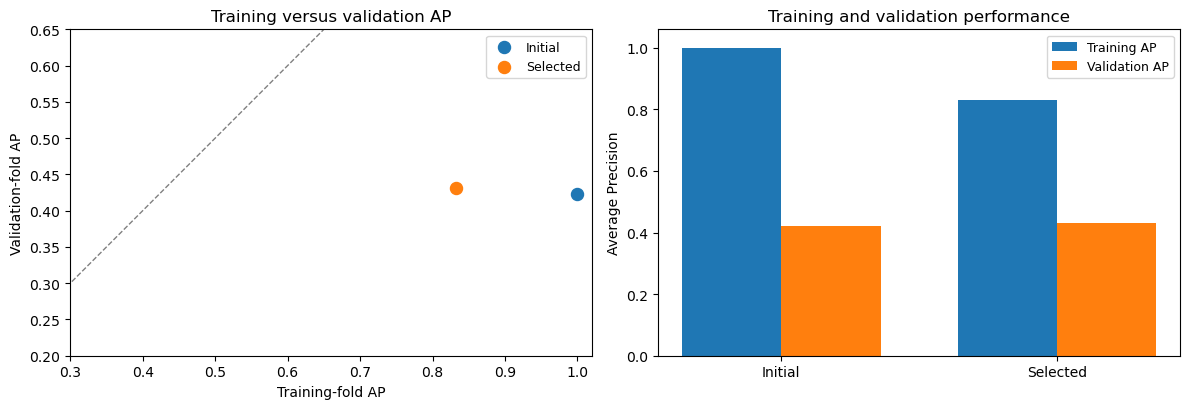

In [94]:
# Effect of tuning on the forest's overfitting and tree size.
s10_rf_diagnostic_comparison = pd.DataFrame(
    [
        {
            "Configuration": "Initial unrestricted (Section 9)",
            "Training_AP": float(
                rf9_cv_results.loc[
                    rf9_cv_results.Feature_set == "original", "Training_average_precision"
                ].mean()
            ),
            "Validation_AP": float(s10_rf_initial_by_fold.mean()),
            "AP_gap": float(
                rf9_cv_results.loc[
                    rf9_cv_results.Feature_set == "original", "AP_train_minus_valid"
                ].mean()
            ),
            "Mean_tree_depth": float(
                rf9_cv_results.loc[rf9_cv_results.Feature_set == "original", "Depth_mean"].mean()
            ),
            "Mean_leaves": float(
                rf9_cv_results.loc[rf9_cv_results.Feature_set == "original", "Leaves_mean"].mean()
            ),
        },
        {
            "Configuration": f"Selected ({s10_rf_best_name})",
            "Training_AP": float(s10_rf_selected_cv.Training_average_precision.mean()),
            "Validation_AP": float(s10_rf_selected_cv.average_precision.mean()),
            "AP_gap": float(s10_rf_selected_cv.AP_gap.mean()),
            "Mean_tree_depth": float(s10_rf_selected_cv.Depth_mean.mean()),
            "Mean_leaves": float(s10_rf_selected_cv.Leaves_mean.mean()),
        },
    ]
)
display(s10_rf_diagnostic_comparison.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for row in s10_rf_diagnostic_comparison.itertuples():
    axes[0].scatter(
        row.Training_AP,
        row.Validation_AP,
        s=75,
        label="Initial" if "Initial" in row.Configuration else "Selected",
    )
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[0].set(
    xlim=(0.3, 1.02),
    ylim=(0.2, 0.65),
    xlabel="Training-fold AP",
    ylabel="Validation-fold AP",
    title="Training versus validation AP",
)
axes[0].legend(fontsize=9)
labels = ["Initial", "Selected"]
x = np.arange(2)
axes[1].bar(x - 0.18, s10_rf_diagnostic_comparison.Training_AP, width=0.36, label="Training AP")
axes[1].bar(x + 0.18, s10_rf_diagnostic_comparison.Validation_AP, width=0.36, label="Validation AP")
axes[1].set(
    xticks=x,
    xticklabels=labels,
    ylim=(0, 1.06),
    ylabel="Average Precision",
    title="Training and validation performance",
)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

The minimum leaf size of 10 changes the forest considerably. Average tree depth falls from **58 to 33** levels and leaves per tree from about **7,350 to 1,160**. Training AP drops from **1.00 to 0.83** while validation AP rises from **0.423 to 0.432**, so the train–validation gap shrinks from **0.58 to 0.40**. The tuned forest overfits less and generalises slightly better, although a sizeable gap remains.

### 10.8 Final Settings and Training Cost

Unfitted pipelines with the selected settings (`C = 0.01` for Logistic Regression; 100 trees, no depth limit and `min_samples_leaf = 10` for Random Forest) are stored. The run times give a sense of the computational cost on this machine: a Logistic Regression fit takes about 1 second and a Random Forest fit about 2 seconds.

In [95]:
# Unfitted pipelines with the selected settings, reused in Sections 11-13.
s10_selected_lr_template = make_feature_set_pipeline("logistic", S10_FEATURE_SET)
s10_selected_lr_template.set_params(classifier__C=s10_lr_best_C)
s10_selected_rf_template = make_feature_set_pipeline("random_forest", S10_FEATURE_SET)
s10_selected_rf_template.set_params(
    **{f"classifier__{k}": v for k, v in s10_rf_best_params.items()}
)
s10_selected_templates = {
    "Logistic Regression": s10_selected_lr_template,
    "Random Forest": s10_selected_rf_template,
}
s10_fit_costs = pd.DataFrame(
    [
        {
            "Experiment": "Logistic Regression (4 settings × 5 folds)",
            "Fits": len(s10_lr_cv_results),
            "Total_fit_seconds": float(s10_lr_cv_results.Fit_seconds.sum()),
            "Mean_fit_seconds": float(s10_lr_cv_results.Fit_seconds.mean()),
        },
        {
            "Experiment": "Random Forest screening (7 × 3 folds)",
            "Fits": len(s10_rf_search_results),
            "Total_fit_seconds": float(s10_rf_search_results.Fit_seconds.sum()),
            "Mean_fit_seconds": float(s10_rf_search_results.Fit_seconds.mean()),
        },
        {
            "Experiment": "Selected Random Forest (5 established folds)",
            "Fits": len(s10_rf_selected_cv),
            "Total_fit_seconds": float(s10_rf_selected_cv.Fit_seconds.sum()),
            "Mean_fit_seconds": float(s10_rf_selected_cv.Fit_seconds.mean()),
        },
    ]
)
display(s10_fit_costs.round(2))
display(
    pd.DataFrame(
        [
            {
                "Algorithm": "Logistic Regression",
                "Selected settings": f"C={s10_lr_best_C:g}, L2-equivalent, lbfgs",
                "Feature_set": S10_FEATURE_SET,
                "Fitted": hasattr(s10_selected_lr_template.named_steps["classifier"], "classes_"),
            },
            {
                "Algorithm": "Random Forest",
                "Selected settings": str(s10_rf_best_params) + ", 100 trees",
                "Feature_set": S10_FEATURE_SET,
                "Fitted": hasattr(s10_selected_rf_template.named_steps["classifier"], "classes_"),
            },
        ]
    )
)

,Experiment,Fits,Total_fit_seconds,Mean_fit_seconds
0,Logistic Regression (4 settings × 5 folds),20,31.63,1.58
1,Random Forest screening (7 × 3 folds),21,45.68,2.18
2,Selected Random Forest (5 established folds),5,16.32,3.26


,Algorithm,Selected settings,Feature_set,Fitted
0,Logistic Regression,"C=0.01, L2-equivalent, lbfgs",original,False
1,Random Forest,"{'max_depth': None, 'min_samples_leaf': 10, 'm...",original,False


### 10.9 Findings

Tuning selected **`C = 0.01`** for Logistic Regression (CV AP 0.3794) and **`min_samples_leaf = 10`** with no depth limit for Random Forest (CV AP 0.4317). Both gains are modest. The more important effect is on the forest's overfitting: the train–validation gap falls from 0.58 to 0.40. Random Forest remains clearly ahead. However, tuning for ranking made the default 0.5 threshold even less useful, so the threshold has to be chosen deliberately, which is the subject of the next section.

## 11. Class Imbalance and the Decision Threshold

At the default threshold, the tuned forest identifies only about 2% of churners. There are two standard ways to address this with imbalanced data: **reweighting the classes** during training so that churners count more, or keeping the model and **lowering the decision threshold** that turns a churn probability into a "churn" prediction. This section tests both, separately and together, using development data only.

### 11.1 Design

The tuned models from Section 10 and the original features are used. Average Precision still measures ranking, while **F1**, the balance between precision and recall for churners, is used to choose a threshold. Each algorithm is tested **with and without class weighting**, and each fitted model is evaluated at **two thresholds**: the default 0.5 and a threshold chosen to maximise F1.

**Rule:** the threshold must not be chosen on the same customers it is evaluated on, otherwise the results would be optimistic. Within each outer training fold, 25% of the customers are therefore set aside as an **inner holdout**. The model is trained on the remaining 75%, and the threshold is chosen on the inner holdout. The model is then refitted on the whole outer training fold and evaluated on the outer validation fold at that threshold. Thresholds are searched from 0.05 to 0.65 in steps of 0.01.

In [96]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from time import perf_counter
import warnings

# Experiment design: two algorithms, with and without class weighting, at two thresholds.
S11_ALGORITHMS = ("Logistic Regression", "Random Forest")
S11_WEIGHTS = ("Unweighted", "Weighted")
S11_DECISIONS = ("Default 0.5", "Inner-selected F1")
S11_THRESHOLDS = np.round(np.arange(0.05, 0.651, 0.01), 2)
S11_INNER_SIZE = 0.25
S11_FOLDS = list(S10_5FOLD)
S11_METRICS = tuple(BASELINE_METRIC_KEYS)
S11_FEATURE_SET = "original"

assert len(S11_FOLDS) == N_CV_SPLITS == 5
assert S11_FEATURE_SET == S10_FEATURE_SET == "original"
assert len(PRIMARY_FEATURE_COLS) == 53 and len(X_dev_primary) == 40837
assert POSITIVE_CLASS == 1 and PRIMARY_SCORING == "average_precision"
assert np.all((S11_THRESHOLDS > 0) & (S11_THRESHOLDS < 1))

s11_setup = pd.DataFrame(
    [
        ("Logistic Regression", "Unweighted", None, f"C={s10_lr_best_C:g}"),
        ("Logistic Regression", "Weighted", "balanced", f"C={s10_lr_best_C:g}"),
        ("Random Forest", "Unweighted", None, str(s10_rf_best_params)),
        ("Random Forest", "Weighted", "balanced_subsample", str(s10_rf_best_params)),
    ],
    columns=["Algorithm", "Strategy", "class_weight", "Other settings"],
)
display(s11_setup)
print("Development churn prevalence:", f"{y_dev.mean():.2%}")
print(
    "Threshold search grid:",
    f"{S11_THRESHOLDS.min():.2f}–{S11_THRESHOLDS.max():.2f}",
    "| grid size:",
    len(S11_THRESHOLDS),
)

,Algorithm,Strategy,class_weight,Other settings
0,Logistic Regression,Unweighted,None,C=0.01
1,Logistic Regression,Weighted,balanced,C=0.01
2,Random Forest,Unweighted,None,"{'max_depth': None, 'min_samples_leaf': 10, 'm..."
3,Random Forest,Weighted,balanced_subsample,"{'max_depth': None, 'min_samples_leaf': 10, 'm..."


Development churn prevalence: 28.82%
Threshold search grid: 0.05–0.65 | grid size: 61


### 11.2 Class Weighting

`class_weight='balanced'` (Logistic Regression) and `class_weight='balanced_subsample'` (Random Forest) increase the weight of churners in the training loss in inverse proportion to their frequency. For the forest, the weights are recomputed within each tree's bootstrap sample. Resampling methods such as SMOTE are not used, because they would require generating synthetic customers from mixed numerical and categorical data. The weighted pipelines are otherwise identical to the unweighted ones.

In [97]:
def make_s11_pipeline(algorithm, weighting):
    """Tuned pipeline for one algorithm, with or without class weighting."""
    if algorithm == "Logistic Regression":
        model = clone(s10_selected_lr_template)
        model.set_params(classifier__class_weight=("balanced" if weighting == "Weighted" else None))
    elif algorithm == "Random Forest":
        model = clone(s10_selected_rf_template)
        model.set_params(
            classifier__class_weight=("balanced_subsample" if weighting == "Weighted" else None)
        )
    else:
        raise ValueError("Unknown algorithm")
    assert list(model.named_steps)[0] == "structural_cleaning"
    return model


s11_templates = {(a, w): make_s11_pipeline(a, w) for a in S11_ALGORITHMS for w in S11_WEIGHTS}
assert len(s11_templates) == 4
assert all(not hasattr(p.named_steps["classifier"], "classes_") for p in s11_templates.values())
print("Pipelines prepared: both algorithms, with and without class weighting.")

Pipelines prepared: both algorithms, with and without class weighting.


### 11.3 Inner Splits for Threshold Selection

For each outer fold, one stratified inner split is created: about 24,500 customers for fitting and about 8,170 for choosing the threshold. The inner customers never overlap the outer validation fold. If several thresholds give the same F1, the higher one is chosen, because it flags fewer customers.

In [98]:
def s11_select_threshold(y_true, probability_scores):
    """Return the threshold on the grid with the highest F1 (ties go to the higher threshold).

    A customer is flagged when their score is strictly above the threshold.
    """
    f1_by_threshold = np.asarray(
        [
            f1_score(
                y_true,
                (probability_scores > threshold).astype(int),
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
            for threshold in S11_THRESHOLDS
        ]
    )
    best = np.flatnonzero(np.isclose(f1_by_threshold, f1_by_threshold.max(), atol=1e-12))[-1]
    return float(S11_THRESHOLDS[best]), float(f1_by_threshold[best])


# One stratified inner split per outer training fold: 75% to fit, 25% to choose the threshold.
s11_inner_splits = {}
s11_inner_partition_table = []
for fold, (outer_train_pos, outer_valid_pos) in enumerate(S11_FOLDS, start=1):
    inner_train_pos, inner_valid_pos = train_test_split(
        outer_train_pos,
        test_size=S11_INNER_SIZE,
        stratify=y_dev.iloc[outer_train_pos],
        random_state=RANDOM_STATE + 1100 + fold,
    )
    assert set(inner_train_pos).isdisjoint(inner_valid_pos)
    assert set(inner_train_pos).isdisjoint(outer_valid_pos)
    assert set(inner_valid_pos).isdisjoint(outer_valid_pos)
    assert set(inner_train_pos).union(inner_valid_pos) == set(outer_train_pos)
    s11_inner_splits[fold] = (inner_train_pos, inner_valid_pos)
    s11_inner_partition_table.append(
        {
            "Fold": fold,
            "Inner_fit_n": len(inner_train_pos),
            "Inner_threshold_n": len(inner_valid_pos),
            "Outer_evaluation_n": len(outer_valid_pos),
            "Inner_churn_%": round(100 * y_dev.iloc[inner_valid_pos].mean(), 2),
        }
    )
display(pd.DataFrame(s11_inner_partition_table))
print("Inner holdout customers never overlap the outer validation fold.")

,Fold,Inner_fit_n,Inner_threshold_n,Outer_evaluation_n,Inner_churn_%
0,1,24501,8168,8168,28.82
1,2,24501,8168,8168,28.82
2,3,24502,8168,8167,28.82
3,4,24502,8168,8167,28.82
4,5,24502,8168,8167,28.82


Inner holdout customers never overlap the outer validation fold.


### 11.4 Running the Experiment

For each algorithm, weighting choice and outer fold, the code (1) fits a model on the inner training part and picks the F1-maximising threshold on the inner holdout, (2) refits the model on the full outer training fold, and (3) scores the outer validation fold at both thresholds. Both decision rules use the same predicted probabilities, so they differ only in where the line between "churn" and "no churn" is drawn.

In [99]:
s11_inner_rows = []
s11_fold_rows = []
s11_oof_predictions = {}
for algorithm in S11_ALGORITHMS:
    for weighting in S11_WEIGHTS:
        make_model = lambda a=algorithm, w=weighting: clone(s11_templates[(a, w)])

        # 1) Choose an F1 threshold inside each outer training fold, using its inner holdout only.
        thresholds = {}
        for fold, (inner_train_pos, inner_valid_pos) in s11_inner_splits.items():
            inner_model = make_model().fit(
                X_dev_primary.iloc[inner_train_pos], y_dev.iloc[inner_train_pos]
            )
            inner_scores = inner_model.predict_proba(X_dev_primary.iloc[inner_valid_pos])[:, 1]
            thresholds[fold], inner_f1 = s11_select_threshold(
                y_dev.iloc[inner_valid_pos], inner_scores
            )
            s11_inner_rows.append(
                {
                    "Algorithm": algorithm,
                    "Weighting": weighting,
                    "Fold": fold,
                    "Threshold": thresholds[fold],
                    "Inner_F1": inner_f1,
                }
            )

        # 2) Refit on each full outer training fold and score the outer validation fold.
        folds, oof = cross_validate_pipeline(make_model, X_dev_primary, y_dev, S11_FOLDS)
        assert folds["Warning_count"].eq(0).all(), (algorithm, weighting, "fitting warnings")

        # 3) Apply both decision rules to the same scores.
        for decision in S11_DECISIONS:
            decided = oof.copy()
            if decision == "Inner-selected F1":
                cutoffs = decided["CV_Fold"].map(thresholds)
                decided["Predicted_Churn"] = (
                    decided["Predicted_Churn_Probability"] > cutoffs
                ).astype(int)
            s11_oof_predictions[(algorithm, weighting, decision)] = decided
            for fold, part in decided.groupby("CV_Fold"):
                y_true = part["Actual_Churn"].to_numpy()
                predicted = part["Predicted_Churn"].to_numpy()
                scores = part["Predicted_Churn_Probability"].to_numpy()
                tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
                s11_fold_rows.append(
                    {
                        "Algorithm": algorithm,
                        "Weighting": weighting,
                        "Decision": decision,
                        "Fold": int(fold),
                        "Threshold": 0.5 if decision == "Default 0.5" else thresholds[fold],
                        "Flagged_n": int(predicted.sum()),
                        "Flagged_rate": float(predicted.mean()),
                        "TN": int(tn),
                        "FP": int(fp),
                        "FN": int(fn),
                        "TP": int(tp),
                        **evaluate_churn_predictions(y_true, predicted, scores),
                    }
                )
        print(f"{algorithm} ({weighting.lower()}): 5 outer folds completed")

s11_inner_results = pd.DataFrame(s11_inner_rows)
s11_fold_results = pd.DataFrame(s11_fold_rows)
assert len(s11_fold_results) == 40 and len(s11_inner_results) == 20
display(s11_inner_results.round(4))

Logistic Regression (unweighted): 5 outer folds completed
Logistic Regression (weighted): 5 outer folds completed
Random Forest (unweighted): 5 outer folds completed
Random Forest (weighted): 5 outer folds completed


,Algorithm,Weighting,Fold,Threshold,Inner_F1
0,Logistic Regression,Unweighted,1,0.23,0.4626
1,Logistic Regression,Unweighted,2,0.25,0.4722
2,Logistic Regression,Unweighted,3,0.25,0.4680
3,Logistic Regression,Unweighted,4,0.25,0.4736
4,Logistic Regression,Unweighted,5,0.25,0.4713
5,Logistic Regression,Weighted,1,0.42,0.4638
6,Logistic Regression,Weighted,2,0.45,0.4712
7,Logistic Regression,Weighted,3,0.46,0.4683
8,Logistic Regression,Weighted,4,0.45,0.4724
9,Logistic Regression,Weighted,5,0.45,0.4720


,Algorithm,Weighting,Fold,Threshold,Inner_F1
0,Logistic Regression,Unweighted,1,0.23,0.4626
1,Logistic Regression,Unweighted,2,0.25,0.4722
2,Logistic Regression,Unweighted,3,0.25,0.4680
3,Logistic Regression,Unweighted,4,0.25,0.4736
4,Logistic Regression,Unweighted,5,0.25,0.4713
5,Logistic Regression,Weighted,1,0.42,0.4638
6,Logistic Regression,Weighted,2,0.45,0.4712
7,Logistic Regression,Weighted,3,0.46,0.4683
8,Logistic Regression,Weighted,4,0.45,0.4724
9,Logistic Regression,Weighted,5,0.45,0.4720


### 11.5 Results: Ranking, Classification and Threshold Stability

Average Precision and ROC-AUC depend only on the scores, so they are identical for the two thresholds of the same model. Precision, recall, F1 and the share of customers flagged change with the threshold.

In [100]:
# Summarise each algorithm / weighting / threshold combination across the five folds.
s11_groups = ["Algorithm", "Weighting", "Decision"]
s11_summary = (
    s11_fold_results.groupby(s11_groups, sort=False)
    .agg(
        Folds=("Fold", "count"),
        AP_mean=("average_precision", "mean"),
        AP_sd=("average_precision", "std"),
        ROC_AUC_mean=("roc_auc", "mean"),
        Precision_mean=("precision", "mean"),
        Recall_mean=("recall", "mean"),
        F1_mean=("f1", "mean"),
        Balanced_accuracy_mean=("balanced_accuracy", "mean"),
        MCC_mean=("mcc", "mean"),
        Accuracy_mean=("accuracy", "mean"),
        Alert_rate_mean=("Flagged_rate", "mean"),
        FP_total=("FP", "sum"),
        TP_total=("TP", "sum"),
        FN_total=("FN", "sum"),
        TN_total=("TN", "sum"),
    )
    .reset_index()
)
s11_threshold_summary = (
    s11_inner_results.groupby(["Algorithm", "Weighting"], sort=False)
    .agg(
        Threshold_mean=("Threshold", "mean"),
        Threshold_sd=("Threshold", "std"),
        Threshold_min=("Threshold", "min"),
        Threshold_max=("Threshold", "max"),
        Inner_F1_mean=("Inner_F1", "mean"),
    )
    .reset_index()
)

display(
    s11_summary[
        [
            "Algorithm",
            "Weighting",
            "Decision",
            "AP_mean",
            "ROC_AUC_mean",
            "Precision_mean",
            "Recall_mean",
            "F1_mean",
            "Alert_rate_mean",
            "TP_total",
            "FP_total",
        ]
    ].round(5)
)
display(s11_threshold_summary.round(4))
for (algorithm, weighting), subset in s11_fold_results.groupby(["Algorithm", "Weighting"]):
    default = subset.loc[subset.Decision == "Default 0.5"].sort_values("Fold")
    adjusted = subset.loc[subset.Decision == "Inner-selected F1"].sort_values("Fold")
    assert np.allclose(default.average_precision, adjusted.average_precision, atol=1e-12)
    assert np.allclose(default.roc_auc, adjusted.roc_auc, atol=1e-12)
print("AP and ROC-AUC are identical at both thresholds, because they depend only on the scores.")

,Algorithm,Weighting,Decision,AP_mean,ROC_AUC_mean,Precision_mean,Recall_mean,F1_mean,Alert_rate_mean,TP_total,FP_total
0,Logistic Regression,Unweighted,Default 0.5,0.37935,0.61767,0.47053,0.02150,0.04107,0.01335,253,292
1,Logistic Regression,Unweighted,Inner-selected F1,0.37935,0.61767,0.33176,0.78851,0.46667,0.68548,9280,18713
2,Logistic Regression,Weighted,Default 0.5,0.37928,0.61802,0.36237,0.58170,0.44653,0.46269,6846,12049
3,Logistic Regression,Weighted,Inner-selected F1,0.37928,0.61802,0.33312,0.77848,0.46601,0.67441,9162,18379
4,Random Forest,Unweighted,Default 0.5,0.43165,0.66321,0.67642,0.02158,0.04182,0.00928,254,125
5,Random Forest,Unweighted,Inner-selected F1,0.43165,0.66321,0.36497,0.76821,0.49454,0.60702,9041,15748
6,Random Forest,Weighted,Default 0.5,0.42889,0.66188,0.42362,0.44710,0.43493,0.30421,5262,7161
7,Random Forest,Weighted,Inner-selected F1,0.42889,0.66188,0.35833,0.79293,0.49351,0.63783,9332,16715


,Algorithm,Weighting,Threshold_mean,Threshold_sd,Threshold_min,Threshold_max,Inner_F1_mean
0,Logistic Regression,Unweighted,0.246,0.0089,0.23,0.25,0.4695
1,Logistic Regression,Weighted,0.446,0.0152,0.42,0.46,0.4695
2,Random Forest,Unweighted,0.268,0.0084,0.26,0.28,0.4939
3,Random Forest,Weighted,0.414,0.0089,0.40,0.42,0.4954


AP and ROC-AUC are identical at both thresholds, because they depend only on the scores.


Class weighting does **not** improve ranking: AP changes by −0.0001 for Logistic Regression and −0.0028 for Random Forest. The thresholds chosen on the inner holdouts are very stable across folds: **0.23–0.25** for unweighted Logistic Regression and **0.26–0.28** for unweighted Random Forest, and higher (about 0.40–0.46) for the weighted models, whose scores are shifted upwards by the weighting. The unweighted thresholds agree with a known result: for well-calibrated scores, the F1-maximising threshold equals half of the best achievable F1 (Lipton, Elkan and Narayanaswamy, 2014). With inner-holdout F1 values of about 0.47–0.50, this predicts a threshold of about 0.24–0.25, close to the values selected.

### 11.6 Churn Detection Versus False Alarms

The confusion counts below are totals over the five outer folds. A lower threshold finds more churners but also flags many more customers who would have stayed.

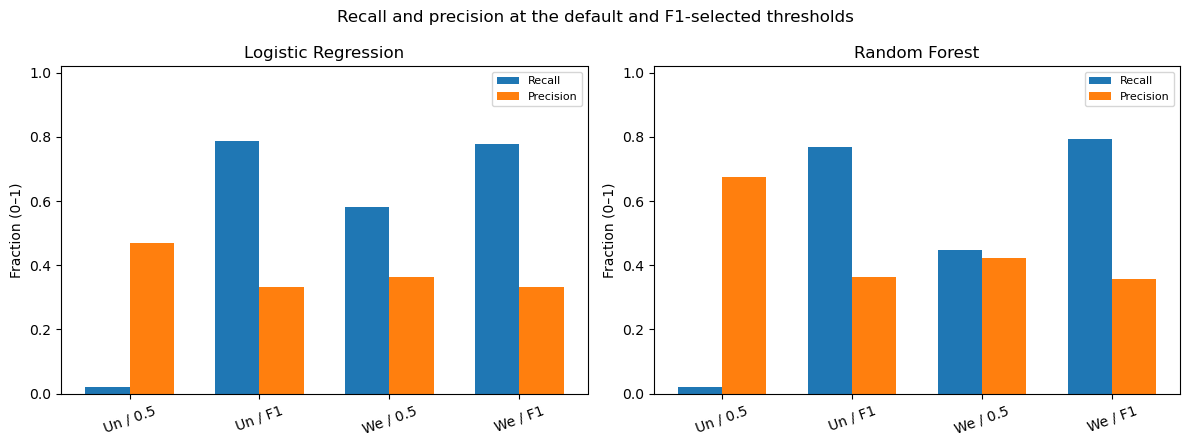

,Algorithm,Weighting,Decision,TN_total,FP_total,FN_total,TP_total,Alert_rate_mean
0,Logistic Regression,Unweighted,Default 0.5,28776,292,11516,253,0.0133
1,Logistic Regression,Unweighted,Inner-selected F1,10355,18713,2489,9280,0.6855
2,Logistic Regression,Weighted,Default 0.5,17019,12049,4923,6846,0.4627
3,Logistic Regression,Weighted,Inner-selected F1,10689,18379,2607,9162,0.6744
4,Random Forest,Unweighted,Default 0.5,28943,125,11515,254,0.0093
5,Random Forest,Unweighted,Inner-selected F1,13320,15748,2728,9041,0.6070
6,Random Forest,Weighted,Default 0.5,21907,7161,6507,5262,0.3042
7,Random Forest,Weighted,Inner-selected F1,12353,16715,2437,9332,0.6378


In [101]:
# Recall and precision at each decision rule, and total confusion counts.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, algorithm in zip(axes, S11_ALGORITHMS):
    piece = s11_summary[s11_summary.Algorithm == algorithm].copy()
    labels = [
        f'{r.Weighting[:2]} / {"0.5" if r.Decision=="Default 0.5" else "F1"}'
        for r in piece.itertuples()
    ]
    x = np.arange(len(piece))
    axis.bar(x - 0.17, piece.Recall_mean, width=0.34, label="Recall")
    axis.bar(x + 0.17, piece.Precision_mean, width=0.34, label="Precision")
    axis.set(title=algorithm, xticks=x, xticklabels=labels, ylabel="Fraction (0–1)", ylim=(0, 1.02))
    axis.tick_params(axis="x", rotation=20)
    axis.legend(loc="upper right", fontsize=8)
plt.suptitle("Recall and precision at the default and F1-selected thresholds")
plt.tight_layout()
plt.show()

s11_confusion_summary = s11_summary[
    [
        "Algorithm",
        "Weighting",
        "Decision",
        "TN_total",
        "FP_total",
        "FN_total",
        "TP_total",
        "Alert_rate_mean",
    ]
].copy()
display(s11_confusion_summary.round(4))

The threshold makes a dramatic difference. At 0.5 the unweighted forest finds just **254 of 11,769 churners** (recall 2.2%) and flags under 1% of customers. At its F1 threshold it finds **9,041 churners (recall 76.8%)** and its F1 rises from 0.04 to **0.49**, but it flags **60.7% of all customers**, including 15,748 who did not churn. Logistic Regression behaves similarly (recall 78.9%, 68.5% flagged). Class weighting at the 0.5 threshold sits in between (forest recall 44.7%, 30.4% flagged). The F1-optimal rule maximises a statistical score, not business value: contacting six out of ten customers would rarely be practical.

### 11.7 A Practical Alternative: Contacting a Fixed Share of Customers

A retention team usually has a fixed capacity. A more realistic rule is therefore to rank customers by predicted risk and contact the top 10% or 20%. Within each outer validation fold, the analysis computes precision (the share of contacted customers who churned), recall (the share of all churners reached) and **lift** (precision divided by the churn rate). These capacities are illustrative, since the dataset gives no budget or contact costs.

In [102]:
# Precision, recall and lift when contacting the top 10% or 20% of each validation fold by score.
S11_CAPACITIES = (0.10, 0.20)
s11_capacity_records = []
for algorithm in S11_ALGORITHMS:
    for weighting in S11_WEIGHTS:
        base = s11_oof_predictions[(algorithm, weighting, "Default 0.5")][
            "Predicted_Churn_Probability"
        ].to_numpy()
        for fold, (_, outer_valid_pos) in enumerate(S11_FOLDS, start=1):
            scores = base[outer_valid_pos]
            y_fold = y_dev.iloc[outer_valid_pos].to_numpy(dtype=int)
            assert np.isfinite(scores).all()
            order = np.argsort(
                -scores, kind="mergesort"
            )  # highest scores first; ties keep their original order
            for capacity in S11_CAPACITIES:
                contact_n = int(np.ceil(capacity * len(outer_valid_pos)))
                selected = order[:contact_n]
                tp = int(y_fold[selected].sum())
                fp = contact_n - tp
                s11_capacity_records.append(
                    {
                        "Algorithm": algorithm,
                        "Weighting": weighting,
                        "Fold": fold,
                        "Capacity": capacity,
                        "Flagged_n": contact_n,
                        "True_churners_flagged": tp,
                        "False_alarms": fp,
                        "Precision_at_capacity": tp / contact_n,
                        "Recall_at_capacity": tp / int(y_fold.sum()),
                        "Lift_over_prevalence": (tp / contact_n) / float(y_fold.mean()),
                    }
                )
s11_capacity_results = pd.DataFrame(s11_capacity_records)
s11_capacity_summary = (
    s11_capacity_results.groupby(["Algorithm", "Weighting", "Capacity"], sort=False)
    .agg(
        Precision_at_capacity=("Precision_at_capacity", "mean"),
        Recall_at_capacity=("Recall_at_capacity", "mean"),
        Lift=("Lift_over_prevalence", "mean"),
        Mean_flagged=("Flagged_n", "mean"),
        Mean_false_alarms=("False_alarms", "mean"),
        Mean_churners_captured=("True_churners_flagged", "mean"),
    )
    .reset_index()
)
display(s11_capacity_summary.round(4))

,Algorithm,Weighting,Capacity,Precision_at_capacity,Recall_at_capacity,Lift,Mean_flagged,Mean_false_alarms,Mean_churners_captured
0,Logistic Regression,Unweighted,0.1,0.4323,0.1501,1.5001,817.0,463.8,353.2
1,Logistic Regression,Unweighted,0.2,0.4104,0.2849,1.4240,1634.0,963.4,670.6
2,Logistic Regression,Weighted,0.1,0.4340,0.1506,1.5060,817.0,462.4,354.6
3,Logistic Regression,Weighted,0.2,0.4125,0.2863,1.4313,1634.0,960.0,674.0
4,Random Forest,Unweighted,0.1,0.5016,0.1741,1.7405,817.0,407.2,409.8
5,Random Forest,Unweighted,0.2,0.4543,0.3154,1.5765,1634.0,891.6,742.4
6,Random Forest,Weighted,0.1,0.4977,0.1727,1.7269,817.0,410.4,406.6
7,Random Forest,Weighted,0.2,0.4548,0.3157,1.5782,1634.0,890.8,743.2


Ranking gives a much more focused list. Contacting the **top 10%** of unweighted Random Forest scores reaches churners at **50.2% precision**, a **lift of 1.74** over the 28.8% base rate, and finds 17.4% of all churners. The top 20% gives 45.4% precision and 31.5% recall. Logistic Regression reaches 43.2% precision in its top 10% (lift 1.50). Weighting makes almost no difference here, as expected, since it does not improve the ranking.

### 11.8 Separating the Effects of Weighting and Threshold

The last table isolates each change: weighting alone at 0.5, threshold alone without weighting, and both together.

In [103]:
# Separate effects of class weighting and threshold choice, relative to the unweighted 0.5 rule.
s11_comparison = s11_summary[
    [
        "Algorithm",
        "Weighting",
        "Decision",
        "AP_mean",
        "AP_sd",
        "ROC_AUC_mean",
        "Precision_mean",
        "Recall_mean",
        "F1_mean",
        "Alert_rate_mean",
        "TP_total",
        "FP_total",
        "FN_total",
    ]
].copy()
s11_baseline_reference = pd.DataFrame(
    [
        {
            "Algorithm": "Dummy baseline",
            "AP_mean": float(baseline_cv_results.average_precision.mean()),
            "Recall_mean": float(baseline_cv_results.recall.mean()),
        },
        {
            "Algorithm": "Initial Logistic Regression",
            "AP_mean": float(
                lr8_cv_results[(lr8_cv_results.Feature_set == "original")].average_precision.mean()
            ),
            "Recall_mean": float(
                lr8_cv_results[(lr8_cv_results.Feature_set == "original")].recall.mean()
            ),
        },
        {
            "Algorithm": "Initial Random Forest",
            "AP_mean": float(
                rf9_cv_results[(rf9_cv_results.Feature_set == "original")].average_precision.mean()
            ),
            "Recall_mean": float(
                rf9_cv_results[(rf9_cv_results.Feature_set == "original")].recall.mean()
            ),
        },
    ]
)
display(s11_baseline_reference.round(5))
display(s11_comparison.round(5))

s11_effect_records = []
for algorithm in S11_ALGORITHMS:
    subset = s11_summary[s11_summary.Algorithm == algorithm].set_index(["Weighting", "Decision"])
    original = subset.loc[("Unweighted", "Default 0.5")]
    weighted = subset.loc[("Weighted", "Default 0.5")]
    inner = subset.loc[("Unweighted", "Inner-selected F1")]
    combined = subset.loc[("Weighted", "Inner-selected F1")]
    s11_effect_records.append(
        {
            "Algorithm": algorithm,
            "Weighting_AP_change": float(weighted.AP_mean - original.AP_mean),
            "Weighting_F1_change_at_0.5": float(weighted.F1_mean - original.F1_mean),
            "Threshold_F1_change_unweighted": float(inner.F1_mean - original.F1_mean),
            "Threshold_F1_change_weighted": float(combined.F1_mean - weighted.F1_mean),
            "Combined_F1_change_vs_original": float(combined.F1_mean - original.F1_mean),
            "Combined_alert_rate": float(combined.Alert_rate_mean),
        }
    )
s11_effects = pd.DataFrame(s11_effect_records)
display(s11_effects.round(5))

,Algorithm,AP_mean,Recall_mean
0,Dummy baseline,0.28819,0.00000
1,Initial Logistic Regression,0.37477,0.04597
2,Initial Random Forest,0.42278,0.04928


,Algorithm,Weighting,Decision,AP_mean,AP_sd,ROC_AUC_mean,Precision_mean,Recall_mean,F1_mean,Alert_rate_mean,TP_total,FP_total,FN_total
0,Logistic Regression,Unweighted,Default 0.5,0.37935,0.01480,0.61767,0.47053,0.02150,0.04107,0.01335,253,292,11516
1,Logistic Regression,Unweighted,Inner-selected F1,0.37935,0.01480,0.61767,0.33176,0.78851,0.46667,0.68548,9280,18713,2489
2,Logistic Regression,Weighted,Default 0.5,0.37928,0.01482,0.61802,0.36237,0.58170,0.44653,0.46269,6846,12049,4923
3,Logistic Regression,Weighted,Inner-selected F1,0.37928,0.01482,0.61802,0.33312,0.77848,0.46601,0.67441,9162,18379,2607
4,Random Forest,Unweighted,Default 0.5,0.43165,0.01199,0.66321,0.67642,0.02158,0.04182,0.00928,254,125,11515
5,Random Forest,Unweighted,Inner-selected F1,0.43165,0.01199,0.66321,0.36497,0.76821,0.49454,0.60702,9041,15748,2728
6,Random Forest,Weighted,Default 0.5,0.42889,0.01052,0.66188,0.42362,0.44710,0.43493,0.30421,5262,7161,6507
7,Random Forest,Weighted,Inner-selected F1,0.42889,0.01052,0.66188,0.35833,0.79293,0.49351,0.63783,9332,16715,2437


,Algorithm,Weighting_AP_change,Weighting_F1_change_at_0.5,Threshold_F1_change_unweighted,Threshold_F1_change_weighted,Combined_F1_change_vs_original,Combined_alert_rate
0,Logistic Regression,-0.00007,0.40547,0.42560,0.01948,0.42494,0.67441
1,Random Forest,-0.00276,0.39312,0.45273,0.05858,0.45170,0.63783


Weighting and threshold adjustment are two routes to the same effect. Either one raises F1 at the default threshold dramatically (for the forest: +0.39 from weighting, +0.45 from the threshold), but combining them adds little on top of choosing the threshold. The unweighted forest with its inner-selected threshold reaches the highest mean F1 (**0.495**), essentially tied with the weighted forest (0.494). Since weighting slightly lowers ranking quality and adds nothing to F1 once the threshold is chosen, the **unweighted** models are kept.

### 11.9 Findings

The poor recall at 0.5 was caused by the threshold, not by the models' ranking ability. Choosing the threshold on inner holdouts raises recall to about 77% and F1 to about 0.49, but at the cost of flagging around 60–69% of customers. Class weighting does not improve ranking and is not needed once the threshold is chosen. For the final evaluation, the **unweighted** tuned models are therefore kept, the decision threshold is set to the **median of the five inner-fold thresholds**, and fixed-capacity results (top 10% and 20%) are reported alongside the threshold-based results as the more practical decision rule.

## 12. Feature Validity and Robustness

Good cross-validation scores do not guarantee that every predictor would be available when a real prediction is made. This section returns to the two groups of features whose timing is uncertain, the retention fields and the percentage-change fields, and measures how much the results depend on them. The decision about the final feature set is made here, before the test set is used.

### 12.1 Evidence From the Data Documentation

The data files are the Cell2Cell training and holdout files from the Kaggle dataset [*telecom churn (cell2cell)*](https://www.kaggle.com/datasets/jpacse/datasets-for-churn-telecom) (Section 2.1). Variable meanings come from [*Cell2Cell: The Churn Game – Database Documentation*](https://github.com/leylatulu/Telecom-Churn-Analysis/blob/main/Cell2Cell-Data-Documentation.pdf) (Teradata Center for Customer Relationship Management, Duke University). The documentation uses short variable names that map onto the renamed columns in the Kaggle files (for example `changem` → `PercChangeMinutes`, `retcalls` → `RetentionCalls`, `income` → `IncomeGroup`, `setprc` → `HandsetPrice`).

The documentation defines `churn` as "Churn between 31-60 days after obs_date" and describes the retention fields as *previous* contacts ("Number of calls previously made to retention team"; "Number of previous retention offers accepted"). This suggests they were recorded before the observation date, but it does not give actual timestamps. Variables described as "Mean …" are averages over the four months before the observation date. The percentage-change fields are described only as "% Change in minutes of use" and "% Change in revenues", with no time window.

Three feature sets are tested with the tuned, unweighted models on the same five folds:

| Configuration | Predictors | Purpose |
|---|---|---|
| Conservative | 51: main set without the two percentage-change fields | How much do the results depend on the uncertain change fields? |
| Main | 53: as used so far | Reference |
| Retention-inclusive | 56: main set plus the three retention fields | How much would the excluded fields add? |

In [104]:
# The three feature sets compared in this section.
S12_PRIMARY = tuple(PRIMARY_FEATURE_COLS)
S12_CHANGE_FIELDS = ("PercChangeMinutes", "PercChangeRevenues")
S12_RETENTION_FIELDS = tuple(RETENTION_EXCLUSIONS)
S12_CONSERVATIVE = tuple(c for c in S12_PRIMARY if c not in S12_CHANGE_FIELDS)
S12_DIAGNOSTIC = tuple(X_dev.columns)
S12_CONFIGS = {
    "Conservative 51": S12_CONSERVATIVE,
    "Primary 53": S12_PRIMARY,
    "Retention-inclusive 56": S12_DIAGNOSTIC,
}
S12_ALGORITHMS = ("Logistic Regression", "Random Forest")
S12_FOLDS = list(S11_FOLDS)
assert set(S12_CHANGE_FIELDS).issubset(S12_PRIMARY)
assert set(S12_RETENTION_FIELDS).isdisjoint(S12_PRIMARY)
assert set(S12_RETENTION_FIELDS).issubset(S12_DIAGNOSTIC)
assert [len(cols) for cols in S12_CONFIGS.values()] == [51, 53, 56]
assert len(S12_FOLDS) == 5 and len(X_dev_primary) == len(y_dev) == 40837
assert POSITIVE_CLASS == 1 and PRIMARY_SCORING == "average_precision"
s12_design = pd.DataFrame(
    [
        {
            "Configuration": name,
            "Raw_predictors": len(cols),
            "Retention_predictors": sum(c in cols for c in S12_RETENTION_FIELDS),
            "Change_predictors": sum(c in cols for c in S12_CHANGE_FIELDS),
            "Interpretation": (
                "Without the percentage-change fields"
                if name == "Conservative 51"
                else ("Main feature set" if name == "Primary 53" else "Sensitivity check only")
            ),
        }
        for name, cols in S12_CONFIGS.items()
    ]
)
display(s12_design)
print(
    "Tuned settings: Logistic Regression C =",
    s10_lr_best_C,
    "| Random Forest =",
    s10_rf_best_params,
    "| folds =",
    len(S12_FOLDS),
)

,Configuration,Raw_predictors,Retention_predictors,Change_predictors,Interpretation
0,Conservative 51,51,0,0,Without the percentage-change fields
1,Primary 53,53,0,2,Main feature set
2,Retention-inclusive 56,56,3,2,Sensitivity check only


Tuned settings: Logistic Regression C = 0.01 | Random Forest = {'max_depth': None, 'min_samples_leaf': 10, 'min_samples_split': 2} | folds = 5


### 12.2 Timing Review of the Uncertain Features

The table summarises what the documentation says about each feature and the policy applied to it.

In [105]:
# What the documentation says about each uncertain feature, and the policy applied.
s12_feature_audit = pd.DataFrame(
    [
        (
            "RetentionCalls",
            "Previously made retention calls (documentation)",
            "Historical wording; exact scoring-time availability not established",
            "Excluded from main model; tested in Section 12",
        ),
        (
            "RetentionOffersAccepted",
            "Previously accepted retention offers (documentation)",
            "Historical wording; exact offer dates not established",
            "Excluded from main model; tested in Section 12",
        ),
        (
            "MadeCallToRetentionTeam",
            "Customer has called the retention team (documentation)",
            "Status/history but no precise timestamp in the variable description",
            "Excluded from main model; tested in Section 12",
        ),
        (
            "PercChangeMinutes",
            "Percentage change in minutes of use (documentation)",
            "Window of percentage change not specified",
            "Included; removed in the 51-feature check",
        ),
        (
            "PercChangeRevenues",
            "Percentage change in revenues (documentation)",
            "Window of percentage change not specified",
            "Included; removed in the 51-feature check",
        ),
    ],
    columns=["Feature", "Documented meaning", "Temporal evidence / limitation", "Feature policy"],
)
display(s12_feature_audit)
assert set(s12_feature_audit.Feature) == set(S12_RETENTION_FIELDS + S12_CHANGE_FIELDS)
assert not set(S12_RETENTION_FIELDS).intersection(S12_PRIMARY)

,Feature,Documented meaning,Temporal evidence / limitation,Feature policy
0,RetentionCalls,Previously made retention calls (documentation),Historical wording; exact scoring-time availab...,Excluded from main model; tested in Section 12
1,RetentionOffersAccepted,Previously accepted retention offers (document...,Historical wording; exact offer dates not esta...,Excluded from main model; tested in Section 12
2,MadeCallToRetentionTeam,Customer has called the retention team (docume...,Status/history but no precise timestamp in the...,Excluded from main model; tested in Section 12
3,PercChangeMinutes,Percentage change in minutes of use (documenta...,Window of percentage change not specified,Included; removed in the 51-feature check
4,PercChangeRevenues,Percentage change in revenues (documentation),Window of percentage change not specified,Included; removed in the 51-feature check


### 12.3 Special Codes Confirmed by the Documentation

The documentation also confirms two coding conventions: income code 0 means missing ("Income (0=>missing)"), and handset price was originally coded 0 when missing ("Handset price (0=>missing)"). In the Kaggle CSV files, unknown handset prices appear as `Unknown`, which the cleaner already converts to missing. `IncomeGroup = 0` is kept as its own category, so the model can learn whether missing income matters, but it should be read as "income not recorded" rather than as a real income level. The counts below use development data.

In [106]:
# Coding conventions confirmed by the documentation (counts from development data).
s12_semantics = pd.DataFrame(
    [
        {
            "Variable": "IncomeGroup",
            "Recorded encoding": "0 is a missing-income code",
            "Development_count": int(X_dev_primary["IncomeGroup"].eq(0).sum()),
            "Current pipeline action": "Retained as distinct nominal code",
        },
        {
            "Variable": "HandsetPrice",
            "Recorded encoding": "Explicit Unknown token in this CSV",
            "Development_count": int(X_dev_primary["HandsetPrice"].eq("Unknown").sum()),
            "Current pipeline action": "Unknown -> missing; fold-fitted numeric imputation",
        },
        {
            "Variable": "CurrentEquipmentDays",
            "Recorded encoding": "Negative recorded duration (invalid)",
            "Development_count": int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()),
            "Current pipeline action": "Negative -> missing; fold-fitted imputation",
        },
    ]
)
display(s12_semantics)
print(
    "Development customers with retention activity:",
    {
        c: (
            int((X_dev[c] != 0).sum())
            if pd.api.types.is_numeric_dtype(X_dev[c])
            else int(X_dev[c].eq("Yes").sum())
        )
        for c in S12_RETENTION_FIELDS
    },
)
assert (s12_semantics.Development_count >= 0).all()

,Variable,Recorded encoding,Development_count,Current pipeline action
0,IncomeGroup,0 is a missing-income code,10280,Retained as distinct nominal code
1,HandsetPrice,Explicit Unknown token in this CSV,23214,Unknown -> missing; fold-fitted numeric imputa...
2,CurrentEquipmentDays,Negative recorded duration (invalid),55,Negative -> missing; fold-fitted imputation


Development customers with retention activity: {'RetentionCalls': 1402, 'RetentionOffersAccepted': 711, 'MadeCallToRetentionTeam': 1402}


### 12.4 Building the Alternative Pipelines

The preprocessing pipeline lists its numerical and categorical columns explicitly, so removing or adding columns requires updating those lists. The tuned pipelines are therefore copied and only their column lists are changed: the two retention counts join the numerical branch and the retention-team flag joins the categorical branch. All settings stay the same, and the original pipelines are left unchanged.

In [107]:
from sklearn.base import clone
from time import perf_counter
import warnings


def make_s12_pipeline(algorithm, configuration):
    """Copy a tuned pipeline and change only the columns sent to each preprocessing branch."""
    if algorithm not in S12_ALGORITHMS or configuration not in S12_CONFIGS:
        raise ValueError("Unrecognised model or sensitivity configuration")
    model = clone(s10_selected_templates[algorithm])
    columns = set(S12_CONFIGS[configuration])
    numeric = list(c for c in NUMERIC_FEATURES if c in columns)
    categorical = list(c for c in CATEGORICAL_FEATURES if c in columns)
    service = list(SERVICE_AREA_FEATURES)
    if configuration == "Retention-inclusive 56":
        numeric += ["RetentionCalls", "RetentionOffersAccepted"]
        categorical += ["MadeCallToRetentionTeam"]
    assert len(numeric) + len(categorical) + len(service) == len(columns)
    assert set(numeric).isdisjoint(categorical)
    assert set(numeric + categorical + service) == columns
    pre = model.named_steps["preprocessor"]
    revised = []
    for name, transformer, _ in pre.transformers:
        group = (
            numeric
            if name in ("numeric", "missing_flags")
            else (
                categorical
                if name == "categorical"
                else service if name == "service_area" else None
            )
        )
        if group is None:
            raise AssertionError("Unexpected preprocessor transformer: " + name)
        revised.append((name, transformer, group))
    pre.transformers = revised
    model.set_params(preprocessor=pre)
    assert not hasattr(model.named_steps["classifier"], "classes_")
    return model


s12_templates = {
    (alg, cfg): make_s12_pipeline(alg, cfg) for alg in S12_ALGORITHMS for cfg in S12_CONFIGS
}
assert len(s12_templates) == 6
assert all(
    not hasattr(model.named_steps["classifier"], "classes_") for model in s12_templates.values()
)
print("Pipelines prepared for 2 algorithms x 3 feature sets.")
display(
    pd.DataFrame(
        [
            {
                "Algorithm": alg,
                "Configuration": cfg,
                "Numeric_columns": len(
                    next(
                        cols
                        for name, _, cols in model.named_steps["preprocessor"].transformers
                        if name == "numeric"
                    )
                ),
                "Categorical_columns": len(
                    next(
                        cols
                        for name, _, cols in model.named_steps["preprocessor"].transformers
                        if name == "categorical"
                    )
                ),
                "Predictor_count": len(S12_CONFIGS[cfg]),
            }
            for (alg, cfg), model in s12_templates.items()
        ]
    )
)

Pipelines prepared for 2 algorithms x 3 feature sets.


,Algorithm,Configuration,Numeric_columns,Categorical_columns,Predictor_count
0,Logistic Regression,Conservative 51,30,20,51
1,Logistic Regression,Primary 53,32,20,53
2,Logistic Regression,Retention-inclusive 56,34,21,56
3,Random Forest,Conservative 51,30,20,51
4,Random Forest,Primary 53,32,20,53
5,Random Forest,Retention-inclusive 56,34,21,56


### 12.5 Cross-Validation of the Three Feature Sets

The main (53-feature) results are taken from the unweighted runs, which use the same models and folds. The two alternative sets require 20 new fits (two algorithms × two feature sets × five folds).

In [108]:
# Cross-validate the 51- and 56-feature sets; the 53-feature results are reused from Section 11.
s12_records = []
s12_oof = {}
for algorithm in S12_ALGORITHMS:
    # The 53-feature reference reuses Section 11's unweighted, default-threshold run (same model, same folds).
    reference = s11_oof_predictions[(algorithm, "Unweighted", "Default 0.5")]
    reference_folds = s11_fold_results[
        (s11_fold_results.Algorithm == algorithm)
        & (s11_fold_results.Weighting == "Unweighted")
        & (s11_fold_results.Decision == "Default 0.5")
    ]
    for row in reference_folds.itertuples():
        s12_records.append(
            {
                "Algorithm": algorithm,
                "Configuration": "Primary 53",
                "Fold": int(row.Fold),
                "Validation_AP": float(row.average_precision),
                "Validation_ROC_AUC": float(row.roc_auc),
                "Fit_seconds": np.nan,
                "Fit_source": "Section 11 matched reference",
                "Encoded_features": np.nan,
            }
        )
    s12_oof[(algorithm, "Primary 53")] = reference["Predicted_Churn_Probability"].to_numpy().copy()

    for configuration in ("Conservative 51", "Retention-inclusive 56"):
        inputs = X_dev.loc[:, list(S12_CONFIGS[configuration])]
        folds, oof = cross_validate_pipeline(
            lambda a=algorithm, c=configuration: clone(s12_templates[(a, c)]),
            inputs,
            y_dev,
            S12_FOLDS,
            fold_details=encoded_feature_counts,
        )
        assert folds["Warning_count"].eq(0).all(), (algorithm, configuration, "fitting warnings")
        for row in folds.itertuples():
            s12_records.append(
                {
                    "Algorithm": algorithm,
                    "Configuration": configuration,
                    "Fold": int(row.Fold),
                    "Validation_AP": float(row.average_precision),
                    "Validation_ROC_AUC": float(row.roc_auc),
                    "Fit_seconds": float(row.Fit_seconds),
                    "Fit_source": "New fold fit",
                    "Encoded_features": int(row.Encoded_features),
                }
            )
        s12_oof[(algorithm, configuration)] = oof["Predicted_Churn_Probability"].to_numpy()
        print(algorithm, "/", configuration, "completed all five folds")

s12_cv = pd.DataFrame(s12_records)
assert len(s12_cv) == 30 and len(s12_oof) == 6
print("New model fits:", int(s12_cv.Fit_source.eq("New fold fit").sum()))
display(
    s12_cv.groupby(["Algorithm", "Configuration"], sort=False)
    .agg(
        Folds=("Fold", "count"),
        AP_mean=("Validation_AP", "mean"),
        ROC_AUC_mean=("Validation_ROC_AUC", "mean"),
        Fit_seconds=("Fit_seconds", "sum"),
    )
    .round(5)
)

Logistic Regression / Conservative 51 completed all five folds
Logistic Regression / Retention-inclusive 56 completed all five folds
Random Forest / Conservative 51 completed all five folds
Random Forest / Retention-inclusive 56 completed all five folds
New model fits: 20


Folds  AP_mean  ROC_AUC_mean  \
Algorithm           Configuration                                          
Logistic Regression Primary 53                  5  0.37935       0.61767   
                    Conservative 51             5  0.37125       0.61092   
                    Retention-inclusive 56      5  0.38685       0.62249   
Random Forest       Primary 53                  5  0.43165       0.66321   
                    Conservative 51             5  0.42107       0.65393   
                    Retention-inclusive 56      5  0.43588       0.66517   

                                            Fit_seconds  
Algorithm           Configuration                        
Logistic Regression Primary 53                  0.00000  
                    Conservative 51             3.66645  
                    Retention-inclusive 56      4.56056  
Random Forest       Primary 53                  0.00000  
                    Conservative 51            12.93195  
                    Retention-inclusive 56     12.86751

Folds  AP_mean  ROC_AUC_mean  \
Algorithm           Configuration                                          
Logistic Regression Primary 53                  5  0.37935       0.61767   
                    Conservative 51             5  0.37125       0.61092   
                    Retention-inclusive 56      5  0.38685       0.62249   
Random Forest       Primary 53                  5  0.43165       0.66321   
                    Conservative 51             5  0.42107       0.65393   
                    Retention-inclusive 56      5  0.43588       0.66517   

                                            Fit_seconds  
Algorithm           Configuration                        
Logistic Regression Primary 53                  0.00000  
                    Conservative 51             2.86340  
                    Retention-inclusive 56      3.22809  
Random Forest       Primary 53                  0.00000  
                    Conservative 51             8.37945  
                    Retention-inclusive 56      9.20978

### 12.6 Comparison With the Main Feature Set

Because all three feature sets use the same folds, each alternative can be compared fold by fold against the main set.

,Algorithm,Configuration,Folds,AP_mean,AP_sd,ROC_AUC_mean,ROC_AUC_sd
0,Logistic Regression,Primary 53,5,0.37935,0.01480,0.61767,0.01224
1,Logistic Regression,Conservative 51,5,0.37125,0.01262,0.61092,0.01146
2,Logistic Regression,Retention-inclusive 56,5,0.38685,0.01642,0.62249,0.01217
3,Random Forest,Primary 53,5,0.43165,0.01199,0.66321,0.01080
4,Random Forest,Conservative 51,5,0.42107,0.00972,0.65393,0.00926
5,Random Forest,Retention-inclusive 56,5,0.43588,0.01378,0.66517,0.01027


,Algorithm,Configuration,Mean_AP_change,SD_AP_change,Min_fold_AP_change,Max_fold_AP_change,Mean_ROC_AUC_change
0,Logistic Regression,Primary 53,0.00000,0.00000,0.00000,0.00000,0.00000
1,Logistic Regression,Conservative 51,-0.00810,0.00231,-0.01110,-0.00544,-0.00674
2,Logistic Regression,Retention-inclusive 56,0.00750,0.00405,0.00341,0.01196,0.00482
3,Random Forest,Primary 53,0.00000,0.00000,0.00000,0.00000,0.00000
4,Random Forest,Conservative 51,-0.01058,0.00501,-0.01592,-0.00242,-0.00929
5,Random Forest,Retention-inclusive 56,0.00423,0.00705,-0.00105,0.01616,0.00196


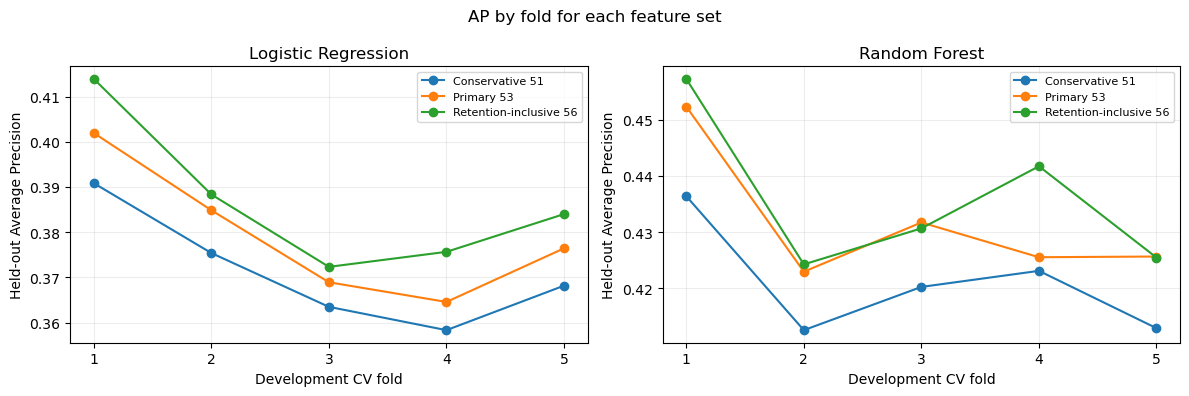

In [109]:
# Compare each feature set with the main 53-feature set, fold by fold.
s12_summary = (
    s12_cv.groupby(["Algorithm", "Configuration"], sort=False)
    .agg(
        Folds=("Fold", "count"),
        AP_mean=("Validation_AP", "mean"),
        AP_sd=("Validation_AP", "std"),
        ROC_AUC_mean=("Validation_ROC_AUC", "mean"),
        ROC_AUC_sd=("Validation_ROC_AUC", "std"),
        Mean_encoded_features=("Encoded_features", "mean"),
    )
    .reset_index()
)
ref_ap = s12_cv.loc[
    s12_cv.Configuration == "Primary 53",
    ["Algorithm", "Fold", "Validation_AP", "Validation_ROC_AUC"],
].rename(columns={"Validation_AP": "Reference_AP", "Validation_ROC_AUC": "Reference_ROC_AUC"})
s12_matched = s12_cv.merge(ref_ap, on=["Algorithm", "Fold"], validate="many_to_one")
s12_matched["Delta_AP"] = s12_matched.Validation_AP - s12_matched.Reference_AP
s12_matched["Delta_ROC_AUC"] = s12_matched.Validation_ROC_AUC - s12_matched.Reference_ROC_AUC
s12_effects = (
    s12_matched.groupby(["Algorithm", "Configuration"], sort=False)
    .agg(
        Mean_AP_change=("Delta_AP", "mean"),
        SD_AP_change=("Delta_AP", "std"),
        Min_fold_AP_change=("Delta_AP", "min"),
        Max_fold_AP_change=("Delta_AP", "max"),
        Mean_ROC_AUC_change=("Delta_ROC_AUC", "mean"),
    )
    .reset_index()
)
display(
    s12_summary[
        ["Algorithm", "Configuration", "Folds", "AP_mean", "AP_sd", "ROC_AUC_mean", "ROC_AUC_sd"]
    ].round(5)
)
display(s12_effects.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, alg in zip(axes, S12_ALGORITHMS):
    block = s12_cv[s12_cv.Algorithm == alg]
    for cfg in S12_CONFIGS:
        f = block[block.Configuration == cfg].sort_values("Fold")
        ax.plot(f.Fold, f.Validation_AP, marker="o", label=cfg)
    ax.set(title=alg, xlabel="Development CV fold", ylabel="Held-out Average Precision")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.grid(alpha=0.22)
    ax.legend(fontsize=8)
fig.suptitle("AP by fold for each feature set")
fig.tight_layout()
plt.show()

Removing the two percentage-change fields lowers AP on **every fold** for both algorithms: by **0.0081** for Logistic Regression (0.3794 → 0.3713) and **0.0106** for Random Forest (0.4317 → 0.4211). The change fields therefore carry real predictive information, so their undocumented time window matters.

Adding the three retention fields raises AP by **0.0075** for Logistic Regression (0.3794 → 0.3869, higher on all five folds) and **0.0042** for Random Forest (0.4317 → 0.4359; fold-level changes range from −0.001 to +0.016). The gain is real but modest. It would not justify including fields whose timing cannot be verified, especially as part of the gain could come from contacts made once a customer had already decided to leave.

### 12.7 Effect on Which Customers Are Ranked Highest

Similar average performance can hide changes in *which* customers a model ranks as high risk. For each alternative feature set, the out-of-fold scores are compared with those of the main set using the Spearman rank correlation, the average absolute score change, and the overlap between the two top-10% lists.

In [110]:
# How much each feature set changes which customers are ranked highest.
s12_score_records = []
for algorithm in S12_ALGORITHMS:
    base = s12_oof[(algorithm, "Primary 53")]
    top_n = int(np.ceil(0.10 * len(base)))
    base_top = set(np.argsort(-base, kind="stable")[:top_n])
    for cfg in S12_CONFIGS:
        prob = s12_oof[(algorithm, cfg)]
        top = set(np.argsort(-prob, kind="stable")[:top_n])
        s12_score_records.append(
            {
                "Algorithm": algorithm,
                "Configuration": cfg,
                "Spearman_rank_corr": float(
                    pd.Series(base).corr(pd.Series(prob), method="spearman")
                ),
                "Mean_absolute_score_shift": float(np.mean(np.abs(prob - base))),
                "Top10_overlap_of_selected": len(base_top & top) / top_n,
            }
        )
s12_score_stability = pd.DataFrame(s12_score_records)
display(s12_score_stability.round(5))

,Algorithm,Configuration,Spearman_rank_corr,Mean_absolute_score_shift,Top10_overlap_of_selected
0,Logistic Regression,Conservative 51,0.95924,0.01370,0.86680
1,Logistic Regression,Primary 53,1.00000,0.00000,1.00000
2,Logistic Regression,Retention-inclusive 56,0.97086,0.00940,0.83937
3,Random Forest,Conservative 51,0.90409,0.02590,0.65426
4,Random Forest,Primary 53,1.00000,0.00000,1.00000
5,Random Forest,Retention-inclusive 56,0.90807,0.02472,0.66797


Logistic Regression's ranking is stable: the Spearman correlation with the main set is 0.96 without the change fields and 0.97 with the retention fields, and 84–87% of the top-10% customers stay the same. Random Forest is more sensitive: the correlations are about 0.90–0.91, and only **65–67%** of its top-10% customers remain in the top 10%. So even though the forest's AP changes by only about 0.01, a retention campaign based on it would target a noticeably different set of customers depending on the feature policy.

### 12.8 Feature-Policy Decision

The **53-feature main set** is kept for the final evaluation:

- The **retention fields stay excluded**. The documentation describes them as previous contacts, which reduces but does not remove the concern, and the modest gain (+0.004 to +0.008 AP) does not outweigh the risk of using information that may not be available at prediction time.
- The **percentage-change fields stay included**. They are documented customer-usage measures and clearly useful, but their unknown time window is recorded as a limitation (Section 16.7).
- `IncomeGroup = 0` remains a separate "income missing" category.

No other settings change. The table records the final policy.

In [111]:
# Final feature policy used for the test evaluation.
s12_policy = pd.DataFrame(
    [
        {
            "Feature_group": "Customer ID and churn outcome",
            "Current_policy": "Never input",
            "Reason": "Identifier and target are not usable predictors",
        },
        {
            "Feature_group": "Three retention activity fields",
            "Current_policy": "Excluded from main model",
            "Reason": "Historical in documentation, but scoring-time availability unverified",
        },
        {
            "Feature_group": "Two percentage-change fields",
            "Current_policy": "Included; removed in the 51-feature check",
            "Reason": "Percentage changes documented; exact calculation window not specified",
        },
        {
            "Feature_group": "IncomeGroup=0",
            "Current_policy": "Retained as a nominal missing-code category",
            "Reason": "Documentation: Income (0=>missing)",
        },
        {
            "Feature_group": "Remaining primary predictors",
            "Current_policy": "Included",
            "Reason": "Recorded customer features; timestamp checks still needed for deployment",
        },
    ]
)
display(s12_policy)
print("Mean AP change compared with the main 53-feature set:")
display(
    s12_effects[s12_effects.Configuration != "Primary 53"][
        ["Algorithm", "Configuration", "Mean_AP_change", "Mean_ROC_AUC_change"]
    ].round(5)
)

,Feature_group,Current_policy,Reason
0,Customer ID and churn outcome,Never input,Identifier and target are not usable predictors
1,Three retention activity fields,Excluded from main model,"Historical in documentation, but scoring-time ..."
2,Two percentage-change fields,Included; removed in the 51-feature check,Percentage changes documented; exact calculati...
3,IncomeGroup=0,Retained as a nominal missing-code category,Documentation: Income (0=>missing)
4,Remaining primary predictors,Included,Recorded customer features; timestamp checks s...


Mean AP change compared with the main 53-feature set:


,Algorithm,Configuration,Mean_AP_change,Mean_ROC_AUC_change
1,Logistic Regression,Conservative 51,-0.00810,-0.00674
2,Logistic Regression,Retention-inclusive 56,0.00750,0.00482
4,Random Forest,Conservative 51,-0.01058,-0.00929
5,Random Forest,Retention-inclusive 56,0.00423,0.00196


### 12.9 Findings

Both groups of uncertain features matter, but only modestly: the percentage-change fields are worth about 0.01 AP and the retention fields about 0.004–0.008 AP. The **53-feature main set** is retained, and the algorithm comparison does not depend on this choice, since Random Forest leads under all three feature sets. With the features, settings, weighting and threshold rule now fixed, the models are ready for the single evaluation on the test set.

## 13. Final Evaluation on the Test Set

All modelling decisions are now fixed: the 53-feature set, the tuned and unweighted Logistic Regression and Random Forest, and their decision thresholds. In this section both final models are evaluated **once** on the 10,210 test customers that have not been used so far. Whatever the result, the models are not changed afterwards; otherwise the test set would no longer give an independent estimate.

### 13.1 Evaluation Protocol

Average Precision remains the main comparison metric, supported by ROC-AUC, precision, recall, F1, MCC, balanced accuracy and accuracy. Each model is evaluated with two decision rules: the default 0.5 threshold, and the F1-based threshold derived from the inner folds. Results are also reported for contacting the top 10% and 20% of customers by predicted risk. Random Forest is the model preferred on development evidence, but both algorithms are evaluated in exactly the same way.

In [112]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, roc_curve, auc
from time import perf_counter
import warnings


# Final evaluation setup: two algorithms, 53 predictors, two decision rules, two contact capacities.
S13_ALGORITHMS = ("Logistic Regression", "Random Forest")
S13_PRIMARY_FEATURES = tuple(X_dev_primary.columns)
S13_DECISIONS = ("Default 0.5", "F1 threshold")
S13_TEST_METRICS = tuple(BASELINE_METRIC_KEYS)
S13_CAPACITIES = (0.10, 0.20)
assert len(S13_PRIMARY_FEATURES) == 53 and set(S13_PRIMARY_FEATURES) == set(S12_PRIMARY)
assert len(X_dev_primary) == len(y_dev) == 40837
assert POSITIVE_CLASS == 1 and PRIMARY_SCORING == "average_precision"
assert set(S13_PRIMARY_FEATURES).isdisjoint(RETENTION_EXCLUSIONS)
assert set(S13_PRIMARY_FEATURES).isdisjoint({ID_COL, TARGET_COL})
assert len(S11_FOLDS) == 5
assert len(s11_inner_results) == 20
print("Final evaluation: 2 algorithms, 53 predictors.")

Final evaluation: 2 algorithms, 53 predictors.


### 13.2 Final Model Settings

Both final pipelines use the 53-feature main set and the preprocessing. **Logistic Regression** uses `C = 0.01` with scaled numerical features. **Random Forest** uses 100 trees, no depth limit, `min_samples_leaf = 10` and unscaled numerical features. Neither uses class weighting.

In [113]:
# Copies of the tuned, unweighted pipelines, with their settings confirmed.
s13_templates = {name: clone(s10_selected_templates[name]) for name in S13_ALGORITHMS}
assert all(
    not hasattr(pipe.named_steps["classifier"], "classes_") for pipe in s13_templates.values()
)
assert s13_templates["Logistic Regression"].named_steps["classifier"].C == 0.01
assert s13_templates["Logistic Regression"].named_steps["classifier"].class_weight is None
s13_rf = s13_templates["Random Forest"].named_steps["classifier"]
assert s13_rf.n_estimators == 100 and s13_rf.min_samples_leaf == 10
assert s13_rf.max_depth is None and s13_rf.min_samples_split == 2
assert s13_rf.class_weight is None
s13_model_settings = pd.DataFrame(
    [
        {
            "Algorithm": "Logistic Regression",
            "Feature_set": "Primary 53",
            "Hyperparameters": "C=0.01; max_iter=2000; class_weight=None",
            "Preprocessing": "Structural cleaning, numeric scaling, categorical encoding",
        },
        {
            "Algorithm": "Random Forest",
            "Feature_set": "Primary 53",
            "Hyperparameters": "100 trees; max_depth=None; min_samples_leaf=10; min_samples_split=2; class_weight=None",
            "Preprocessing": "Structural cleaning, unscaled numerics, categorical encoding",
        },
    ]
)
display(s13_model_settings)

,Algorithm,Feature_set,Hyperparameters,Preprocessing
0,Logistic Regression,Primary 53,C=0.01; max_iter=2000; class_weight=None,"Structural cleaning, numeric scaling, categori..."
1,Random Forest,Primary 53,100 trees; max_depth=None; min_samples_leaf=10...,"Structural cleaning, unscaled numerics, catego..."


### 13.3 Fixing the Decision Thresholds

Section 11 chose an F1-maximising threshold separately in each of the five outer folds. The **median** of those five values is taken as the single final threshold for each algorithm, because it is less sensitive to one unusual fold than picking any single value. A customer is flagged as a churner if their score is strictly greater than the threshold. All settings are recorded in the table below before any test data is read.

In [114]:
# Final threshold for each algorithm = median of its five Section 11 inner-fold thresholds.
s13_threshold_records = []
for algorithm in S13_ALGORITHMS:
    rows = s11_inner_results.loc[
        (s11_inner_results.Algorithm == algorithm) & (s11_inner_results.Weighting == "Unweighted")
    ]
    assert len(rows) == 5 and set(rows.Fold) == set(range(1, 6))
    ordered = rows.sort_values("Fold").Threshold.astype(float).to_numpy()
    med = float(np.median(ordered))
    assert med in S11_THRESHOLDS
    s13_threshold_records.append(
        {
            "Algorithm": algorithm,
            "Five_inner_thresholds": ", ".join(f"{v:.2f}" for v in ordered),
            "Median_F1_threshold": med,
            "Minimum": float(ordered.min()),
            "Maximum": float(ordered.max()),
        }
    )
s13_threshold_table = pd.DataFrame(s13_threshold_records)
s13_thresholds = dict(zip(s13_threshold_table.Algorithm, s13_threshold_table.Median_F1_threshold))
assert np.isclose(s13_thresholds["Logistic Regression"], 0.25)
assert np.isclose(s13_thresholds["Random Forest"], 0.27)

# Every setting below is fixed before the test data is read.
s13_final_config = pd.DataFrame(
    [
        ("Algorithms", ", ".join(S13_ALGORITHMS)),
        ("Predictors", f"{len(S13_PRIMARY_FEATURES)} primary features"),
        ("Positive class", f"Churn = {POSITIVE_CLASS}"),
        ("Primary metric", PRIMARY_SCORING),
        ("Logistic Regression", "C=0.01, max_iter=2000, unweighted"),
        (
            "Random Forest",
            "100 trees, max_depth=None, min_samples_leaf=10, min_samples_split=2, unweighted",
        ),
        ("Decision thresholds", ", ".join(f"{k}: {v:.2f}" for k, v in s13_thresholds.items())),
        (
            "Decision rules",
            "estimator default (0.5) and churn score strictly above the F1 threshold",
        ),
        ("Targeting capacities", "Top 10% and top 20% of customers by score"),
    ],
    columns=["Setting", "Value"],
)
display(s13_threshold_table)
display(s13_final_config)

,Algorithm,Five_inner_thresholds,Median_F1_threshold,Minimum,Maximum
0,Logistic Regression,"0.23, 0.25, 0.25, 0.25, 0.25",0.25,0.23,0.25
1,Random Forest,"0.27, 0.27, 0.26, 0.26, 0.28",0.27,0.26,0.28


,Setting,Value
0,Algorithms,"Logistic Regression, Random Forest"
1,Predictors,53 primary features
2,Positive class,Churn = 1
3,Primary metric,average_precision
4,Logistic Regression,"C=0.01, max_iter=2000, unweighted"
5,Random Forest,"100 trees, max_depth=None, min_samples_leaf=10..."
6,Decision thresholds,"Logistic Regression: 0.25, Random Forest: 0.27"
7,Decision rules,estimator default (0.5) and churn score strict...
8,Targeting capacities,Top 10% and top 20% of customers by score


The inner-fold thresholds are very consistent: 0.23–0.25 for Logistic Regression and 0.26–0.28 for Random Forest. The final thresholds are therefore **0.25** and **0.27**. Both are well below the default 0.5, as expected: the predicted probabilities rarely exceed 0.5 (Sections 8–10), and the F1-maximising threshold of a reasonably calibrated model lies near half of its best F1 (Section 11.5). These values, together with every other setting in the table, are fixed before the test data is read.

### 13.4 Training the Final Models

Cross-validation was used to choose settings. Now each final pipeline is trained once on **all 40,837 development customers**, so that it learns from as much data as possible. All preprocessing statistics are learned from the development data only; no test customer is involved.

In [115]:
# Train each final pipeline once on all 40,837 development customers.
s13_fitted_models = {}
s13_fit_records = []
s13_fit_warnings = []
for algorithm in S13_ALGORITHMS:
    fitted = clone(s13_templates[algorithm])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        begin = perf_counter()
        fitted.fit(X_dev_primary.loc[:, list(S13_PRIMARY_FEATURES)], y_dev)
        seconds = perf_counter() - begin
    s13_fit_warnings.extend({"Algorithm": algorithm, "Warning": str(w.message)} for w in caught)
    classifier = fitted.named_steps["classifier"]
    assert np.array_equal(classifier.classes_, np.array([0, 1]))
    s13_fitted_models[algorithm] = fitted
    s13_fit_records.append(
        {
            "Algorithm": algorithm,
            "Development_rows": len(y_dev),
            "Raw_features": len(S13_PRIMARY_FEATURES),
            "Encoded_features": len(fitted.named_steps["preprocessor"].get_feature_names_out()),
            "Fit_seconds": seconds,
            "Trees": len(classifier.estimators_) if algorithm == "Random Forest" else np.nan,
        }
    )
    print(
        f"{algorithm}: trained on {len(y_dev):,} development customers ({seconds:.2f}s)", flush=True
    )
s13_fit_summary = pd.DataFrame(s13_fit_records)
display(s13_fit_summary.round(3))
print("Warnings during final training:", len(s13_fit_warnings))
assert not s13_fit_warnings, s13_fit_warnings
assert len(s13_fitted_models) == 2

Logistic Regression: trained on 40,837 development customers (0.97s)
Random Forest: trained on 40,837 development customers (3.35s)


,Algorithm,Development_rows,Raw_features,Encoded_features,Fit_seconds,Trees
0,Logistic Regression,40837,53,405,0.967,NaN
1,Random Forest,40837,53,405,3.346,100.0


Warnings during final training: 0


Warnings during final training: 0


### 13.5 Test Results

The models are scored on the test partition here for the first time. Before this point the partition was only checked for its size and class balance; its labels were not used for any fitting, tuning or threshold choice. Each model produces one churn probability per test customer, and both decision rules are applied to these probabilities.

In [116]:
# First scoring of the test set (models and thresholds fixed beforehand): apply both decision rules.
assert X_test.index.equals(y_test.index) and X_test.index.is_unique
assert set(S13_PRIMARY_FEATURES).issubset(X_test.columns)
s13_Xtest = X_test.loc[:, list(S13_PRIMARY_FEATURES)].copy()
s13_ytest = y_test.to_numpy(dtype=int).copy()
assert s13_Xtest.shape == (10210, 53)
assert set(np.unique(s13_ytest)) == {0, 1}
assert not set(customer_ids_dev).intersection(set(customer_ids_test))
s13_prediction_records = []
s13_test_results = []
s13_test_predictions = {}
for algorithm in S13_ALGORITHMS:
    fitted = s13_fitted_models[algorithm]
    classifier = fitted.named_steps["classifier"]
    positive_column = int(np.flatnonzero(classifier.classes_ == POSITIVE_CLASS)[0])
    probability = fitted.predict_proba(s13_Xtest)[:, positive_column]
    default = fitted.predict(s13_Xtest).astype(int)
    at_f1_threshold = (probability > s13_thresholds[algorithm]).astype(int)
    assert len(probability) == len(s13_ytest) == len(default) == len(at_f1_threshold)
    assert np.isfinite(probability).all() and np.all((probability >= 0) & (probability <= 1))
    s13_test_predictions[algorithm] = pd.DataFrame(
        {
            "Actual_Churn": s13_ytest,
            "Churn_probability": probability,
            "Default_prediction": default,
            "F1_threshold_prediction": at_f1_threshold,
        },
        index=s13_Xtest.index,
    )
    for policy, classes, threshold in [
        ("Default 0.5", default, 0.5),
        ("F1 threshold", at_f1_threshold, s13_thresholds[algorithm]),
    ]:
        metrics = evaluate_churn_predictions(s13_ytest, classes, probability)
        tn, fp, fn, tp = confusion_matrix(s13_ytest, classes, labels=[0, 1]).ravel()
        s13_test_results.append(
            {
                "Algorithm": algorithm,
                "Decision": policy,
                "Threshold": threshold,
                "Customers": len(classes),
                "Alert_n": int(classes.sum()),
                "Alert_rate": float(classes.mean()),
                "TN": int(tn),
                "FP": int(fp),
                "FN": int(fn),
                "TP": int(tp),
                **metrics,
            }
        )
s13_test_table = pd.DataFrame(s13_test_results)
assert len(s13_test_table) == 4
assert s13_test_table.groupby("Algorithm").size().eq(2).all()
# AP and ROC-AUC depend only on the scores, so they must match for both decision rules.
for algorithm in S13_ALGORITHMS:
    rows = s13_test_table[s13_test_table.Algorithm == algorithm]
    assert np.isclose(rows.average_precision.iloc[0], rows.average_precision.iloc[1])
    assert np.isclose(rows.roc_auc.iloc[0], rows.roc_auc.iloc[1])
display(
    s13_test_table[
        [
            "Algorithm",
            "Decision",
            "Threshold",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "mcc",
            "balanced_accuracy",
            "accuracy",
            "Alert_rate",
        ]
    ].round(5)
)

,Algorithm,Decision,Threshold,average_precision,roc_auc,precision,recall,f1,mcc,balanced_accuracy,accuracy,Alert_rate
0,Logistic Regression,Default 0.5,0.50,0.37159,0.61137,0.45588,0.02107,0.04029,0.04303,0.50545,0.71068,0.01332
1,Logistic Regression,F1 threshold,0.25,0.37159,0.61137,0.33382,0.77804,0.46719,0.14421,0.57477,0.48864,0.67160
2,Random Forest,Default 0.5,0.50,0.42831,0.65815,0.61947,0.02379,0.04583,0.07739,0.50894,0.71450,0.01107
3,Random Forest,F1 threshold,0.27,0.42831,0.65815,0.36234,0.75153,0.48894,0.19965,0.60808,0.54731,0.59765


On the test set **Random Forest ranks churners better than Logistic Regression**: Average Precision **0.4283** against **0.3716**, and ROC-AUC **0.6582** against **0.6114**. At the 0.5 threshold both models find almost no churners (recall 2.4% and 2.1%). At their F1 thresholds recall rises to **75.2%** for Random Forest and **77.8%** for Logistic Regression, with F1 of **0.489** and **0.467** respectively. Random Forest also has the higher MCC (0.200 vs 0.144) and balanced accuracy (0.608 vs 0.575). Accuracy is lower at the F1 thresholds than at 0.5 (54.7% and 48.9% against about 71%), because many more customers are flagged; this is expected and shows again why accuracy is not used to choose between models here.

### 13.6 Ranking Curves and Comparison With Cross-Validation

The precision–recall and ROC curves compare the two models on the same test customers. The test results are also compared with the development cross-validation estimates, to check whether the cross-validation estimates were optimistic.

,Algorithm,average_precision,roc_auc,precision,recall,f1,mcc,balanced_accuracy,accuracy,Alert_rate
0,Random Forest,0.42831,0.65815,0.36234,0.75153,0.48894,0.19965,0.60808,0.54731,0.59765
1,Logistic Regression,0.37159,0.61137,0.33382,0.77804,0.46719,0.14421,0.57477,0.48864,0.67160


,Algorithm,Development_CV_AP,Test_AP,Development_CV_ROC_AUC,Test_ROC_AUC,AP_difference_test_minus_CV,ROC_AUC_difference_test_minus_CV
0,Logistic Regression,0.37935,0.37159,0.61767,0.61137,-0.00776,-0.00630
1,Random Forest,0.43165,0.42831,0.66321,0.65815,-0.00334,-0.00506


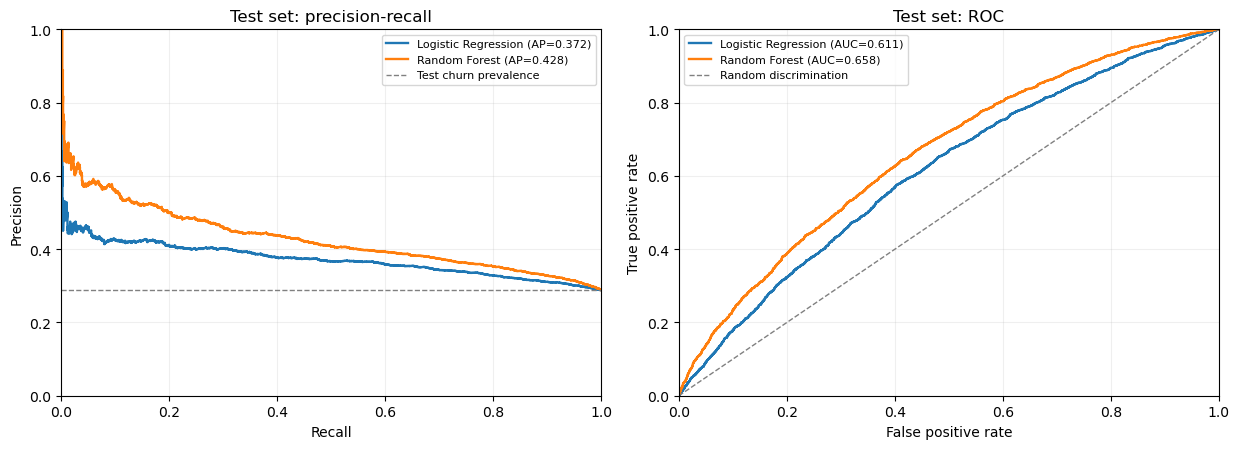

In [117]:
# Test results compared with the cross-validation estimates, plus precision-recall and ROC curves.
s13_rank_table = (
    s13_test_table[s13_test_table.Decision == "F1 threshold"][
        [
            "Algorithm",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "mcc",
            "balanced_accuracy",
            "accuracy",
            "Alert_rate",
        ]
    ]
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)
s13_dev_ref = {
    name: s11_summary[
        (s11_summary.Algorithm == name)
        & (s11_summary.Weighting == "Unweighted")
        & (s11_summary.Decision == "Inner-selected F1")
    ].iloc[0]
    for name in S13_ALGORITHMS
}
s13_dev_vs_test = pd.DataFrame(
    [
        {
            "Algorithm": name,
            "Development_CV_AP": float(s13_dev_ref[name].AP_mean),
            "Test_AP": float(s13_rank_table.set_index("Algorithm").loc[name, "average_precision"]),
            "Development_CV_ROC_AUC": float(s13_dev_ref[name].ROC_AUC_mean),
            "Test_ROC_AUC": float(s13_rank_table.set_index("Algorithm").loc[name, "roc_auc"]),
        }
        for name in S13_ALGORITHMS
    ]
)
s13_dev_vs_test["AP_difference_test_minus_CV"] = (
    s13_dev_vs_test.Test_AP - s13_dev_vs_test.Development_CV_AP
)
s13_dev_vs_test["ROC_AUC_difference_test_minus_CV"] = (
    s13_dev_vs_test.Test_ROC_AUC - s13_dev_vs_test.Development_CV_ROC_AUC
)
display(s13_rank_table.round(5))
display(s13_dev_vs_test.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for algorithm in S13_ALGORITHMS:
    scores = s13_test_predictions[algorithm].Churn_probability.to_numpy()
    precision, recall, _ = precision_recall_curve(s13_ytest, scores)
    false_positive_rate, true_positive_rate, _ = roc_curve(s13_ytest, scores)
    ap = float(s13_rank_table.set_index("Algorithm").loc[algorithm, "average_precision"])
    roc = float(s13_rank_table.set_index("Algorithm").loc[algorithm, "roc_auc"])
    axes[0].plot(recall, precision, label=f"{algorithm} (AP={ap:.3f})", linewidth=1.7)
    axes[1].plot(
        false_positive_rate, true_positive_rate, label=f"{algorithm} (AUC={roc:.3f})", linewidth=1.7
    )
axes[0].axhline(
    s13_ytest.mean(), linestyle="--", color="grey", linewidth=1, label="Test churn prevalence"
)
axes[0].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Test set: precision-recall",
    xlim=(0, 1),
    ylim=(0, 1),
)
axes[1].plot(
    [0, 1], [0, 1], linestyle="--", color="grey", linewidth=1, label="Random discrimination"
)
axes[1].set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="Test set: ROC",
    xlim=(0, 1),
    ylim=(0, 1),
)
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Test performance is very close to the cross-validation estimates. Random Forest's AP fell slightly, from 0.4317 to **0.4283** (−0.003), and Logistic Regression's from 0.3794 to **0.3716** (−0.008); ROC-AUC fell by about 0.005–0.006 for both. These small drops are expected after tuning on development data, and they indicate that the cross-validation estimates were reliable and only slightly optimistic for new customers from the same population. Across the whole precision–recall curve, Random Forest stays above Logistic Regression.

### 13.7 Decision Errors and Targeted Contact Lists

The confusion matrices show what each decision rule would mean in practice. Because contacting every flagged customer may not be realistic, precision, recall and lift are also reported when contacting only the highest-scoring 10% or 20% of test customers.

,Algorithm,Decision,Threshold,TN,FP,FN,TP,Alert_n,Alert_rate,precision,recall,f1
0,Logistic Regression,Default 0.5,0.50,7194,74,2880,62,136,0.01332,0.45588,0.02107,0.04029
1,Logistic Regression,F1 threshold,0.25,2700,4568,653,2289,6857,0.67160,0.33382,0.77804,0.46719
2,Random Forest,Default 0.5,0.50,7225,43,2872,70,113,0.01107,0.61947,0.02379,0.04583
3,Random Forest,F1 threshold,0.27,3377,3891,731,2211,6102,0.59765,0.36234,0.75153,0.48894


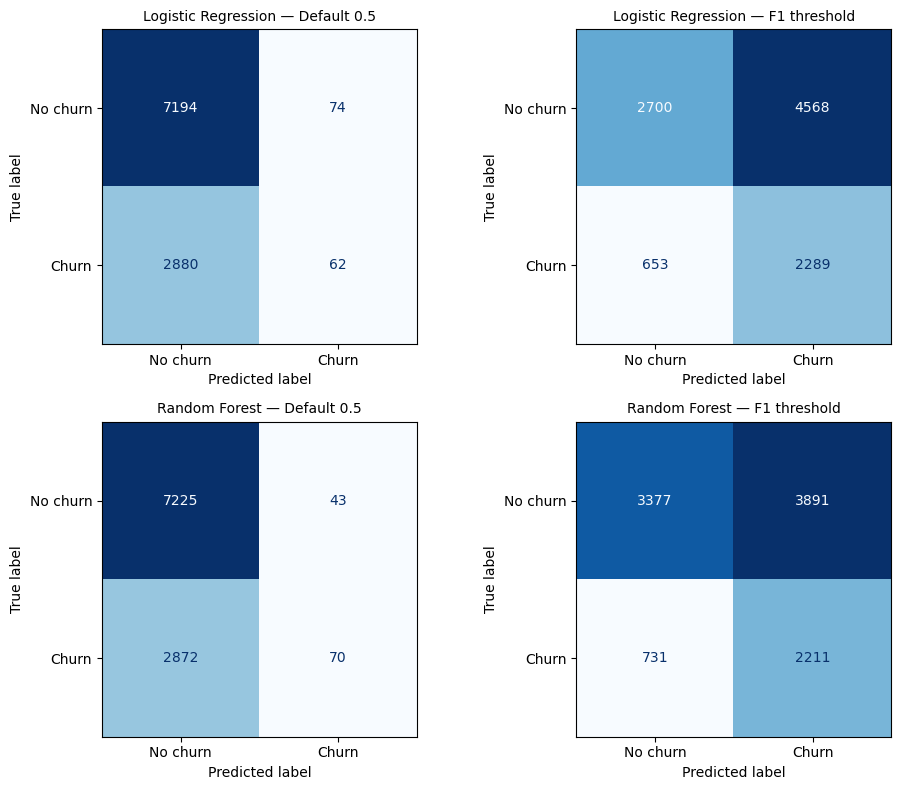

,Algorithm,Capacity,Targeted_n,Observed_churn_n,Precision_at_capacity,Recall_at_capacity,Baseline_churn_prevalence,Lift_vs_prevalence
0,Logistic Regression,0.1,1021,431,0.42214,0.14650,0.28815,1.46499
1,Logistic Regression,0.2,2042,824,0.40353,0.28008,0.28815,1.40041
2,Random Forest,0.1,1021,526,0.51518,0.17879,0.28815,1.78790
3,Random Forest,0.2,2042,919,0.45005,0.31237,0.28815,1.56186


In [118]:
# Confusion matrices for both decision rules.
s13_confusion_display = s13_test_table[
    [
        "Algorithm",
        "Decision",
        "Threshold",
        "TN",
        "FP",
        "FN",
        "TP",
        "Alert_n",
        "Alert_rate",
        "precision",
        "recall",
        "f1",
    ]
].copy()
display(s13_confusion_display.round(5))
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for row, algorithm in enumerate(S13_ALGORITHMS):
    for col, policy in enumerate(S13_DECISIONS):
        res = s13_test_predictions[algorithm]
        column = "Default_prediction" if policy == "Default 0.5" else "F1_threshold_prediction"
        table = confusion_matrix(res.Actual_Churn, res[column], labels=[0, 1])
        ConfusionMatrixDisplay(table, display_labels=["No churn", "Churn"]).plot(
            ax=axs[row, col], cmap="Blues", colorbar=False, values_format="d"
        )
        axs[row, col].set_title(f"{algorithm} — {policy}", fontsize=10)
plt.tight_layout()
plt.show()

# Precision, recall and lift when contacting the top 10% or 20% of test customers by score.
s13_capacity_rows = []
for algorithm in S13_ALGORITHMS:
    probabilities = s13_test_predictions[algorithm].Churn_probability.to_numpy()
    order = np.argsort(-probabilities, kind="stable")
    for fraction in S13_CAPACITIES:
        selected_n = int(np.ceil(len(s13_ytest) * fraction))
        selected = order[:selected_n]
        captured = int(s13_ytest[selected].sum())
        s13_capacity_rows.append(
            {
                "Algorithm": algorithm,
                "Capacity": fraction,
                "Targeted_n": selected_n,
                "Observed_churn_n": captured,
                "Precision_at_capacity": captured / selected_n,
                "Recall_at_capacity": captured / int(s13_ytest.sum()),
                "Baseline_churn_prevalence": s13_ytest.mean(),
                "Lift_vs_prevalence": (captured / selected_n) / s13_ytest.mean(),
            }
        )
s13_capacity_table = pd.DataFrame(s13_capacity_rows)
display(s13_capacity_table.round(5))

**Classification workload.** At their F1 thresholds, Logistic Regression flags **6,857 of 10,210** test customers (**67.2%**) to find **2,289 of 2,942** churners, with **4,568 false alarms**. Random Forest flags **6,102** customers (**59.8%**) to find **2,211** churners, with **3,891 false alarms**. Both F1-optimal thresholds would require contacting most of the customer base, which is rarely realistic.

**A better decision rule: rank customers and contact a fixed top share.** Contacting the **top 10%** of Random Forest scores (1,021 customers) reaches churners at **51.5% precision**, **1.8×** the 28.8% base rate, and covers **17.9%** of all churners. The **top 20%** reaches **45.0% precision** (1.6×) and covers **31.2%** of churners. For Logistic Regression the corresponding precisions are 42.2% (1.5×) and 40.4% (1.4×). The right share depends on the retention team's capacity and costs, which the dataset does not provide. These results show which customers went on to churn; they do not show whether contacting them would have prevented it.

### 13.8 Uncertainty in the Model Difference

A single test set gives a single AP difference. To estimate how much this difference could vary by chance, a **paired, class-stratified bootstrap** is used. The test customers are resampled with replacement 500 times, keeping the numbers of churners and non-churners fixed; both models' AP is recomputed on the same resample, and the difference is recorded. The 2.5th and 97.5th percentiles of these differences form a 95% interval.

**Limitation:** the interval reflects sampling variation in the test set only, not uncertainty from retraining the models on different data.

,Contrast,Observed_difference,Bootstrap_replicates,Lower_95_percentile,Upper_95_percentile,Bootstrap_design
0,Random Forest AP - Logistic Regression AP,0.05671,500,0.0398,0.07026,Paired class-stratified test customer resampling


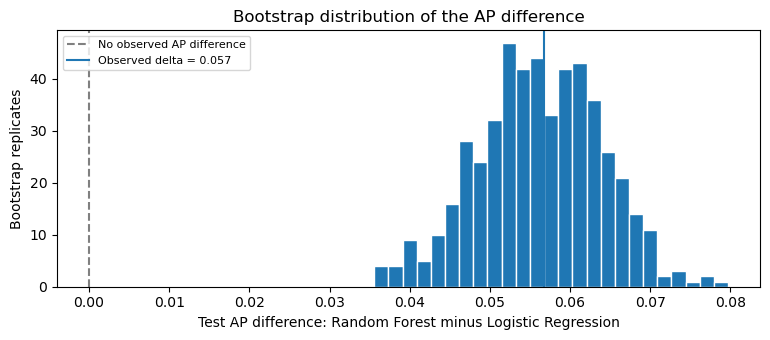

In [119]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Paired, class-stratified bootstrap of the AP difference between the two models.
s13_lr_scores = s13_test_predictions["Logistic Regression"].Churn_probability.to_numpy()
s13_rf_scores = s13_test_predictions["Random Forest"].Churn_probability.to_numpy()
s13_ap_difference = float(
    average_precision_score(s13_ytest, s13_rf_scores)
    - average_precision_score(s13_ytest, s13_lr_scores)
)
random_generator = np.random.default_rng(1313)
zero_rows = np.flatnonzero(s13_ytest == 0)
one_rows = np.flatnonzero(s13_ytest == 1)
S13_BOOTSTRAPS = 500
s13_boot_differences = np.empty(S13_BOOTSTRAPS)
# Each resample draws non-churners and churners separately, and scores both models on the same customers.
for b in range(S13_BOOTSTRAPS):
    choices = np.concatenate(
        [
            random_generator.choice(zero_rows, size=len(zero_rows), replace=True),
            random_generator.choice(one_rows, size=len(one_rows), replace=True),
        ]
    )
    sampled_y = s13_ytest[choices]
    s13_boot_differences[b] = average_precision_score(
        sampled_y, s13_rf_scores[choices]
    ) - average_precision_score(sampled_y, s13_lr_scores[choices])
ci_lower, ci_upper = np.percentile(s13_boot_differences, [2.5, 97.5])
s13_uncertainty = pd.DataFrame(
    [
        {
            "Contrast": "Random Forest AP - Logistic Regression AP",
            "Observed_difference": s13_ap_difference,
            "Bootstrap_replicates": S13_BOOTSTRAPS,
            "Lower_95_percentile": float(ci_lower),
            "Upper_95_percentile": float(ci_upper),
            "Bootstrap_design": "Paired class-stratified test customer resampling",
        }
    ]
)
display(s13_uncertainty.round(5))
fig, ax = plt.subplots(figsize=(7.8, 3.5))
ax.hist(s13_boot_differences, bins=25, edgecolor="white")
ax.axvline(0, color="grey", linestyle="--", label="No observed AP difference")
ax.axvline(s13_ap_difference, linestyle="-", label=f"Observed delta = {s13_ap_difference:.3f}")
ax.set(
    xlabel="Test AP difference: Random Forest minus Logistic Regression",
    ylabel="Bootstrap replicates",
    title="Bootstrap distribution of the AP difference",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Random Forest's test AP advantage is **+0.0567**, with a 95% bootstrap interval of **[+0.040, +0.070]**. The interval lies well above zero, so the difference between the algorithms is very unlikely to be a chance effect of this particular test sample, given the two fitted models.

### 13.9 Final-Test Checks

A final set of checks confirms that the test set stayed separate from training and that the evaluated pipelines are exactly the settings fixed in Sections 10–12.

In [120]:
# Final checks: test isolation and the exact settings of the evaluated models.
lr_final = s13_fitted_models["Logistic Regression"].named_steps["classifier"]
rf_final = s13_fitted_models["Random Forest"].named_steps["classifier"]
s13_checks = {
    "Test features and labels aligned (10,210 customers)": len(s13_Xtest) == len(s13_ytest) == 10210
    and s13_Xtest.index.equals(y_test.index),
    "No customer appears in both development and test": set(customer_ids_dev).isdisjoint(
        set(customer_ids_test)
    ),
    "Same 53 ordered predictors for training and test": tuple(s13_Xtest.columns)
    == S13_PRIMARY_FEATURES
    == tuple(X_dev_primary.columns),
    "Identifier, target and retention fields excluded": {
        ID_COL,
        TARGET_COL,
        *RETENTION_EXCLUSIONS,
    }.isdisjoint(S13_PRIMARY_FEATURES),
    "Final models use the selected settings": lr_final.C == s10_lr_best_C
    and lr_final.class_weight is None
    and len(rf_final.estimators_) == rf_final.n_estimators == 100
    and all(getattr(rf_final, k) == v for k, v in s10_rf_best_params.items())
    and rf_final.class_weight is None,
    "Thresholds are the medians of the Section 11 inner-fold thresholds": all(
        np.isclose(
            s13_thresholds[a],
            s11_inner_results[
                (s11_inner_results.Algorithm == a) & (s11_inner_results.Weighting == "Unweighted")
            ].Threshold.median(),
        )
        for a in S13_ALGORITHMS
    ),
    "Confusion counts cover every test customer": (
        s13_test_table[["TN", "FP", "FN", "TP"]].sum(axis=1) == len(s13_ytest)
    ).all()
    and (s13_test_table[["TP", "FN"]].sum(axis=1) == s13_ytest.sum()).all(),
    "No warnings while fitting the final models": not s13_fit_warnings,
}
s13_integrity = pd.DataFrame(
    {"Check": list(s13_checks), "Passed": [bool(v) for v in s13_checks.values()]}
)
display(s13_integrity)
assert s13_integrity.Passed.all(), "Final-test integrity check failed."
print(f"Final-test checks passed: {int(s13_integrity.Passed.sum())}/{len(s13_integrity)}")

,Check,Passed
0,"Test features and labels aligned (10,210 custo...",True
1,No customer appears in both development and test,True
2,Same 53 ordered predictors for training and test,True
3,"Identifier, target and retention fields excluded",True
4,Final models use the selected settings,True
5,Thresholds are the medians of the Section 11 i...,True
6,Confusion counts cover every test customer,True
7,No warnings while fitting the final models,True


Final-test checks passed: 8/8


All checks pass. The test customers share no IDs with the development data, both models used the same 53 predictors and the settings fixed beforehand, the thresholds are the medians of the Section 11 inner-fold thresholds, and the confusion counts account for every test customer. The test results above are therefore an independent estimate. **On both development and test evidence, Random Forest is the better-performing of the two models on this historical dataset.**

## 14. Model Interpretation and Error Analysis

With the test results recorded, this section examines *how* the two models behave: the errors they make, how confident they are, whether they agree, how reliable their probabilities are, and which features they rely on. These analyses use the final models and their test predictions; nothing is retrained or re-tuned.

### 14.1 Setup

The two final pipelines, their thresholds (0.25 for Logistic Regression and 0.27 for Random Forest) and their test predictions from Section 13 are reused.

In [121]:
from sklearn.metrics import brier_score_loss, average_precision_score, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve

# Settings for the interpretation analyses; the final models and test predictions are reused.
S14_ALGORITHMS = tuple(S13_ALGORITHMS)
S14_THRESHOLD_LABEL = "F1 threshold"
S14_MIN_SEGMENT_N = 150
S14_PERMUTATION_N = 2500
S14_PERMUTATION_REPEATS = 3
assert len(s13_ytest) == 10210 and len(S13_PRIMARY_FEATURES) == 53
assert all(s13_test_predictions[a].index.equals(s13_Xtest.index) for a in S14_ALGORITHMS)
print("Using the final models and their test predictions from Section 13.")

Using the final models and their test predictions from Section 13.


### 14.2 Error Types and Workload

A **false negative** is a churner the model missed, so a lost customer the business never tried to keep. A **false positive** is a customer flagged as a churner who would have stayed, so a wasted contact or offer. Recall, the false-positive rate (false positives as a share of non-churners) and the alert rate (share of all customers flagged) are reported together, because higher recall always comes at the cost of more alerts.

,Algorithm,Decision,TN,FP,FN,TP,Recall,False_positive_rate,False_negative_rate,Precision,Alert_rate,Flagged_customers,Missed_churners
0,Logistic Regression,Default 0.5,7194,74,2880,62,0.0211,0.0102,0.9789,0.4559,0.0133,136,2880
1,Logistic Regression,F1 threshold,2700,4568,653,2289,0.7780,0.6285,0.2220,0.3338,0.6716,6857,653
2,Random Forest,Default 0.5,7225,43,2872,70,0.0238,0.0059,0.9762,0.6195,0.0111,113,2872
3,Random Forest,F1 threshold,3377,3891,731,2211,0.7515,0.5354,0.2485,0.3623,0.5976,6102,731


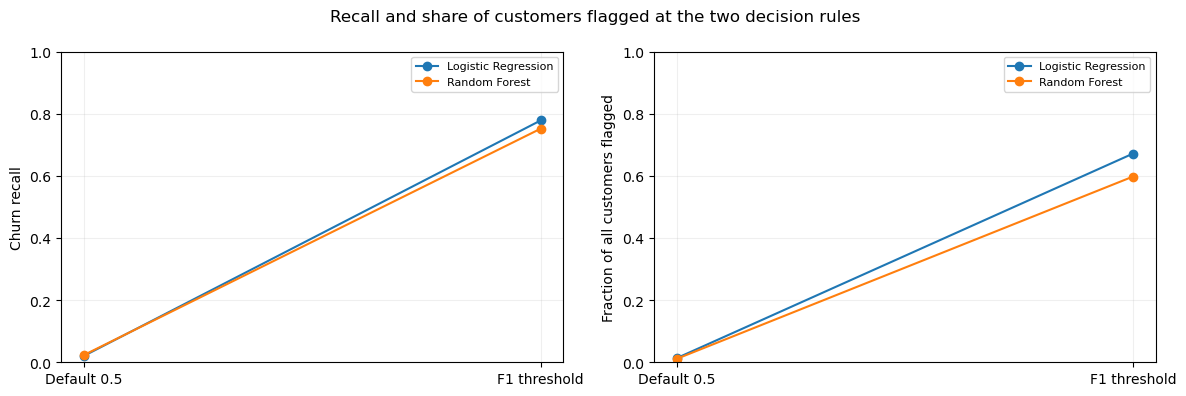

In [122]:
# Recall, false-positive rate and alert rate for each model and decision rule.
s14_error_rows = []
for algorithm in S14_ALGORITHMS:
    for decision in S13_DECISIONS:
        row = s13_test_table.loc[
            (s13_test_table.Algorithm == algorithm) & (s13_test_table.Decision == decision)
        ].iloc[0]
        tn, fp, fn, tp = [int(row[key]) for key in ("TN", "FP", "FN", "TP")]
        s14_error_rows.append(
            {
                "Algorithm": algorithm,
                "Decision": decision,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "TP": tp,
                "Recall": tp / (tp + fn),
                "False_positive_rate": fp / (fp + tn),
                "False_negative_rate": fn / (tp + fn),
                "Precision": tp / (tp + fp) if tp + fp else 0,
                "Alert_rate": (tp + fp) / (tp + fp + tn + fn),
                "Flagged_customers": tp + fp,
                "Missed_churners": fn,
            }
        )
s14_error_table = pd.DataFrame(s14_error_rows)
display(s14_error_table.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for algorithm in S14_ALGORITHMS:
    sub = s14_error_table[s14_error_table.Algorithm == algorithm].set_index("Decision")
    axes[0].plot([0, 1], sub.loc[list(S13_DECISIONS), "Recall"], marker="o", label=algorithm)
    axes[1].plot([0, 1], sub.loc[list(S13_DECISIONS), "Alert_rate"], marker="o", label=algorithm)
for axis, label in zip(axes, ["Churn recall", "Fraction of all customers flagged"]):
    axis.set_xticks([0, 1], ["Default 0.5", "F1 threshold"])
    axis.set_ylabel(label)
    axis.set_ylim(0, 1)
    axis.grid(alpha=0.2)
    axis.legend(fontsize=8)
plt.suptitle("Recall and share of customers flagged at the two decision rules")
plt.tight_layout()
plt.show()

At the F1 thresholds, Logistic Regression catches **2,289 of 2,942** churners (77.8%) and Random Forest **2,211** (75.2%). Random Forest raises considerably fewer false alarms: **3,891 against 4,568**, a false-positive rate of **53.5%** against **62.9%**. In other words, Logistic Regression finds 78 more churners at the cost of 677 more unnecessary contacts.

### 14.3 Scores Behind Correct and Incorrect Decisions

The distributions of predicted scores are compared for true positives, false positives, true negatives and false negatives.

,Algorithm,Outcome,Customers,Mean_score,Median_score,P10_score,P90_score
0,Logistic Regression,TP,2289,0.3420,0.3281,0.2667,0.4293
1,Logistic Regression,FP,4568,0.3271,0.3134,0.2619,0.4098
2,Logistic Regression,TN,2700,0.2004,0.2076,0.1458,0.2431
3,Logistic Regression,FN,653,0.2061,0.2139,0.1564,0.2435
4,Random Forest,TP,2211,0.3545,0.3450,0.2881,0.4254
5,Random Forest,FP,3891,0.3351,0.3268,0.2808,0.3978
6,Random Forest,TN,3377,0.2076,0.2153,0.1438,0.2603
7,Random Forest,FN,731,0.2225,0.2307,0.1666,0.2642


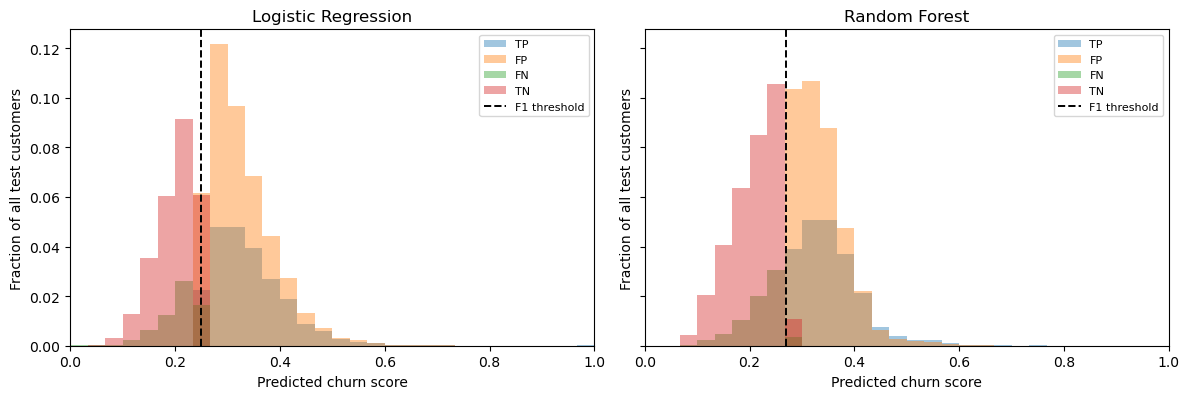

In [123]:
# Score distributions for true/false positives and negatives at the F1 threshold.
s14_profile_records = []
s14_labeled_predictions = {}
for algorithm in S14_ALGORITHMS:
    data = s13_test_predictions[algorithm]
    y = data.Actual_Churn.to_numpy(dtype=int)
    predicted = data.F1_threshold_prediction.to_numpy(dtype=int)
    score = data.Churn_probability.to_numpy(dtype=float)
    labels = np.select(
        [
            (y == 1) & (predicted == 1),
            (y == 0) & (predicted == 1),
            (y == 0) & (predicted == 0),
            (y == 1) & (predicted == 0),
        ],
        ["TP", "FP", "TN", "FN"],
        default="Other",
    )
    assert not (labels == "Other").any()
    s14_labeled_predictions[algorithm] = pd.DataFrame(
        {"Actual": y, "Prediction": predicted, "Score": score, "Error_type": labels},
        index=data.index,
    )
    for group in ["TP", "FP", "TN", "FN"]:
        scores = score[labels == group]
        s14_profile_records.append(
            {
                "Algorithm": algorithm,
                "Outcome": group,
                "Customers": len(scores),
                "Mean_score": scores.mean(),
                "Median_score": np.median(scores),
                "P10_score": np.quantile(scores, 0.10),
                "P90_score": np.quantile(scores, 0.90),
            }
        )
s14_error_profiles = pd.DataFrame(s14_profile_records)
display(s14_error_profiles.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), sharey=True)
for axis, algorithm in zip(axes, S14_ALGORITHMS):
    sub = s14_labeled_predictions[algorithm]
    for label in ["TP", "FP", "FN", "TN"]:
        scores = sub.loc[sub.Error_type == label, "Score"]
        axis.hist(
            scores,
            bins=np.linspace(0, 1, 31),
            weights=np.ones(len(scores)) / len(sub),
            alpha=0.42,
            label=label,
        )
    axis.axvline(
        s13_thresholds[algorithm],
        color="black",
        linestyle="--",
        linewidth=1.4,
        label="F1 threshold",
    )
    axis.set(
        xlabel="Predicted churn score",
        ylabel="Fraction of all test customers",
        title=algorithm,
        xlim=(0, 1),
    )
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

The scores of correctly flagged churners and wrongly flagged non-churners are very similar. For Random Forest the median is **0.345** for true positives and **0.327** for false positives, while missed churners have a median of **0.231**. The models cannot cleanly separate churners from non-churners near the threshold, which is consistent with the moderate ROC-AUC. A high score should be read as elevated risk, not as a certain prediction.

### 14.4 Agreement Between the Two Models

The customers flagged by each model are compared, together with the overlap in their errors.

In [124]:
# Agreement between the two models' decisions at their F1 thresholds.
s14_lr = s14_labeled_predictions["Logistic Regression"]
s14_rf = s14_labeled_predictions["Random Forest"]
s14_y = s13_ytest
s14_alert_agreement = pd.crosstab(
    s14_lr.Prediction,
    s14_rf.Prediction,
    rownames=["LR prediction"],
    colnames=["RF prediction"],
)
s14_correct_lr = s14_lr.Prediction.to_numpy() == s14_y
s14_correct_rf = s14_rf.Prediction.to_numpy() == s14_y
s14_overlap_summary = pd.DataFrame(
    [
        {
            "Measure": "Both models flag churn",
            "Customers": int(((s14_lr.Prediction == 1) & (s14_rf.Prediction == 1)).sum()),
        },
        {
            "Measure": "Only LR flags churn",
            "Customers": int(((s14_lr.Prediction == 1) & (s14_rf.Prediction == 0)).sum()),
        },
        {
            "Measure": "Only RF flags churn",
            "Customers": int(((s14_lr.Prediction == 0) & (s14_rf.Prediction == 1)).sum()),
        },
        {
            "Measure": "Neither model flags churn",
            "Customers": int(((s14_lr.Prediction == 0) & (s14_rf.Prediction == 0)).sum()),
        },
        {"Measure": "Both correct", "Customers": int((s14_correct_lr & s14_correct_rf).sum())},
        {"Measure": "Both wrong", "Customers": int((~s14_correct_lr & ~s14_correct_rf).sum())},
        {
            "Measure": "LR correct, RF wrong",
            "Customers": int((s14_correct_lr & ~s14_correct_rf).sum()),
        },
        {
            "Measure": "RF correct, LR wrong",
            "Customers": int((~s14_correct_lr & s14_correct_rf).sum()),
        },
        {
            "Measure": "Actual churners missed by both",
            "Customers": int(
                (
                    (s14_y == 1)
                    & (s14_lr.Prediction.to_numpy() == 0)
                    & (s14_rf.Prediction.to_numpy() == 0)
                ).sum()
            ),
        },
        {
            "Measure": "Non-churners flagged by both",
            "Customers": int(
                (
                    (s14_y == 0)
                    & (s14_lr.Prediction.to_numpy() == 1)
                    & (s14_rf.Prediction.to_numpy() == 1)
                ).sum()
            ),
        },
    ]
)
display(s14_alert_agreement)
display(s14_overlap_summary)
s14_alert_jaccard = float(
    ((s14_lr.Prediction == 1) & (s14_rf.Prediction == 1)).sum()
    / ((s14_lr.Prediction == 1) | (s14_rf.Prediction == 1)).sum()
)
print("Overlap of flagged customers (Jaccard index):", f"{s14_alert_jaccard:.3f}")

RF prediction,0,1
LR prediction,,
0,2344,1009
1,1764,5093


,Measure,Customers
0,Both models flag churn,5093
1,Only LR flags churn,1764
2,Only RF flags churn,1009
3,Neither model flags churn,2344
4,Both correct,3902
5,Both wrong,3535
6,"LR correct, RF wrong",1087
7,"RF correct, LR wrong",1686
8,Actual churners missed by both,370
9,Non-churners flagged by both,3165


Overlap of flagged customers (Jaccard index): 0.647


The models largely agree: **5,093** customers are flagged by both, **1,764** only by Logistic Regression and **1,009** only by Random Forest (an overlap of 0.65 as a share of all flagged customers). Many errors are shared: **370 churners are missed by both** and **3,165 non-churners are flagged by both**, which suggests these customers simply look alike in the available data. Where the models disagree, Random Forest is right more often (1,686 customers, against 1,087 where only Logistic Regression is right).

### 14.5 Reliability of the Predicted Probabilities

A score of 0.30 should ideally mean a 30% chance of churning. This is checked with the **Brier score** (the mean squared difference between the predicted probability and the outcome; lower is better), compared with a constant prediction equal to the churn rate, and with a reliability diagram over ten equal-sized score bins. Calibration is only described here; no recalibration is applied.

,Algorithm,Brier_score,Constant_test_prevalence_Brier,Mean_predicted_probability,Actual_churn_prevalence,Reliability_bins
0,Logistic Regression,0.19911,0.20512,0.28916,0.28815,10
1,Random Forest,0.19306,0.20512,0.28905,0.28815,10


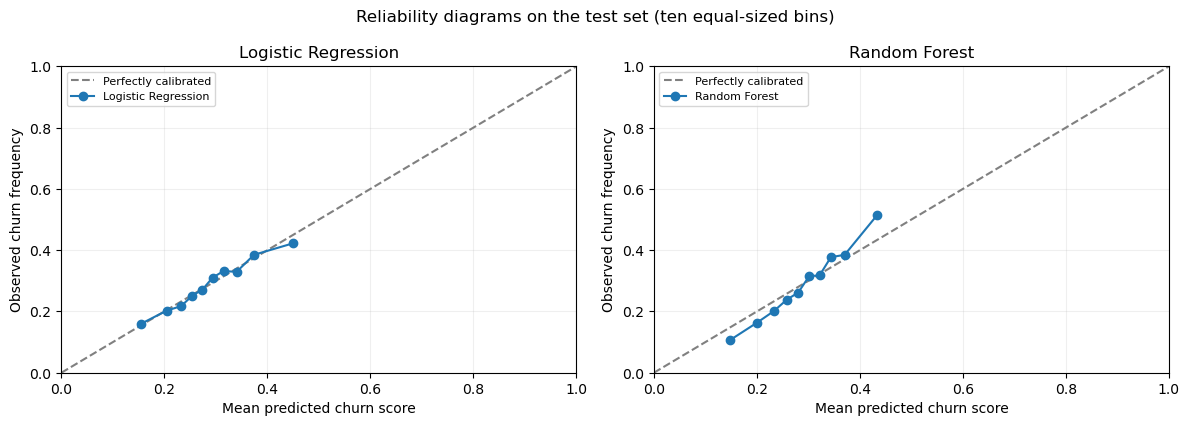

In [125]:
# Brier scores and reliability diagrams (ten equal-sized score bins); no recalibration.
s14_brier_baseline = float(brier_score_loss(s14_y, np.full(len(s14_y), s14_y.mean())))
s14_reliability_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for axis, algorithm in zip(axes, S14_ALGORITHMS):
    scores = s14_labeled_predictions[algorithm].Score.to_numpy(dtype=float)
    brier = float(brier_score_loss(s14_y, scores))
    observed, forecast = calibration_curve(s14_y, scores, n_bins=10, strategy="quantile")
    s14_reliability_rows.append(
        {
            "Algorithm": algorithm,
            "Brier_score": brier,
            "Constant_test_prevalence_Brier": s14_brier_baseline,
            "Mean_predicted_probability": scores.mean(),
            "Actual_churn_prevalence": s14_y.mean(),
            "Reliability_bins": len(observed),
        }
    )
    axis.plot([0, 1], [0, 1], "--", color="grey", label="Perfectly calibrated")
    axis.plot(forecast, observed, marker="o", label=algorithm)
    axis.set(
        xlim=(0, 1),
        ylim=(0, 1),
        xlabel="Mean predicted churn score",
        ylabel="Observed churn frequency",
        title=algorithm,
    )
    axis.legend(fontsize=8)
    axis.grid(alpha=0.2)
s14_reliability = pd.DataFrame(s14_reliability_rows)
display(s14_reliability.round(5))
plt.suptitle("Reliability diagrams on the test set (ten equal-sized bins)")
plt.tight_layout()
plt.show()

Both models improve on the constant prediction (Brier score 0.2051): Random Forest scores **0.1931** and Logistic Regression **0.1991**. Their average predicted probabilities (0.289) match the actual churn rate (0.288) almost exactly. Logistic Regression's reliability curve follows the diagonal closely. Random Forest's is slightly too high for low-risk customers and too low for its highest-risk group, where about 52% churned against a mean score of about 0.43. Almost all scores fall between about 0.15 and 0.45, which is why a 0.5 cut-off flags so few customers.

### 14.6 Performance in Customer Subgroups

An overall score can hide differences between groups of customers. Two attributes are examined: tenure, split at the development-data quartiles, and whether the handset price is recorded. The models and thresholds are the same for every group. These comparisons are exploratory and not adjusted for multiple testing.

In [126]:
# Performance within tenure quartiles (cut points from development data) and by handset-price availability.
s14_tenure_train = pd.to_numeric(X_dev_primary["MonthsInService"], errors="coerce")
s14_tenure_test = pd.to_numeric(s13_Xtest["MonthsInService"], errors="coerce")
s14_quartiles = np.quantile(s14_tenure_train.dropna(), [0, 0.25, 0.50, 0.75, 1])
s14_edges = np.unique(np.concatenate(([-np.inf], s14_quartiles[1:-1], [np.inf])))
assert len(s14_edges) >= 3
s14_tenure_group = (
    pd.cut(s14_tenure_test, bins=s14_edges, include_lowest=True)
    .astype("string")
    .fillna("Missing tenure")
)
s14_price_group = np.where(
    s13_Xtest.HandsetPrice.astype("string").str.strip().str.casefold().eq("unknown").fillna(False),
    "Unknown handset price",
    "Recorded handset price",
)
s14_group_rows = []
for feature_name, groups in [
    ("MonthsInService (development quartiles)", np.asarray(s14_tenure_group)),
    ("HandsetPrice availability", np.asarray(s14_price_group)),
]:
    for group in sorted(pd.Series(groups).unique()):
        mask = groups == group
        ys = s14_y[mask]
        for algorithm in S14_ALGORITHMS:
            pred = s14_labeled_predictions[algorithm].Prediction.to_numpy()[mask]
            scores = s14_labeled_predictions[algorithm].Score.to_numpy()[mask]
            tn, fp, fn, tp = confusion_matrix(ys, pred, labels=[0, 1]).ravel()
            s14_group_rows.append(
                {
                    "Attribute": feature_name,
                    "Group": str(group),
                    "Algorithm": algorithm,
                    "N": len(ys),
                    "Churn_N": int(ys.sum()),
                    "Churn_prevalence": float(ys.mean()),
                    "Recall": tp / (tp + fn) if tp + fn else np.nan,
                    "FPR": fp / (fp + tn) if fp + tn else np.nan,
                    "Precision": tp / (tp + fp) if tp + fp else np.nan,
                    "Alert_rate": float(pred.mean()),
                    "AP": (
                        average_precision_score(ys, scores) if len(np.unique(ys)) == 2 else np.nan
                    ),
                    "Small_group_warning": bool(
                        len(ys) < S14_MIN_SEGMENT_N or min(np.bincount(ys, minlength=2)) < 30
                    ),
                }
            )
s14_group_table = pd.DataFrame(s14_group_rows)
display(s14_group_table.round(4))
print("Tenure quartile boundaries (development data):", s14_quartiles.tolist())

,Attribute,Group,Algorithm,N,Churn_N,Churn_prevalence,Recall,FPR,Precision,Alert_rate,AP,Small_group_warning
0,MonthsInService (development quartiles),"(-inf, 11.0]",Logistic Regression,2852,697,0.2444,0.6987,0.5415,0.2944,0.5799,0.3147,False
1,MonthsInService (development quartiles),"(-inf, 11.0]",Random Forest,2852,697,0.2444,0.5308,0.2371,0.4200,0.3089,0.4329,False
2,MonthsInService (development quartiles),"(11.0, 16.0]",Logistic Regression,2335,816,0.3495,0.7708,0.6728,0.3810,0.7071,0.4338,False
3,MonthsInService (development quartiles),"(11.0, 16.0]",Random Forest,2335,816,0.3495,0.8689,0.7498,0.3837,0.7914,0.4733,False
4,MonthsInService (development quartiles),"(16.0, 24.0]",Logistic Regression,2531,756,0.2987,0.8399,0.7285,0.3294,0.7618,0.3959,False
5,MonthsInService (development quartiles),"(16.0, 24.0]",Random Forest,2531,756,0.2987,0.8069,0.6513,0.3454,0.6977,0.4193,False
6,MonthsInService (development quartiles),"(24.0, inf]",Logistic Regression,2492,673,0.2701,0.7994,0.5970,0.3313,0.6517,0.3583,False
7,MonthsInService (development quartiles),"(24.0, inf]",Random Forest,2492,673,0.2701,0.7756,0.5965,0.3248,0.6449,0.3892,False
8,HandsetPrice availability,Recorded handset price,Logistic Regression,4442,1163,0.2618,0.7034,0.5255,0.3219,0.5720,0.3587,False
9,HandsetPrice availability,Recorded handset price,Random Forest,4442,1163,0.2618,0.6543,0.4523,0.3391,0.5052,0.3862,False


Tenure quartile boundaries (development data): [6.0, 11.0, 16.0, 24.0, 61.0]


Performance varies noticeably between groups, partly because their churn rates differ (from 24% to 35%). For the newest customers (≤ 11 months) Random Forest is more selective, with recall of **53.1%** and a false-positive rate of **23.7%**. For 11–16-month customers it flags far more, with recall of **86.9%** and a false-positive rate of **75.0%**. Customers with an unknown handset price are flagged more readily (recall **81.5%**) than those with a recorded price (**65.4%**). One threshold therefore behaves differently across segments, which a real deployment would need to monitor; thresholds are not adjusted per group, because that would amount to tuning on test data.

### 14.7 Logistic Regression Coefficients

Each coefficient gives the change in the log-odds of churn for a one-standard-deviation increase in a numerical feature, or for belonging to a category, with all other model columns held fixed. Positive coefficients increase predicted churn risk. Because all one-hot categories are kept and correlated features share the L2 penalty, individual coefficients should be read as indications rather than exact effects.

,Encoded_feature,Coefficient_log_odds
26,numeric__CurrentEquipmentDays,0.3494
39,missing_flags__missingindicator_PercChangeReve...,0.2843
38,missing_flags__missingindicator_PercChangeMinutes,0.2843
90,categorical__CreditRating_5-Low,-0.2715
21,numeric__MonthsInService,-0.1758
22,numeric__UniqueSubs,0.1683
1,numeric__MonthlyMinutes,-0.1587
403,service_area__ServiceArea_STLSTL314,-0.1572
6,numeric__PercChangeMinutes,-0.1502
254,service_area__ServiceArea_MIAMIA305,0.1354


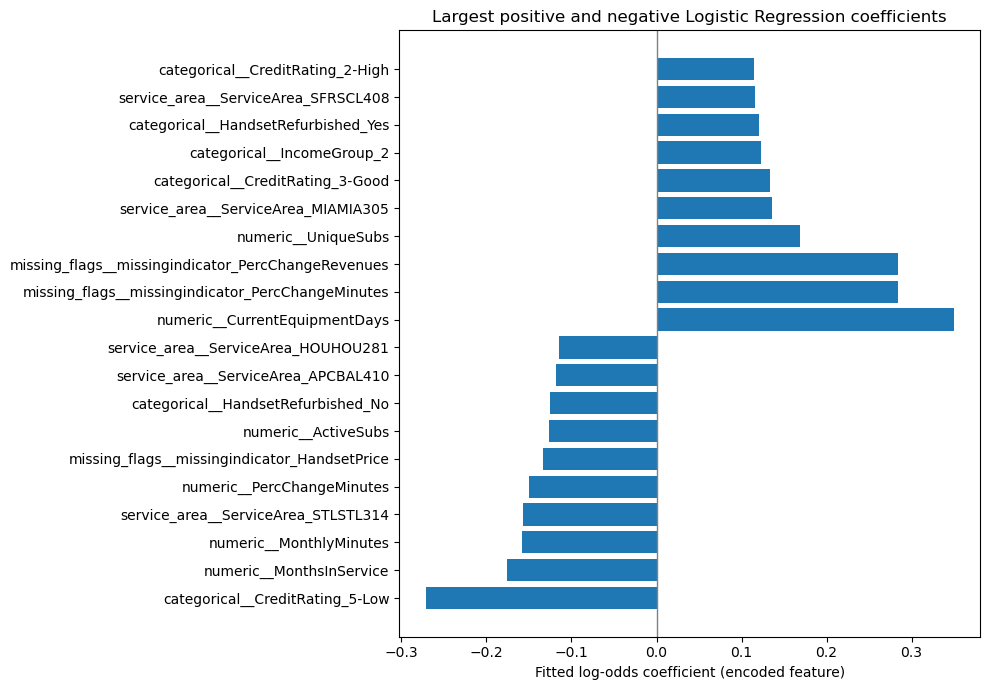

In [127]:
# Largest Logistic Regression coefficients (log-odds per standard deviation or per category).
s14_lr_pipeline = s13_fitted_models["Logistic Regression"]
s14_lr_names = s14_lr_pipeline.named_steps["preprocessor"].get_feature_names_out()
s14_lr_coefs = s14_lr_pipeline.named_steps["classifier"].coef_[0]
assert len(s14_lr_names) == len(s14_lr_coefs)
s14_lr_coefficients = pd.DataFrame(
    {
        "Encoded_feature": s14_lr_names,
        "Coefficient_log_odds": s14_lr_coefs,
        "Abs_coefficient": np.abs(s14_lr_coefs),
    }
)
assert s14_lr_coefficients.Encoded_feature.is_unique
s14_lr_biggest = s14_lr_coefficients.sort_values("Abs_coefficient", ascending=False).head(18)
display(s14_lr_biggest[["Encoded_feature", "Coefficient_log_odds"]].round(4))
strongest_positive = s14_lr_coefficients.nlargest(10, "Coefficient_log_odds")
strongest_negative = s14_lr_coefficients.nsmallest(10, "Coefficient_log_odds")
s14_plotcoef = pd.concat([strongest_negative, strongest_positive]).drop_duplicates(
    subset=["Encoded_feature"]
)
fig, ax = plt.subplots(figsize=(10, 7.0))
ax.barh(s14_plotcoef.Encoded_feature.astype(str), s14_plotcoef.Coefficient_log_odds)
ax.axvline(0, color="grey", linewidth=1)
ax.set(
    xlabel="Fitted log-odds coefficient (encoded feature)",
    title="Largest positive and negative Logistic Regression coefficients",
)
plt.tight_layout()
plt.show()

The largest coefficient belongs to **`CurrentEquipmentDays`** (+0.35): customers with older handsets are more likely to churn, consistent with the EDA. The missingness indicators for the two percentage-change fields follow (+0.28 each). Because these two indicators are identical columns (Section 14.10), the L2 penalty splits one effect between them, so their combined effect is about **+0.57**. `CreditRating_5-Low` lowers predicted risk (−0.27), matching its low churn rate in Section 4.7, and longer tenure and higher monthly minutes also reduce risk. These are associations learned from historical data, not causes of churn.

### 14.8 Permutation Importance

Coefficients exist only for Logistic Regression, and one-hot encoding splits features such as `ServiceArea` into many columns. To compare both models on the original 53 features, **permutation importance** is used: each feature is shuffled in turn, and the resulting drop in Average Precision is measured. To keep the run time reasonable and to limit further use of the test labels, a fixed stratified sample of 2,500 test customers and three repetitions per feature are used. Correlated features can share importance, so a small drop does not prove that a feature is irrelevant.

Logistic Regression: AP on the 2,500-customer sample before shuffling = 0.3711
Random Forest: AP on the 2,500-customer sample before shuffling = 0.4533


,Algorithm,Raw_feature,Mean_AP_drop,SD_AP_drop,Subset_AP_before_permutation
27,Logistic Regression,CurrentEquipmentDays,0.05870,0.01155,0.37106
22,Logistic Regression,UniqueSubs,0.02483,0.00765,0.37106
1,Logistic Regression,MonthlyMinutes,0.01453,0.00216,0.37106
7,Logistic Regression,PercChangeRevenues,0.01364,0.00373,0.37106
6,Logistic Regression,PercChangeMinutes,0.01349,0.00380,0.37106
21,Logistic Regression,MonthsInService,0.00789,0.00204,0.37106
2,Logistic Regression,TotalRecurringCharge,0.00548,0.00276,0.37106
49,Logistic Regression,CreditRating,0.00509,0.00199,0.37106
16,Logistic Regression,PeakCallsInOut,0.00503,0.00145,0.37106
31,Logistic Regression,HandsetRefurbished,0.00438,0.00095,0.37106


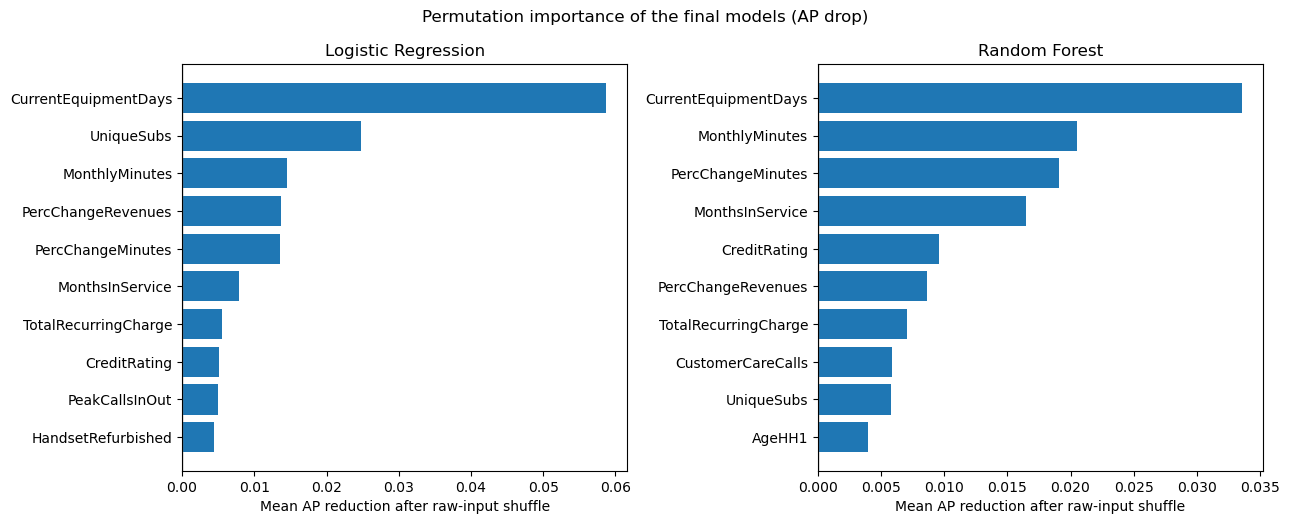

In [128]:
# Permutation importance of the 53 original features on a stratified sample of 2,500 test customers.
s14_all_positions = np.arange(len(s14_y))
_, s14_perm_pos = train_test_split(
    s14_all_positions, test_size=S14_PERMUTATION_N, random_state=RANDOM_STATE + 1400, stratify=s14_y
)
s14_perm_pos = np.sort(s14_perm_pos)
s14_perm_X = s13_Xtest.iloc[s14_perm_pos].copy()
s14_perm_y = s14_y[s14_perm_pos].copy()
assert len(s14_perm_pos) == S14_PERMUTATION_N
assert s14_perm_X.columns.tolist() == list(S13_PRIMARY_FEATURES)
s14_perm_rows = []
s14_perm_baselines = {}
for algorithm in S14_ALGORITHMS:
    model = s13_fitted_models[algorithm]
    baseline = float(average_precision_score(s14_perm_y, model.predict_proba(s14_perm_X)[:, 1]))
    s14_perm_baselines[algorithm] = baseline
    importance = permutation_importance(
        model,
        s14_perm_X,
        s14_perm_y,
        scoring="average_precision",
        n_repeats=S14_PERMUTATION_REPEATS,
        random_state=RANDOM_STATE + 1400,
        n_jobs=1,
    )
    assert importance.importances.shape == (len(S13_PRIMARY_FEATURES), S14_PERMUTATION_REPEATS)
    for j, feature in enumerate(S13_PRIMARY_FEATURES):
        s14_perm_rows.append(
            {
                "Algorithm": algorithm,
                "Raw_feature": feature,
                "Mean_AP_drop": float(importance.importances_mean[j]),
                "SD_AP_drop": float(importance.importances_std[j]),
                "Subset_AP_before_permutation": baseline,
            }
        )
    print(
        f"{algorithm}: AP on the 2,500-customer sample before shuffling = {baseline:.4f}",
        flush=True,
    )
s14_permutation = pd.DataFrame(s14_perm_rows)
display(
    s14_permutation.sort_values(["Algorithm", "Mean_AP_drop"], ascending=[True, False])
    .groupby("Algorithm", sort=False)
    .head(12)
    .round(5)
)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
for axis, algorithm in zip(axes, S14_ALGORITHMS):
    top = s14_permutation[s14_permutation.Algorithm == algorithm].nlargest(10, "Mean_AP_drop")
    axis.barh(top.Raw_feature.iloc[::-1], top.Mean_AP_drop.iloc[::-1])
    axis.set(xlabel="Mean AP reduction after raw-input shuffle", title=algorithm)
    axis.axvline(0, color="grey", linewidth=1)
plt.suptitle("Permutation importance of the final models (AP drop)")
plt.tight_layout()
plt.show()

**`CurrentEquipmentDays` is the most important feature for both models**: shuffling it lowers AP by **0.059** for Logistic Regression and **0.034** for Random Forest. Random Forest also relies on `MonthlyMinutes` (0.021), `PercChangeMinutes` (0.019) and `MonthsInService` (0.016), while Logistic Regression relies on `UniqueSubs` (0.025), `MonthlyMinutes` and the two percentage-change fields. The models therefore lean on handset age, usage level, change in usage and tenure, the same factors highlighted in the EDA. The prominence of the percentage-change fields makes their undocumented time window an important limitation. On this subsample, the unshuffled AP is 0.371 for Logistic Regression and 0.453 for Random Forest; these differ from the full-test values only because of sampling.

### 14.9 Post-Evaluation Exploratory Experiments (Development Data Only)

Section 10 tuned regularisation and tree complexity, but two modelling choices were never varied:

1. **Random Forest `max_features`.** After one-hot encoding there are roughly 370 columns, so the default `max_features='sqrt'` offers each split only about 19 randomly chosen columns. Around 300 of those columns are sparse `ServiceArea` indicators, so the most informative numerical features (equipment age, minutes of use, tenure) are often unavailable at a split. Grouping `ServiceArea` into its 3-letter metro region (for example `NYC`, `HOU`, `DAL`) reduces the number of sparse columns and tests the same explanation from a different direction.
2. **Logistic Regression on raw skewed features.** Several usage features are extremely right-skewed (Section 4.4), while Logistic Regression assumes the log-odds change linearly with each feature. A signed log transform, $\operatorname{sign}(x)\,\log(1+|x|)$, compresses long tails while handling zeros and negative values such as percentage changes.

A histogram-based gradient-boosting model is added as a reference point for what a stronger tree ensemble achieves with the same inputs.

**Protocol and status.** These experiments were run after the test results were known, so they are post-hoc and exploratory, and they are kept separate from the main study. Three rules limit the influence of that knowledge: each idea is motivated by development-data evidence (the sparse `ServiceArea`, and the skewed usage features); only the five development folds are used, and the test set is not scored again; and no result here changes the final models, their thresholds or the test results reported in Section 13. Because several configurations are compared on the same folds after the main study, the best development scores are likely to be optimistic. The results are therefore treated as hypotheses for future work, not as improved final results. In the table, "Final" marks the final configuration of each algorithm.

No fitting warnings: Final: C=0.01
Final: C=0.01: mean AP=0.3793
No fitting warnings: + signed log1p on numerical features
+ signed log1p on numerical features: mean AP=0.3950
No fitting warnings: Final: 100 trees, max_features='sqrt'
Final: 100 trees, max_features='sqrt': mean AP=0.4317
No fitting warnings: 100 trees, ServiceArea grouped by region
100 trees, ServiceArea grouped by region: mean AP=0.4402
No fitting warnings: 300 trees, max_features='sqrt'
300 trees, max_features='sqrt': mean AP=0.4369
No fitting warnings: 300 trees, max_features=0.1
300 trees, max_features=0.1: mean AP=0.4461
No fitting warnings: 300 trees, max_features=0.2
300 trees, max_features=0.2: mean AP=0.4502
No fitting warnings: 300 trees, max_features=0.3
300 trees, max_features=0.3: mean AP=0.4506
No fitting warnings: HistGradientBoosting
HistGradientBoosting: mean AP=0.4528


,Model,Configuration,CV_AP_mean,CV_AP_sd,CV_ROC_AUC_mean,Fit_seconds_total,Warning_count_total,AP_change_vs_final,Folds_improved
0,Logistic Regression,Final: C=0.01,0.3793,0.0148,0.6177,5.0899,0,0.0000,0
1,Logistic Regression,+ signed log1p on numerical features,0.3950,0.0146,0.6259,5.6738,0,0.0157,5
2,Random Forest,"Final: 100 trees, max_features='sqrt'",0.4317,0.0120,0.6632,13.0224,0,0.0000,0
3,Random Forest,"100 trees, ServiceArea grouped by region",0.4402,0.0121,0.6676,22.9482,0,0.0086,5
4,Random Forest,"300 trees, max_features='sqrt'",0.4369,0.0112,0.6666,38.3852,0,0.0052,5
5,Random Forest,"300 trees, max_features=0.1",0.4461,0.0110,0.6724,70.9549,0,0.0145,5
6,Random Forest,"300 trees, max_features=0.2",0.4502,0.0127,0.6746,124.4997,0,0.0186,5
7,Random Forest,"300 trees, max_features=0.3",0.4506,0.0122,0.6750,163.8015,0,0.0189,5
8,Gradient boosting (reference),HistGradientBoosting,0.4528,0.0129,0.6759,41.6322,0,0.0212,5


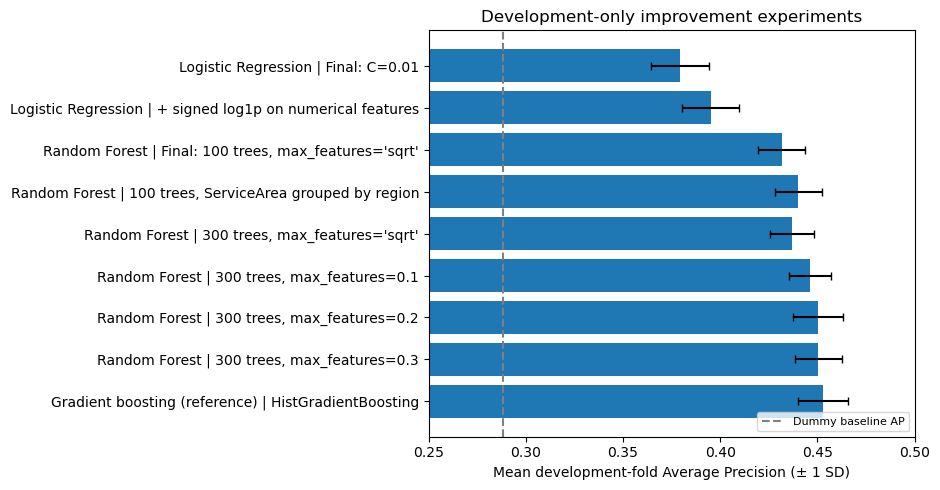


Section 14 fitting-warning summary:
Final: C=0.01: no recorded fitting warnings
+ signed log1p on numerical features: no recorded fitting warnings
Final: 100 trees, max_features='sqrt': no recorded fitting warnings
100 trees, ServiceArea grouped by region: no recorded fitting warnings
300 trees, max_features='sqrt': no recorded fitting warnings
300 trees, max_features=0.1: no recorded fitting warnings
300 trees, max_features=0.2: no recorded fitting warnings
300 trees, max_features=0.3: no recorded fitting warnings
HistGradientBoosting: no recorded fitting warnings


100 trees, ServiceArea grouped by region: mean AP=0.4402


No fitting warnings: 300 trees, max_features='sqrt'


300 trees, max_features='sqrt': mean AP=0.4369


No fitting warnings: 300 trees, max_features=0.1


...

No fitting warnings: 300 trees, max_features=0.3


300 trees, max_features=0.3: mean AP=0.4506


No fitting warnings: HistGradientBoosting


HistGradientBoosting: mean AP=0.4528


,Model,Configuration,CV_AP_mean,CV_AP_sd,CV_ROC_AUC_mean,Fit_seconds_total,Warning_count_total,AP_change_vs_final,Folds_improved
0,Logistic Regression,Final: C=0.01,0.3793,0.0148,0.6177,2.8060,0,0.0000,0
1,Logistic Regression,+ signed log1p on numerical features,0.3950,0.0146,0.6259,2.9838,0,0.0157,5
2,Random Forest,"Final: 100 trees, max_features='sqrt'",0.4317,0.0120,0.6632,8.1361,0,0.0000,0
3,Random Forest,"100 trees, ServiceArea grouped by region",0.4402,0.0121,0.6676,11.2176,0,0.0086,5
4,Random Forest,"300 trees, max_features='sqrt'",0.4369,0.0112,0.6666,22.8662,0,0.0052,5
5,Random Forest,"300 trees, max_features=0.1",0.4461,0.0110,0.6724,39.4265,0,0.0145,5
6,Random Forest,"300 trees, max_features=0.2",0.4502,0.0127,0.6746,72.7436,0,0.0186,5
7,Random Forest,"300 trees, max_features=0.3",0.4506,0.0122,0.6750,146.3464,0,0.0189,5
8,Gradient boosting (reference),HistGradientBoosting,0.4528,0.0129,0.6759,36.1203,0,0.0212,5


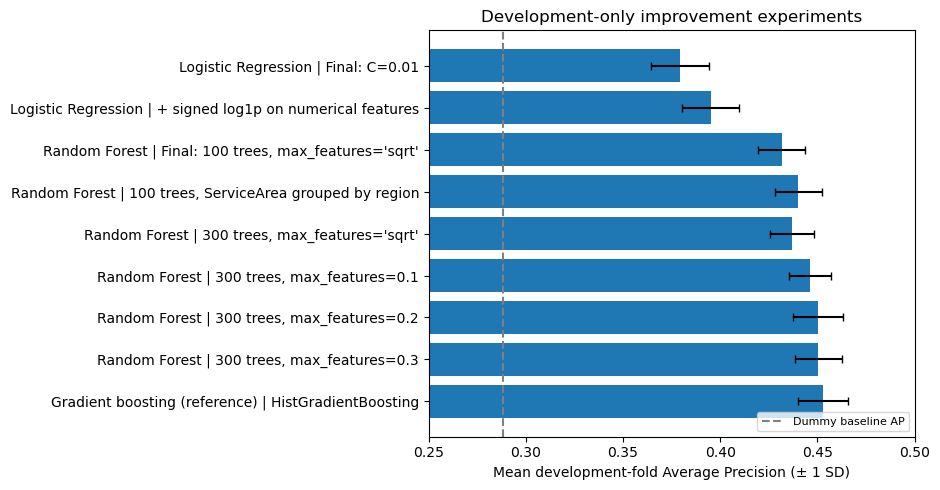


Section 14 fitting-warning summary:
Final: C=0.01: no recorded fitting warnings
+ signed log1p on numerical features: no recorded fitting warnings
Final: 100 trees, max_features='sqrt': no recorded fitting warnings
100 trees, ServiceArea grouped by region: no recorded fitting warnings
300 trees, max_features='sqrt': no recorded fitting warnings
300 trees, max_features=0.1: no recorded fitting warnings
300 trees, max_features=0.2: no recorded fitting warnings
300 trees, max_features=0.3: no recorded fitting warnings
HistGradientBoosting: no recorded fitting warnings


In [129]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import FunctionTransformer


def signed_log1p(values):
    """Compress long right tails while preserving zero and negative signs."""
    return np.sign(values) * np.log1p(np.abs(values))


def to_dense(matrix):
    """Convert sparse input to a dense array for HistGradientBoosting."""
    return matrix.toarray() if sparse.issparse(matrix) else matrix


class ServiceAreaRegion(TransformerMixin, BaseEstimator):
    """Replace ServiceArea codes with their first three letters."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        grouped = X.copy()
        area = grouped["ServiceArea"]
        grouped["ServiceArea"] = (
            area.astype("string")
            .str[:3]
            .astype(object)
            .where(area.notna(), np.nan)
        )
        return grouped


def logistic_with_signed_log():
    """Logistic Regression with signed log1p before numerical scaling."""
    model = clone(
        s10_selected_templates["Logistic Regression"]
    ).set_params(classifier__max_iter=5000)

    numeric_pipeline = model.named_steps["preprocessor"].transformers[0][1]

    numeric_pipeline.steps.insert(
        1,
        (
            "signed_log",
            FunctionTransformer(
                signed_log1p,
                feature_names_out="one-to-one",
            ),
        ),
    )

    return model


def forest_with(
    n_estimators=100,
    max_features="sqrt",
    group_regions=False,
):
    """Build a Random Forest candidate."""
    model = clone(
        s10_selected_templates["Random Forest"]
    ).set_params(
        classifier__n_estimators=n_estimators,
        classifier__max_features=max_features,
    )

    if group_regions:
        model.steps.insert(
            1,
            ("service_area_region", ServiceAreaRegion()),
        )

    return model


def gradient_boosting():
    """Build a histogram-based gradient boosting reference candidate."""
    return Pipeline(
        [
            ("structural_cleaning", Cell2CellStructuralCleaner()),
            ("preprocessor", make_preprocessor("random_forest")),
            (
                "to_dense",
                FunctionTransformer(to_dense, accept_sparse=True),
            ),
            (
                "classifier",
                HistGradientBoostingClassifier(
                    learning_rate=0.05,
                    max_iter=400,
                    max_leaf_nodes=31,
                    min_samples_leaf=50,
                    l2_regularization=1.0,
                    early_stopping=True,
                    validation_fraction=0.1,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# (model family, configuration, reference family, model factory)
s14_improvement_candidates = [
    (
        "Logistic Regression",
        "Final: C=0.01",
        "Logistic Regression",
        lambda: clone(
            s10_selected_templates["Logistic Regression"]
        ).set_params(classifier__max_iter=5000),
    ),
    (
        "Logistic Regression",
        "+ signed log1p on numerical features",
        "Logistic Regression",
        logistic_with_signed_log,
    ),
    (
        "Random Forest",
        "Final: 100 trees, max_features='sqrt'",
        "Random Forest",
        forest_with,
    ),
    (
        "Random Forest",
        "100 trees, ServiceArea grouped by region",
        "Random Forest",
        lambda: forest_with(group_regions=True),
    ),
    (
        "Random Forest",
        "300 trees, max_features='sqrt'",
        "Random Forest",
        lambda: forest_with(300, "sqrt"),
    ),
    (
        "Random Forest",
        "300 trees, max_features=0.1",
        "Random Forest",
        lambda: forest_with(300, 0.1),
    ),
    (
        "Random Forest",
        "300 trees, max_features=0.2",
        "Random Forest",
        lambda: forest_with(300, 0.2),
    ),
    (
        "Random Forest",
        "300 trees, max_features=0.3",
        "Random Forest",
        lambda: forest_with(300, 0.3),
    ),
    (
        "Gradient boosting (reference)",
        "HistGradientBoosting",
        "Random Forest",
        gradient_boosting,
    ),
]


# Evaluate every candidate using the same development folds.
s14_improvement_rows = []
s14_fold_ap = {}
s14_warning_details = {}

for family, configuration, reference, make_model in s14_improvement_candidates:

    folds, _ = cross_validate_pipeline(
        make_model,
        X_dev_primary,
        y_dev,
        cv_splits,
    )

    # Record warnings without stopping the remaining experiments.
    warning_count = folds["Warning_count"].fillna(0)

    if warning_count.gt(0).any():
        warning_rows = folds.loc[
            warning_count.gt(0),
            ["Fold", "Warning_count"],
        ]

        s14_warning_details[configuration] = warning_rows.to_dict(
            "records"
        )

        print(
            f"WARNING: {configuration}: "
            f"{s14_warning_details[configuration]}",
            flush=True,
        )
    else:
        s14_warning_details[configuration] = []
        print(
            f"No fitting warnings: {configuration}",
            flush=True,
        )

    s14_fold_ap[configuration] = (
        folds.set_index("Fold")["average_precision"]
    )

    s14_improvement_rows.append(
        {
            "Model": family,
            "Configuration": configuration,
            "Reference": reference,
            "CV_AP_mean": folds["average_precision"].mean(),
            "CV_AP_sd": folds["average_precision"].std(ddof=1),
            "CV_ROC_AUC_mean": folds["roc_auc"].mean(),
            "Fit_seconds_total": folds["Fit_seconds"].sum(),
            "Warning_count_total": int(warning_count.sum()),
        }
    )

    print(
        f"{configuration}: "
        f"mean AP={folds['average_precision'].mean():.4f}",
        flush=True,
    )


# Compare Average Precision against the reference configuration
# for the same algorithm.
s14_improvement = pd.DataFrame(s14_improvement_rows)

final_names = {
    "Logistic Regression": "Final: C=0.01",
    "Random Forest": "Final: 100 trees, max_features='sqrt'",
}

s14_reference_ap = s14_improvement.set_index("Configuration")[
    "CV_AP_mean"
]

s14_improvement["AP_change_vs_final"] = [
    row.CV_AP_mean
    - s14_reference_ap.loc[final_names[row.Reference]]
    for row in s14_improvement.itertuples()
]

s14_improvement["Folds_improved"] = [
    int(
        (
            s14_fold_ap[row.Configuration]
            > s14_fold_ap[final_names[row.Reference]]
        ).sum()
    )
    for row in s14_improvement.itertuples()
]


# Display results.
display(
    s14_improvement.drop(columns="Reference").round(4)
)


# Plot development-only experiment results.
fig, ax = plt.subplots(figsize=(9.5, 5))

labels = [
    f"{model} | {configuration}"
    for model, configuration in zip(
        s14_improvement["Model"],
        s14_improvement["Configuration"],
    )
]

ax.barh(
    labels,
    s14_improvement["CV_AP_mean"],
    xerr=s14_improvement["CV_AP_sd"],
    capsize=3,
)

ax.axvline(
    float(
        baseline_cv_summary.loc[
            "average_precision",
            "CV_mean",
        ]
    ),
    linestyle="--",
    color="grey",
    label="Dummy baseline AP",
)

ax.invert_yaxis()

ax.set(
    xlabel="Mean development-fold Average Precision (± 1 SD)",
    xlim=(0.25, 0.5),
    title="Development-only improvement experiments",
)

ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


# Final diagnostic summary for this section.
print("\nSection 14 fitting-warning summary:")

for configuration, warning_details in s14_warning_details.items():
    if warning_details:
        print(f"{configuration}: {warning_details}")
    else:
        print(f"{configuration}: no recorded fitting warnings")

**Findings.** Every candidate improved on the final configuration of its algorithm in **all five folds**, but by different amounts:

- **Random Forest `max_features` gave the largest gain.** With 300 trees, raising `max_features` from `'sqrt'` (about 19 columns per split) to 0.2–0.3 (about 75–110 columns) increased mean AP from **0.4317** (final model) to **0.4502–0.4506** (+0.019) and ROC-AUC from **0.6632** to **0.6750**. More trees alone account for only +0.005 of this. Grouping `ServiceArea` into 57 metro regions also helped (+0.009 AP with the final settings). This is consistent with the explanation that sparse `ServiceArea` columns crowded the informative features out of each split's random subset, although the experiment does not isolate that mechanism.
- **A signed log transform helped Logistic Regression.** Mean AP rose from **0.3793** to **0.3950** (+0.016) and ROC-AUC from **0.6177** to **0.6259**, which suggests that the skewed raw features limited this Logistic Regression configuration.
- **Gradient boosting reached about the same ceiling** as the re-tuned forest: AP **0.4528**, ROC-AUC **0.6759**. Even the best model ranks churners only moderately (ROC-AUC ≈ 0.68). One plausible explanation is that the available features carry limited information about churn; with only one additional algorithm and a small, untuned search, this remains a hypothesis rather than an established limit.

These are development-fold estimates from a post-hoc comparison of several configurations, so they are likely to be optimistic and say nothing about test performance. The fair next step is to include `max_features`, the log transform and region grouping in a fresh tuning run and evaluate the result on new labelled customers.

### 14.10 Missingness Indicators: Duplicated Columns and Possible Timing Leakage

The pipelines add a binary indicator for each numerical feature that has missing values in the training fold. Two issues deserve a closer look:

1. **Duplicated indicators.** Several features are missing for exactly the same customers, so their indicators are identical columns.
2. **Missingness as a timing signal.** Section 4.8 found that customers with a missing `PercChangeMinutes` churn far more often than average. If a value is missing *because* the customer was already leaving (for example, too little recent usage to compute a change), the indicator carries information from close to the churn event: the same timing concern raised for the retention fields.

Like Section 14.9, this diagnostic was run after the test evaluation; it uses development data only and does not change the final models.

In [130]:
# 1) Which missingness indicators are exact duplicates?
dev_clean = Cell2CellStructuralCleaner().fit_transform(X_dev_primary)
dev_missing = dev_clean[NUMERIC_FEATURES].isna()
dev_missing = dev_missing.loc[:, dev_missing.any()]
pattern_groups = {}
for column in dev_missing.columns:
    pattern_groups.setdefault(tuple(dev_missing[column]), []).append(column)
s14_missing_patterns = pd.DataFrame(
    [
        {
            "Identical indicator columns": ", ".join(cols),
            "Indicators": len(cols),
            "Customers_missing": int(dev_missing[cols[0]].sum()),
            "Churn_rate_pct": 100 * y_dev[dev_missing[cols[0]]].mean(),
        }
        for cols in pattern_groups.values()
    ]
).sort_values("Customers_missing", ascending=False, ignore_index=True)
display(s14_missing_patterns.round(1))
print(
    f"{dev_missing.shape[1]} indicator columns, {len(pattern_groups)} distinct missingness patterns"
)

# 2) Who are the customers with missing percentage-change values?
pc_missing = dev_clean["PercChangeMinutes"].isna()
billing_missing = dev_clean["MonthlyRevenue"].isna()
profile_cols = ["MonthsInService", "MonthlyMinutes", "MonthlyRevenue", "CurrentEquipmentDays"]
s14_missing_profile = pd.DataFrame(
    {
        "PercChange missing": dev_clean.loc[pc_missing, profile_cols].median(),
        "PercChange recorded": dev_clean.loc[~pc_missing, profile_cols].median(),
    }
).T
s14_missing_profile["Zero_minutes_pct"] = [
    100 * dev_clean.loc[pc_missing, "MonthlyMinutes"].eq(0).mean(),
    100 * dev_clean.loc[~pc_missing, "MonthlyMinutes"].eq(0).mean(),
]
s14_missing_profile["Churn_rate_pct"] = [
    100 * y_dev[pc_missing].mean(),
    100 * y_dev[~pc_missing].mean(),
]
display(s14_missing_profile.round(1))
only_change_missing = pc_missing & ~billing_missing
print(
    f"PercChange missing but billing recorded: n={int(only_change_missing.sum())}, "
    f"churn rate {100 * y_dev[only_change_missing].mean():.1f}%"
)


# 3) How much do the final models rely on the missingness indicators? (same five development folds)
def without_missing_flags(model):
    """Remove the missingness-indicator branch from a pipeline's preprocessor."""
    preprocessor = model.named_steps["preprocessor"]
    preprocessor.transformers = [t for t in preprocessor.transformers if t[0] != "missing_flags"]
    return model


s14_flag_rows = []
for name in S13_ALGORITHMS:
    folds, _ = cross_validate_pipeline(
        lambda n=name: without_missing_flags(clone(s10_selected_templates[n])),
        X_dev_primary,
        y_dev,
        cv_splits,
    )
    final = s14_improvement.set_index("Configuration").loc[final_names[name]]
    s14_flag_rows.append(
        {
            "Algorithm": name,
            "AP_with_indicators": final["CV_AP_mean"],
            "AP_without_indicators": folds["average_precision"].mean(),
            "AP_change": folds["average_precision"].mean() - final["CV_AP_mean"],
            "ROC_AUC_with": final["CV_ROC_AUC_mean"],
            "ROC_AUC_without": folds["roc_auc"].mean(),
        }
    )
display(pd.DataFrame(s14_flag_rows).round(4))

,Identical indicator columns,Indicators,Customers_missing,Churn_rate_pct
0,HandsetPrice,1,23214,30.0
1,"AgeHH1, AgeHH2",2,716,27.8
2,"PercChangeMinutes, PercChangeRevenues",2,290,56.9
3,"MonthlyRevenue, MonthlyMinutes, TotalRecurring...",6,120,45.8
4,CurrentEquipmentDays,1,56,23.2
5,"Handsets, HandsetModels",2,1,0.0


14 indicator columns, 6 distinct missingness patterns


,MonthsInService,MonthlyMinutes,MonthlyRevenue,CurrentEquipmentDays,Zero_minutes_pct,Churn_rate_pct
PercChange missing,26.0,194.0,33.5,480.5,11.0,56.9
PercChange recorded,16.0,368.0,48.6,329.0,1.3,28.6


PercChange missing but billing recorded: n=170, churn rate 64.7%


,Algorithm,AP_with_indicators,AP_without_indicators,AP_change,ROC_AUC_with,ROC_AUC_without
0,Logistic Regression,0.3793,0.3756,-0.0038,0.6177,0.6148
1,Random Forest,0.4317,0.4269,-0.0047,0.6632,0.6600


**Findings.**

- **Duplicated indicators.** Across the development data, 14 numerical features have missing values, but they form only **6 distinct missingness patterns** (each training fold learns 12–14 indicators, depending on whether the single customer missing `Handsets` falls in it): the six billing and usage fields are missing for the same 120 customers, `PercChangeMinutes`/`PercChangeRevenues` for the same 290, `AgeHH1`/`AgeHH2` for the same 716, and `Handsets`/`HandsetModels` for a single customer. These duplicates can affect both models. Random Forest samples columns at each split (`max_features='sqrt'`, about 19 of roughly 370 columns), and a duplicated indicator occupies more than one position in that sample, so the same information is offered to splits more often than a single column would be; this changes which trees are grown. For Logistic Regression, the L2 penalty spreads one effect across identical columns: the two percentage-change indicators (+0.2843 each) act together as about **+0.57** in log-odds. Spreading an effect over two columns also lowers its total penalty, so the fitted coefficients, and potentially the predictions, can differ from a model with a single indicator. The size of these effects was not isolated, because the experiment below removes all indicators rather than only the duplicates. A cleaner design would create one indicator per missingness pattern.
- **Possible timing leakage.** Customers with missing percentage-change values churn at **56.9%**, and those whose billing *is* recorded but whose change values are missing churn at **64.7%**, against 28.8% overall. They have longer tenure (median 26 vs 16 months), about half the monthly minutes (194 vs 368) and far more zero-usage records (11.0% vs 1.3%). This pattern fits customers who were already reducing usage before leaving, so the missingness itself may partly record the approach of churn. The documentation does not state the change window, so this cannot be confirmed.
- **How much the models rely on it.** Removing all missingness indicators lowers development AP only slightly (Logistic Regression 0.3793 → 0.3756; Random Forest 0.4317 → 0.4269). On development data, the algorithm comparison therefore does not depend on this signal, but the indicators would need the same timing review as the percentage-change fields before deployment.

**Summary of Section 14.** Random Forest makes fewer false alarms than Logistic Regression and is right more often when the two disagree. Both models rely mainly on handset age, usage and tenure. Their scores show reasonable aggregate reliability (the mean score matches the churn rate and the Brier score beats a constant prediction), but calibration is imperfect across score ranges, and churners and non-churners overlap heavily in score, which limits how cleanly any threshold can separate them. The post-evaluation experiments on development data suggest that further gains may be possible (up to about +0.02 AP in the development folds), and that the missingness signal deserves a timing review before deployment.

## 15. Predictions for the Unlabelled Holdout Customers

The separate holdout file contains 20,000 customers with no churn outcome. It is used to demonstrate how the final models would be applied to new customers: checking that the input data is compatible, producing risk scores and contact lists, and exporting the predictions. Because the true outcomes are unknown, these predictions cannot be evaluated.

### 15.1 Setup

The two final pipelines from Section 13 are applied unchanged, with the same 53 features, fitted preprocessing and thresholds (0.25 for Logistic Regression, 0.27 for Random Forest). Nothing is refitted on the holdout data. Random Forest is used as the main ranking model, and Logistic Regression for comparison.

In [131]:
# Holdout settings: the final models, their thresholds, and the output file name.
S15_ALGORITHMS = tuple(S13_ALGORITHMS)
S15_PRIMARY_ALGORITHM = "Random Forest"
S15_FEATURES = tuple(S13_PRIMARY_FEATURES)
S15_CAPACITIES = (0.10, 0.20)
S15_EXPECTED_ROWS = 20000
S15_OUTPUT_NAME = "Cell2Cell_Section15_Holdout_Predictions.csv"
assert S15_PRIMARY_ALGORITHM in S15_ALGORITHMS
assert len(S15_FEATURES) == 53 and S15_FEATURES == tuple(X_dev_primary.columns)
assert all(
    np.array_equal(s13_fitted_models[name].named_steps["classifier"].classes_, [0, 1])
    for name in S15_ALGORITHMS
)
print("Input feature count:", len(S15_FEATURES), "| Thresholds:", s13_thresholds)

Input feature count: 53 | Thresholds: {'Logistic Regression': 0.25, 'Random Forest': 0.27}


### 15.2 Checking the Holdout File

The holdout file is checked to confirm that it has the expected 20,000 customers and 58 columns, that every `Churn` value is empty, that the customer IDs are unique, and that none of them appears in the labelled data.

In [132]:
# Check the holdout file before scoring it.
assert holdout_raw.shape[0] == S15_EXPECTED_ROWS
assert list(holdout_raw.columns) == list(train_raw.columns), "Unexpected source CSV schema."
assert (
    TARGET_COL in holdout_raw.columns and holdout_raw[TARGET_COL].isna().all()
), "The external holdout must contain no observed Churn labels."
assert ID_COL in holdout_raw.columns
assert holdout_raw[ID_COL].notna().all() and holdout_raw[ID_COL].is_unique
assert train_raw[ID_COL].is_unique
assert set(holdout_raw[ID_COL]).isdisjoint(
    set(train_raw[ID_COL])
), "Holdout customer IDs overlap the labelled dataset."
assert len(set(S15_FEATURES) & {TARGET_COL, ID_COL, *RETENTION_EXCLUSIONS}) == 0
assert set(S15_FEATURES).issubset(holdout_raw.columns)

s15_ids = holdout_raw[ID_COL].copy()
s15_X = holdout_raw.loc[:, list(S15_FEATURES)].copy()
assert s15_X.shape == (S15_EXPECTED_ROWS, 53)
assert s15_X.index.equals(s15_ids.index)
s15_file_overview = pd.DataFrame(
    [
        {
            "Dataset": "Labelled train (all)",
            "Rows": len(train_raw),
            "Source_columns": train_raw.shape[1],
            "Observed_churn_labels": int(train_raw[TARGET_COL].notna().sum()),
            "Unique_IDs": int(train_raw[ID_COL].nunique()),
        },
        {
            "Dataset": "External unlabelled holdout",
            "Rows": len(holdout_raw),
            "Source_columns": holdout_raw.shape[1],
            "Observed_churn_labels": int(holdout_raw[TARGET_COL].notna().sum()),
            "Unique_IDs": int(holdout_raw[ID_COL].nunique()),
        },
    ]
)
display(s15_file_overview)
print(
    f"Holdout file: {len(s15_ids):,} unique customers, no churn labels, {s15_X.shape[1]} model inputs."
)

,Dataset,Rows,Source_columns,Observed_churn_labels,Unique_IDs
0,Labelled train (all),51047,58,51047,51047
1,External unlabelled holdout,20000,58,0,20000


Holdout file: 20,000 unique customers, no churn labels, 53 model inputs.


### 15.3 Comparison of Holdout and Development Data

Missing-value rates after the structural cleaning step are compared with the development data, and the holdout is checked for category values that the fitted encoders never saw during training.

In [133]:
# Compare missing-value rates with the development data, and look for category values unseen in training.
s15_cleaner = s13_fitted_models[S15_PRIMARY_ALGORITHM].named_steps["structural_cleaning"]
s15_clean_holdout = s15_cleaner.transform(s15_X)
s15_clean_dev = s15_cleaner.transform(X_dev_primary.loc[:, list(S15_FEATURES)])
assert s15_clean_holdout.columns.tolist() == list(S15_FEATURES)
assert s15_clean_dev.columns.tolist() == list(S15_FEATURES)
s15_missing = pd.DataFrame(
    {
        "Feature": S15_FEATURES,
        "Development_missing_pct": [100 * s15_clean_dev[c].isna().mean() for c in S15_FEATURES],
        "Holdout_missing_pct": [100 * s15_clean_holdout[c].isna().mean() for c in S15_FEATURES],
    }
)
s15_missing["Difference_pp"] = (
    s15_missing["Holdout_missing_pct"] - s15_missing["Development_missing_pct"]
)
s15_missing["Absolute_difference_pp"] = s15_missing["Difference_pp"].abs()
s15_missing = s15_missing.sort_values("Absolute_difference_pp", ascending=False).reset_index(
    drop=True
)
display(s15_missing.head(10).round(2))

s15_prep = s13_fitted_models[S15_PRIMARY_ALGORITHM].named_steps["preprocessor"]
s15_unknown_records = []
for transformer_name, columns in [
    ("categorical", CATEGORICAL_FEATURES),
    ("service_area", SERVICE_AREA_FEATURES),
]:
    encoder = s15_prep.named_transformers_[transformer_name].named_steps["encoder"]
    for col, training_levels in zip(columns, encoder.categories_):
        observed = (
            s15_clean_holdout[col].astype("object").where(s15_clean_holdout[col].notna(), "Missing")
        )
        # Same non-null categorical strings used by the pipeline's constant imputer.
        known = set(map(str, training_levels))
        unseen = ~observed.astype(str).isin(known)
        s15_unknown_records.append(
            {
                "Feature": col,
                "Encoder_group": transformer_name,
                "Holdout_unseen_n": int(unseen.sum()),
                "Holdout_unseen_pct": float(100 * unseen.mean()),
                "Unseen_examples": ", ".join(sorted(map(str, observed[unseen].unique()))[:3]),
            }
        )
s15_unseen = (
    pd.DataFrame(s15_unknown_records)
    .sort_values(["Holdout_unseen_n", "Feature"], ascending=[False, True])
    .reset_index(drop=True)
)
display(s15_unseen.head(10).round(2))
print(
    "Features containing unseen holdout category levels:",
    int((s15_unseen.Holdout_unseen_n > 0).sum()),
    "of",
    len(s15_unseen),
)

,Feature,Development_missing_pct,Holdout_missing_pct,Difference_pp,Absolute_difference_pp
0,HandsetPrice,56.85,56.34,-0.51,0.51
1,AgeHH2,1.75,1.68,-0.08,0.08
2,AgeHH1,1.75,1.68,-0.08,0.08
3,PercChangeMinutes,0.71,0.68,-0.04,0.04
4,PercChangeRevenues,0.71,0.68,-0.04,0.04
5,ServiceArea,0.05,0.02,-0.03,0.03
6,CurrentEquipmentDays,0.14,0.16,0.02,0.02
7,MonthlyRevenue,0.29,0.30,0.01,0.01
8,TotalRecurringCharge,0.29,0.30,0.01,0.01
9,DirectorAssistedCalls,0.29,0.30,0.01,0.01


,Feature,Encoder_group,Holdout_unseen_n,Holdout_unseen_pct,Unseen_examples
0,ServiceArea,service_area,43,0.22,"ATLDBL478, CHICLI319, CHILIN217"
1,BuysViaMailOrder,categorical,0,0.00,
2,ChildrenInHH,categorical,0,0.00,
3,CreditRating,categorical,0,0.00,
4,HandsetRefurbished,categorical,0,0.00,
5,HandsetWebCapable,categorical,0,0.00,
6,HasCreditCard,categorical,0,0.00,
7,Homeownership,categorical,0,0.00,
8,IncomeGroup,categorical,0,0.00,
9,MaritalStatus,categorical,0,0.00,


Features containing unseen holdout category levels: 1 of 21


The holdout data closely resembles the development data. Missing-value rates differ by at most half a percentage point (`HandsetPrice`: 56.85% vs 56.34%). Only `ServiceArea` contains new values: **43 holdout customers (0.22%)** have an area code not seen in development, and the encoder maps these to the infrequent category as designed. All other categorical features contain only known values.

### 15.4 Scoring the Holdout Customers

Each pipeline produces one churn probability per holdout customer, which is then compared with that model's threshold.

In [134]:
# Score every holdout customer with both final pipelines (no refitting).
s15_scores = {}
s15_flags = {}
s15_default_flags = {}
for algorithm in S15_ALGORITHMS:
    fitted = s13_fitted_models[algorithm]  # already fitted in Section 13
    positive_idx = int(
        np.flatnonzero(fitted.named_steps["classifier"].classes_ == POSITIVE_CLASS)[0]
    )
    probability = np.asarray(fitted.predict_proba(s15_X)[:, positive_idx], dtype=float)
    default = np.asarray(fitted.predict(s15_X), dtype=int)
    selected = (probability > s13_thresholds[algorithm]).astype("int8")
    assert len(probability) == len(s15_X) and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    assert set(np.unique(default)).issubset({0, 1}) and set(np.unique(selected)).issubset({0, 1})
    s15_scores[algorithm] = probability
    s15_flags[algorithm] = selected
    s15_default_flags[algorithm] = default

s15_score_summary = pd.DataFrame(
    [
        {
            "Algorithm": name,
            "N": len(s15_scores[name]),
            "Mean_score": float(s15_scores[name].mean()),
            "Median_score": float(np.median(s15_scores[name])),
            "P90_score": float(np.quantile(s15_scores[name], 0.90)),
            "P99_score": float(np.quantile(s15_scores[name], 0.99)),
            "Flagged_n": int(s15_flags[name].sum()),
            "Flagged_pct": float(100 * s15_flags[name].mean()),
            "Default_flagged_n": int(s15_default_flags[name].sum()),
        }
        for name in S15_ALGORITHMS
    ]
)
display(s15_score_summary.round(4))

,Algorithm,N,Mean_score,Median_score,P90_score,P99_score,Flagged_n,Flagged_pct,Default_flagged_n
0,Logistic Regression,20000,0.2880,0.2829,0.3937,0.5105,13315,66.575,251
1,Random Forest,20000,0.2893,0.2912,0.3881,0.5037,12013,60.065,211


At its threshold of 0.27, Random Forest flags **12,013 of 20,000** holdout customers (**60.1%**); Logistic Regression flags **13,315 (66.6%)** at 0.25. These shares match the test set closely (59.8% and 67.2%), and the mean scores (0.289 and 0.288) match the training churn rate. As on the test set, the default 0.5 rule would flag only 211 and 251 customers. These are model predictions, not observed churn.

### 15.5 Contact Lists and Model Agreement

Following the recommendation in Section 13.7, Random Forest contact lists are produced for the **top 10% (2,000)** and **top 20% (4,000)** holdout customers by risk score. Ties are broken by the original row order, so the lists are reproducible. The number of customers that the two models share among their 2,000 highest-risk customers is also checked.

In [135]:
# Random Forest risk ranks and top-10% / top-20% contact lists; ties keep the original row order.
s15_n = len(s15_X)
s15_rank_order = np.argsort(-s15_scores[S15_PRIMARY_ALGORITHM], kind="stable")
s15_rank = np.empty(s15_n, dtype=int)
s15_rank[s15_rank_order] = np.arange(1, s15_n + 1)
s15_top_flags = {}
for capacity in S15_CAPACITIES:
    k = int(np.ceil(capacity * s15_n))
    indicator = np.zeros(s15_n, dtype="int8")
    indicator[s15_rank_order[:k]] = 1
    s15_top_flags[capacity] = indicator
assert s15_top_flags[0.10].sum() == 2000
assert s15_top_flags[0.20].sum() == 4000
assert (s15_top_flags[0.10] <= s15_top_flags[0.20]).all()

s15_lr_top = set(np.argsort(-s15_scores["Logistic Regression"], kind="stable")[:2000])
s15_rf_top = set(s15_rank_order[:2000])
s15_top_overlap = len(s15_lr_top & s15_rf_top)
s15_prioritisation = pd.DataFrame(
    [
        {
            "Scenario": "RF top 10%",
            "Targeted_customers": 2000,
            "Share_pct": 10.0,
            "Outcome_labels_available": False,
        },
        {
            "Scenario": "RF top 20%",
            "Targeted_customers": 4000,
            "Share_pct": 20.0,
            "Outcome_labels_available": False,
        },
    ]
)
display(s15_prioritisation)
print(f"LR/RF top-10% overlap: {s15_top_overlap}/2,000 ({100*s15_top_overlap/2000:.2f}%).")

,Scenario,Targeted_customers,Share_pct,Outcome_labels_available
0,RF top 10%,2000,10.0,False
1,RF top 20%,4000,20.0,False


LR/RF top-10% overlap: 690/2,000 (34.50%).


The two models agree on only **690 of their top-2,000 customers (34.5%)**, even though their overall flag rates are similar. Their rankings differ considerably at the very top, so the choice of model has a real effect on *which* customers a campaign would contact. Since Random Forest ranked churners better on the test set, its list is the one recommended for use.

### 15.6 Comparing Holdout and Test Score Distributions

The holdout score distributions are compared with the test-set scores from Section 13 (scores only; no labels are used), and the medians of key input features are compared with the development data.

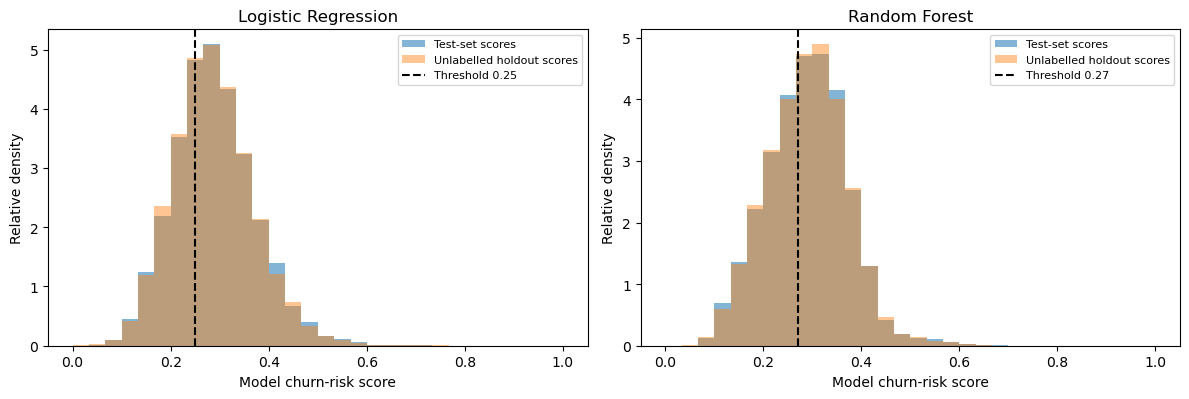

,Algorithm,Partition,Customers,Mean_score,Median_score,Share_above_threshold_pct
0,Logistic Regression,Section 13 labelled test (scores only),10210,0.2892,0.2834,67.1596
1,Logistic Regression,Unlabelled holdout,20000,0.2880,0.2829,66.5750
2,Random Forest,Section 13 labelled test (scores only),10210,0.2891,0.2910,59.7649
3,Random Forest,Unlabelled holdout,20000,0.2893,0.2912,60.0650


,Feature,Development_median,Holdout_median,Median_difference,Median_shift_over_dev_IQR
0,MonthlyMinutes,367.00,365.000,-2.000,-0.004
1,MonthlyRevenue,48.47,48.665,0.195,0.005
2,MonthsInService,16.00,16.000,0.000,0.000
3,CurrentEquipmentDays,330.00,331.000,1.000,0.003
4,PercChangeMinutes,-6.00,-4.000,2.000,0.014
5,PercChangeRevenues,-0.30,-0.300,0.000,0.000


In [136]:
# Compare holdout score distributions with the test-set scores, and key input medians with development data.
s15_reference_records = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
for axis, algorithm in zip(axes, S15_ALGORITHMS):
    reference = s13_test_predictions[algorithm]["Churn_probability"].to_numpy(dtype=float)
    hold = s15_scores[algorithm]
    s15_reference_records.append(
        {
            "Algorithm": algorithm,
            "Partition": "Section 13 labelled test (scores only)",
            "Customers": len(reference),
            "Mean_score": float(reference.mean()),
            "Median_score": float(np.median(reference)),
            "Share_above_threshold_pct": float(
                100 * (reference > s13_thresholds[algorithm]).mean()
            ),
        }
    )
    s15_reference_records.append(
        {
            "Algorithm": algorithm,
            "Partition": "Unlabelled holdout",
            "Customers": len(hold),
            "Mean_score": float(hold.mean()),
            "Median_score": float(np.median(hold)),
            "Share_above_threshold_pct": float(100 * (hold > s13_thresholds[algorithm]).mean()),
        }
    )
    axis.hist(
        reference,
        bins=np.linspace(0, 1, 31),
        alpha=0.55,
        density=True,
        label="Test-set scores",
    )
    axis.hist(
        hold,
        bins=np.linspace(0, 1, 31),
        alpha=0.45,
        density=True,
        label="Unlabelled holdout scores",
    )
    axis.axvline(
        s13_thresholds[algorithm],
        linestyle="--",
        color="black",
        label=f"Threshold {s13_thresholds[algorithm]:.2f}",
    )
    axis.set(xlabel="Model churn-risk score", ylabel="Relative density", title=algorithm)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()
s15_score_comparison = pd.DataFrame(s15_reference_records)
display(s15_score_comparison.round(4))

s15_numeric_compare = []
for feature in [
    "MonthlyMinutes",
    "MonthlyRevenue",
    "MonthsInService",
    "CurrentEquipmentDays",
    "PercChangeMinutes",
    "PercChangeRevenues",
]:
    ref = pd.to_numeric(s15_clean_dev[feature], errors="coerce").dropna()
    new = pd.to_numeric(s15_clean_holdout[feature], errors="coerce").dropna()
    iqr = float(ref.quantile(0.75) - ref.quantile(0.25))
    median_shift = float(new.median() - ref.median())
    s15_numeric_compare.append(
        {
            "Feature": feature,
            "Development_median": float(ref.median()),
            "Holdout_median": float(new.median()),
            "Median_difference": median_shift,
            "Median_shift_over_dev_IQR": float(median_shift / iqr) if iqr > 0 else np.nan,
        }
    )
s15_numeric_diagnostics = pd.DataFrame(s15_numeric_compare)
display(s15_numeric_diagnostics.round(3))

The holdout scores look almost identical to the test-set scores: Random Forest's mean is **0.289** in both, and the share above its threshold is **60.1%** against **59.8%**. Input medians barely differ (for example `MonthlyMinutes` 365 against 367, and `MonthsInService` 16 in both). This suggests the holdout customers come from the same population, so the test performance gives a reasonable expectation for them, although without labels this cannot be confirmed.

### 15.7 Exporting the Predictions

The predictions are saved to `data/Cell2Cell_Section15_Holdout_Predictions.csv`, one row per customer in the original order. The file contains the customer ID, both models' churn scores and threshold decisions, and the Random Forest risk rank with top-10% and top-20% flags. It contains no customer attributes. The code re-reads the file and checks that it matches the predictions exactly.

In [137]:
# Save one row per holdout customer, then re-read the file to check it matches.
s15_predictions = pd.DataFrame(
    {
        "CustomerID": s15_ids.to_numpy(),
        "RF_Churn_Score": s15_scores["Random Forest"],
        "RF_Predicted_Churn": s15_flags["Random Forest"],
        "RF_Risk_Rank": s15_rank,
        "RF_Top_10_Percent": s15_top_flags[0.10],
        "RF_Top_20_Percent": s15_top_flags[0.20],
        "LR_Churn_Score": s15_scores["Logistic Regression"],
        "LR_Predicted_Churn": s15_flags["Logistic Regression"],
    }
)
s15_output_path = DATA_DIR / S15_OUTPUT_NAME
s15_predictions.to_csv(s15_output_path, index=False, float_format="%.12g")
s15_exported = pd.read_csv(s15_output_path)
assert s15_output_path.exists()
assert s15_exported.shape == s15_predictions.shape
assert list(s15_exported.columns) == list(s15_predictions.columns)
assert s15_exported["CustomerID"].tolist() == s15_ids.tolist()
assert np.allclose(
    s15_exported["RF_Churn_Score"], s15_predictions["RF_Churn_Score"], rtol=0, atol=1e-11
)
assert np.allclose(
    s15_exported["LR_Churn_Score"], s15_predictions["LR_Churn_Score"], rtol=0, atol=1e-11
)
for name, column in [
    ("Random Forest", "RF_Predicted_Churn"),
    ("Logistic Regression", "LR_Predicted_Churn"),
]:
    assert np.array_equal(
        s15_exported[column], (s15_scores[name] > s13_thresholds[name]).astype(int)
    )
assert np.array_equal(np.sort(s15_exported["RF_Risk_Rank"]), np.arange(1, s15_n + 1))
print("Predictions saved to:", s15_output_path)
print("Rows:", len(s15_exported), "| Columns:", len(s15_exported.columns))
display(s15_predictions.head(6).round(6))

Predictions saved to: ../data/Cell2Cell_Section15_Holdout_Predictions.csv
Rows: 20000 | Columns: 8


,CustomerID,RF_Churn_Score,RF_Predicted_Churn,RF_Risk_Rank,RF_Top_10_Percent,RF_Top_20_Percent,LR_Churn_Score,LR_Predicted_Churn
0,3000006,0.194564,0,17388,0,0,0.111173,0
1,3000018,0.256645,0,13164,0,0,0.139161,0
2,3000034,0.262145,0,12701,0,0,0.248127,0
3,3000070,0.215484,0,16200,0,0,0.171367,0
4,3000074,0.222557,0,15729,0,0,0.118053,0
5,3000086,0.247417,0,13935,0,0,0.189482,0


The exported file contains **20,000 rows and 8 columns** and matches the in-memory predictions. Scores are stored to 12 significant digits; the decisions were made from the full-precision scores.

### 15.8 Findings

The final pipelines scored all 20,000 holdout customers without retraining. The input data matched the development data closely, and the only new category values were 43 unseen service areas, which the encoder handled as intended. Random Forest flagged 60.1% of customers at its F1 threshold and produced top-2,000 and top-4,000 contact lists; the two models agreed on only 34.5% of their top-2,000. Without outcomes, these are predictions to be acted on and later verified, not measured results.

## 16. Conclusions

This section draws the findings together: which of the two algorithms performs better and why, what the results mean for a retention team, what limits the conclusions, and what should be done next. No model is refitted here; every number comes from the earlier sections.

### 16.1 Final Models

The final models use the 53-feature main set and the preprocessing from Section 5: an unweighted Logistic Regression with `C = 0.01`, and an unweighted Random Forest with 100 trees, no depth limit and a minimum leaf size of 10. Their F1-based thresholds (0.25 and 0.27) were chosen on development data. Both were trained once on the 40,837 development customers and evaluated once on the 10,210 test customers. Models were compared mainly on Average Precision, with ROC-AUC, precision, recall, F1, MCC, balanced accuracy and fixed-capacity precision as supporting measures.

### 16.2 What Was Done

The aim of the project was to predict which wireless telecom customers would churn, using the Cell2Cell dataset of 51,047 labelled customers. After the data was audited, it was split into 40,837 development customers and 10,210 test customers. On the development data, the features were explored, a leakage-safe preprocessing pipeline was built, three feature sets were compared, and Logistic Regression and Random Forest were trained and tuned against a dummy baseline. Class weighting and decision thresholds were then studied, and the dependence of the results on features of uncertain timing was tested. Only after all of these decisions were fixed were the two final models evaluated once on the test set. Finally, their errors and feature importance were analysed, possible improvements were tested on development data, and the models were applied to 20,000 unlabelled customers.

### 16.3 Comparison of the Two Algorithms

The table brings together the development (cross-validation) and test results of both final models. Threshold-based measures use each model's F1 threshold. The dummy baseline column gives the values expected from a model that assigns every customer the same score and predicts "No churn" (Section 7); its Average Precision and top-10% precision equal the churn rate.

,Dummy baseline (expected),Logistic Regression,Random Forest
Measure,,,
CV Average Precision,0.2882,0.3793,0.4317
Test Average Precision,0.2881,0.3716,0.4283
Test ROC-AUC,0.5000,0.6114,0.6582
Precision,0.0000,0.3338,0.3623
Recall,0.0000,0.7780,0.7515
F1,0.0000,0.4672,0.4889
MCC,0.0000,0.1442,0.1997
Balanced accuracy,0.5000,0.5748,0.6081
Accuracy,0.7119,0.4886,0.5473


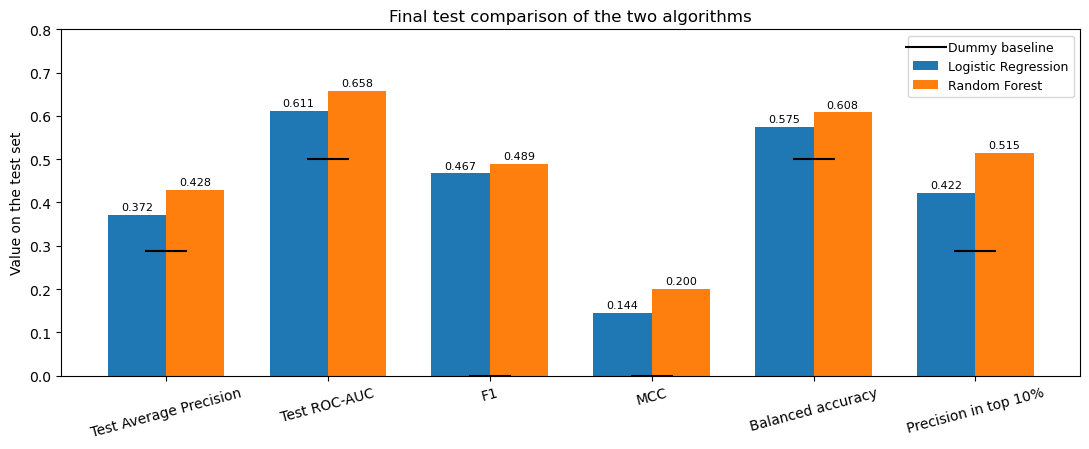

Random Forest minus Logistic Regression test AP: +0.0567 (95% bootstrap interval +0.040 to +0.070)


In [138]:
# Final comparison of the two algorithms, assembled from the Section 7, 13 and 14 results (nothing is refitted).
s16_prevalence = float(s13_ytest.mean())
s16_baseline = {
    "CV Average Precision": float(baseline_cv_summary.loc["average_precision", "CV_mean"]),
    "Test Average Precision": s16_prevalence,
    "Test ROC-AUC": 0.5,
    "Precision": 0.0,
    "Recall": 0.0,
    "F1": 0.0,
    "MCC": 0.0,
    "Balanced accuracy": 0.5,
    "Accuracy": 1 - s16_prevalence,
    "Share of customers flagged": 0.0,
    "Precision in top 10%": s16_prevalence,
    "Lift in top 10%": 1.0,
    "Brier score": s14_brier_baseline,
}
s16_columns = {"Dummy baseline (expected)": s16_baseline}
for algorithm in S13_ALGORITHMS:
    test = s13_test_table[
        (s13_test_table.Algorithm == algorithm) & (s13_test_table.Decision == "F1 threshold")
    ].iloc[0]
    top10 = s13_capacity_table[
        (s13_capacity_table.Algorithm == algorithm) & np.isclose(s13_capacity_table.Capacity, 0.10)
    ].iloc[0]
    s16_columns[algorithm] = {
        "CV Average Precision": float(s13_dev_vs_test.set_index("Algorithm").loc[algorithm, "Development_CV_AP"]),
        "Test Average Precision": float(test.average_precision),
        "Test ROC-AUC": float(test.roc_auc),
        "Precision": float(test.precision),
        "Recall": float(test.recall),
        "F1": float(test.f1),
        "MCC": float(test.mcc),
        "Balanced accuracy": float(test.balanced_accuracy),
        "Accuracy": float(test.accuracy),
        "Share of customers flagged": float(test.Alert_rate),
        "Precision in top 10%": float(top10.Precision_at_capacity),
        "Lift in top 10%": float(top10.Lift_vs_prevalence),
        "Brier score": float(s14_reliability.set_index("Algorithm").loc[algorithm, "Brier_score"]),
    }
s16_comparison = pd.DataFrame(s16_columns)
s16_comparison.index.name = "Measure"
display(s16_comparison.round(4))

# Random Forest must lead on the main ranking measures for the conclusions below to hold.
rf, lr = s16_comparison["Random Forest"], s16_comparison["Logistic Regression"]
assert rf["Test Average Precision"] > lr["Test Average Precision"] and rf["Test ROC-AUC"] > lr["Test ROC-AUC"]
assert ci_lower > 0, "The bootstrap interval for the AP difference should exclude zero."

# Test measures for both models against the baseline.
s16_plot_measures = [
    "Test Average Precision",
    "Test ROC-AUC",
    "F1",
    "MCC",
    "Balanced accuracy",
    "Precision in top 10%",
]
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(s16_plot_measures))
width = 0.36
for offset, algorithm in [(-width / 2, "Logistic Regression"), (width / 2, "Random Forest")]:
    values = s16_comparison.loc[s16_plot_measures, algorithm]
    bars = ax.bar(x + offset, values, width, label=algorithm)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.scatter(
    x,
    s16_comparison.loc[s16_plot_measures, "Dummy baseline (expected)"],
    marker="_",
    s=900,
    color="black",
    zorder=3,
    label="Dummy baseline",
)
ax.set_xticks(x, s16_plot_measures, rotation=15)
ax.set(ylim=(0, 0.8), ylabel="Value on the test set", title="Final test comparison of the two algorithms")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(
    f"Random Forest minus Logistic Regression test AP: {s13_ap_difference:+.4f} "
    f"(95% bootstrap interval {ci_lower:+.3f} to {ci_upper:+.3f})"
)

**Random Forest is the better-performing of the two models on this dataset.** On the test set it achieved an Average Precision of **0.4283** against **0.3716** for Logistic Regression, and a ROC-AUC of **0.6582** against **0.6114**. Its AP advantage of **+0.057** has a 95% bootstrap interval of **[+0.040, +0.070]**, and it also led on every cross-validation fold. Test results were within 0.01 of the cross-validation estimates for both models, so the development estimates were only slightly optimistic. At the F1 thresholds, Random Forest also has the higher F1 (0.489 vs 0.467), MCC (0.200 vs 0.144) and balanced accuracy (0.608 vs 0.575).

Accuracy tells a different and misleading story. Both models score *below* the 71.2% accuracy of the dummy baseline at their F1 thresholds (54.7% and 48.9%), because they deliberately flag many customers in order to find churners, while the baseline finds none. This confirms the choice of Average Precision and churn-focused measures over accuracy.

The advantage is consistent with the EDA. Churn is associated with handset age, usage and tenure in non-linear ways, such as the sharp rise in churn once a handset is about nine months old (Section 4.6). A tree ensemble can model such patterns directly, whereas Logistic Regression would need transformed or interaction features; this is a likely explanation for the gap rather than one tested directly. Both models nevertheless have only moderate discriminating power (ROC-AUC 0.61–0.66), so the available features predict churn only partly.

**Observed strengths and weaknesses**

| Aspect | Logistic Regression | Random Forest |
|---|---|---|
| Ranking (test AP / ROC-AUC) | 0.372 / 0.611 | **0.428 / 0.658** |
| Errors at the F1 threshold | Finds 78 more churners (2,289) but raises 677 more false alarms (4,568) | 2,211 churners with **3,891** false alarms |
| Top-10% contact list | 42.2% precision (lift 1.46) | **51.5%** precision (lift 1.79) |
| Overfitting | **Small** train–validation gap (AP 0.391 vs 0.379) | Large gap even after tuning (0.832 vs 0.432) |
| Probability reliability | Brier 0.199; reliability curve close to the diagonal | **Brier 0.193**; underestimates risk in its highest-scoring group |
| Interpretability | **Signed coefficients** (e.g. +0.35 log-odds per SD of handset age) | Permutation importance only |
| Stability across feature policies | **84–87%** of the top-10% list unchanged (Section 12.7) | Only 65–67% unchanged |
| Room for improvement (Section 14.9) | Signed log transform: +0.016 development AP | `max_features` 0.2–0.3: +0.019 development AP |

Random Forest is the better choice for ranking customers. Logistic Regression remains useful as a transparent, stable reference whose coefficients explain the direction of each effect.

### 16.4 What the Experiments Showed

- **Tuning** helped modestly: stronger regularisation (`C = 0.01`) for Logistic Regression (+0.005 development AP), and a minimum leaf size of 10 for Random Forest (+0.009), which also reduced its overfitting (train–validation AP gap from 0.58 to 0.40). The selected `C` lies at the edge of the grid, so slightly stronger regularisation might do marginally better.
- **Feature engineering** (activity indicators) and **ANOVA-based feature selection** changed AP by about 0.001 for either algorithm, far less than the fold-to-fold variation, so the original 53 features were kept.
- **Class weighting** did not improve ranking. **Choosing the threshold** was what turned the models from finding about 2% of churners to finding about 75–78%, at the price of flagging most customers.
- **Uncertain features:** the percentage-change fields add about 0.01 AP, and the excluded retention fields would add about 0.004–0.008 AP. Random Forest leads under every feature policy.
- **Possible improvements** (Section 14.9, development data only): raising Random Forest's `max_features` to 0.2–0.3 with 300 trees increased development AP from 0.432 to about 0.450, and a signed log transform raised Logistic Regression's from 0.379 to 0.395. Gradient boosting reached a similar level (AP 0.453, ROC-AUC 0.676), which may indicate that the features, rather than the algorithm, limit performance; with such a small search this remains a hypothesis. These exploratory experiments were run after the final evaluation and did not change the final models.

### 16.5 Recommended Decision Rule

**Use the Random Forest score as a ranking and contact a fixed top share of customers, rather than applying the F1 threshold.** The F1-optimal thresholds flag **59.8%** (Random Forest) and **67.2%** (Logistic Regression) of test customers, which would mean contacting most of the customer base. Ranking is far more practical: the top **10%** of Random Forest scores contained churners at **51.5% precision**, **1.8×** the 28.8% base rate, and the top **20%** at **45.0%** (1.6×), covering 17.9% and 31.2% of all churners. Logistic Regression reached 42.2% and 40.4%. The share to contact should be set from the retention team's capacity and from the cost of a contact compared with the value of a retained customer, neither of which the dataset provides.

At the F1 thresholds, Logistic Regression identified **2,289** churners and missed **653**, with **4,568** false alarms; Random Forest identified **2,211** and missed **731**, with **3,891** false alarms. A high risk score shows that a customer resembles past churners; it does not show that contacting them would prevent churn.

### 16.6 Interpretation, Reliability and Holdout Predictions

Both models rely mainly on **handset age (`CurrentEquipmentDays`)**, monthly usage, change in usage and tenure, so customers with ageing handsets and falling usage were the most likely to leave in this data. This is predictive evidence; it does not show that, for example, replacing a handset would keep a customer. The two models share many errors (370 churners missed by both, 3,165 non-churners flagged by both), which points to customers who cannot be told apart with these features. The scores show reasonable aggregate reliability (Brier score 0.193 for Random Forest against 0.205 for a constant prediction, and a mean score matching the churn rate), but calibration is imperfect across score ranges: Random Forest underestimates risk in its highest-scoring group (Section 14.5). Performance also varies across customer groups, for example between tenure quartiles (Section 14.6). On the unlabelled holdout, the final pipelines produced consistent predictions: Random Forest flagged 60.1% at its threshold, and the two models agreed on only 34.5% of their top-2,000 customers, so the choice of model matters for who would be contacted.

### 16.7 Limitations

| Limitation | Implication |
|---|---|
| **Random rather than time-based test split** | The test set measures performance on new customers from the same period, not on future customers whose behaviour may differ. |
| **Uncertain timing of some predictors** | The time window of the percentage-change fields is undocumented, and the retention fields were excluded because their timing is unknown. |
| **Informative missingness** | Customers with missing percentage-change values churn at about twice the average rate (Section 14.10). If values are missing because churn was already under way, the missingness indicators carry information from close to the outcome. Removing them costs little AP, but their timing is unverified. |
| **Limited hyperparameter search** | Only `C` and tree size were tuned; `C = 0.01` lies at the edge of its grid, and `max_features` and the number of trees were left at their defaults until the post-hoc experiments of Section 14.9. |
| **Selection on development data** | Settings were chosen by cross-validation on the same data, so development scores are slightly optimistic; the single test set does not capture uncertainty from retraining. |
| **Threshold choice** | The F1-based thresholds flag 60–67% of customers. A fixed top-10–20% list is more practical, but its size still needs capacity and cost information. |
| **Post-evaluation experiments** | The Section 14.9 and 14.10 experiments were run after the test results were known. They use development data only and do not change the final models, but they are exploratory and their gains are unconfirmed. |
| **Calibration** | Scores match the churn rate on average but are imperfectly calibrated across score ranges, and have not been validated as exact probabilities for individual customers or subgroups. |
| **Associations, not causes** | Coefficients and permutation importance show what the models rely on, not why customers leave or which interventions would work. |
| **Historical, single-company data** | The Cell2Cell data comes from a single US carrier and was released for a churn-modelling tournament in the early 2000s, so it may not reflect today's customers or markets. |
| **Unlabelled holdout** | Holdout predictions cannot be evaluated without outcomes. |

### 16.8 Future Work

| Priority | Next step | What it would show |
|---|---|---|
| **High** | Obtain dated feature definitions and confirm what is known at the time of scoring. | Whether the 53-feature set, and the excluded retention fields, are valid for real predictions. |
| **High** | Evaluate the models on a later, separately collected group of customers. | How well performance holds up over time. |
| **High** | Re-tune Random Forest including `max_features` and the number of trees, extend the `C` grid below 0.01, add the log transform for Logistic Regression and compare gradient boosting, in a fresh validation design. | Whether the development gains from Section 14.9 (about +0.02 AP) hold on unseen customers. |
| **High** | Define contact capacity, contact costs and customer value with the business. | A decision rule chosen on business value rather than F1. |
| **Medium** | Create one missingness indicator per missingness pattern and compare models with and without them. | Cleaner coefficients and a direct measure of reliance on possibly late-recorded missingness. |
| **Medium** | Validate probability calibration and subgroup performance on independent data, and recalibrate if needed. | Whether scores can be used as true probabilities and behave consistently across customer groups. |
| **Future** | Use data from past retention campaigns to model the *effect* of contacting a customer (uplift modelling). | Which customers a retention offer would actually save, rather than who is likely to leave. |

### 16.9 Conclusion

This project compared **Logistic Regression and Random Forest** for predicting customer churn in wireless telecommunications, using the Cell2Cell dataset. All preprocessing, tuning and threshold decisions were made on development data with leakage-safe pipelines, and the two final models were evaluated once on an independent test set of 10,210 customers.

**Random Forest performed better than Logistic Regression** on every main test measure (Average Precision **0.4283** against **0.3716**, ROC-AUC **0.6582** against **0.6114**). The paired bootstrap supports an AP advantage of +0.040 to +0.070 (95% interval), conditional on the two fitted models and this test population, and the result agrees with cross-validation. The forest's ability to model non-linear patterns, such as the rise in churn as handsets age, is a likely reason for the gap. Logistic Regression overfits less, is more stable across feature policies and is easier to interpret, which makes it a useful reference model.

In practical terms, the models are most useful as a **ranking tool**: the top 10% of Random Forest scores reached churners at 1.8 times the base rate, whereas the F1-optimal threshold would flag about 60% of all customers. The most influential features (handset age, usage, change in usage and tenure) identify which customers resemble past churners; whether acting on them would retain customers would need to be tested, for example through a controlled retention campaign. Predictive power is moderate overall, and the timing of some features, the random historical split and the lack of cost information limit how directly the results transfer to a live system. Addressing these points, starting with feature timing and evaluation on later customers, would be the next step towards deployment.